# Renown Combat Lab

Analysis only. The tournaments run in `run_tournament_d10.bat` (`run_tournament_d10.py`), which writes a run folder
under `CE/lab_out/<tag>/` and points `lab_out/last_run.json` at it. This notebook reads that folder.

**Cell 2 is the only place to set anything:** `SUMMARY_SOURCE` picks Optimal or Random data for every section;
`OUT_DIR = None` follows the latest run.

Sections: Pursuit / Domain, Retinues, Equipment, Tactics, Playstyles, per-loadout rollups.


## 0. Setup — which run, which data


In [ ]:
import sys, os
sys.path.insert(0, r"C:\Users\Matt\OneDrive\Desktop\Game\CE\Combatv4\shims")
sys.path.insert(1, r"C:\Users\Matt\OneDrive\Desktop\Game\CE\Combatv4")
sys.path.insert(2, r"C:\Users\Matt\OneDrive\Desktop\Game\CE")
import os, sys, json
# ══ SETTINGS ═══════════════════════════════════════════════════════════════════
SUMMARY_SOURCE   = "optimal"   # "optimal" = both sides play the per-pairing best Tactic mix
                               # "random"  = both sides pick Tactics at random
OUT_DIR          = None        # None = latest run_tournament_d10 run (lab_out/last_run.json), or a folder path
POOL_CSV         = None        # None = the pool this run used (run.json, else matched by build name)
LOAD_PS_MATCHUPS = False       # playstyle matchups double RAM; only for the KT-twin cell
PANIC_TIMING     = None        # None = the run's own (dice.json; runs before Nov 9 2026 = "after"),
                               # or "instant" / "after" to override for the engine cells here
# ═══════════════════════════════════════════════════════════════════════════════

# ── Dice settings: use the run's own (dice.json), not dice_config's file defaults ──
LAB_OUT = r"C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out"
if OUT_DIR is None:
    with open(os.path.join(LAB_OUT, "last_run.json"), encoding="utf-8") as _fh:
        OUT_DIR = json.load(_fh)["out_dir"]
with open(os.path.join(OUT_DIR, "dice.json"), encoding="utf-8") as _fh:
    _RUN_DICE = json.load(_fh)
for _k, _v in _RUN_DICE["dice"].items():
    os.environ[f"RENOWN_{_k}"] = "None" if _v is None else str(_v)
if _RUN_DICE.get("deadly_mode"):
    os.environ["RENOWN_DEADLY_MODE"] = str(_RUN_DICE["deadly_mode"])
# Panic timing: "instant" = the side struck first checks Panic before it Strikes back; "after" = the written rule
PANIC_TIMING = PANIC_TIMING or _RUN_DICE.get("panic_timing", "after")
assert PANIC_TIMING in ("instant", "after"), PANIC_TIMING
os.environ["RENOWN_PANIC_TIMING"] = PANIC_TIMING
if "dice_config" in sys.modules:
    _dc = sys.modules["dice_config"]
    _bad = {k: (getattr(_dc, k, None), v) for k, v in _RUN_DICE["dice"].items() if getattr(_dc, k, None) != v}
    if _bad:
        raise RuntimeError(f"this kernel already loaded other dice settings {_bad} (kernel, run) - restart the kernel")

import os, sys, time, json, random, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# Project modules
import renown_combat_d10, vectorized_combat_d10, loadouts, playstyles, tournament_vec, analysis, batch_engine, renown_data_d10
import tactics_analysis
for m in [vectorized_combat_d10, loadouts, playstyles, tournament_vec, analysis, tactics_analysis, batch_engine]:
    importlib.reload(m)
vectorized_combat_d10.invalidate_tactic_tables()
assert vectorized_combat_d10.INSTANT_PANIC == batch_engine.INSTANT_PANIC == (PANIC_TIMING == "instant"), \
    "engines didn't load PANIC_TIMING - restart the kernel"

from renown_combat_d10 import TACTICS

import dice_config as _dc
_bad = {k: (getattr(_dc, k, None), v) for k, v in _RUN_DICE["dice"].items() if getattr(_dc, k, None) != v}
assert not _bad, f"dice settings differ from the run's dice.json (kernel, run): {_bad}"

import glob
assert SUMMARY_SOURCE in ("optimal", "random"), SUMMARY_SOURCE
_SUF = "_optimal" if SUMMARY_SOURCE == "optimal" else ""

MAIN_SUMMARY       = os.path.join(OUT_DIR, f"summary{_SUF}.csv")
MAIN_MATCHUPS      = os.path.join(OUT_DIR, f"matchups{_SUF}.csv")      # .parquet sibling is read if present
MAIN_TACTIC_MATRIX = os.path.join(OUT_DIR, f"tactic_matrix{_SUF}.csv")
PLAYSTYLE_SUMMARY  = os.path.join(OUT_DIR, "summary_playstyle.csv")
PLAYSTYLE_MATCHUPS = os.path.join(OUT_DIR, "matchups_playstyle.csv")
FORCED_TACTICS_CSV = os.path.join(OUT_DIR, "forced_tactics.csv")

def _have_matchups(path):
    """True if the matchups file exists as .csv OR its .parquet sibling (batch writes parquet)."""
    p = str(path)
    return os.path.exists(p) or os.path.exists(p[:-4] + ".parquet" if p.endswith(".csv") else p + ".parquet")

if not (os.path.exists(MAIN_SUMMARY) and _have_matchups(MAIN_MATCHUPS)):
    raise FileNotFoundError(f"{os.path.basename(MAIN_SUMMARY)} / matchups{_SUF} not in {OUT_DIR} — "
                            f"run run_tournament_d10.bat" + (" with --optimal" if _SUF else "")
                            + " or set SUMMARY_SOURCE")

def _find_pool(out_dir, summary_path):
    _rj = os.path.join(out_dir, "run.json")
    if os.path.exists(_rj):
        with open(_rj, encoding="utf-8") as _fh:
            _p = json.load(_fh).get("pool_csv")
        if _p and os.path.exists(_p):
            return _p
    _names = set(pd.read_csv(summary_path, usecols=["name"])["name"])
    _best = None
    for _f in sorted(glob.glob(os.path.join(out_dir, "loadouts_*.csv"))):
        _pq = _f[:-4] + ".parquet"
        _n = set((pd.read_parquet(_pq, columns=["name"]) if os.path.exists(_pq)
                  else pd.read_csv(_f, usecols=["name"]))["name"])
        if _names <= _n and (_best is None or len(_n) < _best[1]):
            _best = (_f, len(_n))
    return _best[0] if _best else None

if POOL_CSV is None:
    POOL_CSV = _find_pool(OUT_DIR, MAIN_SUMMARY)
if POOL_CSV is None:
    raise FileNotFoundError(f"no loadouts_*.csv in {OUT_DIR} holds this run's builds — set POOL_CSV")
pool = loadouts.archetype_pool(csv_path=POOL_CSV)
MAIN_POOL = list(pool)

random.seed(2026)
np.random.seed(2026)

print(f"DATA:  {SUMMARY_SOURCE.upper()}  ->  {os.path.basename(MAIN_SUMMARY)}")
print(f"RUN:   {OUT_DIR}")
print(f"PANIC: {PANIC_TIMING}" + ("" if PANIC_TIMING == _RUN_DICE.get("panic_timing", "after") else "  (override - differs from the run)"))
print(f"DICE:  {_RUN_DICE['tag']}  (Fatigue -{_dc.FATIGUE_STRIKE} Strike / -{_dc.FATIGUE_MORALE} Morale, Deadly {_dc.DEADLY_MODE} +{_dc.DEADLY_AP} AP)")
print(f"POOL:  {os.path.basename(POOL_CSV)}  ({len(pool)} builds)")


In [ ]:
# NAME_DISPLAY for everything this notebook shows: plot text, DataFrame tables, print() output and the exports.
# Frames and filters keep the canonical ids (R[R.retinue == "Knight Templar"]); only what you read is renamed.
import display_lab; importlib.reload(display_lab)
print("display layer on:", display_lab.install(plots=True, frames=True, print_=True))

## 0.1 Load the run into DataFrames

All sections below read these. `df_main_summary` / `df_main_matchups` / `df_tactic_matrix` hold the `SUMMARY_SOURCE` data.


In [ ]:
t0 = time.time()

# ── Memory control ──────────────────────────────────────────────────────────
# matchups.parquet is hundreds of MB → multiple GB in RAM. load_tournament_pruned reads ONLY the
# ~30 columns the analyses need, straight from parquet (the heavy a_pursuits/b_pursuits/_name/_tags
# columns never load), and does NO downcasting pass. Fast and low-memory.

df_main_summary = pd.read_csv(MAIN_SUMMARY)
try:
    df_main_matchups = analysis.load_tournament_lean(MAIN_MATCHUPS)
except Exception as e:
    print("matchups unreadable (run didn't finish writing):", e)
    df_main_matchups = None
df_tactic_matrix = pd.read_csv(MAIN_TACTIC_MATRIX) if os.path.exists(MAIN_TACTIC_MATRIX) else None

# Playstyle tournament (summary always; matchups only if LOAD_PS_MATCHUPS)
df_ps_summary = pd.read_csv(PLAYSTYLE_SUMMARY) if os.path.exists(PLAYSTYLE_SUMMARY) else None
df_ps_matchups = (analysis.load_tournament_pruned(PLAYSTYLE_MATCHUPS)
                  if (LOAD_PS_MATCHUPS and _have_matchups(PLAYSTYLE_MATCHUPS)) else None)

# Forced tactics
df_forced_tactics = pd.read_csv(FORCED_TACTICS_CSV) if os.path.exists(FORCED_TACTICS_CSV) else None


def _mem(df):
    return f"{df.shape} ({df.memory_usage(deep=True).sum()/1e6:.0f} MB)" if df is not None else "missing"
print(f"Main summary:    {df_main_summary.shape}  [{SUMMARY_SOURCE}]")
print(f"Main matchups:   {_mem(df_main_matchups)}")
print(f"Tactic matrix:   {df_tactic_matrix.shape if df_tactic_matrix is not None else 'missing'}")
print(f"Playstyle summ:  {df_ps_summary.shape if df_ps_summary is not None else 'missing'}")
print(f"Playstyle match: {_mem(df_ps_matchups)}{'  (skipped: LOAD_PS_MATCHUPS=False)' if not LOAD_PS_MATCHUPS else ''}")
print(f"Forced tactics:  {df_forced_tactics.shape if df_forced_tactics is not None else 'missing'}")
print(f"Import complete in {time.time()-t0:.0f}s")

In [8]:
df_main_summary = df_main_summary.astype(
    {c: "object" for c in df_main_summary.select_dtypes("category").columns}
)
df_main_matchups = df_main_matchups.astype(
    {c: "object" for c in df_main_matchups.select_dtypes("category").columns}
)

## Lab prelude — safe frames, palette, keyword sets, memory downcast

Run this once after loading. Everything after it should use `S` (summary) and `M` (matchups) rather than the shared `df`.

In [9]:
# ============================================================================
#  LAB PRELUDE  — run once, right after the tournament data is loaded.
#  Provides safe frames, a crash-proof palette, data-derived keyword sets, and a
#  one-time dtype downcast. Everything below this cell should use S / M, never
#  the shared name `df` (rebinding it is what caused the 'weapon' / 'win_rate'
#  KeyErrors: cell 60 pointed it at matchups, cell 62 then asked for a summary
#  column).
# ============================================================================
import numpy as np, pandas as pd
import renown_data as rd

# ---- canonical frames. Use these, not `df`. --------------------------------
S = df_main_summary        # one row per build
M = df_main_matchups       # one row per pairing (the big one)

# ---- one-time memory reduction ---------------------------------------------
def shrink(frame, cat_max=0.5, verbose=True):
    """Downcast in place: float64->float32, int64->smallest int, low-cardinality
    object columns -> category. Returns MB saved. Safe to call twice."""
    before = frame.memory_usage(deep=True).sum() / 1e6
    for c in frame.columns:
        k = frame[c].dtype.kind
        if k == "f":
            frame[c] = pd.to_numeric(frame[c], downcast="float")
        elif k in "iu":
            frame[c] = pd.to_numeric(frame[c], downcast="integer")
        elif k == "O":
            nun = frame[c].nunique(dropna=False)
            if nun and nun / max(len(frame), 1) < cat_max:
                frame[c] = frame[c].astype("category")
    after = frame.memory_usage(deep=True).sum() / 1e6
    if verbose:
        print(f"  {before:8.1f} MB -> {after:8.1f} MB   ({before - after:.1f} saved)")
    return before - after

print("shrinking frames:")
print("  summary :", end=" "); shrink(S)
print("  matchups:", end=" "); shrink(M)

def mcols(*names):
    """Light projection of the matchups frame. Use instead of M.copy() —
    copying the whole matchup table is the notebook's main memory cost."""
    keep = [c for c in names if c in M.columns]
    missing = [c for c in names if c not in M.columns]
    if missing:
        print(f"  (mcols: not present, skipped: {missing})")
    return M[keep].copy()

# ---- crash-proof tier palette ----------------------------------------------
class TierPalette(dict):
    """dict that never raises. TIER_COLOR[None] and TIER_COLOR[nan] return grey
    instead of KeyError — the ranged panel hits this whenever a weapon's tier is
    missing from RANGED."""
    FALLBACK = "#b0b0b0"
    def __missing__(self, k):
        return self.FALLBACK

TIER_ORDER = ["Crude", "Cast", "Wrought", "Forged", "Crafted"]
TIER_COLOR = TierPalette({"Crude": "#9aa0a6", "Cast": "#7cb342", "Wrought": "#4a90e2",
                          "Forged": "#d4a800", "Crafted": "#8e44ad"})

# ---- tier maps straight from the data, with an explicit unknown bucket ------
WTIER = {w: v.get("tier") or "-" for w, v in rd.WEAPONS.items()}
RTIER = {w: v.get("tier") or "-" for w, v in rd.RANGED.items()}
ATIER = {a: v.get("tier") or "-" for a, v in rd.ARMORS.items()}
STIER = {(s or "None"): (v.get("tier") or "-") for s, v in rd.SHIELDS.items()}

def tier_of(series, mapping):
    """Map to tier, sending anything unknown to '-' rather than NaN."""
    return series.map(mapping).fillna("-")

# ---- keyword sets derived from tags, never hardcoded ------------------------
def carriers(tag):
    """Every weapon or ranged weapon carrying `tag`, read from renown_data.
    The old hardcoded sets still listed Pilum, which no longer exists."""
    out = set()
    for src_ in (rd.WEAPONS, rd.RANGED):
        out |= {k for k, v in src_.items() if tag in (v.get("tags") or [])}
    return out

UNSTOPPABLE_W    = carriers("Unstoppable")
NEGATE_SHIELD_W  = carriers("Negate Shielded")
DESTROY_SHIELD_W = carriers("Destroy Shield")
CLEAVE_W         = carriers("Cleave")
DEADLY_W         = carriers(rd.SHATTER_ARMOR)      # SHATTER_ARMOR aliases "Deadly"

print("\nkeyword carriers (from renown_data, not literals):")
for nm, st in [("Unstoppable", UNSTOPPABLE_W), ("Negate Shielded", NEGATE_SHIELD_W),
               ("Destroy Shield", DESTROY_SHIELD_W), ("Cleave", CLEAVE_W), ("Deadly", DEADLY_W)]:
    print(f"  {nm:16} {sorted(st)}")

# ---- sanity: anything in the results that the data no longer knows about ----
for col, mapping, lbl in [("weapon", WTIER, "melee"), ("ranged", RTIER, "ranged"),
                          ("armor", ATIER, "armor")]:
    if col in S.columns:
        seen = set(S[col].dropna().astype(str)) - {"", "nan", "None"}
        orphan = seen - set(mapping)
        if orphan:
            print(f"\n  WARNING {lbl}: in results but not in renown_data -> {sorted(orphan)}")

shrinking frames:
  summary :        0.4 MB ->      0.2 MB   (0.2 saved)
  matchups:      328.4 MB ->     25.8 MB   (302.6 saved)

keyword carriers (from renown_data, not literals):
  Unstoppable      ['2HBastard', 'Arquebus', 'Battle Axe', 'Cavalry Spear', 'Crossbow', 'Estoc', 'Flail', 'Hunting Bow', 'Javelin', 'Lance', 'Longbow', 'Pike', 'Pilum', 'Poleaxe', 'War Hammer']
  Negate Shielded  ['Arquebus', 'Battle Axe', 'Bill Hook', 'Crossbow', 'Halberd', 'Javelin', 'Lance', 'Pilum', 'Poleaxe', 'War Hammer']
  Destroy Shield   ['Javelin', 'Morningstar', 'Pilum', 'War Hammer']
  Cleave           ['2HBastard', 'Battle Axe', 'Flail', 'Morningstar', 'Poleaxe']
  Deadly           ['Arquebus', 'Bastard Sword', 'Crossbow', 'Daggers', 'Estoc', 'Javelin', 'Longbow', 'Pilum']


# 2. Pursuit & Domain Analysis

**Design target:** win rate should be tightly correlated to Total Investment (TI = Holdings in the build; each Holding brings its Mastery Chain line). A player with 16 Holdings should beat one with 6. MPC (Wards used) is a settlement footprint now, reported but not a budget. This section evaluates how cleanly that correlation holds, and whether Domain Count (the breadth-of-investment metric) tells the same story or a different one.

## 2.1 Correlation: Win Rate ↔ TI

The headline number. Pearson and Spearman correlations of per-loadout win rate vs TI.

In [ ]:
from scipy import stats as sp_stats

g = df_main_summary.assign(total_investment=df_main_summary["pursuits"].fillna("").astype(str)
                           .map(lambda s: len([x for x in s.split("|") if x])))
pearson_r, pearson_p = sp_stats.pearsonr(g["total_investment"], g["win_rate"])
spearman_r, spearman_p = sp_stats.spearmanr(g["total_investment"], g["win_rate"])

print(f"=== Win Rate ↔ Total Investment (TI) ===")
print(f"  Pearson:  r = {pearson_r:+.3f}  (p = {pearson_p:.2e})")
print(f"  Spearman: r = {spearman_r:+.3f}  (p = {spearman_p:.2e})")
print()
print(f"Interpretation:")
print(f"  +1.0  perfect linear correlation: TI fully predicts win rate.")
print(f"  +0.7+ strong: design target met.")
print(f"  +0.4-0.7 moderate: budget matters but other factors strong.")
print(f"  <+0.4 weak: budget barely matters — investigate why.")

In [ ]:
# Visualize: TI vs Win Rate scatter + binned mean line
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(g["total_investment"], g["win_rate"], alpha=0.15, s=20, color="steelblue")
binned = g.groupby("total_investment")["win_rate"].agg(["mean", "std", "count"])
ax.errorbar(binned.index, binned["mean"], yerr=binned["std"], fmt="o-", color="darkred",
            markersize=10, linewidth=2, capsize=4, label="Mean ± std per TI")
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5, label="50% win rate")
ax.set_xlabel("Total Investment (TI)")
ax.set_ylabel("Win Rate")
ax.set_title(f"Win Rate vs Total Investment  (Pearson r = {pearson_r:+.3f})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [12]:
def _decat(d):
    c = [k for k in d.columns if isinstance(d[k].dtype, pd.CategoricalDtype)]
    d[c] = d[c].astype(object)
    return d
df_main_summary  = _decat(df_main_summary)
df_main_matchups = _decat(df_main_matchups)

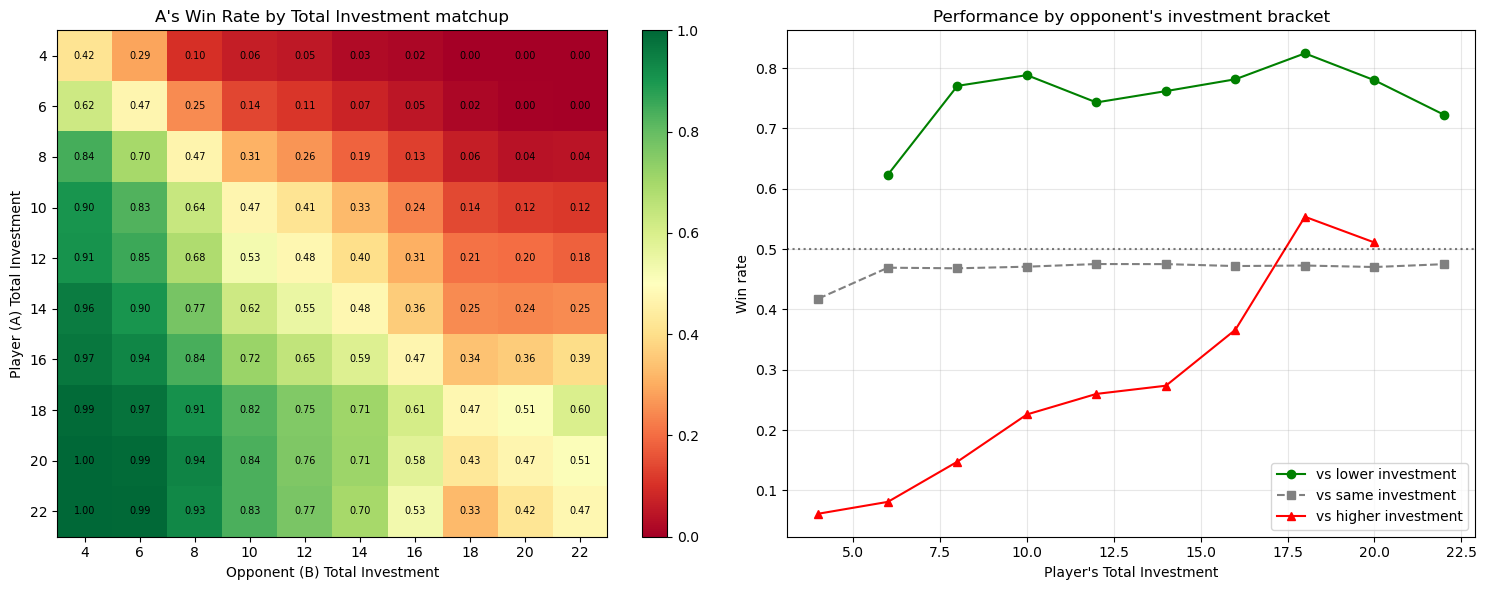


Key check: GREEN above 0.5 (you beat lighter builds)?  RED below 0.5?


<Figure size 640x480 with 0 Axes>

In [13]:
# ============ CELL 1 — heatmap + bracket curves by TOTAL INVESTMENT ============
TI_BIN = 2  # bin width; set to 1 for raw values

def _ti_bin(s):
    return (np.floor(s / TI_BIN) * TI_BIN).astype(int) if TI_BIN > 1 else s

# Derive total investment from the pursuits list, map onto the matchup pairs
gi = df_main_summary.copy()
gi["total_investment"] = gi["pursuits"].fillna("").map(
    lambda s: len([x for x in s.split("|") if x]) if s else 0)
ti_map = gi.set_index("name")["total_investment"]

dfp = df_main_matchups.copy()
dfp["a_ti"] = dfp["a_name"].map(ti_map)
dfp["b_ti"] = dfp["b_name"].map(ti_map)
dfp["a_ti_bin"] = _ti_bin(dfp["a_ti"])
dfp["b_ti_bin"] = _ti_bin(dfp["b_ti"])
pivot_wr_ti = dfp.pivot_table(index="a_ti_bin", columns="b_ti_bin",
                              values="a_win_rate", aggfunc="mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
im = ax.imshow(pivot_wr_ti.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot_wr_ti.columns))); ax.set_xticklabels(pivot_wr_ti.columns)
ax.set_yticks(range(len(pivot_wr_ti.index))); ax.set_yticklabels(pivot_wr_ti.index)
ax.set_xlabel("Opponent (B) Total Investment"); ax.set_ylabel("Player (A) Total Investment")
ax.set_title("A's Win Rate by Total Investment matchup")
plt.colorbar(im, ax=ax)
for i in range(len(pivot_wr_ti.index)):
    for j in range(len(pivot_wr_ti.columns)):
        v = pivot_wr_ti.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="black", fontsize=7)

ax = axes[1]
rows = []
for a_ti in sorted(pivot_wr_ti.index):
    higher = pivot_wr_ti.loc[a_ti, pivot_wr_ti.columns > a_ti].dropna()
    lower  = pivot_wr_ti.loc[a_ti, pivot_wr_ti.columns < a_ti].dropna()
    same   = pivot_wr_ti.loc[a_ti, [a_ti] if a_ti in pivot_wr_ti.columns else []]
    rows.append({"ti": a_ti,
                 "vs_lower_mean":  lower.mean()  if len(lower)  else np.nan,
                 "vs_higher_mean": higher.mean() if len(higher) else np.nan,
                 "vs_same_mean":   same.mean()   if len(same)   else np.nan})
df_vs = pd.DataFrame(rows)
ax.plot(df_vs["ti"], df_vs["vs_lower_mean"], "o-", color="green", label="vs lower investment")
ax.plot(df_vs["ti"], df_vs["vs_same_mean"], "s--", color="gray", label="vs same investment")
ax.plot(df_vs["ti"], df_vs["vs_higher_mean"], "^-", color="red", label="vs higher investment")
ax.axhline(0.5, color="black", linestyle=":", alpha=0.5)
ax.set_xlabel("Player's Total Investment"); ax.set_ylabel("Win rate")
ax.set_title("Performance by opponent's investment bracket")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("\nKey check: GREEN above 0.5 (you beat lighter builds)?  RED below 0.5?")
plt.savefig(os.path.join(OUT_DIR, "Performance_by_opponent_investment"), dpi=110, bbox_inches="tight"); plt.show()

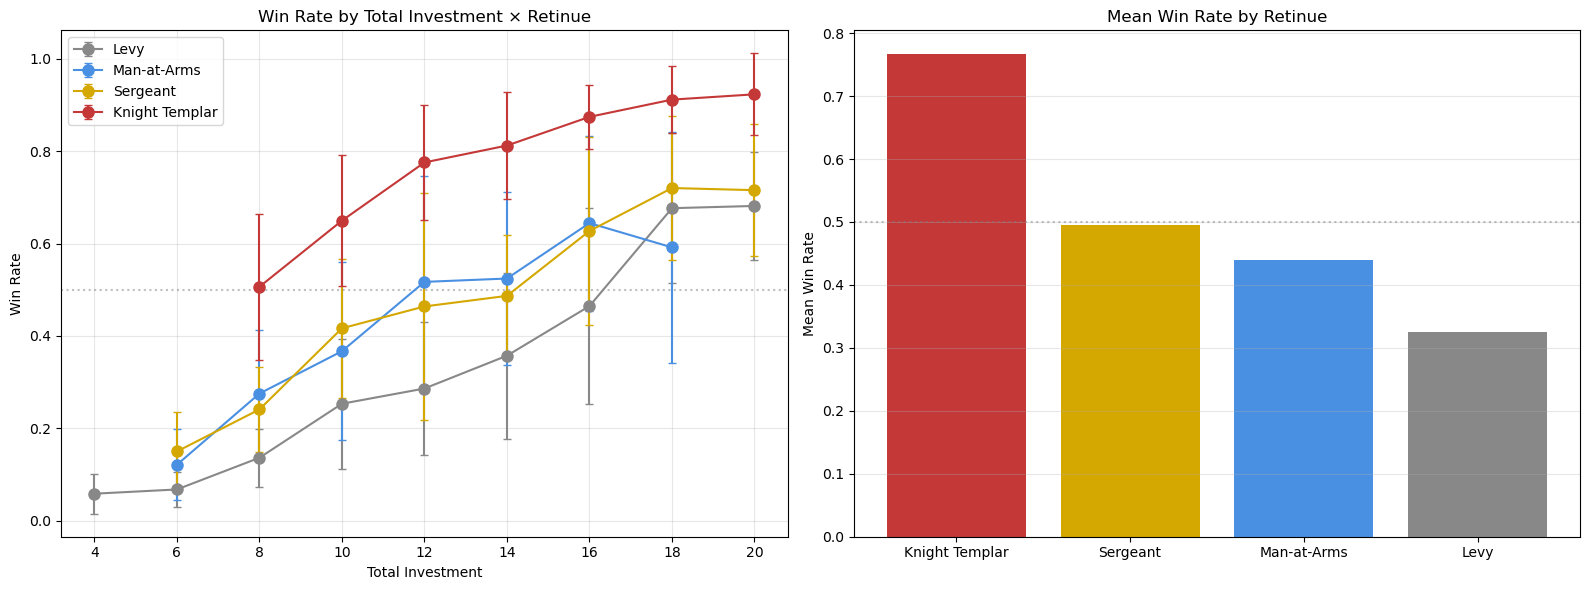

In [14]:
# ============ CELL 2 — win rate by retinue × TOTAL INVESTMENT ============
TI_BIN = 2  # match cell 1

df_ms = df_main_summary.copy()
df_ms["total_investment"] = df_ms["pursuits"].fillna("").map(
    lambda s: len([x for x in s.split("|") if x]) if s else 0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
for ret, color in zip(["Levy","Man-at-Arms","Sergeant","Knight Templar"],
                       ["#888","#4a90e2","#d4a800","#c43838"]):
    sub = df_ms[df_ms["retinue"] == ret].copy()
    sub["ti_bin"] = (np.floor(sub["total_investment"] / TI_BIN) * TI_BIN).astype(int) \
                    if TI_BIN > 1 else sub["total_investment"]
    binned = sub.groupby("ti_bin")["win_rate"].agg(["mean","std","count"])
    binned = binned[binned["count"] >= 3]
    if len(binned) > 0:
        ax.errorbar(binned.index, binned["mean"], yerr=binned["std"],
                    fmt="o-", color=color, label=ret, capsize=3, markersize=8)
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
ax.set_xlabel("Total Investment")
ax.set_ylabel("Win Rate")
ax.set_title("Win Rate by Total Investment × Retinue")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ret_means = df_ms.groupby("retinue")["win_rate"].mean().sort_values(ascending=False)
colors = {"Levy":"#888","Man-at-Arms":"#4a90e2","Sergeant":"#d4a800","Knight Templar":"#c43838"}
ax.bar(ret_means.index, ret_means.values, color=[colors[r] for r in ret_means.index])
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
ax.set_ylabel("Mean Win Rate")
ax.set_title("Mean Win Rate by Retinue")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "winrate_by_total_investment"), dpi=110, bbox_inches="tight"); plt.show()

## 2.2 MPC bucket summary — does higher always win?

Test: for every loadout at MPC=N, what fraction of opponents at MPC<N do they beat? At MPC>N? Cross-budget head-to-head is the strict test of "spending more should win more."

In [15]:
# Build cross-MPC win rate matrix from matchups
df_m = df_main_matchups
df_m["a_mpc_bucket"] = df_m["a_military_pursuit_count"]
df_m["b_mpc_bucket"] = df_m["b_military_pursuit_count"]
# Aggregate wins/losses per (a_mpc, b_mpc) pair
grp = df_m.groupby(["a_mpc_bucket", "b_mpc_bucket"]).agg(
    a_wins=("a_wins", "sum"), b_wins=("b_wins", "sum"),
    mut=("mut_wipe", "sum"), indec=("indecisive", "sum"),
).reset_index()
grp["total"] = grp[["a_wins","b_wins","mut","indec"]].sum(axis=1)
grp["a_win_rate"] = grp["a_wins"] / grp["total"]
grp["decisive_rate"] = (grp["a_wins"] + grp["b_wins"]) / grp["total"]

# Pivot: rows = A's MPC, cols = B's MPC, value = A's win rate
pivot_wr = grp.pivot(index="a_mpc_bucket", columns="b_mpc_bucket", values="a_win_rate")
pivot_dec = grp.pivot(index="a_mpc_bucket", columns="b_mpc_bucket", values="decisive_rate")

print("=== A's Win Rate by (A_MPC, B_MPC) — values show how often A beats B ===")
print(pivot_wr.round(3).to_string())
print()
print("Diagonal = mirror MPC. Above diagonal: A has more budget than B (should win).")

=== A's Win Rate by (A_MPC, B_MPC) — values show how often A beats B ===
b_mpc_bucket      2      3      4
a_mpc_bucket                     
2             0.476  0.324  0.213
3             0.629  0.476  0.338
4             0.748  0.617  0.475

Diagonal = mirror MPC. Above diagonal: A has more budget than B (should win).


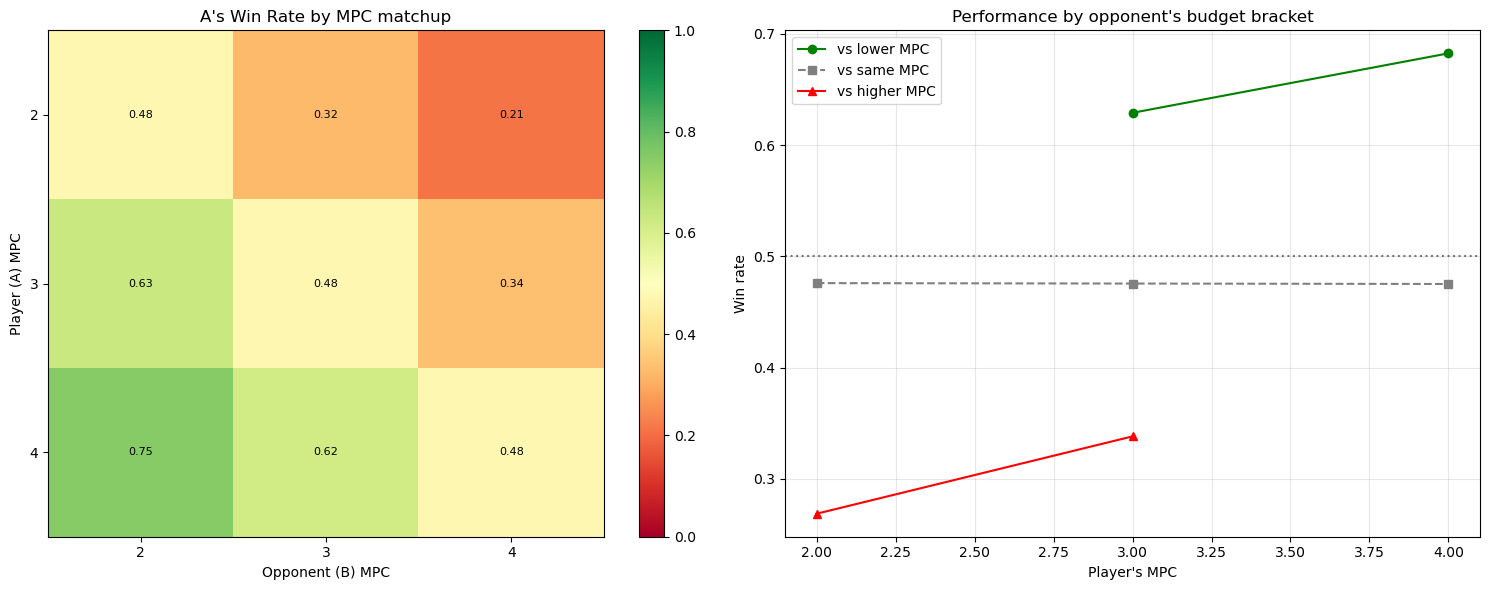


Key check: does the GREEN line stay above 0.5 (you beat lower-MPC opponents)?
Does the RED line stay below 0.5 (you lose to higher-MPC opponents)?

Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\win_rate_mpc_performance_budget.png


In [16]:
# Heatmap
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
im = ax.imshow(pivot_wr.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot_wr.columns))); ax.set_xticklabels(pivot_wr.columns)
ax.set_yticks(range(len(pivot_wr.index))); ax.set_yticklabels(pivot_wr.index)
ax.set_xlabel("Opponent (B) MPC"); ax.set_ylabel("Player (A) MPC")
ax.set_title("A's Win Rate by MPC matchup")
plt.colorbar(im, ax=ax)
# Annotate
for i in range(len(pivot_wr.index)):
    for j in range(len(pivot_wr.columns)):
        v = pivot_wr.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="black", fontsize=8)

ax = axes[1]
# Average win rate over LOWER vs HIGHER MPC opponents per row
rows = []
for a_mpc in sorted(pivot_wr.index):
    higher = pivot_wr.loc[a_mpc, pivot_wr.columns > a_mpc].dropna()
    lower  = pivot_wr.loc[a_mpc, pivot_wr.columns < a_mpc].dropna()
    same   = pivot_wr.loc[a_mpc, [a_mpc] if a_mpc in pivot_wr.columns else []]
    rows.append({
        "mpc": a_mpc,
        "vs_lower_mean": lower.mean() if len(lower) else np.nan,
        "vs_higher_mean": higher.mean() if len(higher) else np.nan,
        "vs_same_mean": same.mean() if len(same) else np.nan,
    })
df_vs = pd.DataFrame(rows)
ax.plot(df_vs["mpc"], df_vs["vs_lower_mean"], "o-", color="green", label="vs lower MPC")
ax.plot(df_vs["mpc"], df_vs["vs_same_mean"], "s--", color="gray", label="vs same MPC")
ax.plot(df_vs["mpc"], df_vs["vs_higher_mean"], "^-", color="red", label="vs higher MPC")
ax.axhline(0.5, color="black", linestyle=":", alpha=0.5)
ax.set_xlabel("Player's MPC"); ax.set_ylabel("Win rate")
ax.set_title("Performance by opponent's budget bracket")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("\nKey check: does the GREEN line stay above 0.5 (you beat lower-MPC opponents)?")
print("Does the RED line stay below 0.5 (you lose to higher-MPC opponents)?")
print(f"\nSaved: {os.path.join(OUT_DIR,'win_rate_mpc_performance_budget.png')}")

## 2.1b Correlation: Win Rate ↔ Total Investment (action economy)

`total_investment` counts **every** pursuit a build owns (each = 1), with NO *Efficient X* discount —
it measures the action economy (how many pursuit-decisions were spent), whereas MPC measures
settlement space (and IS reduced by satisfied *Efficient X*). The hypothesis: total_investment is a
*more monotonic* predictor of win rate than MPC, because MPC's space-discount lets deep-teched gear
look artificially cheap. This cell compares the two head-to-head.

In [17]:
from scipy import stats as sp_stats
import numpy as np

# total_investment = raw count of pursuits (every pursuit = 1; Efficient-X does NOT reduce it).
# Derived from the "pursuits" column ("|"-joined). MPC is military_pursuit_count (space, discounted).
gi = df_main_summary.copy()
gi["total_investment"] = gi["pursuits"].fillna("").map(
    lambda s: len([x for x in s.split("|") if x]) if s else 0)

ti_r,  ti_p  = sp_stats.pearsonr(gi["total_investment"], gi["win_rate"])
ti_sr, ti_sp = sp_stats.spearmanr(gi["total_investment"], gi["win_rate"])
mpc_r,  _    = sp_stats.pearsonr(gi["military_pursuit_count"], gi["win_rate"])
mpc_sr, _    = sp_stats.spearmanr(gi["military_pursuit_count"], gi["win_rate"])

print("=== Win Rate ↔ Total Investment  vs  ↔ MPC ===")
print(f"  total_investment : Pearson {ti_r:+.3f} (p={ti_p:.2e}) | Spearman {ti_sr:+.3f}")
print(f"  MPC (space)      : Pearson {mpc_r:+.3f}              | Spearman {mpc_sr:+.3f}")
print()
print(f"  Spearman is the monotonicity measure (rank correlation). Higher = more monotonic.")
print(f"  total_investment Spearman {ti_sr:+.3f}  vs  MPC Spearman {mpc_sr:+.3f}"
      f"  -> {'total_investment MORE monotonic' if ti_sr>mpc_sr else 'MPC more monotonic'}")
print()

# How far apart MPC and total_investment run (the Efficient-X gap)
gap = (gi["total_investment"] - gi["military_pursuit_count"])
print(f"  total_investment − MPC gap: mean {gap.mean():.2f}, max {gap.max()} "
      f"(0 = no efficiency discount; larger = deeper Efficient-X stacking)")


=== Win Rate ↔ Total Investment  vs  ↔ MPC ===
  total_investment : Pearson +0.629 (p=5.64e-51) | Spearman +0.627
  MPC (space)      : Pearson +0.423              | Spearman +0.423

  Spearman is the monotonicity measure (rank correlation). Higher = more monotonic.
  total_investment Spearman +0.627  vs  MPC Spearman +0.423  -> total_investment MORE monotonic

  total_investment − MPC gap: mean 10.03, max 19 (0 = no efficiency discount; larger = deeper Efficient-X stacking)


investment axis = _total_inv

=== Marginal win-rate per point ===
             n   mean  median   best  d_mean_per_pt  d_best_per_pt
_total_inv                                                        
4            2  0.028   0.028  0.043            NaN            NaN
5            2  0.090   0.090  0.115          0.062          0.072
6            7  0.071   0.059  0.147         -0.019          0.032
7           16  0.167   0.120  0.506          0.097          0.359
8           34  0.265   0.245  0.598          0.098          0.092
9           28  0.300   0.226  0.788          0.035          0.190
10          53  0.437   0.422  0.811          0.136          0.023
11          32  0.400   0.371  0.836         -0.037          0.026
12          35  0.497   0.464  0.941          0.098          0.105
13          33  0.502   0.415  0.940          0.005         -0.001
14          53  0.583   0.587  0.974          0.081          0.034
15          24  0.517   0.475  0.940         -0.067         -0.

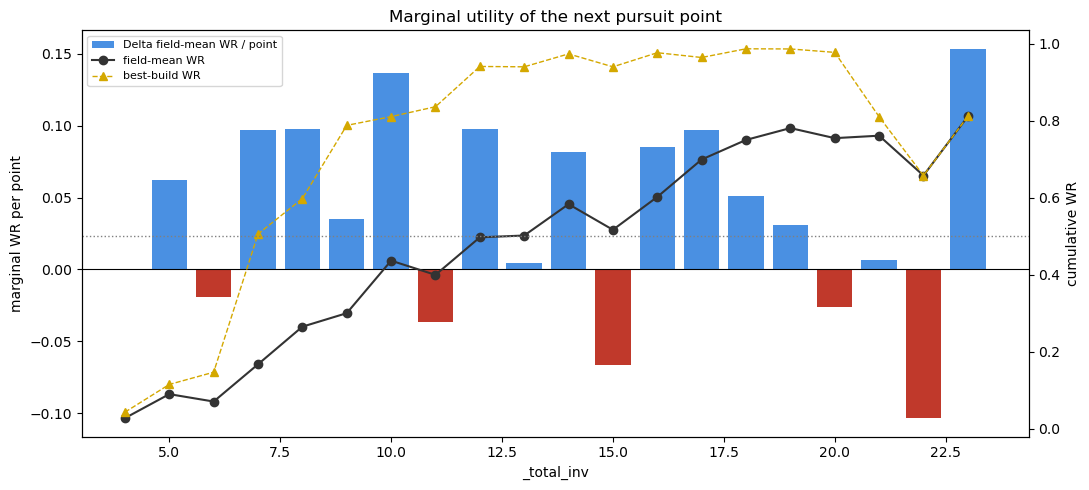


=== weapon: value holding investment fixed ===
     weapon  n    wr  naive_prem  ctrl_prem  d_inv  prem_per_pt  confound
     Spears 15 0.655       0.150      0.157   0.44        0.344    -0.007
    Halberd  9 0.495      -0.009      0.135  -2.03        0.005    -0.145
    Poleaxe  8 0.744       0.240      0.127   1.97        0.122     0.112
  2HBastard 40 0.641       0.136      0.053   1.79        0.076     0.082
Short Sword 24 0.516       0.011      0.027   0.18          NaN    -0.016
   2HSpears 28 0.514       0.009      0.003   0.08          NaN     0.006
  Bill Hook 33 0.538       0.033     -0.007   1.06        0.031     0.040
  Pitchfork 56 0.444      -0.061     -0.011  -1.28        0.048    -0.050
 Battle Axe 11 0.536       0.031     -0.013   0.42        0.073     0.043
     Cudgel 43 0.411      -0.094     -0.018  -1.82        0.052    -0.077
 Farm Tools 67 0.400      -0.105     -0.023  -2.02        0.052    -0.082
    Daggers 35 0.517       0.013     -0.034   0.77        0.016 

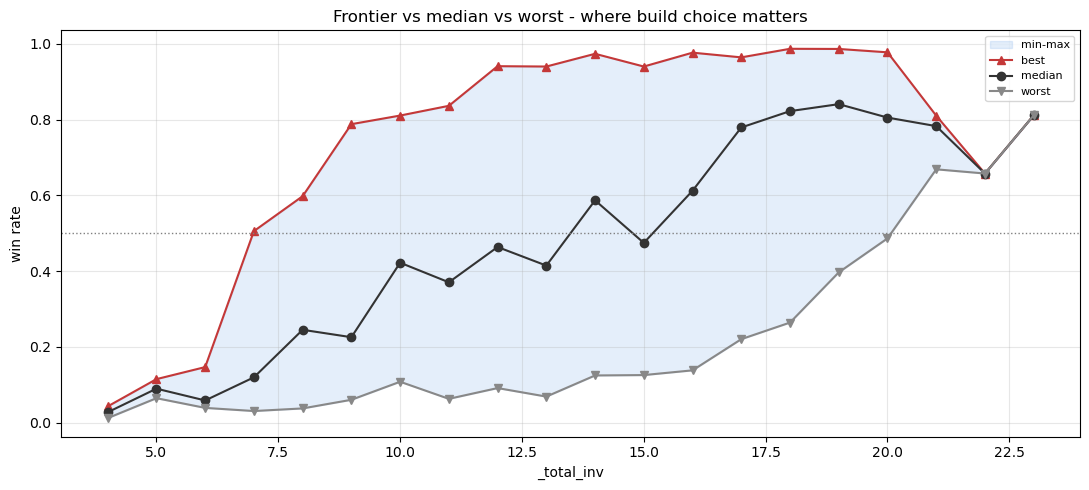

=== Marginal WR/point by retinue ===
Knight Templar  mean marginal WR/pt = +0.041  (range -0.038..+0.240; _total_inv 8-20)
Sergeant        mean marginal WR/pt = +0.041  (range -0.092..+0.268; _total_inv 7-21)
Man-at-Arms     mean marginal WR/pt = +0.037  (range -0.124..+0.221; _total_inv 6-18)
Levy            mean marginal WR/pt = +0.044  (range -0.061..+0.205; _total_inv 7-20)


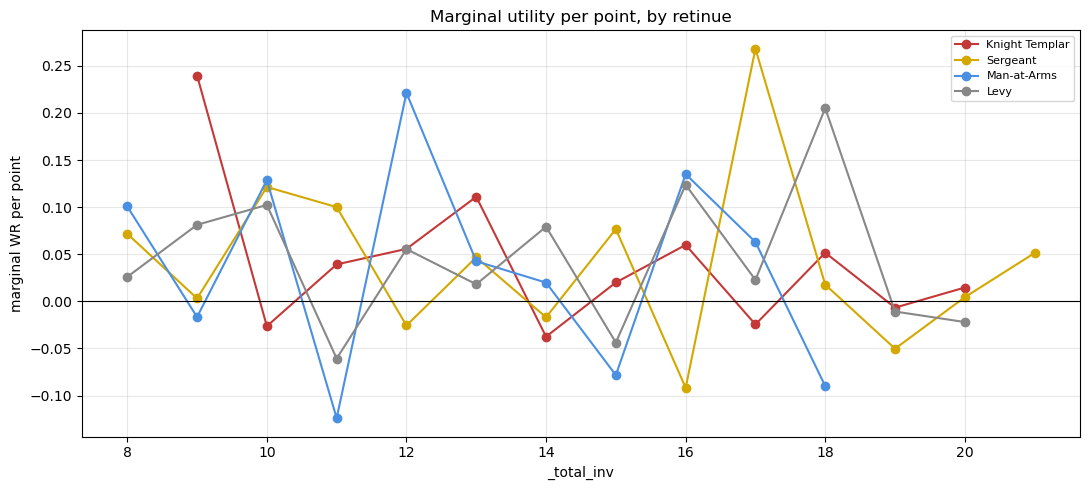

In [18]:
# =====================================================================
# Renown — MARGINAL UTILITY chunks. Drop into the analysis notebook.
# Requires df_main_summary in scope, plus `import renown_data as rd`.
#
# Investment axis = total_investment (every pursuit = 1). Falls back to
# a pursuits recount, then military_pursuit_count, if absent.
# Feature cuts use plain columns only — config is DELIBERATELY excluded:
# is_2h() misclassifies two-handers on the CE data (TWO_H="Two-Handed",
# not "2H"), so any config bucket is wrong on a d10 run until fixed.
# =====================================================================
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
try:
    import renown_data as rd
except Exception:
    rd = None

WR       = "win_rate"
MIN_CELL = 3      # smallest (feature x band) cell to trust
QBANDS   = 4      # investment quantile bands for the deconfound


def _pick_investment(df):
    """Return (col_name, df) for the investment axis. Assumes df is a copy."""
    if "total_investment" in df.columns:
        return "total_investment", df
    if "pursuits" in df.columns:
        df["_total_inv"] = df["pursuits"].fillna("").map(
            lambda s: len([x for x in str(s).split("|") if x.strip()]))
        return "_total_inv", df
    return "military_pursuit_count", df


def _wtier(df):
    if "wtier" not in df.columns and rd is not None:
        df["wtier"] = df["weapon"].map(lambda w: rd.WEAPONS.get(w, {}).get("tier", "-"))
    return df


# ── A. Marginal Delta-WR per point of investment ─────────────────────
#    The derivative of your investment curve. Shows where the next point
#    is worth most and where it saturates / turns negative.
df = df_main_summary.copy()
INV, df = _pick_investment(df)
print(f"investment axis = {INV}\n")

g = (df.dropna(subset=[INV, WR])
       .groupby(INV)[WR].agg(n="count", mean="mean", median="median", best="max")
       .sort_index())
step = g.index.to_series().diff()
g["d_mean_per_pt"] = g["mean"].diff() / step   # marginal WR/point, field
g["d_best_per_pt"] = g["best"].diff() / step   # marginal WR/point, frontier

print("=== Marginal win-rate per point ===")
print(g[["n", "mean", "median", "best", "d_mean_per_pt", "d_best_per_pt"]].round(3).to_string())

dm = g["d_mean_per_pt"].dropna()
print(f"\npeak marginal (field): +{dm.max():.3f} WR at {INV}={int(dm.idxmax())}")
print(f"min  marginal (field): {dm.min():+.3f} WR at {INV}={int(dm.idxmin())}")
neg = dm[dm < 0]
if len(neg):
    print("negative marginal (saturation):",
          ", ".join(f"{int(i)}({v:+.2f})" for i, v in neg.items()))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(g.index, g["d_mean_per_pt"], width=step.fillna(1) * 0.8,
       color=["#c0392b" if v < 0 else "#4a90e2" for v in g["d_mean_per_pt"].fillna(0)],
       label="Delta field-mean WR / point")
ax.axhline(0, color="k", lw=0.8)
ax2 = ax.twinx()
ax2.plot(g.index, g["mean"], "o-", color="#333", lw=1.5, label="field-mean WR")
ax2.plot(g.index, g["best"], "^--", color="#d4a800", lw=1, label="best-build WR")
ax2.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel(INV); ax.set_ylabel("marginal WR per point"); ax2.set_ylabel("cumulative WR")
ax.set_title("Marginal utility of the next pursuit point")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()


# ── B. Feature value: naive premium vs investment-controlled ─────────
#    naive_prem  = WR(has feature) - WR(pool)      (additive form of your "lift")
#    ctrl_prem   = mean over investment bands of [WR(feat|band) - WR(band)],
#                  n-weighted  ->  the edge that SURVIVES holding spend fixed
#    d_inv       = extra investment a build carries when it has the feature
#    prem_per_pt = naive_prem / d_inv  ->  WR bought per extra implied point,
#                  directly comparable to A's d_mean_per_pt
#    confound    = naive_prem - ctrl_prem  ->  the part that was just "expensive"
#    ctrl_prem ~ 0  =>  the feature was a spend proxy, not a driver.
df = df_main_summary.copy()
INV, df = _pick_investment(df)
df = _wtier(df)
pool_wr = df[WR].mean()
pool_inv = df[INV].mean()
df["_band"] = pd.qcut(df[INV], QBANDS, duplicates="drop")
band_wr = df.groupby("_band", observed=True)[WR].mean()


def feature_value(col):
    rows = []
    for v, sub in df.groupby(col, observed=True):
        if str(v) in ("", "nan", "None") or len(sub) < 5:
            continue
        naive = sub[WR].mean() - pool_wr
        num = den = 0.0
        for b, s in sub.groupby("_band", observed=True):
            if len(s) < MIN_CELL:
                continue
            num += len(s) * (s[WR].mean() - band_wr[b]); den += len(s)
        ctrl = num / den if den else np.nan
        d_inv = sub[INV].mean() - pool_inv
        per_pt = naive / d_inv if abs(d_inv) > 0.25 else np.nan
        rows.append((v, len(sub), round(sub[WR].mean(), 3), round(naive, 3),
                     round(ctrl, 3) if ctrl == ctrl else np.nan, round(d_inv, 2),
                     round(per_pt, 3) if per_pt == per_pt else np.nan,
                     round(naive - ctrl, 3) if ctrl == ctrl else np.nan))
    out = pd.DataFrame(rows, columns=[col, "n", "wr", "naive_prem", "ctrl_prem",
                                      "d_inv", "prem_per_pt", "confound"])
    return out.sort_values("ctrl_prem", ascending=False)


for col in ["weapon", "armor", "shield", "wtier", "retinue"]:
    if col in df.columns:
        print(f"\n=== {col}: value holding investment fixed ===")
        print(feature_value(col).to_string(index=False))
print("\nread: ctrl_prem = real edge; confound = the slice that was only 'expensive'.")


# ── C. Frontier - median gap per point (trap density) ────────────────
#    Big gap  = build choice matters a lot at that spend.
#    Gap ~ 0  = every build wins regardless; choice is cosmetic.
df = df_main_summary.copy()
INV, df = _pick_investment(df)
g = (df.dropna(subset=[INV, WR])
       .groupby(INV)[WR].agg(n="count", median="median", mean="mean",
                             best="max", worst="min").sort_index())
g["frontier_gap"] = g["best"] - g["median"]
g["spread"] = g["best"] - g["worst"]
print("=== Trap density by investment ===")
print(g.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(g.index, g["worst"], g["best"], alpha=0.15, color="#4a90e2", label="min-max")
ax.plot(g.index, g["best"], "^-", color="#c43838", label="best")
ax.plot(g.index, g["median"], "o-", color="#333", label="median")
ax.plot(g.index, g["worst"], "v-", color="#888", label="worst")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel(INV); ax.set_ylabel("win rate")
ax.set_title("Frontier vs median vs worst - where build choice matters")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


# ── D. Marginal WR per point, by retinue (KT gate-pricing view) ──────
#    KT only exists above its gate, so compare the SLOPE, not the level.
#    Where KT's marginal < MaA's, extra points buy more as MaA than as KT.
df = df_main_summary.copy()
INV, df = _pick_investment(df)
COL = {"Knight Templar": "#c43838", "Sergeant": "#d4a800",
       "Man-at-Arms": "#4a90e2", "Levy": "#888"}

fig, ax = plt.subplots(figsize=(11, 5))
print("=== Marginal WR/point by retinue ===")
for ret, c in COL.items():
    sub = df[df["retinue"] == ret]
    if sub.empty:
        continue
    gg = sub.groupby(INV)[WR].agg(n="count", mean="mean").sort_index()
    gg = gg[gg["n"] >= 3]
    if len(gg) < 2:
        continue
    d = gg["mean"].diff() / gg.index.to_series().diff()
    ax.plot(gg.index, d, "o-", color=c, label=ret)
    print(f"{ret:15s} mean marginal WR/pt = {d.mean():+.3f}  "
          f"(range {d.min():+.3f}..{d.max():+.3f}; {INV} {int(gg.index.min())}-{int(gg.index.max())})")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel(INV); ax.set_ylabel("marginal WR per point")
ax.set_title("Marginal utility per point, by retinue")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# ==========================================================================
# FULL-DICTIONARY SENSITIVITY HARNESS  (notebook chunk)
# Scores, investment-controlled, from df_main_summary: each equipment ITEM,
# every non-tag FIELD, every KEYWORD/tag, and retinue.
#   ctrl_prem = real edge holding spend fixed ; confound = naive - ctrl.
#   ITEM rows = clean per-weapon read ; num FIELD rows are item-collinear
#   (diagnostics) ; TAG rows pool across items (most trustworthy for a mechanic).
#
# INCLUDE_DOMAIN_COST: the base investment axis (_ti / total_investment) counts
# PURSUIT NODES only — it does NOT count the domain-point climb (Rising/Est/Sov).
# That makes Sovereign-gated, short-node paths (e.g. Ministry) look artificially
# CHEAP and inflates their ctrl_prem. Set True to add each build's summed
# standing cost (N/R/E/S = 0/3/6/10 domain points) to the axis, so options are
# compared at equal TOTAL cost. Assumes 1 domain-point ~ 1 pursuit-point; adjust
# _LVL if your economy differs.
# ==========================================================================
import pandas as pd, numpy as np, re as _re
import renown_data as rd
df = df_main_summary.copy()

WR = "win_rate"; MIN_N = 3; QBANDS = 4
INCLUDE_DOMAIN_COST = True

df = df_main_summary.copy()

# --- base investment axis (pursuit nodes) ---
if "total_investment" in df.columns:
    _base_inv = "total_investment"
elif "pursuits" in df.columns:
    df["_ti"] = df["pursuits"].fillna("").map(lambda s: len([x for x in str(s).split("|") if x.strip()]))
    _base_inv = "_ti"
else:
    _base_inv = "military_pursuit_count"

# --- optionally add the domain-standing cost the base axis omits ---
INV = _base_inv
if INCLUDE_DOMAIN_COST:
    _LVL = {"N": 0, "R": 3, "E": 6, "S": 10}          # standing -> cumulative domain-point cost
    _src = "name" if "name" in df.columns else ("pursuits" if "pursuits" in df.columns else None)
    def _domcost(txt):
        if not isinstance(txt, str):
            return 0
        best = {}
        for lv, dm in _re.findall(r'\b([NRES])(Ind|Prow|Pie|Cun)\b', txt):
            best[dm] = max(best.get(dm, 0), _LVL[lv])   # cumulative: highest standing per domain
        return sum(best.values())
    if _src is None:
        print("INCLUDE_DOMAIN_COST: no 'name'/'pursuits' column to parse standings from — using base axis.")
    else:
        df["_domcost"] = df[_src].map(_domcost)
        df["_ticost"] = df[_base_inv] + df["_domcost"]
        INV = "_ticost"

pool_wr = df[WR].mean(); pool_inv = df[INV].mean()
df["_band"] = pd.qcut(df[INV], QBANDS, duplicates="drop")
band_wr = df.groupby("_band", observed=True)[WR].mean()

def ctrl(mask):
    sub = df[mask]
    if len(sub) < MIN_N:
        return None
    naive = sub[WR].mean() - pool_wr
    num = den = 0.0
    for b, s in sub.groupby("_band", observed=True):
        if len(s) < 3:
            continue
        num += len(s) * (s[WR].mean() - band_wr[b]); den += len(s)
    cp = num / den if den else np.nan
    ok = cp == cp
    return dict(n=len(sub), wr=round(sub[WR].mean(), 3), naive=round(naive, 3),
                ctrl_prem=round(cp, 3) if ok else np.nan,
                d_inv=round(sub[INV].mean() - pool_inv, 2),
                confound=round(naive - cp, 3) if ok else np.nan)

DICT_COL = {"WEAPONS": "weapon", "RANGED": "ranged", "SHIELDS": "shield", "ARMORS": "armor"}
rows = []

# 0) each equipment ITEM on its own
for dname, col in DICT_COL.items():
    if col not in df.columns:
        continue
    for v in df[col].dropna().unique():
        if str(v) in ("", "nan", "None"):
            continue
        r = ctrl(df[col] == v)
        if r:
            rows.append({"dict": f"{dname}(item)", "variable": col, "value": v, "kind": "item", **r})

# 1) every non-tag field of every equipment dict
for dname, col in DICT_COL.items():
    D = getattr(rd, dname, None)
    if D is None or col not in df.columns:
        print(f"skip {dname}: dict or df column '{col}' missing"); continue
    sample = next((v for v in D.values() if isinstance(v, dict)), {})
    for f in [k for k in sample.keys() if k != "tags"]:
        colvals = df[col].map(lambda x, f=f, D=D: D.get(x, {}).get(f, np.nan) if x in D else np.nan)
        vals = list(colvals.dropna().unique())
        numeric = all(isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) for v in vals)
        for v in vals:
            r = ctrl(colvals == v)
            if r:
                rows.append({"dict": dname, "variable": f"{col}.{f}", "value": v,
                             "kind": "num" if numeric else "cat", **r})

# 2) every keyword/tag anywhere (item tags UNION build-level tags column)
def tagset(row):
    s = set()
    for dname, col in DICT_COL.items():
        D = getattr(rd, dname, None); x = row.get(col)
        if D and x in D:
            s |= {str(t) for t in D[x].get("tags", [])}
    bt = row.get("tags", "")
    if isinstance(bt, str) and bt:
        s |= {t.strip() for t in bt.replace("|", ",").split(",") if t.strip()}
    return s

df["_tags"] = df.apply(tagset, axis=1)
for t in sorted({t for s in df["_tags"] for t in s}):
    r = ctrl(df["_tags"].apply(lambda s, t=t: t in s))
    if r:
        rows.append({"dict": "(keyword)", "variable": "tag", "value": t, "kind": "tag", **r})

# 3) retinue
if "retinue" in df.columns:
    for v in df["retinue"].dropna().unique():
        r = ctrl(df["retinue"] == v)
        if r:
            rows.append({"dict": "RETINUES", "variable": "retinue", "value": v, "kind": "cat", **r})

out = pd.DataFrame(rows)[
    ["dict", "variable", "value", "kind", "n", "wr", "naive", "ctrl_prem", "d_inv", "confound"]
].sort_values("ctrl_prem", ascending=False, na_position="last").reset_index(drop=True)

pd.set_option("display.max_rows", None); pd.set_option("display.width", 200)
print(f"data: {SUMMARY_SOURCE}  |  variables measured: {len(out)}  |  investment axis: {INV}  |  INCLUDE_DOMAIN_COST={INCLUDE_DOMAIN_COST}\n")
print("================ FULL TABLE (items + fields + keywords, by real edge) ================")
print(out.to_string(index=False))
print("\n---- ITEMS on their own ----")
print(out[out["kind"] == "item"].to_string(index=False))
print("\n---- most OVERRATED by raw lift (biggest positive confound) ----")
print(out.sort_values("confound", ascending=False).head(12).to_string(index=False))
print("\n---- most UNDERRATED (most negative confound) ----")
print(out.sort_values("confound").head(12).to_string(index=False))
print("\n---- dice_config magnitudes: NOT measurable from one run — need a multi-run sweep ----")
_globs = ["FACES","FOCUSED_THR","PARRY_BASE","RECOVER_BASE","DEADLY_AP","DEADLY_MODE",
          "UNSTOPPABLE_MOD","IMPROVED_PARRY_MOD","FATIGUE_STRIKE","FATIGUE_MORALE","AUTO_PASS_FLOOR"]
try:
    import dice_config as dc
    for k in _globs:
        print(f"   {k} = {getattr(dc, k, '(absent)')}")
except Exception:
    print("   (dice_config not importable here) " + ", ".join(_globs))

## 2.x Attribute table — redundant rows merged

The harness above prints one row per item / field / keyword, so anything that always travels together prints several
identical rows (Royal Pavilion's Crit 8 / Immune Strained / Parry +1; Court Armoury's Planishing / Gothic Plate /
Crafted armor / save 3; a weapon and its own AP value). This version merges every group of rows that select **exactly
the same builds** into one, lists the rest under `same builds as`, and names the Holding or Standing a keyword comes
from. Holdings are scored as variables too.

In [ ]:
import build_rank as BR, parser_audit as PA
for _m in (BR, PA):
    importlib.reload(_m)
att = BR.attribute_table(df_main_summary, include_domain=INCLUDE_DOMAIN_COST)
print("\n---- most OVERRATED by raw lift (biggest positive confound) ----")
print(att.sort_values("confound", ascending=False).head(12).to_string(index=False))
print("\n---- most UNDERRATED (most negative confound) ----")
print(att.sort_values("confound").head(12).to_string(index=False))

## 2.y Parser → engine audit

Every combat token the Holding-text parser emits, added to an otherwise identical army in a context where it should
matter: which packed engine fields move and how far the win rate moves (batch engine, both seatings).
`OK` = wired and moves the win rate the right way; `WIRED, SMALL` = wired, effect inside noise in that context;
`INERT` / `WRONG WAY` = look at it. `rule_gaps()` lists rules text the engine doesn't follow as written.

In [ ]:
audit = PA.audit(n_runs=2000, show=False)
display(audit)
display(PA.rule_gaps(show=False))

## 2.z Balance diagnostics

Run `B0` first; the rest read its frames. `B4` runs new battles on the **current** data file, so it reflects edits made since the run.

In [ ]:
# ══ B0. BALANCE DIAGNOSTICS — settings + shared frames ═════════════════════════
BOOT_B    = 400     # bootstrap replicates for every confidence interval
BAL_MIN_N     = 8       # a feature needs at least this many builds to be scored
INV_BANDS = 4       # investment bands the premium is controlled within (as the harness)
ELITE_Q   = 0.75    # "strong opponents" = builds at or above this win-rate quantile
# ═══════════════════════════════════════════════════════════════════════════════
import re as _re, copy as _copy, contextlib as _ctx
import renown_data_d10 as _RD, display_lab as _DL

_LVL = {"N": 0, "R": 3, "E": 6, "S": 10}
def _domcost(name):
    best = {}
    for lv, dm in _re.findall(r'\b([NRES])(Ind|Prow|Pie|Cun)\b', str(name)):
        best[dm] = max(best.get(dm, 0), _LVL[lv])
    return sum(best.values())

def _split_tags(s):
    return frozenset(t.strip() for t in str(s).replace("|", ",").split(",") if t.strip()) if isinstance(s, str) else frozenset()

BF = df_main_summary[["name", "retinue", "weapon", "shield", "armor", "ranged", "tags", "pursuits",
                      "win_rate", "wins", "losses", "mut_wipe", "n_battles"]].copy().reset_index(drop=True)
for _c in ("weapon", "shield", "armor", "ranged"):
    BF[_c] = BF[_c].where(BF[_c].notna() & (BF[_c].astype(str).str.strip() != ""), None)
BF["holdings"]   = BF["pursuits"].fillna("").map(lambda s: frozenset(x for x in str(s).split("|") if x))
BF["inv"]        = BF["holdings"].map(len) + BF["name"].map(_domcost)       # same axis as the harness (_ticost)
BF["build_tags"] = BF["tags"].map(_split_tags)
_ITEM_D = {"weapon": _RD.WEAPONS, "ranged": _RD.RANGED, "shield": _RD.SHIELDS, "armor": _RD.ARMORS}
BF["tagset"] = [frozenset().union(r.build_tags, *[{str(t) for t in D.get(r[c], {}).get("tags", [])}
                                                  for c, D in _ITEM_D.items() if r[c] in D])
                for _, r in BF.iterrows()]
_MONS = {h for h, d in loadouts._SIM.items() if d.get("monument")}
BF["mons"] = BF["holdings"].map(lambda h: frozenset(h & _MONS))
BF["band"] = pd.qcut(BF["inv"], INV_BANDS, labels=False, duplicates="drop").to_numpy()

# Feature matrix: one boolean column per item / retinue / keyword / monument.
_cols = {}
for _c in ("retinue", "weapon", "shield", "armor", "ranged"):
    for _v in sorted(BF[_c].dropna().unique()):
        _cols[f"{_c}: {_v}"] = (BF[_c] == _v).to_numpy()
for _t in sorted(set().union(*BF["tagset"])):
    _cols[f"tag: {_t}"] = BF["tagset"].map(lambda s, t=_t: t in s).to_numpy()
for _h in sorted(set().union(*BF["mons"])):
    _cols[f"monument: {_h}"] = BF["mons"].map(lambda s, h=_h: h in s).to_numpy()
FEAT = pd.DataFrame(_cols)
FEAT = FEAT.loc[:, FEAT.sum() >= BAL_MIN_N]

def feat_cols(names):
    """Resolve names ('Tower Shield', 'Heal 7', 'tag: Enduring', 'Oathsworn Knight') to FEAT columns."""
    out = []
    for n in names:
        n0 = str(n).strip().lower()
        hit = [c for c in FEAT.columns if c.lower() == n0
               or c.split(": ", 1)[1].lower() == n0 or _DL.D(c.split(": ", 1)[1]).lower() == n0]
        if not hit:
            print(f"  (no feature with >= {BAL_MIN_N} builds named {n!r})")
        out += [h for h in hit if h not in out]
    return out

# Bootstrap over CHASSIS (same Retinue + Holdings = gear variants of one build), not single builds:
# gear variants of one chassis are not independent, so resampling builds would make CIs too narrow.
_chassis = pd.factorize(BF["retinue"].astype(str) + "|" + BF["pursuits"].fillna("").astype(str))[0]
_rng = np.random.default_rng(2026)
BOOT_W = _rng.poisson(1.0, (BOOT_B, _chassis.max() + 1))[:, _chassis].astype(float)

def boot_prem(y, F, band, W):
    """Investment-controlled premium of every column of F on outcome y, with bootstrap 95% CIs.
    Premium = carriers' mean (y - mean y of their investment band). Returns n, prem, lo, hi."""
    y = np.asarray(y, float); Fm = np.asarray(F, float); band = np.asarray(band)
    Bh = np.eye(band.max() + 1)[band]
    def _prem(w):
        bm = ((w * y) @ Bh) / np.maximum(w @ Bh, 1e-12)
        res = y[None, :] - bm[:, band]
        den = w @ Fm
        return ((w * res) @ Fm) / np.where(den > 0, den, np.nan)
    pt = _prem(np.ones((1, len(y))))[0]
    bs = _prem(W)
    lo, hi = np.nanpercentile(bs, 2.5, axis=0), np.nanpercentile(bs, 97.5, axis=0)
    return pd.DataFrame({"n": Fm.sum(0).astype(int), "prem": pt, "lo": lo, "hi": hi}, index=list(F.columns))

def _verdict(t):
    return np.where(t["lo"] > 0, "real +", np.where(t["hi"] < 0, "real -", "noise"))

print(f"B0: {len(BF)} builds, {_chassis.max() + 1} chassis, {FEAT.shape[1]} features (n >= {BAL_MIN_N}), "
      f"bootstrap {BOOT_B}x  [{SUMMARY_SOURCE}]")

### B1. Confidence intervals on the harness premiums
Same premium as the harness (`ctrl_prem`), with a 95% interval. **noise** = the interval crosses 0.

In [ ]:
T_CI = boot_prem(BF["win_rate"], FEAT, BF["band"], BOOT_W)
T_CI["wr"] = [BF.loc[FEAT[c], "win_rate"].mean() for c in T_CI.index]
T_CI["verdict"] = _verdict(T_CI)
T_CI["width"] = T_CI["hi"] - T_CI["lo"]
T_CI = T_CI[["n", "wr", "prem", "lo", "hi", "width", "verdict"]].sort_values("prem", ascending=False)
with pd.option_context("display.max_rows", None, "display.width", 200, "display.float_format", "{:.3f}".format):
    print(T_CI.to_string())
print("\nreal +:", (T_CI.verdict == "real +").sum(), "| real -:", (T_CI.verdict == "real -").sum(),
      "| noise:", (T_CI.verdict == "noise").sum())

### B2. Joint model — every item and keyword at once
One ridge regression: win rate ~ gear + Holding keywords, with each Retinue's own investment curve held fixed.
Columns that are identical across the pool (e.g. an item and the only keyword it brings) are merged into one row, since no data can split them.
`vs_slot` = premium over the average item in the same slot; `vs_base` = over the slot's baseline (Farm Tools / no shield / Cloth / no ranged).

In [ ]:
RIDGE_ALPHA = 2.0     # shrinkage on gear/keyword terms (in builds); 0 = plain least squares
B2_BOOT     = 200

_BASE = {"weapon": "Farm Tools", "armor": "Cloth"}
_X = {}
for _c in ("weapon", "shield", "armor", "ranged"):
    for _v in sorted(BF[_c].dropna().unique()):
        if _v != _BASE.get(_c):
            _X[f"{_c}: {_v}"] = (BF[_c] == _v).to_numpy(float)
for _t in sorted(set().union(*BF["build_tags"])):                 # Holding keywords (gear keywords ride on the items)
    _X[f"tag: {_t}"] = BF["build_tags"].map(lambda s, t=_t: t in s).to_numpy(float)
_X = pd.DataFrame(_X)
_X = _X.loc[:, _X.sum() >= BAL_MIN_N]
# merge identical columns
_groups = {}
for _c in _X.columns:
    _groups.setdefault(_X[_c].to_numpy().tobytes(), []).append(_c)
_X = pd.DataFrame({" = ".join(g): _X[g[0]] for g in _groups.values()})
# a column identical to one Retinue (every build of it has the keyword, nobody else does) is that Retinue
_ret_masks = {r: (BF["retinue"] == r).to_numpy(float) for r in BF["retinue"].unique()}
_absorbed = {c: r for c in _X.columns for r, m in _ret_masks.items() if np.array_equal(_X[c].to_numpy(), m)}
_X = _X.drop(columns=list(_absorbed))
if _absorbed:
    print("absorbed by Retinue (inseparable from it): " + "; ".join(f"{c} → {r}" for c, r in _absorbed.items()))

# fixed effects: each Retinue's intercept + own quadratic investment curve (not penalised)
_z = ((BF["inv"] - BF["inv"].mean()) / BF["inv"].std()).to_numpy()
_FE = {}
for _r in sorted(BF["retinue"].unique()):
    _m = (BF["retinue"] == _r).to_numpy(float)
    _FE[f"~{_r}"] = _m; _FE[f"~{_r}·inv"] = _m * _z; _FE[f"~{_r}·inv²"] = _m * _z ** 2
_FE = pd.DataFrame(_FE)
Xm = np.hstack([_FE.to_numpy(), _X.to_numpy()])
_pen = np.r_[np.zeros(_FE.shape[1]), np.full(_X.shape[1], RIDGE_ALPHA)]
_y = BF["win_rate"].to_numpy()

def _ridge(w):
    XtW = Xm.T * w
    return np.linalg.solve(XtW @ Xm + np.diag(_pen) + 1e-9 * np.eye(Xm.shape[1]), XtW @ _y)

_beta = _ridge(np.ones(len(_y)))
_fit = Xm @ _beta
print(f"R² = {1 - ((_y - _fit) ** 2).sum() / ((_y - _y.mean()) ** 2).sum():.3f}  "
      f"(Retinue curves alone: {1 - ((_y - _FE.to_numpy() @ np.linalg.lstsq(_FE.to_numpy(), _y, rcond=None)[0]) ** 2).sum() / ((_y - _y.mean()) ** 2).sum():.3f})")
_bs = np.array([_ridge(BOOT_W[b]) for b in range(min(B2_BOOT, BOOT_B))])[:, _FE.shape[1]:]
_k = _beta[_FE.shape[1]:]

T_JOINT = pd.DataFrame({"n": _X.sum().astype(int).to_numpy(), "vs_base": _k,
                        "lo": np.percentile(_bs, 2.5, 0), "hi": np.percentile(_bs, 97.5, 0)}, index=_X.columns)
# slot average: the slot's carriers-weighted mean coefficient (baseline item = 0)
T_JOINT["vs_slot"] = np.nan
for _c in ("weapon", "shield", "armor", "ranged"):
    _rows = [i for i in T_JOINT.index if i.split(" = ")[0].startswith(_c + ": ")]
    if not _rows:
        continue
    _avg = (T_JOINT.loc[_rows, "vs_base"] * T_JOINT.loc[_rows, "n"]).sum() / len(BF)   # baseline / empty slot counts as 0
    T_JOINT.loc[_rows, "vs_slot"] = T_JOINT.loc[_rows, "vs_base"] - _avg
T_JOINT["verdict"] = _verdict(T_JOINT)
T_JOINT = T_JOINT[["n", "vs_slot", "vs_base", "lo", "hi", "verdict"]].sort_values("vs_base", ascending=False)
with pd.option_context("display.max_rows", None, "display.width", 220, "display.max_colwidth", 70,
                       "display.float_format", "{:.3f}".format):
    for _kind in ("weapon", "shield", "armor", "ranged", "tag"):
        _sub = T_JOINT[[i.startswith(_kind + ": ") for i in T_JOINT.index]]
        if len(_sub):
            print(f"\n---- {_kind} ----")
            print((_sub if _kind != "tag" else _sub.drop(columns="vs_slot")).to_string())

### B3. Against strong opponents
Each build's win rate (both seats) against the top `ELITE_Q` of the pool, next to its win rate against everyone.
`shift` = how much more (or less) a feature is worth when the opponent is strong.

In [ ]:
_M = df_main_matchups
_idx = pd.Index(BF["name"])
_ai, _bi = _idx.get_indexer(_M["a_name"]), _idx.get_indexer(_M["b_name"])
_ok = (_ai >= 0) & (_bi >= 0)
_ai, _bi = _ai[_ok], _bi[_ok]
_aw = _M["a_wins"].to_numpy()[_ok].astype(float); _bw = _M["b_wins"].to_numpy()[_ok].astype(float)
_tot = (_M["a_wins"] + _M["b_wins"] + _M["mut_wipe"] + _M["indecisive"]).to_numpy()[_ok].astype(float)
_n = len(BF)
ELITE = (BF["win_rate"] >= BF["win_rate"].quantile(ELITE_Q)).to_numpy()

def _seat_wr(mask_opp_a, mask_opp_b):
    w = np.bincount(_ai[mask_opp_a], _aw[mask_opp_a], _n) + np.bincount(_bi[mask_opp_b], _bw[mask_opp_b], _n)
    g = np.bincount(_ai[mask_opp_a], _tot[mask_opp_a], _n) + np.bincount(_bi[mask_opp_b], _tot[mask_opp_b], _n)
    return w / np.where(g > 0, g, np.nan)

_all = np.ones(len(_ai), bool)
BF["wr_all"] = _seat_wr(_all, _all)
BF["wr_vE"]  = _seat_wr(ELITE[_bi], ELITE[_ai])
print(f"strong opponents: {ELITE.sum()} builds (win rate >= {BF['win_rate'].quantile(ELITE_Q):.3f})  |  "
      f"mean wr vs all {BF.wr_all.mean():.3f}, vs strong {BF.wr_vE.mean():.3f}")

_okb = BF["wr_vE"].notna().to_numpy()
_Pa = boot_prem(BF["wr_all"][_okb], FEAT[_okb], BF["band"][_okb], BOOT_W[:, _okb])
_Pe = boot_prem(BF["wr_vE"][_okb], FEAT[_okb], BF["band"][_okb], BOOT_W[:, _okb])
T_ELITE = pd.DataFrame({"n": _Pe["n"], "prem_all": _Pa["prem"], "prem_vs_strong": _Pe["prem"],
                        "lo": _Pe["lo"], "hi": _Pe["hi"]})
T_ELITE["shift"] = T_ELITE["prem_vs_strong"] - T_ELITE["prem_all"]
T_ELITE["verdict"] = _verdict(T_ELITE)
T_ELITE = T_ELITE.sort_values("prem_vs_strong", ascending=False)
with pd.option_context("display.max_rows", None, "display.width", 200, "display.float_format", "{:.3f}".format):
    print(T_ELITE.to_string())
    print("\n---- biggest shifts (worth more / less against strong opponents) ----")
    print(T_ELITE.reindex(T_ELITE["shift"].abs().sort_values(ascending=False).index).head(15).to_string())

### B5. Per-Retinue split
The harness premium computed inside each Retinue (its own investment bands). `*` = 95% interval excludes 0. `spread` = best minus worst Retinue.

In [ ]:
B5_FEATURES = None     # None = every item + keyword; or a list, e.g. ["Tower Shield", "Kite Shield", "Enduring"]

_cols5 = list(FEAT.columns) if B5_FEATURES is None else feat_cols(B5_FEATURES)
_cols5 = [c for c in _cols5 if not c.startswith("retinue: ")]
_cell, _ncell = {}, {}
for _r, _g in BF.groupby("retinue"):
    _ix = _g.index.to_numpy()
    _band_r = pd.qcut(_g["inv"], INV_BANDS, labels=False, duplicates="drop").to_numpy()
    _F = FEAT.loc[_ix, _cols5]
    _keep = [c for c in _cols5 if _F[c].sum() >= BAL_MIN_N]
    if not _keep:
        continue
    _t = boot_prem(_g["win_rate"], _F[_keep], _band_r, BOOT_W[:, _ix])
    _cell[_r] = _t["prem"]; _ncell[_r] = _t["n"]
    _cell[_r + " sig"] = pd.Series(np.where((_t["lo"] > 0) | (_t["hi"] < 0), "*", ""), index=_t.index)

_rets = [r for r in sorted(BF["retinue"].unique()) if r in _cell]
T_RET = pd.DataFrame({r: _cell[r] for r in _rets})
T_RET_N = pd.DataFrame({r: _ncell[r] for r in _rets}).fillna(0).astype(int)
T_RET["spread"] = T_RET[_rets].max(axis=1) - T_RET[_rets].min(axis=1)
_show = pd.DataFrame(index=T_RET.index)
for r in _rets:
    _show[r] = [("" if pd.isna(v) else f"{v:+.3f}{_cell[r + ' sig'].get(i, '')} ({T_RET_N.at[i, r]})")
                for i, v in T_RET[r].items()]
_show["spread"] = T_RET["spread"].map(lambda v: "" if pd.isna(v) else f"{v:.3f}")
_show = _show.loc[T_RET["spread"].sort_values(ascending=False, na_position="last").index]
with pd.option_context("display.max_rows", None, "display.width", 220):
    print(_show.to_string())

### B6. Counter matrix
How row-feature armies do against column-feature armies **beyond what their overall strength predicts** (both seats).
Each matchup's expected result comes from the two builds' overall win shares; a cell is the average surprise, in win-rate points × 100.
Positive = the row counters the column.

In [ ]:
assert "_ai" in globals() and "wr_vE" in BF, "run B3 first (it indexes the matchups)"
ROW_FEATS = ["Serrated", "Poison", "Negate Shielded", "Destroy Shield", "Deadly", "Unstoppable", "Cleave"]
COL_FEATS = ["Enduring", "Heal 7", "Heal 8", "Shielded", "Tower Shield", "Kite Shield", "Heater Shield",
             "Gothic Plate", "Full Plate", "Parry"]

_rowc, _colc = feat_cols(ROW_FEATS), feat_cols(COL_FEATS)
# each build's overall share (wins + half of mutual wipes), both seats
_mw = _M["mut_wipe"].to_numpy()[_ok].astype(float)
_sh_w = np.bincount(_ai, _aw + 0.5 * _mw, _n) + np.bincount(_bi, _bw + 0.5 * _mw, _n)
_sh_g = np.bincount(_ai, _tot, _n) + np.bincount(_bi, _tot, _n)
_s = np.clip(_sh_w / _sh_g, 0.01, 0.99); _lgt = np.log(_s / (1 - _s))
_act = (_aw + 0.5 * _mw) / _tot
_dl = _lgt[_ai] - _lgt[_bi]
_h = 0.0                                       # seat (attacker) edge, fitted so A-seat surprise averages 0
for _ in range(40):
    _p = 1 / (1 + np.exp(-(_dl + _h)))
    _h += ((_act - _p) * _tot).sum() / ((_p * (1 - _p)) * _tot).sum()
_res = _act - 1 / (1 + np.exp(-(_dl + _h)))

_F = FEAT[_rowc + _colc].to_numpy(np.float32)
_R, _C = slice(0, len(_rowc)), slice(len(_rowc), len(_rowc) + len(_colc))
_FA, _FB = _F[_ai], _F[_bi]
_wr = (_res * _tot).astype(np.float32); _wt = _tot.astype(np.float32)
_num = _FA[:, _R].T @ (_FB[:, _C] * _wr[:, None]) - _FB[:, _R].T @ (_FA[:, _C] * _wr[:, None])
_den = _FA[:, _R].T @ (_FB[:, _C] * _wt[:, None]) + _FB[:, _R].T @ (_FA[:, _C] * _wt[:, None])
T_COUNTER = pd.DataFrame(100 * _num / np.where(_den > 0, _den, np.nan), index=_rowc, columns=_colc)
T_COUNTER_N = pd.DataFrame(_den, index=_rowc, columns=_colc)          # battles behind each cell
print(f"seat edge (A) = {_h:+.3f} logit  |  cells = surprise in win-rate points (×100)\n")
with pd.option_context("display.width", 220, "display.float_format", "{:+.1f}".format):
    print(T_COUNTER.to_string())

fig, ax = plt.subplots(figsize=(1.1 * len(_colc) + 3, 0.6 * len(_rowc) + 2))
_lim = np.nanmax(np.abs(T_COUNTER.to_numpy())) or 1
im = ax.imshow(T_COUNTER.to_numpy(), cmap="RdBu_r", vmin=-_lim, vmax=_lim, aspect="auto")
ax.set_xticks(range(len(_colc))); ax.set_xticklabels([c.split(": ", 1)[1] for c in _colc], rotation=40, ha="right")
ax.set_yticks(range(len(_rowc))); ax.set_yticklabels([c.split(": ", 1)[1] for c in _rowc])
for _i in range(len(_rowc)):
    for _j in range(len(_colc)):
        _v = T_COUNTER.iat[_i, _j]
        if _v == _v:
            ax.text(_j, _i, f"{_v:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"Counter matrix — row vs column, surprise beyond overall strength [{SUMMARY_SOURCE}]")
fig.colorbar(im, ax=ax, label="win-rate points")
plt.tight_layout(); plt.show()

### B4. Swap tests — measure a change before making it
Each test re-fights the strongest builds the change touches against a fixed sample of the pool (both seats, Optimal Tactics), before and after.
`swap` changes the subjects' gear only (hypothetical builds: Holding requirements are not checked).
`patch` edits the data in memory for this cell only — every army, opponents included — and restores it afterwards. Field values replace; `tags+` / `tags-` add / remove keywords.
Fights use the **current** data file, so the baseline here can differ from the run's numbers.

In [ ]:
# ══ B4 settings ═════════════════════════════════════════════════════════════════
SWAP_RUNS    = 25       # battles per pairing
SWAP_FIELD_N = 200      # opponents, sampled once from the pool
SWAP_TOP_N   = 60       # subjects per test: the strongest builds the change touches
SWAP_SEED    = 2026
SWAP_TESTS = {
    "Tower → Kite (gear)":          {"swap":  ("shield", "Tower Shield", "Kite Shield")},
    "Tower init −1":                {"patch": {"SHIELDS": {"Tower Shield": {"init": -1}}}},
    "Tower init −1, save +1":       {"patch": {"SHIELDS": {"Tower Shield": {"init": -1, "save_bonus": 1}}}},
    "Tower init −1, Ponderous":     {"patch": {"SHIELDS": {"Tower Shield": {"init": -1, "tags+": ["Ponderous"]}}}},
}
# ════════════════════════════════════════════════════════════════════════════════
import time as _time, tournament_vec as _TV
from scipy import stats as _st

@_ctx.contextmanager
def data_patch(patch):
    saved = []
    try:
        for dname, entries in (patch or {}).items():
            D = getattr(_RD, dname)
            for key, changes in entries.items():
                if key not in D:
                    raise KeyError(f"{dname} has no {key!r}")
                e = D[key]; saved.append((e, _copy.deepcopy(e)))
                for f, v in changes.items():
                    if f == "tags+":
                        e["tags"] = list(e.get("tags", [])) + [t for t in v if t not in e.get("tags", [])]
                    elif f == "tags-":
                        e["tags"] = [t for t in e.get("tags", []) if t not in v]
                    else:
                        if f not in e:
                            raise KeyError(f"{dname}[{key!r}] has no field {f!r}")
                        e[f] = v
        yield
    finally:
        for e, old in reversed(saved):
            e.clear(); e.update(old)

_PATCH_COL = {"WEAPONS": "weapon", "RANGED": "ranged", "SHIELDS": "shield", "ARMORS": "armor", "RETINUES": "retinue"}
_LD = {ld.name: ld._replace(playstyle="Optimal") for ld in MAIN_POOL}

def _subjects(test):
    if "swap" in test:
        col, frm, _ = test["swap"]; m = BF[col] == frm
    else:
        m = np.zeros(len(BF), bool)
        for dname, entries in test["patch"].items():
            m |= BF[_PATCH_COL[dname]].isin(list(entries)).to_numpy()
    names = BF[m].sort_values("win_rate", ascending=False)["name"].head(SWAP_TOP_N)
    return [_LD[n] for n in names if n in _LD]

def _fight(subj, field, block=4000):
    """Subject win rate over both seats vs the field: array (len(subj),)."""
    pairs, owner, seat = [], [], []
    for k, s in enumerate(subj):
        for o in field:
            if o.name == s.name or _TV._unique_conflict(s, o):
                continue
            pairs += [(s, o), (o, s)]; owner += [k, k]; seat += [0, 1]
    owner, seat = np.array(owner), np.array(seat)
    wins = np.zeros(len(pairs)); games = np.zeros(len(pairs))
    for b0 in range(0, len(pairs), block):
        r = batch_engine.run_batch_random(pairs[b0:b0 + block], n_runs=SWAP_RUNS, seed=SWAP_SEED + b0, mode="optimal")
        sl = slice(b0, b0 + block)
        wins[sl] = np.where(seat[sl] == 0, r["a_wins"], r["b_wins"])
        games[sl] = SWAP_RUNS
    return np.bincount(owner, wins, len(subj)) / np.bincount(owner, games, len(subj))

_rs = random.Random(SWAP_SEED)
SWAP_FIELD = _rs.sample(list(_LD.values()), min(SWAP_FIELD_N, len(_LD)))
_base_cache, SWAP_RESULTS = {}, {}
for _label, _test in SWAP_TESTS.items():
    _t0 = _time.time()
    _subj = _subjects(_test)
    if not _subj:
        print(f"{_label}: no builds carry it"); continue
    _key = tuple(s.name for s in _subj)
    if _key not in _base_cache:
        _base_cache[_key] = _fight(_subj, SWAP_FIELD)
    _base = _base_cache[_key]
    if "swap" in _test:
        _col, _frm, _to = _test["swap"]
        _var = _fight([s._replace(**{_col: _to}, name=s.name + f" [{_to}]") for s in _subj], SWAP_FIELD)
    else:
        with data_patch(_test["patch"]):
            _var = _fight(_subj, SWAP_FIELD)
    _d = _var - _base
    _ci = _st.t.interval(0.95, len(_d) - 1, loc=_d.mean(), scale=_st.sem(_d)) if len(_d) > 1 else (np.nan, np.nan)
    SWAP_RESULTS[_label] = pd.DataFrame({"name": _key, "retinue": [s.retinue for s in _subj], "base": _base, "after": _var, "delta": _d})
    print(f"\n{_label}   ({len(_subj)} builds × {len(SWAP_FIELD)} opponents × 2 seats × {SWAP_RUNS}, {_time.time() - _t0:.0f}s)")
    print(f"   win rate {_base.mean():.3f} → {_var.mean():.3f}   Δ {_d.mean():+.3f}  [95% {_ci[0]:+.3f}, {_ci[1]:+.3f}]   "
          f"worse for {(_d < 0).mean():.0%} of builds")
    print("   by Retinue: " + ",  ".join(f"{r} {g.delta.mean():+.3f} (n={len(g)})"
                                       for r, g in SWAP_RESULTS[_label].groupby("retinue")))

T_SWAP = pd.DataFrame({k: {"n": len(v), "base": v.base.mean(), "after": v.after.mean(), "delta": v.delta.mean()}
                       for k, v in SWAP_RESULTS.items()}).T
with pd.option_context("display.float_format", "{:.3f}".format):
    print("\n", T_SWAP.to_string())

### B7. TI bands — performance within each band, and punching up
Splits one run into Holdings bands (set `TI_BANDS` at the top of the cell). For each archetype it shows the **edge within its band** (win rate against same-band opponents, minus that band's average) and the **edge against the band above** (how well it does against bigger builds, compared with the rest of its band).
Needs a run that spans the bands: in `run_tournament_d10.bat` set e.g. `TI_MIN=3`, `TI_MAX=20`, `PER_CELL=25` (up to about 1,800 builds; run time grows with the square of the pool).

In [ ]:
# ══ B7 settings: TI bands ═══════════════════════════════════════════════════════
TI_BANDS = [(1, 8), (9, 14), (15, None)]   # inclusive Holdings ranges; None = no upper limit
BAND_ON  = "total_investment"              # "total_investment" = Holdings per build (the .bat's TI_MIN/TI_MAX)
                                           # "ti" = Holdings + Domain points
MIN_N    = 8                               # hide groups with fewer builds than this
TOP_N    = 15                              # rows in the "punch up" build list
# ════════════════════════════════════════════════════════════════════════════════
import pyarrow.parquet as _pq
import build_rank as _BR
import renown_data_d10 as _RDb

def _band_of(v):
    for lo, hi in TI_BANDS:
        if v >= lo and (hi is None or v <= hi):
            return f"{lo}-{hi}" if hi is not None else f"{lo}+"
    return None

_BAND_NAMES = [f"{lo}-{hi}" if hi is not None else f"{lo}+" for lo, hi in TI_BANDS]
_T = _BR.builds(df_main_summary)
_T["band"] = _T[BAND_ON].map(_band_of)
for _c in ("shield", "ranged"):
    _T[_c] = _T[_c].fillna("").replace("", "-")
_T["kit"] = np.where(_T.tags.astype(str).str.contains("Dual Wield"), "Dual Wield", _T.shield)
_T["weapon_kw"] = _T.weapon.map(lambda w: ", ".join(sorted(_RDb.WEAPONS.get(w, {}).get("tags", []))) or "-")
print(f"{BAND_ON} range in this run: {_T[BAND_ON].min()}-{_T[BAND_ON].max()}")
print("builds per band:", _T.band.value_counts().reindex(_BAND_NAMES).fillna(0).astype(int).to_dict(),
      "| outside every band:", int(_T.band.isna().sum()))

# every pairing, both seats, from the matchups file (only the columns needed)
_M = _pq.read_table(MAIN_MATCHUPS, columns=["a_name", "b_name", "a_wins", "b_wins", "mut_wipe", "indecisive"]).to_pandas()
_n = _M.a_wins + _M.b_wins + _M.mut_wipe + _M.indecisive
_band = dict(zip(_T.name, _T.band))
_G = pd.concat([pd.DataFrame({"name": _M.a_name, "opp": _M.b_name, "wr": _M.a_wins / _n}),
                pd.DataFrame({"name": _M.b_name, "opp": _M.a_name, "wr": _M.b_wins / _n})], ignore_index=True)
_G["band"] = _G.name.map(_band); _G["opp_band"] = _G.opp.map(_band)
_G = _G.dropna(subset=["band", "opp_band"])
del _M

# 1. band vs band: average win rate of row-band builds against column-band builds
print("\n== win rate, row band vs column band ==")
display(_G.pivot_table(index="band", columns="opp_band", values="wr", aggfunc="mean")
          .reindex(index=_BAND_NAMES, columns=_BAND_NAMES).round(3))

# 2. per build: within-band edge, and edge when fighting the next band up
_rank = {b: i for i, b in enumerate(_BAND_NAMES)}
_G["rel"] = _G.opp_band.map(_rank) - _G.band.map(_rank)
_W = _G[_G.rel == 0].groupby("name").wr.mean().rename("wr_in")
_U = _G[_G.rel == 1].groupby("name").wr.mean().rename("wr_up")
_B = _T.set_index("name").join(_W).join(_U)
_B["edge_in"] = _B.wr_in - _B.groupby("band").wr_in.transform("mean")
_B["edge_up"] = _B.wr_up - _B.groupby("band").wr_up.transform("mean")

def _arch(col, explode=False):
    D = _B.reset_index()
    if explode:
        D = D.assign(**{col: D[col].str.split(", ")}).explode(col)
    t = (D.groupby(["band", col])
          .agg(n=("edge_in", "size"), edge_in=("edge_in", "mean"), wr_up=("wr_up", "mean"), edge_up=("edge_up", "mean"))
          .reset_index())
    return t[t.n >= MIN_N]

for _col, _ex in (("retinue", False), ("weapon", False), ("kit", False), ("armor", False), ("ranged", False),
                  ("weapon_kw", True), ("monuments", False)):
    t = _arch(_col, _ex)
    print(f"\n== {_col}{' (each keyword on the weapon)' if _ex else ''}: edge within its band, and against the band above ==")
    display(t.pivot_table(index=_col, columns="band", values="edge_in").reindex(columns=_BAND_NAMES).round(3)
              .join(t.pivot_table(index=_col, columns="band", values="edge_up").reindex(columns=_BAND_NAMES[:-1])
                     .round(3).add_prefix("up from "))
              .join(t.pivot_table(index=_col, columns="band", values="n", aggfunc="sum").reindex(columns=_BAND_NAMES)
                     .fillna(0).astype(int).add_prefix("n "))
              .sort_values(_BAND_NAMES[0], ascending=False, na_position="last"))

# 3. builds that punch up: best win rate against the band above, per band
print(f"\n== top {TOP_N} builds by win rate against the band above (each band but the top) ==")
_cols = ["band", BAND_ON, "retinue", "weapon", "ranged", "kit", "armor", "monuments", "core", "wr_in", "wr_up", "edge_up"]
for b in _BAND_NAMES[:-1]:
    d = _B[_B.band == b].sort_values("wr_up", ascending=False).head(TOP_N).reset_index()
    if len(d):
        print(f"-- band {b} (band average against the band above: {_B[_B.band == b].wr_up.mean():.3f})")
        display(d[_cols].round(3))


## 3. Build analysis — top builds, robustness, families, archetypes

`BR.rank` scores every build on **win rate**, **TI edge** (win rate minus builds within ±2 TI — the budget-fair edge),
**vs top** (win share against the top quartile), and **robustness**: its 10th-percentile matchup, the share of the field
that hard-counters it (< 35%), the share it beats, and `robust` (0–1, rank-average of the three).
`TI` = Holdings + Domain points when `INCLUDE_DOMAIN_COST` (same axis as the harness above).
Set `BUILD_MODE` to `"optimal"` to read the Optimal tournament, `""` for Random.

In [ ]:
BUILD_MODE = "optimal" if SUMMARY_SOURCE == "optimal" else ""
_suf = "_optimal" if BUILD_MODE == "optimal" else ""
S_b = pd.read_csv(os.path.join(OUT_DIR, f"summary{_suf}.csv"))
_mp = os.path.join(OUT_DIR, f"matchups{_suf}.parquet")
M_b = (pd.read_parquet(_mp, columns=["a_name", "b_name", "a_wins", "b_wins"]) if os.path.exists(_mp)
       else pd.read_csv(os.path.join(OUT_DIR, f"matchups{_suf}.csv"), usecols=["a_name", "b_name", "a_wins", "b_wins"]))
R, H = BR.rank(S_b, M_b, include_domain=INCLUDE_DOMAIN_COST)
print(f"{len(R)} builds | mode = {BUILD_MODE or 'random'}")
BR._show("Top builds by win rate (best per family)", BR.top_builds(R, by="win_rate", n=20))
BR._show("Top builds by TI edge (budget-fair)", BR.top_builds(R, by="ti_edge", n=20))
BR._show("Most robust builds", BR.top_builds(R, by="robust", n=20))
BR._show("Best build at each TI", BR.best_per_ti(R))

In [ ]:
# Families: Retinue + core (combat) Holdings + weapon keywords. Sorted by mean TI edge.
FAM = BR.families(R, min_n=2)
BR._show("Build families (n >= 2)", FAM.head(30))
# One Holding's families, e.g. everything built around Royal Pavilion:
BR._show("Royal Pavilion families", FAM[FAM["core"].str.contains("Royal Pavilion")].head(15))

In [ ]:
# Random vs Optimal: how each build's win rate moves when both sides play the per-pairing optimal mix.
_paths = [os.path.join(OUT_DIR, f) for f in ("summary.csv", "summary_optimal.csv")]
if all(os.path.exists(p) for p in _paths):
    _r = BR.builds(pd.read_csv(_paths[0])).set_index("name")
    _o = pd.read_csv(_paths[1]).set_index("name")["win_rate"]
    SH = _r[["retinue", "gear", "core", "weapon_kw", "ti", "win_rate"]].rename(columns={"win_rate": "wr_random"})
    SH["wr_optimal"] = _o; SH["shift"] = SH["wr_optimal"] - SH["wr_random"]
    print(f"corr(random, optimal) = {SH['wr_random'].corr(SH['wr_optimal']):.3f}")
    BR._show("Gain most from optimal play", SH.sort_values("shift", ascending=False).head(15).round(3))
    BR._show("Lose most", SH.sort_values("shift").head(15).round(3))
    _kw = {k: SH["weapon_kw"].str.contains(k) for k in BR.SIGNATURE_KW}
    BR._show("Mean shift by weapon keyword", pd.DataFrame(
        {k: [SH.loc[m, "shift"].mean(), SH.loc[~m, "shift"].mean(), int(m.sum())] for k, m in _kw.items()},
        index=["with", "without", "n"]).T.round(3))
else:
    print("need both summary.csv (1A) and summary_optimal.csv (1B-opt) in OUT_DIR")

In [ ]:
# Strengths / weaknesses of the top builds, by opponent class (only differences > 2 standard errors).
for nm in BR.top_builds(R, by="ti_edge", n=8)["name"]:
    print(BR.strengths(R, H, nm)[1], "\n")

In [ ]:
# Archetypes: builds clustered by WHO they beat (matchup profile, overall strength removed), each described by
# its over-represented features, its best / worst opposing archetypes, and its best build.
ARCH_K = 8
ARCH = BR.archetypes(R, H, k=ARCH_K)
R["archetype"] = ARCH["labels"].values

In [ ]:
# One pairing under optimal play: payoff table, both mixes, initiative read (first Skirmish and later ones).
import optimal_play as OP
_by_name = {l.name: l for l in pool}
_top = [n for n in R.sort_values("win_rate", ascending=False)["name"] if n in _by_name][:2]
if len(_top) == 2:
    _ = OP.explain(_by_name[_top[0]], _by_name[_top[1]])     # or OP.explain(_by_name[name_a], _by_name[name_b])
else:
    print("the loaded pool doesn't hold this run's builds — set POOL_CSV in cell 2 to the run's loadouts_*.csv")

In [ ]:
# HTML build explorer (self-contained; open in any browser).
EXPLORER = BR.export_explorer(R, H, os.path.join(OUT_DIR, f"build_explorer{_suf}.html"), arche=ARCH,
                              title=f"Build Explorer — {os.path.basename(OUT_DIR)} {BUILD_MODE or 'random'}")
print(EXPLORER)

=== Melee (tier-adjusted) ===
                n     wr    sem  vs_tier    dec    keff     tier  rankable
weapon                                                                    
Bastard Sword   3  0.911  0.035    0.326  0.930  13.127   Forged     False
Estoc           3  0.822  0.045    0.057  0.850   9.053  Crafted     False
Flail           6  0.771  0.094    0.222  0.806   8.790  Wrought      True
Poleaxe         8  0.744  0.090   -0.021  0.761   7.670  Crafted      True
Morningstar     4  0.730  0.139    0.145  0.743   8.482   Forged     False
Cavalry Spear   3  0.668  0.129    0.119  0.716   5.220  Wrought     False
Spears         15  0.655  0.058    0.118  0.686   5.522     Cast      True
2HBastard      40  0.641  0.037    0.056  0.662   4.535   Forged      True
Bill Hook      33  0.538  0.043    0.001  0.567   1.898     Cast      True
Battle Axe     11  0.536  0.104   -0.013  0.554   1.868  Wrought      True
Daggers        35  0.517  0.048   -0.019  0.544   1.234     Cast      

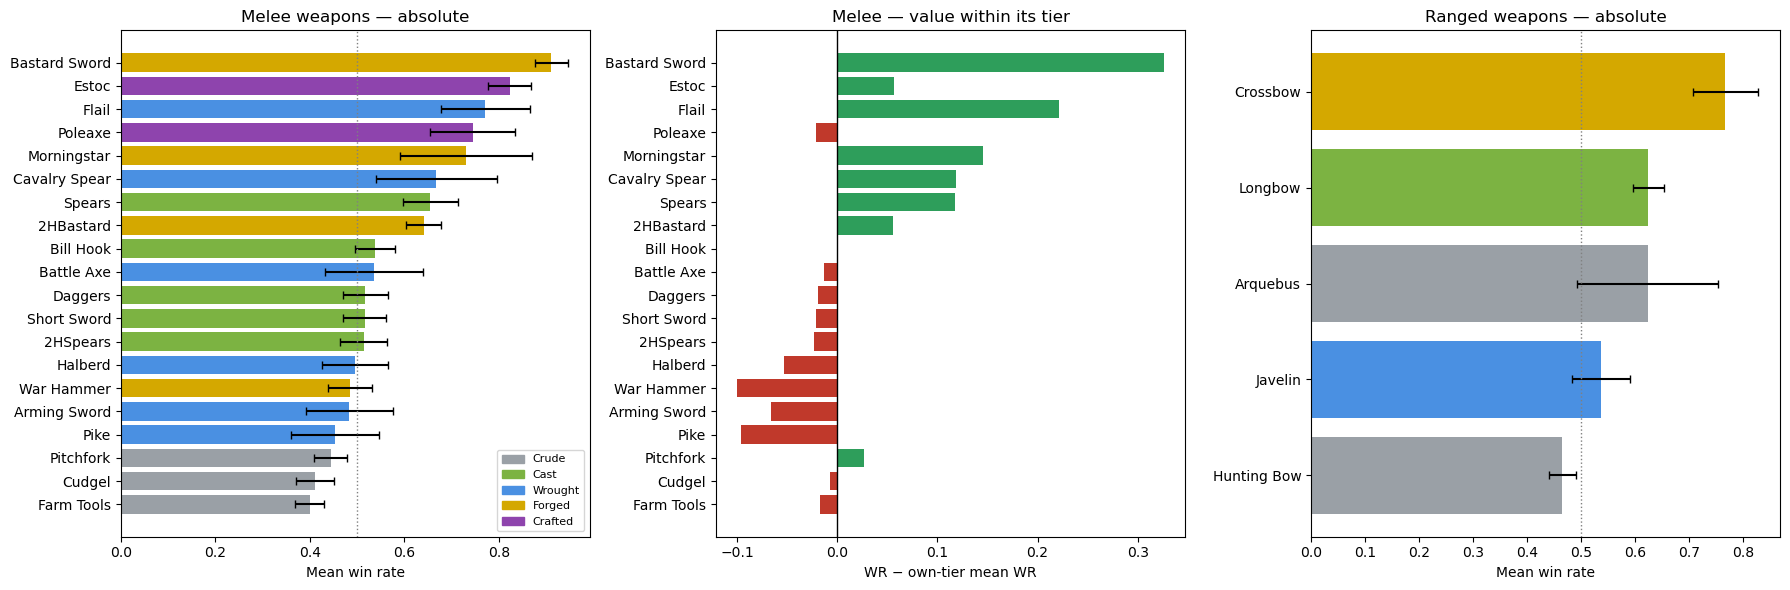

In [20]:
# Fix tier_of to handle Categorical Series safely
def tier_of(series, mapping):
  """Map to tier, sending anything unknown to '-' rather than NaN."""
  return series.map(mapping).astype(object).fillna("-")


# ============ Weapon performance: tier-adjusted ============
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MIN_N = 5  # below this, a bar is noise

# Restore S if it was overwritten by pair-level synergy results
if "A_alone" in S.columns or "weapon" not in S.columns:
  if "df_main_summary" in globals():
    S = df_main_summary.copy()


def _get_col(df, key):
  """Finds key or prefixed variant (e.g., 'weapon' vs 'a_weapon')."""
  candidates = [key, f"a_{key}", key.lower(), f"a_{key.lower()}"]
  for c in candidates:
    if c in df.columns:
      return c
  raise KeyError(
      f"Could not find '{key}' or variant in DataFrame columns: {list(df.columns)}"
  )


def _agg(frame, key, tiermap):
  col = _get_col(frame, key)
  name_col = _get_col(frame, "name")

  d = frame[frame[col].notna() & (frame[col].astype(str) != "")]
  t = tier_of(d[col], tiermap)
  g = (
      d.assign(_tier=t.values)
      .groupby(col, observed=True)
      .agg(
          n=(name_col, "count"),
          wr=("win_rate", "mean"),
          sd=("win_rate", "std"),
          dec=("decisive_win_rate", "mean"),
          tier=("_tier", "first"),
      )
  )
  if "kill_efficiency" in d.columns:
    g["keff"] = d.groupby(col, observed=True)["kill_efficiency"].mean()

  g["sem"] = g["sd"] / np.sqrt(g["n"])
  g["rankable"] = g["n"] >= MIN_N
  tier_mean = (
      d.assign(_tier=t.values)
      .groupby("_tier", observed=True)["win_rate"]
      .mean()
  )
  g["vs_tier"] = g["wr"] - g["tier"].map(tier_mean)
  return g.sort_values("wr", ascending=False)


g = _agg(S, "weapon", WTIER)
gr = _agg(S, "ranged", RTIER)

cols = [
    c
    for c in ["n", "wr", "sem", "vs_tier", "dec", "keff", "tier", "rankable"]
    if c in g.columns
]
print("=== Melee (tier-adjusted) ===")
print(g[cols].round(3).to_string())
print("\n=== Ranged ===")
print(gr[[c for c in cols if c in gr.columns]].round(3).to_string())

thin = list(g.index[~g["rankable"]]) + list(gr.index[~gr["rankable"]])
if thin:
  print(f"\nNOT RANKABLE (n < {MIN_N}): {thin}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))


def safe_color(t):
  return TIER_COLOR.get(t, "#888888") if isinstance(TIER_COLOR, dict) else "#888888"


ax = axes[0]
ax.barh(
    g.index[::-1],
    g["wr"][::-1],
    xerr=g["sem"][::-1],
    color=[safe_color(t) for t in g["tier"]][::-1],
    capsize=3,
)
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("Mean win rate")
ax.set_title("Melee weapons — absolute")

ax = axes[1]
ax.barh(
    g.index[::-1],
    g["vs_tier"][::-1],
    color=["#2e9e5b" if v > 0 else "#c0392b" for v in g["vs_tier"]][::-1],
)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("WR − own-tier mean WR")
ax.set_title("Melee — value within its tier")

ax = axes[2]
ax.barh(
    gr.index[::-1],
    gr["wr"][::-1],
    xerr=gr["sem"][::-1],
    color=[safe_color(t) for t in gr["tier"]][::-1],
    capsize=3,
)
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("Mean win rate")
ax.set_title("Ranged weapons — absolute")

handles = [
    plt.Rectangle((0, 0), 1, 1, color=safe_color(t)) for t in TIER_ORDER
]
axes[0].legend(handles, TIER_ORDER, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

=== accuracy's leverage by defender armor  (corr of attacker to_hit vs win) ===
more NEGATIVE = accuracy matters more here; ~0 = accuracy irrelevant

defender_armor  save     n  corr_tohit_win
         Cloth    10 69665          -0.209
      Gambeson     9 16934          -0.203
       Leather     7 19810          -0.178
     Chainmail     6 17426          -0.164
    Full Plate     5 27434          -0.154
  Gothic Plate     3 19637          -0.100


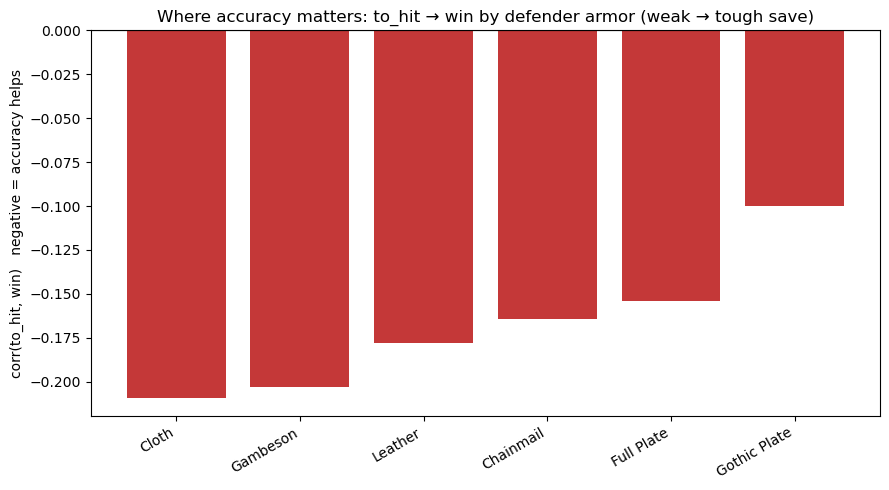


=== investment gap |a-b|  vs  one-sidedness & length ===
win_margin: 0 = coin-flip, ~1 = blowout   |   avg_skirm = battle length

 gap       n  win_margin  avg_skirm
   0 12350.0       0.695      4.926
   1 22970.0       0.707      4.934
   2 22128.0       0.719      4.898
   3 20434.0       0.732      4.861
   4 19100.0       0.743      4.826
   5 16032.0       0.759      4.809
   6 14384.0       0.787      4.757
   7 11772.0       0.804      4.716
   8  9660.0       0.837      4.677
   9  7724.0       0.856      4.624
  10  5836.0       0.881      4.493
  11  3832.0       0.917      4.377
  12  2336.0       0.941      4.253
  13  1306.0       0.966      4.148
  14   602.0       0.979      4.112
  15   286.0       0.993      4.074
  16   108.0       0.998      3.907
  17    34.0       1.000      3.753

overall avg skirmishes: 4.79


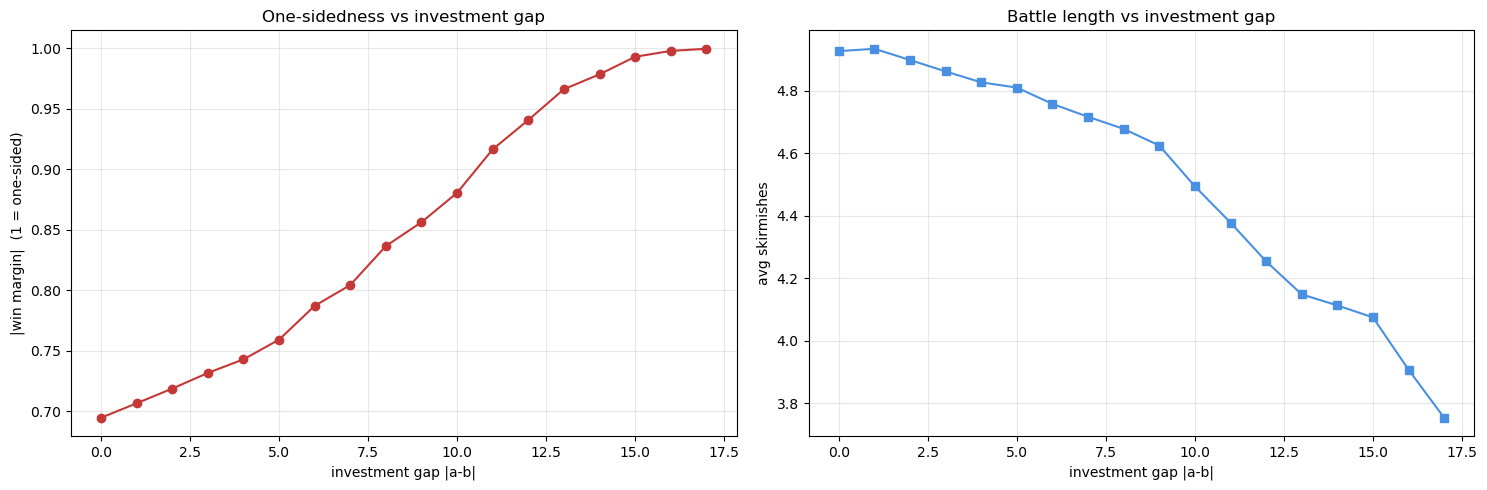

In [21]:
# ==========================================================================
# MATCHUP-LEVEL ANALYSES (run on df_main_matchups, not the per-build summary)
# ==========================================================================
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

M0 = df_main_matchups.copy()
M0 = M0[M0["a_name"] != M0["b_name"]].copy()          # drop mirror matchups
_nr = M0["n_runs"].clip(lower=1)

# ==========================================================================
# CHUNK 1 — WHERE DOES ACCURACY MATTER?  to_hit -> win, BY DEFENDER ARMOR.
# For each defender armor tier, n_runs-weighted corr(attacker to_hit, attacker
# win rate). Lower to_hit target = more accurate, so a NEGATIVE corr = accuracy
# helps you win there. Prediction: strongly negative vs weak armor (saves fail
# anyway, so landing more converts), ~0 vs Full Plate/Gothic (saves pass
# regardless, so extra volume is wasted). This is the "is Chainmail beatable
# enough for to_hit to matter" test — read the Chainmail bar.
# ==========================================================================
M = M0.copy()
M["a_wr"] = M["a_wins"] / _nr
TOHIT = {"Levy": 6, "Man-at-Arms": 5, "Sergeant": 2, "Knight Templar": 4}  # base retinue to_hit (Strike +X ignored)
M["a_tohit"] = M["a_retinue"].map(TOHIT)
SAVE = {"Cloth": 10, "Gambeson": 9, "Leather": 7, "Chainmail": 6, "Full Plate": 5, "Gothic Plate": 3}
M = M.dropna(subset=["a_tohit", "a_wr", "b_armor"])

def wcorr(x, y, w):
    xm, ym = np.average(x, weights=w), np.average(y, weights=w)
    sx = np.sqrt(np.average((x - xm) ** 2, weights=w)); sy = np.sqrt(np.average((y - ym) ** 2, weights=w))
    return np.average((x - xm) * (y - ym), weights=w) / (sx * sy) if sx > 0 and sy > 0 else np.nan

rows = []
for armor, sub in M.groupby("b_armor", observed=True):
    if len(sub) < 30 or sub["a_tohit"].nunique() < 2:
        continue
    w = sub["n_runs"].clip(lower=1).to_numpy(float)
    rows.append(dict(defender_armor=armor, save=SAVE.get(armor, 99), n=len(sub),
                     corr_tohit_win=round(wcorr(sub["a_tohit"].to_numpy(float), sub["a_wr"].to_numpy(float), w), 3)))
res = pd.DataFrame(rows).sort_values("save", ascending=False)   # weakest armor (high save) first
print("=== accuracy's leverage by defender armor  (corr of attacker to_hit vs win) ===")
print("more NEGATIVE = accuracy matters more here; ~0 = accuracy irrelevant\n")
print(res.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(res["defender_armor"], res["corr_tohit_win"],
       color=["#c43838" if v < 0 else "#888" for v in res["corr_tohit_win"]])
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("corr(to_hit, win)   negative = accuracy helps")
ax.set_title("Where accuracy matters: to_hit → win by defender armor (weak → tough save)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

# ==========================================================================
# CHUNK 2 — HOW CLOSE MUST INVESTMENT BE for battles to stay competitive / long?
# Bin matchups by |a_invest - b_invest|. win_margin = |a_wr - b_wr| (0 = coin
# flip, ~1 = blowout); avg_skirm = battle length. Answers: at what gap do fights
# become one-sided, and does closer investment lengthen them.
# ==========================================================================
M = M0.copy()
_inv = lambda s: len([x for x in str(s).split("|") if x.strip()])
M["a_inv"] = M["a_pursuits"].map(_inv); M["b_inv"] = M["b_pursuits"].map(_inv)
M["gap"] = (M["a_inv"] - M["b_inv"]).abs()
M["a_wr"] = M["a_wins"] / _nr; M["b_wr"] = M["b_wins"] / _nr
M["margin"] = (M["a_wr"] - M["b_wr"]).abs()

def _agg(d):
    w = d["n_runs"].clip(lower=1)
    return pd.Series({"n": len(d),
                      "win_margin": np.average(d["margin"], weights=w),
                      "avg_skirm": np.average(d["avg_skirm"], weights=w)})

g = M.groupby("gap").apply(_agg).reset_index()
g = g[g["n"] >= 30]
print("\n=== investment gap |a-b|  vs  one-sidedness & length ===")
print("win_margin: 0 = coin-flip, ~1 = blowout   |   avg_skirm = battle length\n")
print(g.round(3).to_string(index=False))
print(f"\noverall avg skirmishes: {np.average(M['avg_skirm'], weights=_nr):.2f}")
comp = g[g["win_margin"] < 0.5]
if len(comp):
    print(f"battles stay competitive (win_margin < 0.5) up to a gap of ~{int(comp['gap'].max())} pursuits")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(g["gap"], g["win_margin"], "o-", color="#c43838")
ax[0].set_xlabel("investment gap |a-b|"); ax[0].set_ylabel("|win margin|  (1 = one-sided)")
ax[0].set_title("One-sidedness vs investment gap"); ax[0].grid(alpha=0.3)
ax[1].plot(g["gap"], g["avg_skirm"], "s-", color="#4a90e2")
ax[1].set_xlabel("investment gap |a-b|"); ax[1].set_ylabel("avg skirmishes")
ax[1].set_title("Battle length vs investment gap"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [22]:
# ==========================================================================
# MONUMENT PACKAGE ctrl_prem  (notebook chunk)
# Collapses each combat monument into ONE variable (like the ABF package) and
# scores it investment-controlled from df_main_summary — instead of letting its
# innate/mastery tags launder each other in the per-tag harness.
#
# Two levels per monument:
#   innate   = build carries ANY of the monument's innate_tags  (has the monument)
#   mastered = build carries ANY of its mastery_tags            (mastered it)
# Monuments with empty mastery_tags (Preceptory, Artillery Park) have no combat-
# detectable mastery -> only innate is shown. Political/economic monuments carry
# no tags at all -> not in the combat sim, not shown.
#
# READ: ctrl_prem = the monument's undivided edge holding TOTAL spend fixed.
# It will still carry a big d_inv/confound because a Sovereign monument only sits
# on deep builds — that's the chain's cost showing through, not hidden value.
# "Worth its Sovereign chain" = ctrl_prem must beat what those d_inv points buy
# ELSEWHERE (compare to your marginal-per-point curve), not merely be > 0.
# Detection assumes a monument's tags are ~exclusive to it (true for these).
# ==========================================================================
import pandas as pd, numpy as np
import renown_data as rd

WR = "win_rate"; MIN_N = 3; QBANDS = 4

df = df_main_summary.copy()
if "total_investment" in df.columns:
    INV = "total_investment"
elif "pursuits" in df.columns:
    df["_ti"] = df["pursuits"].fillna("").map(lambda s: len([x for x in str(s).split("|") if x.strip()]))
    INV = "_ti"
else:
    INV = "military_pursuit_count"

pool_wr = df[WR].mean(); pool_inv = df[INV].mean()
df["_band"] = pd.qcut(df[INV], QBANDS, duplicates="drop")
band_wr = df.groupby("_band", observed=True)[WR].mean()

def ctrl(mask):
    sub = df[mask]
    if len(sub) < MIN_N:
        return None
    naive = sub[WR].mean() - pool_wr
    num = den = 0.0
    for b, s in sub.groupby("_band", observed=True):
        if len(s) < 3:
            continue
        num += len(s) * (s[WR].mean() - band_wr[b]); den += len(s)
    cp = num / den if den else np.nan
    ok = cp == cp
    return dict(n=len(sub), wr=round(sub[WR].mean(), 3), naive=round(naive, 3),
                ctrl_prem=round(cp, 3) if ok else np.nan,
                d_inv=round(sub[INV].mean() - pool_inv, 2),
                confound=round(naive - cp, 3) if ok else np.nan)

DICT_COL = {"WEAPONS": "weapon", "RANGED": "ranged", "SHIELDS": "shield", "ARMORS": "armor"}
def tagset(row):
    s = set()
    for dn, c in DICT_COL.items():
        D = getattr(rd, dn, None); x = row.get(c)
        if D and x in D:
            s |= {str(t) for t in D[x].get("tags", [])}
    bt = row.get("tags", "")
    if isinstance(bt, str) and bt:
        s |= {t.strip() for t in bt.replace("|", ",").split(",") if t.strip()}
    return s
df["_tags"] = df.apply(tagset, axis=1)

MONS = {k: v for k, v in getattr(rd, "NODES", {}).items()
        if isinstance(v, dict) and v.get("monument") is True}

rows, unmeas = [], []
for name, node in MONS.items():
    eng = node.get("engine", {}) or {}
    innate = [str(t) for t in (eng.get("innate_tags") or [])]
    mastery = [str(t) for t in (eng.get("mastery_tags") or [])]
    if not innate and not mastery:
        unmeas.append((name, "no combat tags (political/economic)")); continue
    for level, tags in (("mastered", mastery), ("innate", innate)):
        if not tags:
            if level == "mastered":
                unmeas.append((name, "mastery grants no combat tag (innate only below)"))
            continue
        mask = df["_tags"].apply(lambda s, tg=set(tags): bool(s & tg))
        r = ctrl(mask)
        if r:
            rows.append({"monument": name, "level": level, "tags": ",".join(tags), **r})
        else:
            unmeas.append((f"{name} [{level}]", f"n<{MIN_N} in pool"))

out = pd.DataFrame(rows)
if len(out):
    out = out[["monument", "level", "n", "wr", "naive", "ctrl_prem", "d_inv", "confound", "tags"]] \
        .sort_values("ctrl_prem", ascending=False).reset_index(drop=True)
    pd.set_option("display.max_rows", None); pd.set_option("display.width", 200)
    print(f"investment axis: {INV}\n===== MONUMENT PACKAGES (by real edge) =====")
    print(out.to_string(index=False))
else:
    print("No measurable monument packages found — check the tags column / NODES.")

if unmeas:
    print("\n---- not measurable from this run ----")
    for n, why in unmeas:
        print(f"   {n}: {why}")

No measurable monument packages found — check the tags column / NODES.

---- not measurable from this run ----
   Marshal Tiltyard: no combat tags (political/economic)
   Polish House: no combat tags (political/economic)
   Ossuary Crypt: no combat tags (political/economic)
   Baggage Train: no combat tags (political/economic)
   Black Hold: no combat tags (political/economic)
   Sacristy Redoubt: no combat tags (political/economic)
   Court Armoury: no combat tags (political/economic)
   Serfdom: no combat tags (political/economic)
   Office of Works: no combat tags (political/economic)
   Royal Pavilion: no combat tags (political/economic)
   Imperial Palace: no combat tags (political/economic)
   Artillery Park: no combat tags (political/economic)
   Ministry of Military Strategy: no combat tags (political/economic)
   Thieves' Guild: no combat tags (political/economic)
   Senate Hall: no combat tags (political/economic)
   Papal Palace: no combat tags (political/economic)
   Inquis

x-axis: _xcost   (INCLUDE_DOMAIN_COST=True)
== domain-path summary ==
  domain   n  mean_wr  wr_low_spend  wr_high_spend  slope_per_pt
Industry  46    0.494         0.166          0.729         0.027
 Prowess 139    0.420         0.240          0.595         0.018
 Cunning  31    0.390         0.204          0.580         0.023
   Piety  68    0.667         0.398          0.873         0.033
   Mixed 166    0.534         0.235          0.799         0.024

coincident lines = balanced; a line sitting above = that path is overpaid;
wr_high >> wr_low with small early slope = back-loaded capstone -> read the BEST panel.


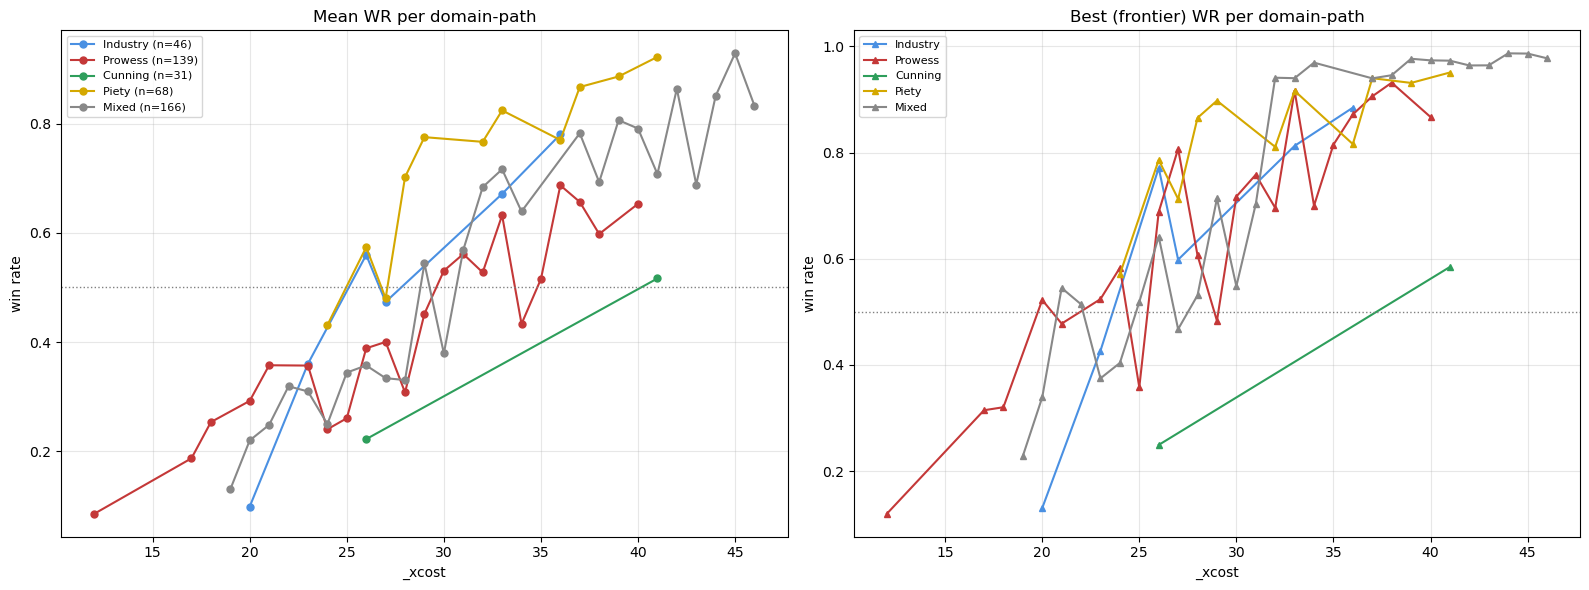

In [23]:
# ==========================================================================
# DOMAIN-PATH BALANCE  (notebook chunk)
# Marginal win rate vs total investment, one line per PRIMARY DOMAIN (the tree
# a build sank into). Reads df_main_summary. Primary domain is parsed from the
# build's domain standings in its name, e.g. "(EInd, SProw, NPie, NCun)" ->
# N/R/E/S = Untested/Rising/Established/Sovereign = 0/3/6/10. Primary = the
# single highest standing; ties -> "Mixed".
#
# HOW TO READ (balance in a cumulative tree):
#  * lines COINCIDE vs investment          -> balanced (equal WR at equal spend)
#  * one line sits consistently ABOVE       -> that path is a rush / overpaid
#  * weak early stretch then a late upswing -> back-loaded capstone (healthy)
#  Judge capstones on the RIGHT (best/frontier) panel — the mean panel is dragged
#  down by trap builds sharing the band, which understates a well-built capstone.
#
# CAVEAT you must decide: is domain standing a SEPARATE resource (domain points,
# ~1/turn) or already counted in total_investment? If separate, "equal
# total_investment" is NOT equal total cost — a Sovereign build also spent a
# scarce standing track. Flip INCLUDE_DOMAIN_COST=True to add standing cost
# (sum of N/R/E/S values) to the x-axis and compare at equal TOTAL cost.
# ==========================================================================
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt

INCLUDE_DOMAIN_COST = True   # True -> x = total_investment + sum(domain standings)
WR = "win_rate"; MIN_BUILDS = 20; MIN_BIN = 3

df = df_main_summary.copy()
if "total_investment" in df.columns:
    INV = "total_investment"
elif "pursuits" in df.columns:
    df["_ti"] = df["pursuits"].fillna("").map(lambda s: len([x for x in str(s).split("|") if x.strip()]))
    INV = "_ti"
else:
    INV = "military_pursuit_count"

LVL = {"N": 0, "R": 3, "E": 6, "S": 10}
DOMS = {"Ind": "Industry", "Prow": "Prowess", "Pie": "Piety", "Cun": "Cunning"}
src = "name" if "name" in df.columns else ("pursuits" if "pursuits" in df.columns else None)

def parse_doms(txt):
    d = {}
    if isinstance(txt, str):
        for lv, dm in re.findall(r'\b([NRES])(Ind|Prow|Pie|Cun)\b', txt):
            d[DOMS[dm]] = max(d.get(DOMS[dm], 0), LVL[lv])
    return d

prof = df[src].map(parse_doms) if src else pd.Series([{}] * len(df), index=df.index)

def primary(d):
    if not d:
        return "Unknown"
    mx = max(d.values()); tops = [k for k, v in d.items() if v == mx and v > 0]
    return "None" if not tops else (tops[0] if len(tops) == 1 else "Mixed")

df["_dom"] = prof.map(primary)
df["_domcost"] = prof.map(lambda d: sum(d.values()))
XCOL = INV
if INCLUDE_DOMAIN_COST:
    df["_xcost"] = df[INV] + df["_domcost"]; XCOL = "_xcost"

ORDER = ["Industry", "Prowess", "Cunning", "Piety", "Mixed"]
COL = {"Industry": "#4a90e2", "Prowess": "#c43838", "Cunning": "#2e9e5b",
       "Piety": "#d4a800", "Mixed": "#888"}
present = [d for d in ORDER if (df["_dom"] == d).sum() >= MIN_BUILDS]

if "Unknown" in df["_dom"].values and (df["_dom"] == "Unknown").mean() > 0.1:
    print(f"WARNING: {(df['_dom']=='Unknown').mean():.0%} of builds had no parseable domain "
          f"standings in '{src}'. Check that column holds the (EInd, SProw, ...) tuple.\n")

print(f"x-axis: {XCOL}   (INCLUDE_DOMAIN_COST={INCLUDE_DOMAIN_COST})\n== domain-path summary ==")
rows = []
for d in present:
    s = df[df["_dom"] == d]
    g = s.groupby(XCOL)[WR].mean()
    lo, hi = s[XCOL].quantile(.25), s[XCOL].quantile(.75)
    slope = np.polyfit(g.index.values.astype(float), g.values, 1)[0] if len(g) > 1 else np.nan
    rows.append(dict(domain=d, n=len(s), mean_wr=round(s[WR].mean(), 3),
                     wr_low_spend=round(s[s[XCOL] <= lo][WR].mean(), 3),
                     wr_high_spend=round(s[s[XCOL] >= hi][WR].mean(), 3),
                     slope_per_pt=round(slope, 3)))
print(pd.DataFrame(rows).to_string(index=False))
print("\ncoincident lines = balanced; a line sitting above = that path is overpaid;")
print("wr_high >> wr_low with small early slope = back-loaded capstone -> read the BEST panel.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for d in present:
    s = df[df["_dom"] == d]
    g = s.groupby(XCOL)[WR].agg(["mean", "max", "count"])
    g = g[g["count"] >= MIN_BIN]
    axes[0].plot(g.index, g["mean"], "o-", color=COL[d], label=f"{d} (n={len(s)})", ms=5)
    axes[1].plot(g.index, g["max"], "^-", color=COL[d], label=d, ms=5)
for ax, ttl in zip(axes, ["Mean WR per domain-path", "Best (frontier) WR per domain-path"]):
    ax.axhline(0.5, color="gray", ls=":", lw=1)
    ax.set_xlabel(XCOL); ax.set_ylabel("win rate"); ax.set_title(ttl)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

(buckets below MIN_BUILDS=20, not plotted): Prowess:18, Cunning×Piety:7, Industry:2, Piety:1

x-axis: _xcost  | grouping: pairs  | INCLUDE_DOMAIN_COST=True
== domain-path summary ==
            path   n  mean_wr  wr_low_spend  wr_high_spend  slope_per_pt
Industry×Prowess 220    0.466         0.263          0.664         0.022
   Piety×Prowess 106    0.583         0.264          0.820         0.030
  Industry×Piety  42    0.797         0.540          0.942         0.031
 Cunning×Prowess  32    0.395         0.201          0.545         0.019
Cunning×Industry  22    0.404         0.146          0.588         0.020

coincident lines = balanced; a line sitting above = that path is overpaid;
wr_high >> wr_low with small early slope = back-loaded capstone -> read the BEST panel.


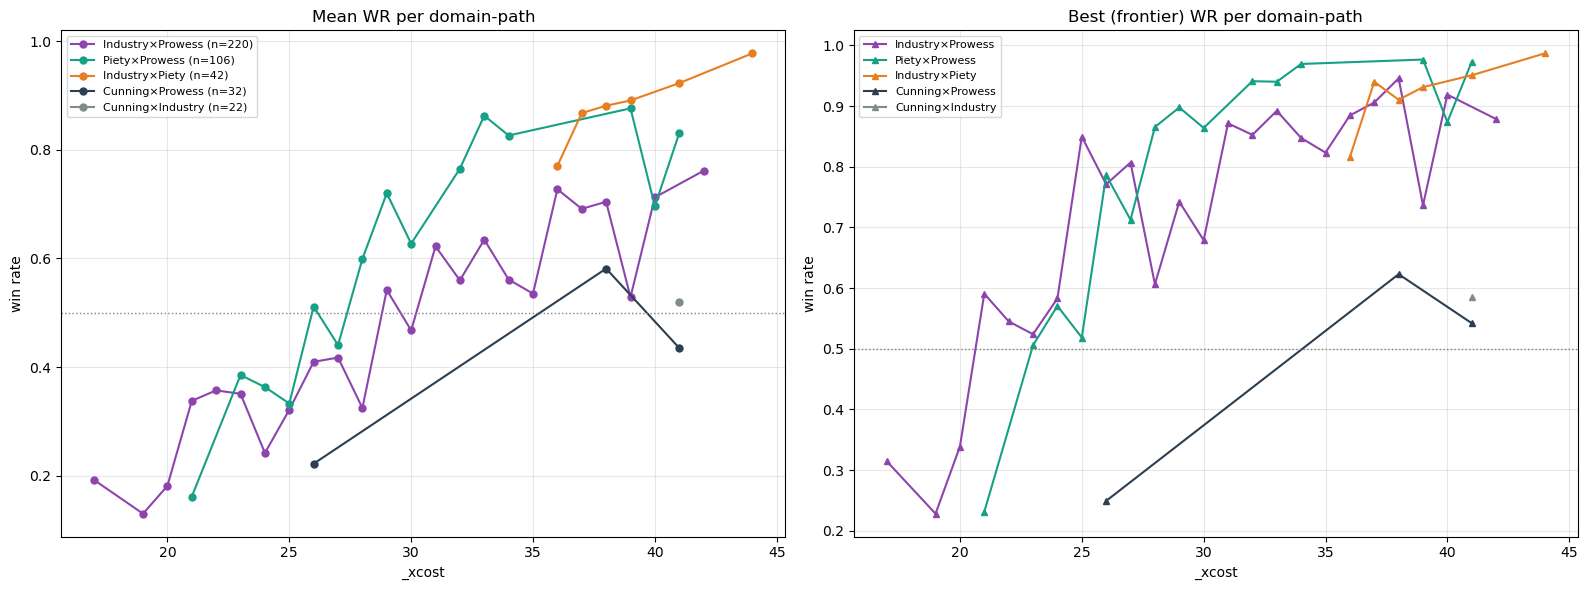

In [24]:
# ==========================================================================
# DOMAIN-PATH BALANCE  (notebook chunk)
# Marginal win rate vs total investment, one line per domain-path. Reads
# df_main_summary. Domain standings parsed from the build name, e.g.
# "(EInd, SProw, NPie, NCun)" -> N/R/E/S = Untested/Rising/Established/Sovereign
# = 0/3/6/10.
#
# GROUPING:
#   "pairs"   -> label by the TOP TWO invested domains: "Piety×Prowess",
#                "Industry×Prowess", ...  Mono-domain builds stay a single line.
#                (splits the old "Mixed" lump into named pair archetypes.)
#   "primary" -> old behaviour: single highest domain; ties -> "Mixed".
#
# HOW TO READ (balance in a cumulative tree):
#  * lines COINCIDE vs investment          -> balanced (equal WR at equal spend)
#  * one line sits consistently ABOVE       -> that path is a rush / overpaid
#  * weak early stretch then a late upswing -> back-loaded capstone (healthy)
#  Judge capstones on the RIGHT (best/frontier) panel.
#
# INCLUDE_DOMAIN_COST: if domain standing is a separate resource (not already in
# total_investment), True adds standing cost (sum of N/R/E/S) to the x-axis so
# you compare at equal TOTAL cost.
# ==========================================================================
import pandas as pd, numpy as np, re, itertools
import matplotlib.pyplot as plt

GROUPING = "pairs"            # "pairs" or "primary"
INCLUDE_DOMAIN_COST = True    # x = total_investment + sum(domain standings)
WR = "win_rate"; MIN_BUILDS = 20; MIN_BIN = 3

df = df_main_summary.copy()
if "total_investment" in df.columns:
    INV = "total_investment"
elif "pursuits" in df.columns:
    df["_ti"] = df["pursuits"].fillna("").map(lambda s: len([x for x in str(s).split("|") if x.strip()]))
    INV = "_ti"
else:
    INV = "military_pursuit_count"

LVL = {"N": 0, "R": 3, "E": 6, "S": 10}
DOMS = {"Ind": "Industry", "Prow": "Prowess", "Pie": "Piety", "Cun": "Cunning"}
ORD = ["Industry", "Prowess", "Cunning", "Piety"]   # deterministic tie-break
src = "name" if "name" in df.columns else ("pursuits" if "pursuits" in df.columns else None)

def parse_doms(txt):
    d = {}
    if isinstance(txt, str):
        for lv, dm in re.findall(r'\b([NRES])(Ind|Prow|Pie|Cun)\b', txt):
            d[DOMS[dm]] = max(d.get(DOMS[dm], 0), LVL[lv])
    return {k: v for k, v in d.items() if v > 0}

prof = df[src].map(parse_doms) if src else pd.Series([{}] * len(df), index=df.index)

def label(d):
    if not d:
        return "None"
    if len(d) == 1 or GROUPING == "primary":
        mx = max(d.values()); tops = [k for k, v in d.items() if v == mx]
        return tops[0] if len(tops) == 1 else ("Mixed" if GROUPING == "primary" else
               "×".join(sorted(tops[:2])))
    # pairs: the two most-invested domains (tie-break by ORD), name sorted
    ranked = sorted(d.items(), key=lambda kv: (-kv[1], ORD.index(kv[0])))
    return "×".join(sorted([ranked[0][0], ranked[1][0]]))

df["_dom"] = prof.map(label)
df["_domcost"] = prof.map(lambda d: sum(d.values()))
XCOL = INV
if INCLUDE_DOMAIN_COST:
    df["_xcost"] = df[INV] + df["_domcost"]; XCOL = "_xcost"

present = sorted([d for d in df["_dom"].unique()
                  if d not in ("None",) and (df["_dom"] == d).sum() >= MIN_BUILDS],
                 key=lambda d: -(df["_dom"] == d).sum())   # most-populated first

FIXED = {"Industry": "#4a90e2", "Prowess": "#c43838", "Cunning": "#2e9e5b", "Piety": "#d4a800"}
_pal = itertools.cycle(["#8e44ad", "#16a085", "#e67e22", "#2c3e50", "#7f8c8d",
                        "#2980b9", "#27ae60", "#d35400", "#8e44ad", "#c0392b"])
COL = {d: FIXED.get(d, next(_pal)) for d in present}

dropped = df[~df["_dom"].isin(present) & (df["_dom"] != "None")]["_dom"].value_counts()
if len(dropped):
    print(f"(buckets below MIN_BUILDS={MIN_BUILDS}, not plotted): " +
          ", ".join(f"{k}:{v}" for k, v in dropped.items()) + "\n")

print(f"x-axis: {XCOL}  | grouping: {GROUPING}  | INCLUDE_DOMAIN_COST={INCLUDE_DOMAIN_COST}\n== domain-path summary ==")
rows = []
for d in present:
    s = df[df["_dom"] == d]
    g = s.groupby(XCOL)[WR].mean()
    lo, hi = s[XCOL].quantile(.25), s[XCOL].quantile(.75)
    slope = np.polyfit(g.index.values.astype(float), g.values, 1)[0] if len(g) > 1 else np.nan
    rows.append(dict(path=d, n=len(s), mean_wr=round(s[WR].mean(), 3),
                     wr_low_spend=round(s[s[XCOL] <= lo][WR].mean(), 3),
                     wr_high_spend=round(s[s[XCOL] >= hi][WR].mean(), 3),
                     slope_per_pt=round(slope, 3)))
print(pd.DataFrame(rows).to_string(index=False))
print("\ncoincident lines = balanced; a line sitting above = that path is overpaid;")
print("wr_high >> wr_low with small early slope = back-loaded capstone -> read the BEST panel.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for d in present:
    s = df[df["_dom"] == d]
    g = s.groupby(XCOL)[WR].agg(["mean", "max", "count"])
    g = g[g["count"] >= MIN_BIN]
    axes[0].plot(g.index, g["mean"], "o-", color=COL[d], label=f"{d} (n={len(s)})", ms=5)
    axes[1].plot(g.index, g["max"], "^-", color=COL[d], label=d, ms=5)
for ax, ttl in zip(axes, ["Mean WR per domain-path", "Best (frontier) WR per domain-path"]):
    ax.axhline(0.5, color="gray", ls=":", lw=1)
    ax.set_xlabel(XCOL); ax.set_ylabel("win rate"); ax.set_title(ttl)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

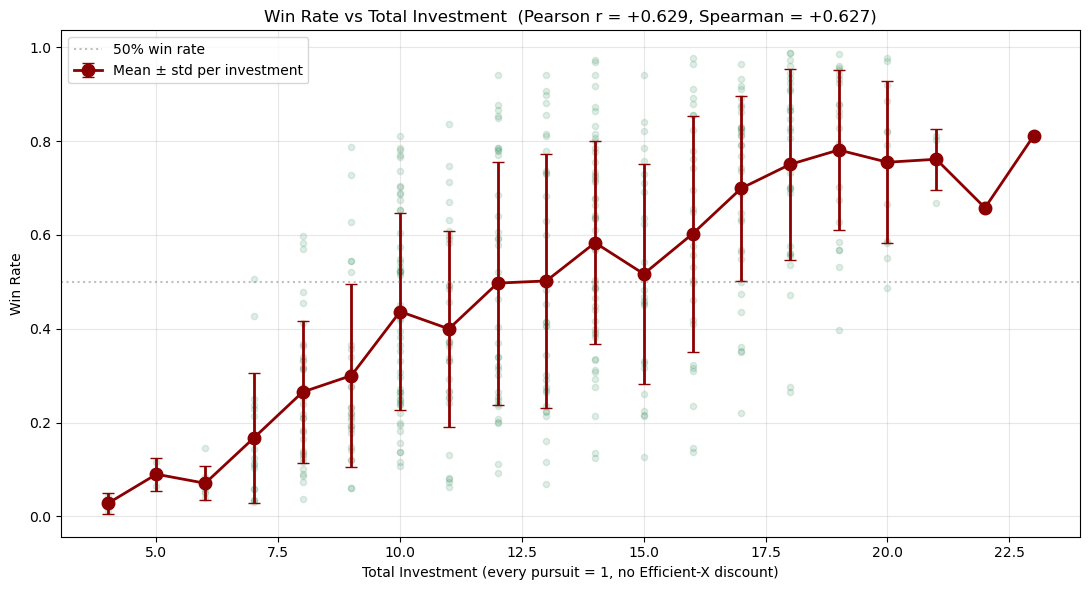

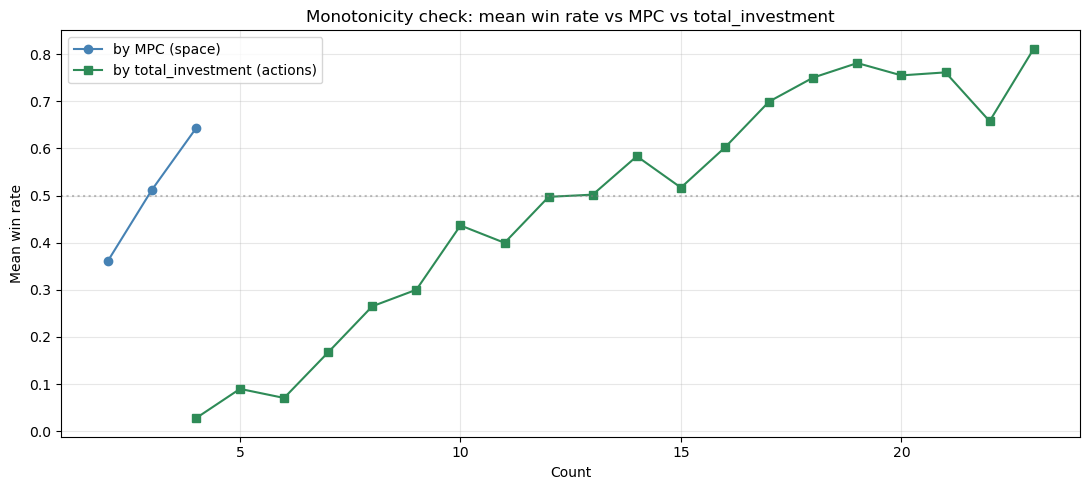


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\total_investment_.png


In [25]:
# Visualize: Total Investment vs Win Rate scatter + binned mean line (compare to the MPC plot)
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(gi["total_investment"], gi["win_rate"], alpha=0.15, s=20, color="seagreen")
binned = gi.groupby("total_investment")["win_rate"].agg(["mean", "std", "count"])
ax.errorbar(binned.index, binned["mean"], yerr=binned["std"], fmt="o-", color="darkred",
            markersize=9, linewidth=2, capsize=4, label="Mean ± std per investment")
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5, label="50% win rate")
ax.set_xlabel("Total Investment (every pursuit = 1, no Efficient-X discount)")
ax.set_ylabel("Win Rate")
ax.set_title(f"Win Rate vs Total Investment  (Pearson r = {ti_r:+.3f}, Spearman = {ti_sr:+.3f})")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Side-by-side per-bucket means: does investment climb more smoothly than MPC?
inv_means = gi.groupby("total_investment")["win_rate"].mean()
mpc_means = gi.groupby("military_pursuit_count")["win_rate"].mean()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(mpc_means.index, mpc_means.values, "o-", color="steelblue", label="by MPC (space)")
ax.plot(inv_means.index, inv_means.values, "s-", color="seagreen", label="by total_investment (actions)")
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
ax.set_xlabel("Count"); ax.set_ylabel("Mean win rate")
ax.set_title("Monotonicity check: mean win rate vs MPC vs total_investment")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'total_investment_.png')}")

  THE STORY OF A BATTLE  —  34,181,200 battles

A typical engagement runs about 4.8 skirmishes. When the dust settles,
95% of battles have a clear winner; the attacker takes
48% and the defender 48% — close to
even, so the initiator slot is not a strong edge. 5% of battles end
in MUTUAL annihilation, and only 0.0% peter out indecisively.

The two sides leave roughly 5 and 5
survivors on average. Of every casualty inflicted, 70% fall in direct
combat, 22% break from exhaustion (shaken), 8% break
under heavy losses (waver), and 0% are cut down in the rout. Shields are destroyed in
0.3% of battles.

WHAT WINS BATTLES (correlation of each combat stat with win rate):
   shaking     -0.58  #################              (lower is better)
   to_hit      -0.35  ##########                     (lower is better)
   eff_save    -0.33  ##########                     (lower is better)
   weapon_ap   -0.13  ###                            (lower is better)
   endurance   -0.13  ###                    

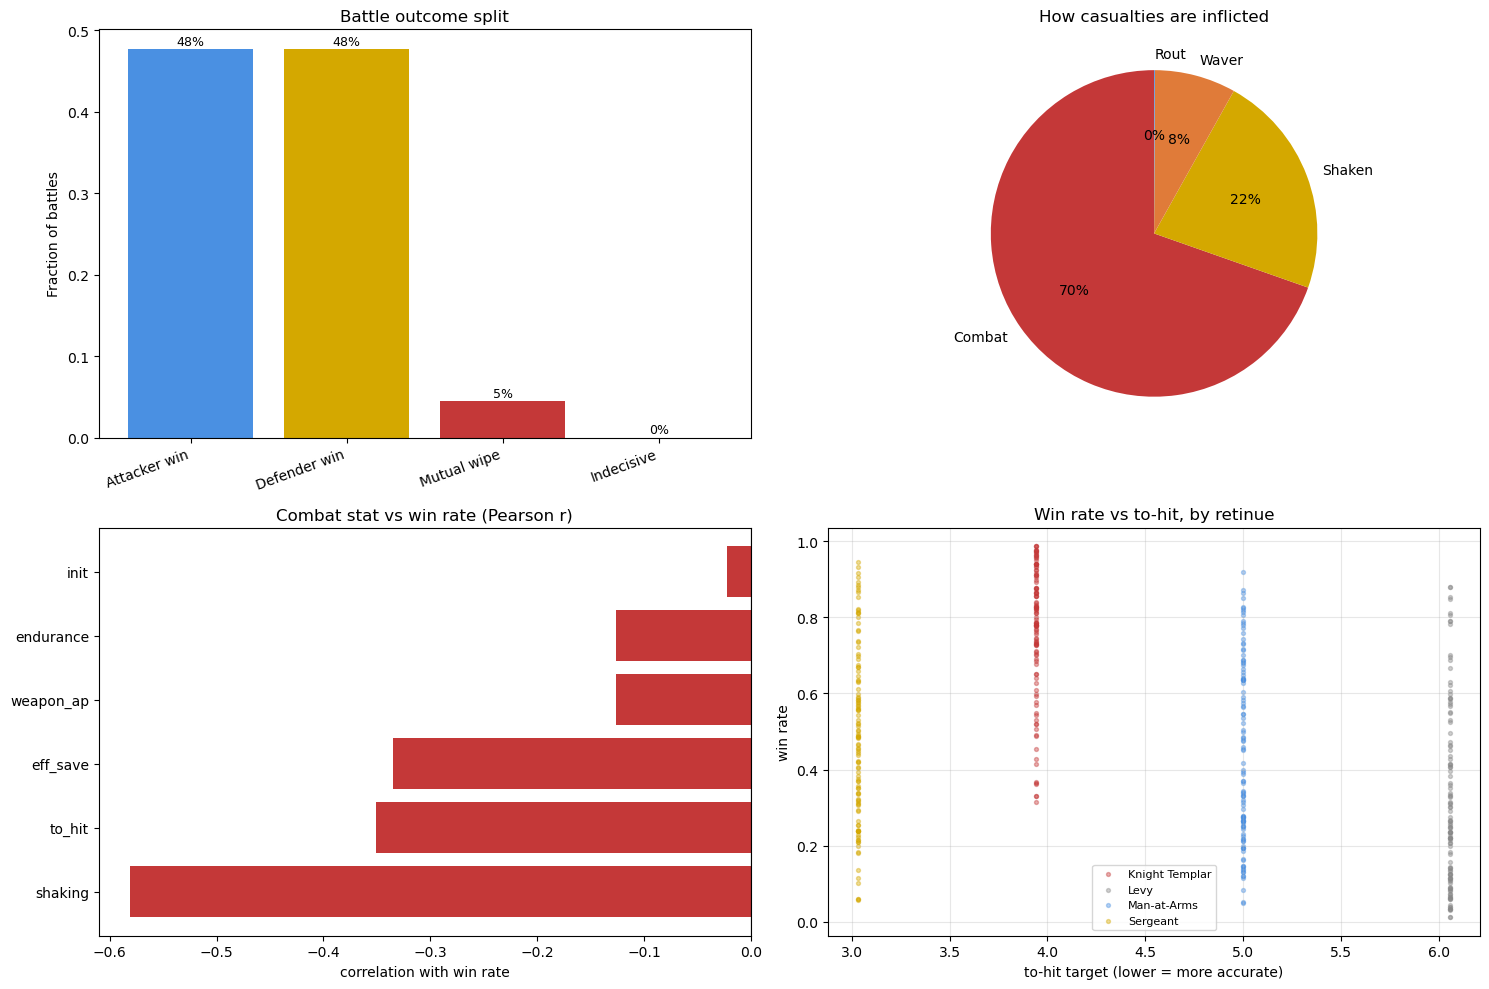

In [26]:
# ── Battle overview + combat-stat correlations + narrative ──
import matplotlib.pyplot as plt
import analysis
import loadouts as L, playstyles, analysis

# reload the EXACT pool the tournament ran on, from its saved CSV companion
# if the tournament assigned playstyles, re-apply the same default so names/state match:
MAIN_POOL = [p._replace(playstyle=playstyles.assign_default_playstyle(p)) for p in MAIN_POOL]
ov   = analysis.battle_overview(df_main_matchups)
st   = analysis.build_stat_table(MAIN_POOL)
m, corr = analysis.stat_winrate_correlation(df_main_summary, st)

pop = {"avg_to_hit": st["to_hit"].mean(), "avg_init": st["init"].mean(),
       "avg_eff_save": st["eff_save"].mean(), "avg_endurance": st["endurance"].mean()}

print("=" * 68)
print("  THE STORY OF A BATTLE  —  {:,} battles".format(ov["total_battles"]))
print("=" * 68)
print(f"""
A typical engagement runs about {ov['avg_skirmishes']:.1f} skirmishes. When the dust settles,
{ov['decisive_rate']*100:.0f}% of battles have a clear winner; the attacker takes
{ov['attacker_win_rate']*100:.0f}% and the defender {ov['defender_win_rate']*100:.0f}% — close to
even, so the initiator slot is not a strong edge. {ov['mutual_wipe_rate']*100:.0f}% of battles end
in MUTUAL annihilation, and only {ov['indecisive_rate']*100:.1f}% peter out indecisively.

The two sides leave roughly {ov['avg_attacker_survivors']:.0f} and {ov['avg_defender_survivors']:.0f}
survivors on average. Of every casualty inflicted, {ov['kill_mix_combat_pct']*100:.0f}% fall in direct
combat, {ov['kill_mix_shake_pct']*100:.0f}% break from exhaustion (shaken), {ov['kill_mix_waver_pct']*100:.0f}% break
under heavy losses (waver), and {ov['kill_mix_rout_pct']*100:.0f}% are cut down in the rout. Shields are destroyed in
{ov['avg_shield_destroyed_rate']*100:.1f}% of battles.

WHAT WINS BATTLES (correlation of each combat stat with win rate):""")
for _, r in corr.iterrows():
    s = r["stat"]; c = r["corr_with_win_rate"]
    better = "lower is better" if s in ("to_hit","eff_save","shaking","weapon_ap") else "higher is better"
    print(f"   {s:11s} {c:+.2f}  {'#'*int(abs(c)*30):30s} ({better})")
print(f"""
Innate ACCURACY (to-hit) and MORALE (shaking) dominate — they outweigh weapon AP and initiative.
Endurance is the strongest positive driver. Population averages: to-hit {pop['avg_to_hit']:.1f},
initiative {pop['avg_init']:+.1f}, effective save {pop['avg_eff_save']:.1f}, endurance {pop['avg_endurance']:.1f}.
""")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0,0]
labels = ["Attacker win","Defender win","Mutual wipe","Indecisive"]
vals = [ov["attacker_win_rate"], ov["defender_win_rate"], ov["mutual_wipe_rate"], ov["indecisive_rate"]]
ax.bar(labels, vals, color=["#4a90e2","#d4a800","#c43838","#888"])
ax.set_title("Battle outcome split"); ax.set_ylabel("Fraction of battles")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=20, ha="right")
for i,v in enumerate(vals): ax.text(i, v+0.005, f"{v*100:.0f}%", ha="center", fontsize=9)
ax = axes[0,1]
mix = [ov["kill_mix_combat_pct"], ov["kill_mix_shake_pct"], ov.get("kill_mix_waver_pct",0.0), ov["kill_mix_rout_pct"]]
ax.pie(mix, labels=["Combat","Shaken","Waver","Rout"], autopct="%1.0f%%",
       colors=["#c43838","#d4a800","#e07b39","#4a90e2"], startangle=90)
ax.set_title("How casualties are inflicted")
ax = axes[1,0]
cc = corr.sort_values("corr_with_win_rate")
ax.barh(cc["stat"], cc["corr_with_win_rate"], color=["#c43838" if v<0 else "#4a90e2" for v in cc["corr_with_win_rate"]])
ax.axvline(0, color="k", lw=0.8); ax.set_title("Combat stat vs win rate (Pearson r)")
ax.set_xlabel("correlation with win rate")
ax = axes[1,1]
ret_colors={"Levy":"#888","Man-at-Arms":"#4a90e2","Sergeant":"#d4a800","Knight Templar":"#c43838"}
for ret,grp in m.groupby("retinue"):
    ax.scatter(grp["to_hit"]+(hash(ret)%5-2)*0.03, grp["win_rate"], s=8, alpha=0.4, label=ret, color=ret_colors.get(ret,"#555"))
ax.set_xlabel("to-hit target (lower = more accurate)"); ax.set_ylabel("win rate")
ax.set_title("Win rate vs to-hit, by retinue"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "battle_overview.png"), dpi=110, bbox_inches="tight"); plt.show()

=== Equipment value by slot × tier (head-to-head, equal-TI) ===
    member_wr = win rate of the side that has this gear vs a side that doesn't, equal investment
  slot    tier                   gate  cost_pts  pairs  member_wr   lift  lift_per_pt
weapon    Cast                Furnace       1.0  14688      0.524  0.024       0.0241
weapon Wrought             Blacksmith       1.0   6108      0.546  0.046       0.0463
weapon  Forged                  Forge       1.0  10444      0.495 -0.005      -0.0053
weapon Crafted Advanced Blast Furnace       1.0   1676      0.649  0.149       0.1489
 armor    Cast                   None       NaN   7292      0.609  0.109          NaN
 armor Wrought                   None       NaN   6498      0.506  0.006          NaN
 armor  Forged                   None       NaN   9412      0.533  0.033          NaN
 armor Crafted                   None       NaN   7584      0.677  0.177          NaN
shield    Cast                   None       NaN   2422      0.545

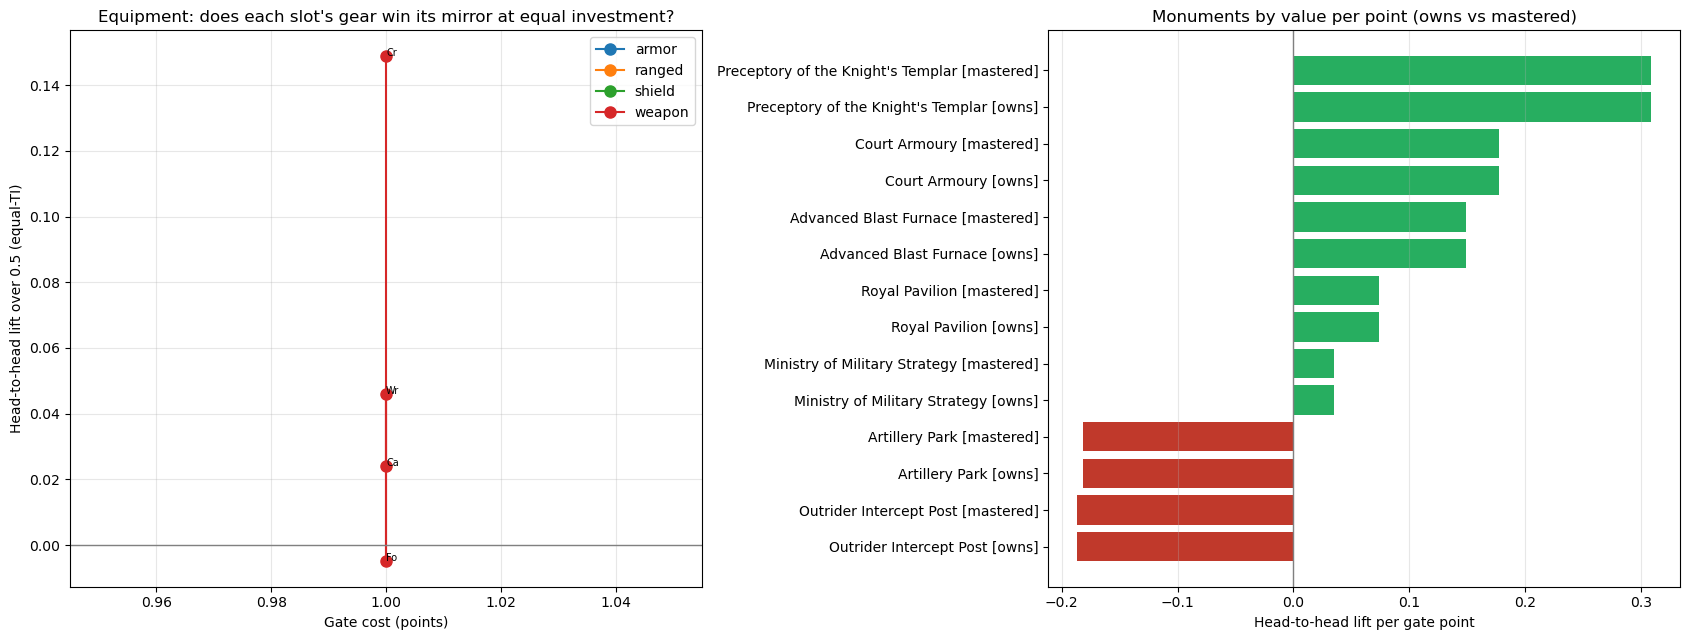


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\value_headtohead.png


In [27]:
# ============================================================================
# Equipment (slot × tier) + Monument value — MATCHUP-LEVEL, equal investment
# Requires: df_main_summary (build attrs) and df_main_matchups (a_name, b_name,
#           a_win_rate) and OUT_DIR.
# ============================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
import renown_data as rd

MIN_PAIRS = 80      # min contested equal-TI pairs for a bucket to count
EQ_TOL    = 1
ENG = {n: v["engine"] for n, v in rd.NODES.items() if "engine" in v}

def closure(name, seen=None):
    seen = seen or set()
    if name in seen or name not in ENG: return seen
    seen.add(name)
    for p in ENG[name].get("prereqs", []): closure(p, seen)
    return seen
def cost_incl(node, mastery=False):
    c = set(closure(node))
    if mastery:
        for r in ENG.get(node, {}).get("mastery_req", []): c |= closure(r)
    return max(1, len(c))

# ── build-attribute table (indexed by build name) from the summary ──
bi = df_main_summary.copy()
for c in ["shield", "ranged"]:
    bi[c] = bi[c].astype(object).replace("", "None").fillna("None")
bi["pset"] = bi["pursuits"].fillna("").map(lambda s: {x for x in s.split("|") if x})
bi["ti"]   = bi["pset"].map(len)
bi = bi.set_index("name")
TI = bi["ti"]

# ── matchup frame: resolve names -> ti, win rate of side A ──
mp = df_main_matchups.copy()
awr_col = "a_win_rate" if "a_win_rate" in mp.columns else ("win_rate" if "win_rate" in mp.columns else None)
assert awr_col, f"need a_win_rate in matchups; cols={list(mp.columns)}"
mp["a_ti"] = mp["a_name"].map(TI)
mp["b_ti"] = mp["b_name"].map(TI)
mp = mp.dropna(subset=["a_ti", "b_ti"])
eq_mask = (mp["a_ti"] - mp["b_ti"]).abs() <= EQ_TOL
mp_eq = mp[eq_mask].copy()
awr = mp_eq[awr_col].astype(float)

def headtohead(memb):
    """Win rate of the bucket-owning side among equal-TI pairs where exactly
    one side owns it. Returns (member_wr, n_pairs)."""
    a_mem = mp_eq["a_name"].map(memb).fillna(False).to_numpy()
    b_mem = mp_eq["b_name"].map(memb).fillna(False).to_numpy()
    xor = a_mem ^ b_mem
    if xor.sum() < MIN_PAIRS:
        return np.nan, int(xor.sum())
    a_is_member = a_mem[xor]
    a_rate = awr.to_numpy()[xor]
    member_rate = np.where(a_is_member, a_rate, 1.0 - a_rate)
    return float(member_rate.mean()), int(xor.sum())

# ============================================================================
# PART 1 — Equipment value by slot × tier
# ============================================================================
TIERMAP = {"weapon": {w: x["tier"] for w, x in rd.WEAPONS.items()},
           "armor":  {a: x["tier"] for a, x in rd.ARMORS.items()},
           "shield": {s: x["tier"] for s, x in rd.SHIELDS.items() if s},
           "ranged": {r: x["tier"] for r, x in rd.RANGED.items()}}

def gate_for(slot, tier):
    if slot == "weapon":
        node = rd.TIER_UNLOCK.get(tier)
        rank = "mastery" if node and any("tier:" in t for t in ENG.get(node, {}).get("mastery_tags", [])) else "innate"
        return node, rank
    want = {"armor":  {"Cast": "Leather", "Wrought": "Chainmail", "Forged": "FullPlate", "Crafted": "FullPlate"},
            "shield": {t: "Shields" for t in ["Cast", "Wrought", "Forged", "Crafted"]},
            "ranged": {}}.get(slot, {}).get(tier)
    if want:
        for node, e in ENG.items():
            for rank in ("innate", "mastery"):
                if any(t == f"tier:{want}" for t in e.get(f"{rank}_tags", [])):
                    return node, rank
    return None, None

eq_rows = []
for slot in ["weapon", "armor", "shield", "ranged"]:
    for tier in ["Cast", "Wrought", "Forged", "Crafted"]:
        items = set(k for k, t in TIERMAP[slot].items() if t == tier)
        memb = (bi[slot].isin(items)).to_dict()
        wr_m, n = headtohead(memb)
        if np.isnan(wr_m):
            continue
        node, rank = gate_for(slot, tier)
        cost = cost_incl(node, mastery=(rank == "mastery")) if node else np.nan
        lift = wr_m - 0.5
        eq_rows.append({"slot": slot, "tier": tier, "gate": node, "cost_pts": cost,
                        "pairs": n, "member_wr": round(wr_m, 3), "lift": round(lift, 3),
                        "lift_per_pt": round(lift / cost, 4) if node else np.nan})

eq = pd.DataFrame(eq_rows)
pd.set_option("display.width", 200, "display.max_rows", 120)
print("=== Equipment value by slot × tier (head-to-head, equal-TI) ===")
print("    member_wr = win rate of the side that has this gear vs a side that doesn't, equal investment")
print(eq.to_string(index=False))
print("\nmember_wr (rows=slot, cols=tier):")
print(eq.pivot(index="slot", columns="tier", values="member_wr")
        .reindex(index=["weapon","armor","shield","ranged"],
                 columns=["Cast","Wrought","Forged","Crafted"]).to_string())

# ============================================================================
# PART 2 — Monument impact (ownership), owns vs mastered
# ============================================================================
MONUMENTS = [n for n, v in rd.NODES.items() if v.get("type") == "Monument" or v.get("monument")]
mon_rows = []
for m in MONUMENTS:
    e = ENG.get(m, {})
    sim_name = e.get("alias", m)                     # <-- the fix
    for rank, need in [("owns", frozenset({sim_name})),
                       ("mastered", frozenset({sim_name} | set(e.get("mastery_req", []))))]:
        memb = bi["pset"].map(lambda s, need=need: need <= s).to_dict()
        wr_m, n = headtohead(memb)
        if np.isnan(wr_m):
            continue
        cost = cost_incl(m, mastery=(rank == "mastered"))
        lift = wr_m - 0.5
        mon_rows.append({"monument": m, "rank": rank, "cost_pts": cost, "pairs": n,
                         "member_wr": round(wr_m, 3), "lift": round(lift, 3),
                         "lift_per_pt": round(lift / cost, 4)})

mon = pd.DataFrame(mon_rows).sort_values("lift_per_pt", ascending=False)
print("\n=== Monument impact (head-to-head ownership, equal-TI) ===")
print(mon.to_string(index=False))

# ============================================================================
# Figures
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
ax = axes[0]
for slot, g in eq.groupby("slot"):
    g = g.sort_values("cost_pts")
    ax.plot(g["cost_pts"], g["lift"], "o-", label=slot, markersize=8)
    for _, r in g.iterrows():
        ax.annotate(r["tier"][:2], (r["cost_pts"], r["lift"]), fontsize=7)
ax.axhline(0, color="gray", lw=1)
ax.set_xlabel("Gate cost (points)"); ax.set_ylabel("Head-to-head lift over 0.5 (equal-TI)")
ax.set_title("Equipment: does each slot's gear win its mirror at equal investment?")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
v = mon.sort_values("lift_per_pt")
ax.barh([f"{r.monument} [{r['rank']}]" for _, r in v.iterrows()], v["lift_per_pt"],
        color=["#c0392b" if x < 0 else "#27ae60" for x in v["lift_per_pt"]])
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Head-to-head lift per gate point")
ax.set_title("Monuments by value per point (owns vs mastered)")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "value_headtohead.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'value_headtohead.png')}")

In [28]:
import pandas as pd, numpy as np
df = df_main_summary
# df = per-build summary, one row per loadout, with a win-rate column
WR = "decisive_win_rate"   # or "win_rate" — whichever you've been using
ELITE_CUT = df[WR].quantile(0.85)   # top 15%; match whatever your runs use
df["_elite"] = df[WR] >= ELITE_CUT
elite = df["_elite"]
n_pool, n_elite = len(df), int(elite.sum())

def lift_table(series_pool, series_elite, label, min_pool_pct=0.0):
    """Generic lift: for each category value, elite_% vs pool_%."""
    pool = series_pool.value_counts(normalize=True).mul(100)
    el   = series_elite.value_counts(normalize=True).mul(100)
    out = pd.DataFrame({"elite_%": el, "pool_%": pool}).fillna(0)
    out["lift"] = (out["elite_%"] / out["pool_%"].replace(0, np.nan)).round(2)
    out = out[out["pool_%"] >= min_pool_pct]
    out = out.round({"elite_%":1, "pool_%":1})
    return out.sort_values("lift", ascending=False)

# ── Single-value categorical axes ──
for col in ["retinue", "weapon", "ranged", "armor", "shield", "config", "wtier"]:
    if col in df.columns:
        print(f"\n── {col} ──")
        print(lift_table(df[col], df[col][elite], col).to_string())

def multivalue_lift(get_set, label, min_count=5):
    """get_set(row) -> set of tokens (tags/pursuits) for that build."""
    from collections import Counter
    pool_c, elite_c = Counter(), Counter()
    for _, row in df.iterrows():
        toks = get_set(row)
        pool_c.update(toks)
        if row["_elite"]:
            elite_c.update(toks)
    rows = []
    for tok, pc in pool_c.items():
        if pc < min_count:      # drop ultra-rare tokens (noisy lift)
            continue
        ec = elite_c.get(tok, 0)
        pool_pct  = 100*pc/n_pool
        elite_pct = 100*ec/n_elite
        rows.append({label: tok, "elite_%": round(elite_pct,1),
                     "pool_%": round(pool_pct,1),
                     "lift": round(elite_pct/pool_pct, 2) if pool_pct else 0})
    return pd.DataFrame(rows).sort_values("lift", ascending=False)

# ── Tags — CRITICAL: combine all tag columns, not just a_tags ──
def tags_of(row):
    toks = set()
    for c in ["extra_tags", "a_tags_normal", "a_tags_first", "tags"]:
        v = row.get(c)
        if isinstance(v, str):
            toks |= {t.strip() for t in v.replace("|",",").split(",") if t.strip()}
        elif isinstance(v, (list, set, frozenset)):
            toks |= set(v)
    return toks

print("\n── TAGS (lift) ──")
print(multivalue_lift(tags_of, "tag").to_string(index=False))

# ── Pursuits ──
def pursuits_of(row):
    v = row.get("pursuits")
    if isinstance(v, str):
        return {p.strip() for p in v.replace("|",",").split(",") if p.strip()}
    if isinstance(v, (list,set,frozenset)):
        return set(v)
    return set()

print("\n── PURSUITS (lift) ──")
print(multivalue_lift(pursuits_of, "pursuit").to_string(index=False))

import renown_data as rd

def weapon_tags_of(row):
    """Weapon + ranged intrinsic tags, looked up from renown_data."""
    toks = set()
    w, r = row.get("weapon"), row.get("ranged")
    if w and w in rd.WEAPONS:
        toks |= set(rd.WEAPONS[w].get("tags", []))
    if r and r in rd.RANGED:
        toks |= set(rd.RANGED[r].get("tags", []))
    return toks

print("\n── WEAPON TAGS (lift) ──")
print(multivalue_lift(weapon_tags_of, "weapon_tag").to_string(index=False))


── retinue ──
                elite_%  pool_%  lift
retinue                              
Knight Templar     72.1    24.7  2.92
Sergeant           14.7    24.9  0.59
Levy                7.4    25.6  0.29
Man-at-Arms         5.9    24.9  0.24

── weapon ──
               elite_%  pool_%  lift
weapon                              
Bastard Sword      4.5     0.7  6.54
Estoc              3.0     0.7  4.36
Flail              4.5     1.4  3.27
Morningstar        3.0     0.9  3.27
Poleaxe            4.5     1.8  2.45
Spears             7.5     3.4  2.18
Cavalry Spear      1.5     0.7  2.18
2HBastard         16.4     9.1  1.80
Battle Axe         4.5     2.5  1.78
Daggers           10.4     8.0  1.31
Bill Hook          7.5     7.5  0.99
Pike               1.5     2.1  0.73
2HSpears           4.5     6.4  0.70
Cudgel             6.0     9.8  0.61
Short Sword        3.0     5.5  0.54
War Hammer         4.5     8.7  0.52
Farm Tools         7.5    15.3  0.49
Pitchfork          6.0    12.8  0.47
Hal

In [29]:
df = df_main_summary
# vectorized, no iterrows — operates on the whole column at once
df["has_heal"] = (
    df["tags"].astype(str).fillna("").str.contains("Apothecary Heal")
)
print(
    df.groupby("has_heal")[["win_rate", "avg_self_survivors"]].agg(
        ["mean", "count"]
    )
)

          win_rate       avg_self_survivors      
              mean count               mean count
has_heal                                         
False     0.504829   450           5.743244   450


In [30]:
import numpy as np

m = df_main_matchups

# --- identify Hospitaller (heal stack) on side A. One vectorized str op on a_pursuits. ---
# Cast to str first to handle Categorical columns without crashing on fillna("")
a_heal = (
    m["a_pursuits"]
    .astype(str)
    .fillna("")
    .str.contains("Hospitaller")
    .to_numpy()
)

# weight by n_runs so each matchup counts by how many battles it represents
w = m["n_runs"].to_numpy().astype(float)


def wmean(col, mask):
  x = m[col].to_numpy()
  ww = w[mask]
  return np.average(x[mask], weights=ww) if ww.sum() else float("nan")


print("=" * 64)
print("SIDE-A cause-of-death + survivors:  Hospitaller vs NOT")
print("=" * 64)
cols = [
    "avg_a_rem",  # survivors
    "avg_a_killed_combat",  # heal-ABLE deaths
    "avg_a_killed_shake",  # NOT heal-able
    "avg_a_killed_waver",  # NOT heal-able
    "avg_a_killed_rout",  # NOT heal-able
    "a_win_rate",
    "avg_skirm",
]

print(f"{'metric':22s} {'Hospitaller':>12s} {'no-Hosp':>12s} {'delta':>10s}")
for c in cols:
  h = wmean(c, a_heal)
  nh = wmean(c, ~a_heal)
  print(f"{c:22s} {h:12.3f} {nh:12.3f} {h-nh:+10.3f}")

# --- the heal-footprint inference ---
print()
print("=" * 64)
print("HEAL THROUGHPUT (inferred from conservation gap)")
print("  gap = survivors + all_killed - start_size(25);  >0 ≈ bodies healed back in")
print("=" * 64)
tot_killed = (
    m["avg_a_killed_combat"]
    + m["avg_a_killed_shake"]
    + m["avg_a_killed_waver"]
    + m["avg_a_killed_rout"]
).to_numpy()
surv = m["avg_a_rem"].to_numpy()
gap = surv + tot_killed - m["a_size"].to_numpy()  # a_size is 25

for label, mask in [("Hospitaller", a_heal), ("no-Hosp", ~a_heal)]:
  g = np.average(gap[mask], weights=w[mask])
  print(f"  {label:14s} mean conservation gap (≈ heals/battle): {g:+.3f}")

print()
print("Read: if Hospitaller's combat-deaths are HIGHER but survivors are ALSO higher,")
print("heal is refunding combat losses. If survivors are higher mainly via LOWER")
print("shake/waver/rout deaths, it's the morale/recover stack, not heal.")

SIDE-A cause-of-death + survivors:  Hospitaller vs NOT
metric                  Hospitaller      no-Hosp      delta
avg_a_rem                     8.220        4.184     +4.036
avg_a_killed_combat          11.209       14.678     -3.469
avg_a_killed_shake            5.170        4.070     +1.100
avg_a_killed_waver            0.383        2.053     -1.670
avg_a_killed_rout             0.018        0.016     +0.002
a_win_rate                    0.681        0.397     +0.284
avg_skirm                     5.146        4.650     +0.496

HEAL THROUGHPUT (inferred from conservation gap)
  gap = survivors + all_killed - start_size(25);  >0 ≈ bodies healed back in
  Hospitaller    mean conservation gap (≈ heals/battle): -0.000
  no-Hosp        mean conservation gap (≈ heals/battle): -0.000

Read: if Hospitaller's combat-deaths are HIGHER but survivors are ALSO higher,
heal is refunding combat losses. If survivors are higher mainly via LOWER
shake/waver/rout deaths, it's the morale/recover stack, 

## 2.3 Can the 30-DomainCount player lose to the 16-DomainCount player?

Same question for Domain Count: does broader domain investment correlate with winning, and can a heavily-invested player be beaten by a lean one?

In [31]:
g = df_main_summary
pearson_d, _ = sp_stats.pearsonr(g["domain_count"], g["win_rate"])
spearman_d, _ = sp_stats.spearmanr(g["domain_count"], g["win_rate"])
print(f"=== Win Rate ↔ Domain Count ===")
print(f"  Pearson:  r = {pearson_d:+.3f}")
print(f"  Spearman: r = {spearman_d:+.3f}")

# MPC↔DC are highly correlated by construction. Partial: residual win rate AFTER removing MPC effect.
from sklearn.linear_model import LinearRegression
X_mpc = g[["military_pursuit_count"]].values
y = g["win_rate"].values
mpc_model = LinearRegression().fit(X_mpc, y)
y_residual = y - mpc_model.predict(X_mpc)
# Now correlate residual with DC
res_pearson, _ = sp_stats.pearsonr(g["domain_count"], y_residual)
print(f"\nWin Rate residual (after MPC removed) ↔ Domain Count:")
print(f"  Pearson:  r = {res_pearson:+.3f}")
print(f"  → If close to 0, DC doesn't add independent predictive value beyond MPC.")
print(f"  → If positive, broader domain investment HELPS independently of military spend.")
print(f"  → If negative, broader investment HURTS (suggests pursuit redundancy / wasted breadth).")

=== Win Rate ↔ Domain Count ===
  Pearson:  r = +0.672
  Spearman: r = +0.679

Win Rate residual (after MPC removed) ↔ Domain Count:
  Pearson:  r = +0.566
  → If close to 0, DC doesn't add independent predictive value beyond MPC.
  → If positive, broader domain investment HELPS independently of military spend.
  → If negative, broader investment HURTS (suggests pursuit redundancy / wasted breadth).


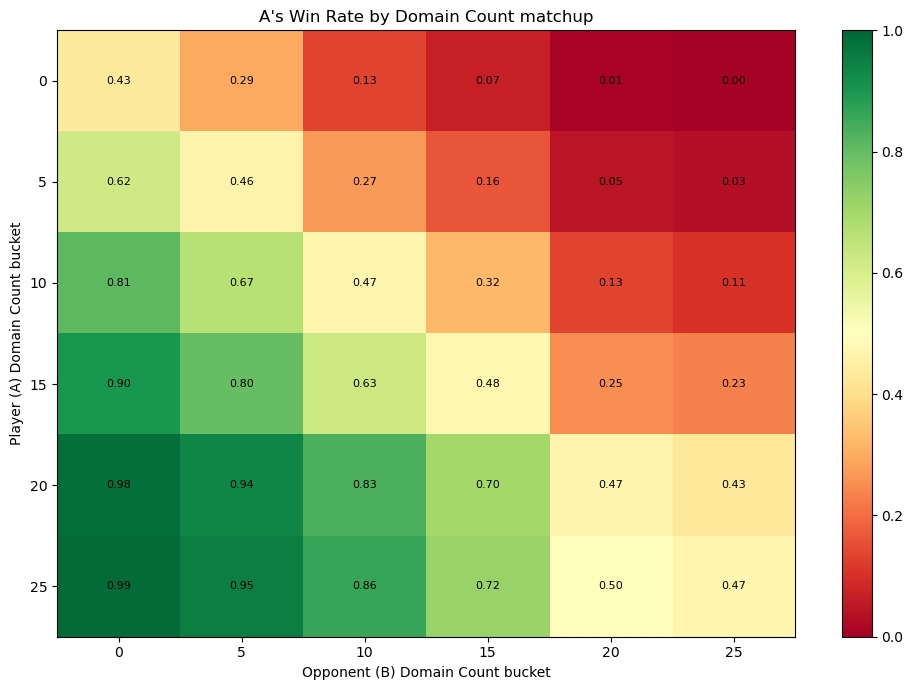


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\Domain_v_domain.png


In [32]:
# Specific test: how often does a high-DC loader lose to a low-DC loader?
# Build cross-DC matchup table
df_m["a_dc_bucket"] = (df_m["a_domain_count"] // 5) * 5  # 5-pt buckets
df_m["b_dc_bucket"] = (df_m["b_domain_count"] // 5) * 5
grp_dc = df_m.groupby(["a_dc_bucket", "b_dc_bucket"]).agg(
    a_wins=("a_wins","sum"), b_wins=("b_wins","sum"),
    mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
grp_dc["total"] = grp_dc[["a_wins","b_wins","mut","indec"]].sum(axis=1)
grp_dc["a_win_rate"] = grp_dc["a_wins"] / grp_dc["total"]
pivot_dc = grp_dc.pivot(index="a_dc_bucket", columns="b_dc_bucket", values="a_win_rate")

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(pivot_dc.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot_dc.columns))); ax.set_xticklabels(pivot_dc.columns)
ax.set_yticks(range(len(pivot_dc.index))); ax.set_yticklabels(pivot_dc.index)
ax.set_xlabel("Opponent (B) Domain Count bucket")
ax.set_ylabel("Player (A) Domain Count bucket")
ax.set_title("A's Win Rate by Domain Count matchup")
plt.colorbar(im, ax=ax)
for i in range(len(pivot_dc.index)):
    for j in range(len(pivot_dc.columns)):
        v = pivot_dc.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="black", fontsize=8)
plt.tight_layout(); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'Domain_v_domain.png')}")

builds: 420 | matchup rows: 170906


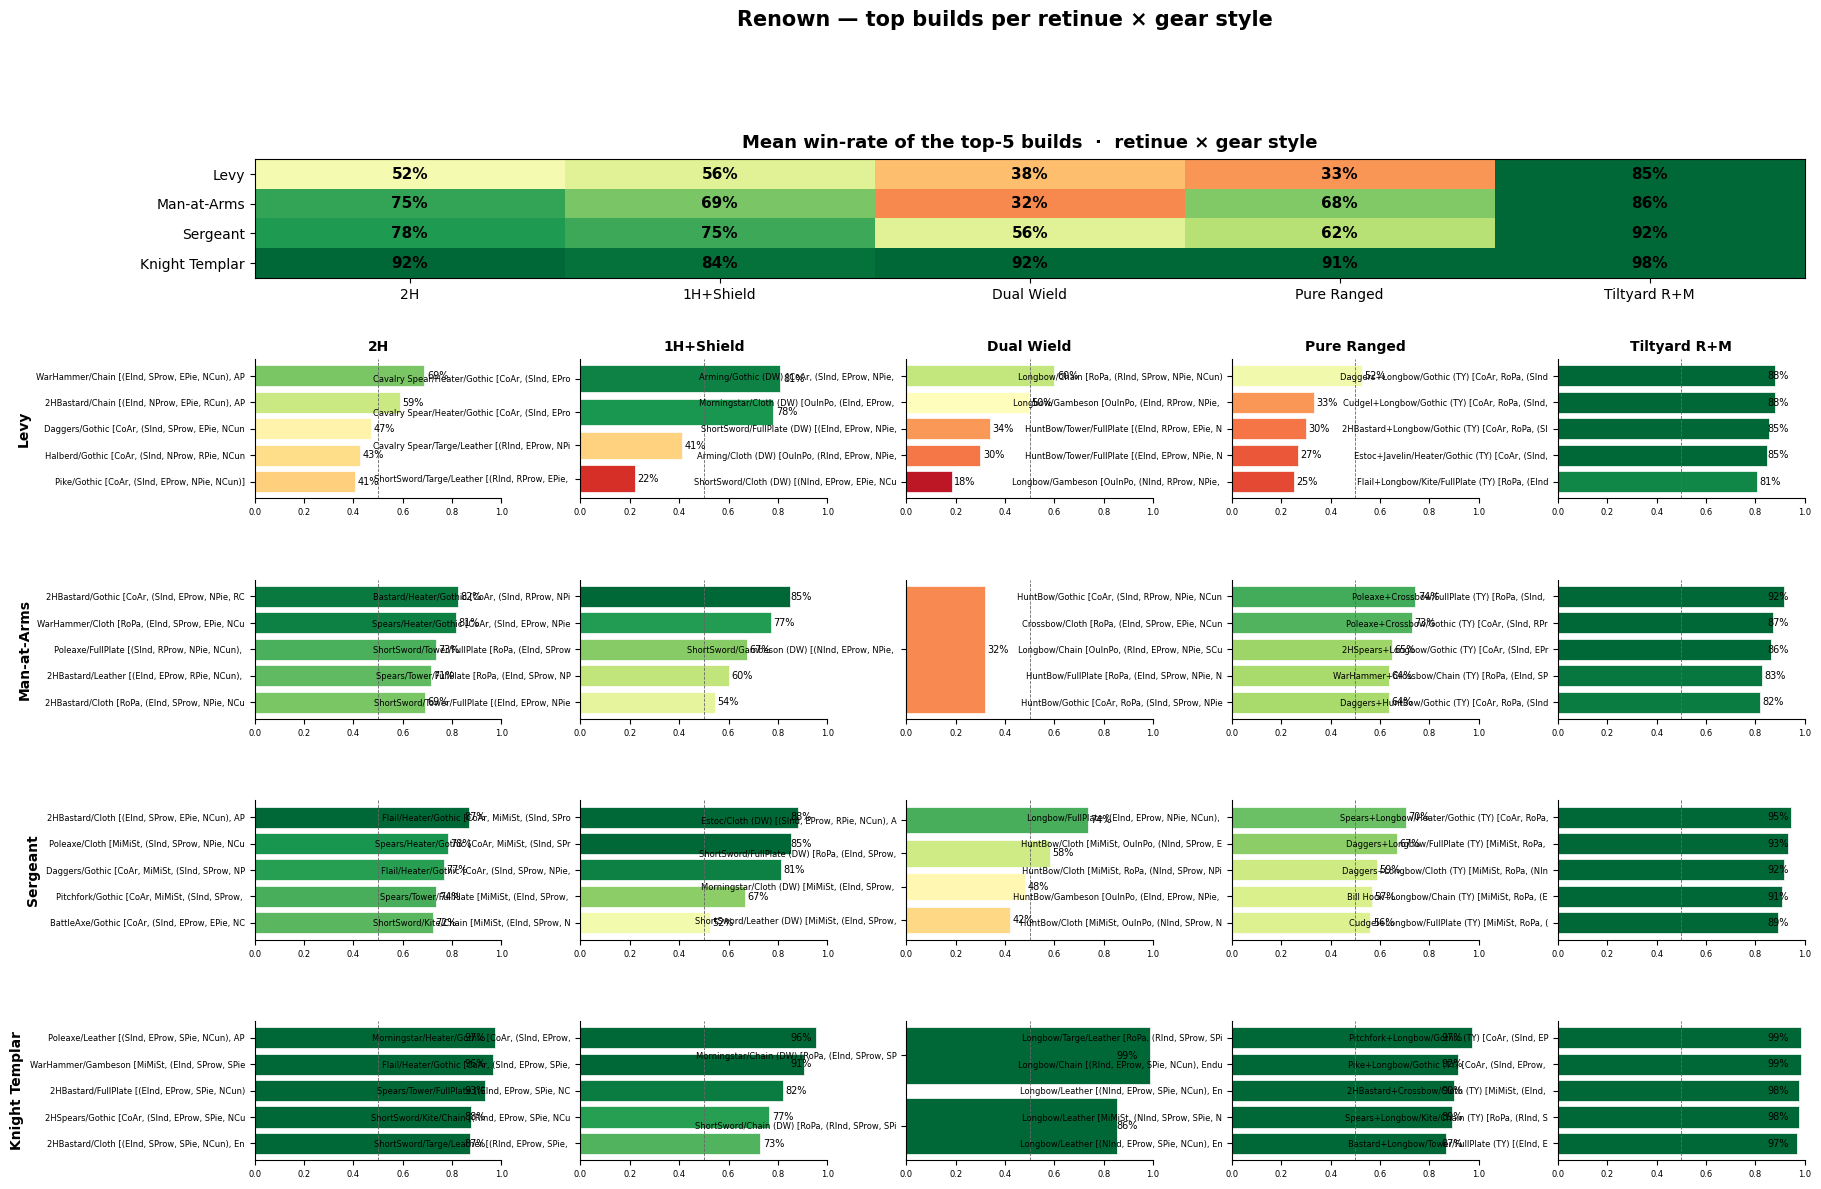


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\top_builds.png


In [33]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize
import loadouts as L
from renown_data import WEAPONS, DUAL_WIELD

m = df_main_matchups
RETS   = ["Levy", "Man-at-Arms", "Sergeant", "Knight Templar"]
ARCHES = ["2H", "1H+Shield", "Dual Wield", "Pure Ranged", "Tiltyard R+M"]
TOPK   = 5
# m = m[m["mode"] == "random"]   # uncomment for random-mode only

def _absent(s):
    return s.isna() | s.astype(str).str.strip().isin(["", "None", "none", "nan"])
def _truthy(s):
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes"])

# per-build win-rate from BOTH perspectives, games-weighted
def _side(p):
    d = pd.DataFrame({
        "name": m[f"{p}_name"], "retinue": m[f"{p}_retinue"], "weapon": m[f"{p}_weapon"],
        "shield": m[f"{p}_shield"], "armor": m[f"{p}_armor"], "ranged": m[f"{p}_ranged"],
        "tiltyard": m[f"{p}_tiltyard"], "tags": m[f"{p}_tags"].astype(str),
        "wr": m[f"{p}_win_rate"].astype(float), "n": m["n_runs"].astype(float)})
    d["wsum"] = d["wr"] * d["n"]
    return d
allrows = pd.concat([_side("a"), _side("b")], ignore_index=True)
build = allrows.groupby("name", sort=False).agg(
    wsum=("wsum", "sum"), games=("n", "sum"),
    retinue=("retinue", "first"), weapon=("weapon", "first"),
    shield=("shield", "first"), armor=("armor", "first"),
    ranged=("ranged", "first"), tiltyard=("tiltyard", "first"),
    tags=("tags", "first")).reset_index()
build["wr"] = build["wsum"] / build["games"].clip(lower=1)

# classify archetype
has_r = ~_absent(build["ranged"])
has_m = ~_absent(build["weapon"]) & (build["weapon"].astype(str) != "Farm Tools")
has_s = ~_absent(build["shield"])
ty    = _truthy(build["tiltyard"])
dw = build["weapon"].map(lambda w: DUAL_WIELD in WEAPONS.get(w, {}).get("tags", [])) | build["tags"].str.contains("Dual Wield", na=False)
two_h = build["weapon"].map(lambda w: L.is_2h(w)) & ~dw
build["archetype"] = np.select(
    [has_r & has_m & ty, has_r & ~has_m, dw, two_h, has_m & has_s],
    ["Tiltyard R+M", "Pure Ranged", "Dual Wield", "2H", "1H+Shield"],  # MUST match condition order
    default="1H bare")
build = build[build["archetype"].isin(ARCHES)].copy()
build["label"] = build["name"].astype(str).map(lambda s: s.split("/", 1)[1] if "/" in s else s)

top = build.sort_values("wr", ascending=False).groupby(["retinue", "archetype"]).head(TOPK)
piv = top.groupby(["retinue", "archetype"])["wr"].mean().unstack("archetype").reindex(index=RETS, columns=ARCHES)
print("builds:", len(build), "| matchup rows:", len(m))

# figure
norm = Normalize(0.15, 0.85); cmap = matplotlib.colormaps["RdYlGn"]
fig = plt.figure(figsize=(20, 13))
gs = GridSpec(len(RETS) + 1, len(ARCHES), height_ratios=[0.85] + [1] * len(RETS), hspace=0.6, wspace=0.32)
axh = fig.add_subplot(gs[0, :])
axh.imshow(piv.values, cmap=cmap, norm=norm, aspect="auto")
axh.set_xticks(range(len(ARCHES))); axh.set_xticklabels(ARCHES, fontsize=10)
axh.set_yticks(range(len(RETS)));   axh.set_yticklabels(RETS, fontsize=10)
axh.set_title("Mean win-rate of the top-5 builds  ·  retinue × gear style", fontsize=13, weight="bold", pad=8)
for i in range(len(RETS)):
    for j in range(len(ARCHES)):
        v = piv.values[i, j]
        if not np.isnan(v): axh.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=11, weight="bold")
for ri, ret in enumerate(RETS):
    for aj, arch in enumerate(ARCHES):
        ax = fig.add_subplot(gs[ri + 1, aj])
        sub = top[(top.retinue == ret) & (top.archetype == arch)].sort_values("wr")
        if len(sub):
            y = list(range(len(sub)))
            ax.barh(y, sub.wr.values, color=[cmap(norm(v)) for v in sub.wr], edgecolor="white", lw=0.5)
            ax.set_yticks(y); ax.set_yticklabels([s[:46] for s in sub.label.values], fontsize=6.5)
            for k, v in enumerate(sub.wr.values): ax.text(min(v + 0.01, 0.85), k, f"{v:.0%}", va="center", fontsize=7)
            ax.axvline(0.5, color="0.4", lw=0.6, ls="--")
        else:
            ax.text(0.5, 0.5, "none", ha="center", va="center", transform=ax.transAxes, color="grey"); ax.set_yticks([])
        ax.set_xlim(0, 1); ax.tick_params(labelsize=6); ax.spines[["top", "right"]].set_visible(False)
        if ri == 0: ax.set_title(arch, fontsize=10, weight="bold", pad=6)
        if aj == 0: ax.set_ylabel(ret, fontsize=10, weight="bold")
fig.suptitle("Renown — top builds per retinue × gear style", fontsize=15, weight="bold", y=0.995)
plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'top_builds.png')}")

In [34]:
ropa = df_main_summary[df_main_summary["pursuits"].str.contains("Royal Pavilion", na=False)]
print(ropa.groupby("retinue")["_elite"].agg(["mean","sum","count"]))

                    mean  sum  count
retinue                             
Knight Templar  0.625000   10     16
Levy            0.176471    3     17
Man-at-Arms     0.025000    1     40
Sergeant        0.400000    6     15


In [35]:
import pandas as pd, numpy as np
import renown_data as rd

df = df_main_summary.copy()
wr = "win_rate"

# Recover each build's four domain standings from its pursuits.
# compute_pursuit_cost returns the domain dict; reuse the sim's own function.
import loadouts as L

def standings(r):
    # pursuits stored pipe-joined in the summary; rebuild the domain dict
    P = set(str(r.get("pursuits","")).split("|"))
    _, dom, _ = L.compute_pursuit_cost(P)
    return dom   # {"Industry":n,"Prowess":n,"Piety":n,"Cunning":n}

doms = df.apply(standings, axis=1)
for d in ("Industry","Prowess","Piety","Cunning"):
    df[d] = doms.apply(lambda x: x.get(d,0))

# standing tier per domain: 0=Untested,3=Rising,6=Established,10=Sovereign
def tier(v): return "S" if v>=10 else "E" if v>=6 else "R" if v>=3 else "N"
for d in ("Industry","Prowess","Piety","Cunning"):
    df[d+"_t"] = df[d].apply(tier)

# shape = sorted standing letters, e.g. "SSEE", "EEEE", "SRNN"
df["shape"] = df.apply(lambda r: "".join(sorted(
    [r["Industry_t"],r["Prowess_t"],r["Piety_t"],r["Cunning_t"]],
    key=lambda c:{"S":0,"E":1,"R":2,"N":3}[c])), axis=1)
df["dompoints"] = df[["Industry","Prowess","Piety","Cunning"]].sum(axis=1)

# how concentrated? max single domain vs total (1.0 = all in one, 0.25 = perfectly spread)
df["concentration"] = df[["Industry","Prowess","Piety","Cunning"]].max(axis=1) / df["dompoints"].clip(lower=1)

# ---- the comparison: at similar point totals, does spread or spike win? ----
df["pt_band"] = pd.cut(df["dompoints"], [-1,10,16,22,28,99],
                       labels=["~10","11-16","17-22","23-28","29+"])

print("Win rate by domain SHAPE (top shapes by count):")
g = df.groupby("shape").agg(n=("shape","size"), wr=(wr,"mean"),
                            pts=("dompoints","mean")).round(3)
print(g[g.n>=15].sort_values("wr",ascending=False).to_string(), "\n")

print("Spread vs spike WITHIN each point band (concentration split):")
df["style"] = np.where(df["concentration"]>=0.5,"spike(1-2 deep)","spread(3-4 wide)")
print(df.groupby(["pt_band","style"],observed=True)[wr]
        .agg(["mean","count"]).round(3).to_string())

import re
ss = df[df["shape"].str.startswith("SS")].copy()
# which two domains are Sovereign?
def sov_pair(r):
    s = sorted([d for d in ("Industry","Prowess","Piety","Cunning") if r[d] >= 10])
    return "+".join(s) if len(s)==2 else "other"
ss["sov_pair"] = ss.apply(sov_pair, axis=1)
print(ss.groupby("sov_pair")[wr].agg(["mean","count"]).round(3).sort_values("mean",ascending=False).to_string())

import pandas as pd
import loadouts as L

df = df_main_summary.copy()
wr = "win_rate"

# rebuild domain standings from pursuits (same as the shape cell)
def standings(r):
    P = set(str(r.get("pursuits","")).split("|"))
    _, dom, _ = L.compute_pursuit_cost(P)
    return dom
doms = df.apply(standings, axis=1)
for d in ("Industry","Prowess","Piety","Cunning"):
    df[d] = doms.apply(lambda x: x.get(d,0))

cun = df[df["Cunning"]>=10]
cols = [c for c in ("win_rate","decisive_win_rate","indecisive","avg_self_survivors",
                    "avg_opp_survivors","a_ended_by_fallback_rate") if c in df.columns]
print("Sovereign-Cunning combat survival profile:")
print(cun[cols].mean().round(3).to_string())
print(f"\n(n = {len(cun)} Sovereign-Cunning builds)")
print("\nField baseline (non-Cunning):")
print(df[df["Cunning"]<10][cols].mean().round(3).to_string())

print("Cunning standing distribution:")
print(df["Cunning"].value_counts().sort_index().to_string())
print("\nSovereign-Cunning (>=10) count:", (df["Cunning"]>=10).sum())

Win rate by domain SHAPE (top shapes by count):
         n     wr   pts
shape                  
SSEN    35  0.771  26.0
SEEN    54  0.712  22.0
SSNN    37  0.694  20.0
SERN    46  0.553  19.0
SENN   102  0.497  16.0
SRNN    19  0.445  13.0
EERN    19  0.386  15.0
EENN    51  0.313  12.0
ERNN    21  0.217   9.0 

Spread vs spike WITHIN each point band (concentration split):
                           mean  count
pt_band style                         
~10     spike(1-2 deep)   0.181     51
11-16   spike(1-2 deep)   0.422    186
        spread(3-4 wide)  0.386     19
17-22   spike(1-2 deep)   0.611     84
        spread(3-4 wide)  0.699     59
23-28   spread(3-4 wide)  0.776     49
29+     spread(3-4 wide)  0.786      2
                   mean  count
sov_pair                      
Industry+Piety    0.940     10
Piety+Prowess     0.802     35
Industry+Prowess  0.742     20
Cunning+Piety     0.710      5
Cunning+Industry  0.679      3
Cunning+Prowess   0.466     12
Sovereign-Cunning combat 

## 2.4 Outliers — punch above weight on MPC

Loadouts whose win rate is most above what their MPC bucket would predict — "value loadouts." Conversely, loadouts that under-perform their budget.

In [36]:
over, under = analysis.mpc_outliers(df_main_matchups, top_n=15)
print("=== Top punch-above-weight loadouts (most over-perform their MPC peers) ===")
print(over[["retinue","military_pursuit_count","win_rate","bucket_mean_wr","z_score"]].round(3).to_string())
print("\n=== Top under-performers (waste budget) ===")
print(under[["retinue","military_pursuit_count","win_rate","bucket_mean_wr","z_score"]].round(3).to_string())

=== Top punch-above-weight loadouts (most over-perform their MPC peers) ===
                                                                                                                                          retinue  military_pursuit_count  win_rate  bucket_mean_wr  z_score
a_name                                                                                                                                                                                                      
KT/Pitchfork+Longbow/Cloth (TY) [RoPa, (NInd, SProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]    Knight Templar                       2     0.941           0.361    2.462
KT/2HSpears/Gothic [CoAr, (SInd, EProw, SPie, NCun), Enduring, Rec 6]                                                              Knight Templar                       2     0.878           0.361    2.193
Sgt/Spears/Heater/Gothic [CoAr, MiMiSt, (SInd, SProw, NPie, NCun)]                                      

# 3. Retinue Analysis

How does win rate, durability, kill efficiency, and stalemate rate vary across the four retinues? Are retinue cost-efficiency ratios appropriate?

In [ ]:
print(f"=== Per-Retinue summary (all loadouts, {SUMMARY_SOURCE} Tactics) ===")
ret_summary = df_main_summary.groupby("retinue").agg(
    n_loadouts=("name", "count"),
    win_rate=("win_rate", "mean"),
    loss_rate=("loss_rate", "mean"),
    decisive_win_rate=("decisive_win_rate", "mean"),
    kill_eff=("kill_efficiency", "mean"),
    survivors=("avg_self_survivors", "mean"),
    opp_survivors=("avg_opp_survivors", "mean"),
    wins_per_1k_upkeep=("wins_per_1000_upkeep", "mean"),
    upkeep=("upkeep_per_retinue", "mean"),
)
print(ret_summary.round(3).to_string())

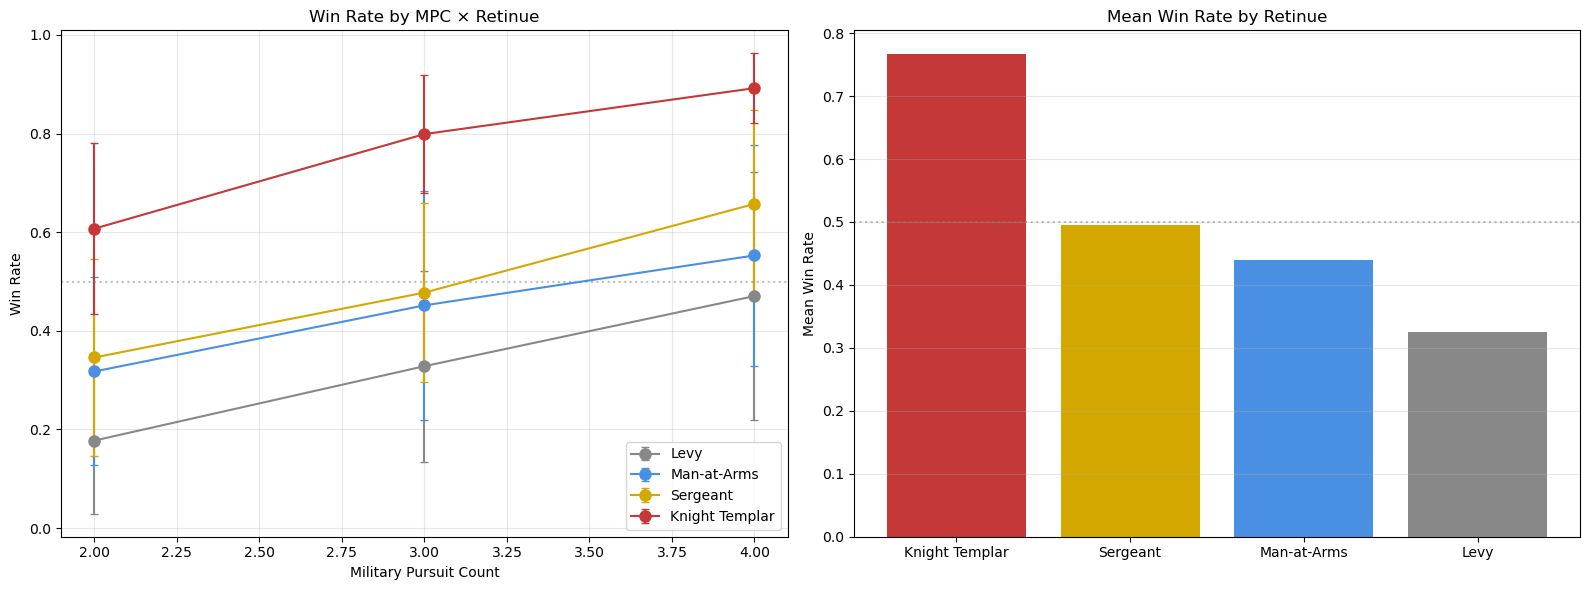

In [38]:
# Win rate by retinue, faceted by MPC
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
for ret, color in zip(["Levy","Man-at-Arms","Sergeant","Knight Templar"],
                       ["#888","#4a90e2","#d4a800","#c43838"]):
    sub = df_main_summary[df_main_summary["retinue"] == ret]
    binned = sub.groupby("military_pursuit_count")["win_rate"].agg(["mean","std","count"])
    binned = binned[binned["count"] >= 3]
    if len(binned) > 0:
        ax.errorbar(binned.index, binned["mean"], yerr=binned["std"],
                    fmt="o-", color=color, label=ret, capsize=3, markersize=8)
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
ax.set_xlabel("Military Pursuit Count")
ax.set_ylabel("Win Rate")
ax.set_title("Win Rate by MPC × Retinue")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ret_means = ret_summary["win_rate"].sort_values(ascending=False)
colors = {"Levy":"#888","Man-at-Arms":"#4a90e2","Sergeant":"#d4a800","Knight Templar":"#c43838"}
ax.bar(ret_means.index, ret_means.values, color=[colors[r] for r in ret_means.index])
ax.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
ax.set_ylabel("Mean Win Rate")
ax.set_title("Mean Win Rate by Retinue")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "winrate_by_mpc"), dpi=110, bbox_inches="tight"); plt.show()

In [39]:
import pandas as pd

gi = df_main_summary.copy()

# total_investment = raw pursuit count (no Efficient-X discount). Robust to however
# 'pursuits' is stored (pipe-string, comma-string, or an actual list/set).
def ti_count(p):
    if isinstance(p, (list, set, frozenset)):
        return len(p)
    if isinstance(p, str) and p.strip():
        for sep in ("|", ","):
            if sep in p:
                return len([x for x in p.split(sep) if x.strip()])
        return 1
    return 0

gi["total_investment"] = gi["pursuits"].map(ti_count)

# sanity: confirm it parsed (should NOT be all zeros/ones)
print("total_investment distribution:")
print(gi["total_investment"].value_counts().sort_index().to_string())
print(f"\nMPC vs total_investment gap: mean {(gi['total_investment']-gi['military_pursuit_count']).mean():.2f}, "
      f"max {(gi['total_investment']-gi['military_pursuit_count']).max()}")

# ── Banded retinue ordering by total_investment (the phase-curve scorecard) ──
# Adjust band edges once you see the distribution above.
bands = [0, 5, 8, 11, 99]
gi["ti_band"] = pd.cut(gi["total_investment"], bands)

tbl = (gi[gi["retinue"] != "Levy"]                       # drop Levy, it's the floor
         .groupby(["ti_band", "retinue"], observed=True)["win_rate"]
         .agg(["mean", "count"]).round(3))
print("\n── retinue win rate by total_investment band ──")
print(tbl.to_string())

# ── Ordering check against your phase-curve targets ──
targets = {
    "early": ["Man-at-Arms", "Sergeant", "Knight Templar"],   # MaA > Sgt > KT
    "mid":   ["Sergeant", "Man-at-Arms", "Knight Templar"],   # Sgt > MaA > KT
    "late":  ["Knight Templar", "Sergeant", "Man-at-Arms"],   # KT > Sgt > MaA
}
print("\n── ordering per band (actual, best→worst) ──")
for band in gi["ti_band"].cat.categories:
    sub = gi[(gi["ti_band"] == band) & (gi["retinue"] != "Levy")]
    if sub.empty:
        print(f"  {band}: (empty)")
        continue
    order = (sub.groupby("retinue")["win_rate"].mean()
                .sort_values(ascending=False).index.tolist())
    counts = sub.groupby("retinue")["win_rate"].count().to_dict()
    print(f"  {band}: " + " > ".join(f"{r}({counts.get(r,0)})" for r in order))

total_investment distribution:
total_investment
4      2
5      2
6      7
7     16
8     34
9     28
10    53
11    32
12    35
13    33
14    53
15    24
16    28
17    34
18    29
19    22
20    12
21     4
22     1
23     1

MPC vs total_investment gap: mean 10.03, max 19

── retinue win rate by total_investment band ──
                          mean  count
ti_band  retinue                     
(5, 8]   Knight Templar  0.434     10
         Man-at-Arms     0.227     17
         Sergeant        0.199     13
(8, 11]  Knight Templar  0.652     24
         Man-at-Arms     0.327     35
         Sergeant        0.398     28
(11, 99] Knight Templar  0.845     77
         Man-at-Arms     0.565     60
         Sergeant        0.588     71

── ordering per band (actual, best→worst) ──
  (0, 5]: (empty)
  (5, 8]: Knight Templar(10) > Man-at-Arms(17) > Sergeant(13)
  (8, 11]: Knight Templar(24) > Sergeant(28) > Man-at-Arms(35)
  (11, 99]: Knight Templar(77) > Sergeant(71) > Man-at-Arms(60)


In [ ]:
import pandas as pd, numpy as np
import renown_data as rd
df = df_main_summary
wr = "win_rate"; CUT = 0.85

# ---- setup (self-contained: define MON, mons, config, wtier here) ----
# Every monument Holding in the sim, labelled with the build-name codes (loadouts._MON_ABBR: RoPa, MiMiSt, Pr, ...;
# others: first two letters of each word).
import loadouts as _L
def _mon_code(h):
    return _L._MON_ABBR.get(h) or "".join(w[:2] for w in h.replace("'", "").split() if w.lower() not in ("of", "the"))
MON = {h: _mon_code(h) for h, d in _L._SIM.items() if d.get("monument")}
DW_WEAPONS = {w for w,d in rd.WEAPONS.items() if "Dual Wield" in d.get("tags",[])}
def is_2h(w):
    t = rd.WEAPONS.get(w,{}).get("tags",[]); return "2H" in t or "Dual Wield" in t
def _tags(r):
    t=r.get("tags",""); return {x.strip() for x in str(t).replace("|",",").split(",")} if isinstance(t,str) and t else set()
def _empty(v): return v in (None,"","nan") or (isinstance(v,float) and pd.isna(v))

def _config(r):
    w,rg,sh,tags = r.get("weapon"),r.get("ranged"),r.get("shield"),_tags(r)
    ty = bool(r.get("tiltyard")) or "Immune Unwieldy" in tags
    if not _empty(rg) and not _empty(w) and w!="Farm Tools": return "Ranged+Melee"
    if not _empty(rg) and (_empty(w) or w=="Farm Tools"):    return "Ranged"
    if "Dual Wield" in tags or (ty and _empty(sh) and _empty(rg) and w and w not in DW_WEAPONS and not is_2h(w)): return "DW"
    if w in DW_WEAPONS: return "DW"
    if is_2h(w): return "2H"
    if not _empty(sh): return "1H+Shield"
    return "Other"

def _mons(r):
    p = set(str(r.get("pursuits","")).split("|"))
    return [s for f,s in MON.items() if f in p]

if "config" not in df.columns: df["config"] = df.apply(_config, axis=1)
if "wtier"  not in df.columns: df["wtier"]  = df["weapon"].map(lambda w: rd.WEAPONS.get(w,{}).get("tier","-"))
df["mons"] = df.apply(_mons, axis=1)   # always rebuilt: an older run of this cell may have left a stale column
# ---- end setup ----

# ── What wins: distribution of the >85% win-rate elite vs the field ──
import pandas as pd, numpy as np
import renown_data as rd
df = df_main_summary
wr = "win_rate"
CUT = 0.85
elite = df[df[wr] > CUT].copy()
print(f"Elite (>{CUT:.0%}): {len(elite)} / {len(df)}  ({len(elite)/len(df):.1%} of pool)\n")

def dist(col, src=elite, base=df):
    """Share within elite, and lift = elite share / pool share (>1 = over-represented)."""
    e = src[col].value_counts(normalize=True)
    p = base[col].value_counts(normalize=True)
    out = pd.DataFrame({"elite_%": (e*100).round(1),
                        "pool_%":  (p.reindex(e.index)*100).round(1)})
    out["lift"] = (e / p.reindex(e.index)).round(2)
    return out.sort_values("elite_%", ascending=False)

for col in ["retinue", "weapon", "armor", "shield", "config", "wtier"]:
    if col in elite.columns:
        print(f"── {col} ──"); print(dist(col).to_string(), "\n")

# Monuments: each build can carry several, so count membership not value_counts.
print("── monuments ──")
rows=[]
for full,short in MON.items():
    e_has = elite["mons"].apply(lambda m: short in m)
    p_has = df["mons"].apply(lambda m: short in m)
    es, ps = e_has.mean(), p_has.mean()
    if not ps: continue
    rows.append((short, round(es*100,1), round(ps*100,1), round(es/ps,2) if ps else np.nan))
mon = pd.DataFrame(rows, columns=["monument","elite_%","pool_%","lift"]).sort_values("elite_%",ascending=False)
print(mon.to_string(index=False), "\n")

# MPC profile of the elite
print("── MPC ──")
print(elite["military_pursuit_count"].describe()[["min","25%","50%","75%","max"]].round(1).to_string())
print(f"\nelite mean MPC {elite['military_pursuit_count'].mean():.1f}  vs pool {df['military_pursuit_count'].mean():.1f}")

# Tag fingerprint — which extra_tags define the elite (lift)
print("\n── tags (lift in elite) ──")
def tagset(r): return {x.strip() for x in str(r.get('tags','')).replace('|',',').split(',') if x.strip()}
all_tags = sorted({t for _,r in df.iterrows() for t in tagset(r)})
trow=[]
for t in all_tags:
    es = df.index.isin(elite.index)
    has = df.apply(lambda r: t in tagset(r), axis=1)
    e = has[df[wr]>CUT].mean(); p = has.mean()
    if p>0 and (has & (df[wr]>CUT)).sum()>=5:
        trow.append((t, round(e*100,1), round(p*100,1), round(e/p,2)))
tg = pd.DataFrame(trow, columns=["tag","elite_%","pool_%","lift"]).sort_values("lift",ascending=False)
print(tg.head(15).to_string(index=False))

# 

In [41]:
def tagset(r):
    return {x.strip() for x in str(r.get('tags','')).replace('|',',').split(',') if x.strip()}

df["has_deflect"] = df.apply(lambda r: "Deflect" in tagset(r), axis=1)
df["has_riposte"] = df.apply(lambda r: "Riposte" in tagset(r), axis=1)

# Deflect's win_rate effect, overall
print("Deflect overall:")
print(df.groupby("has_deflect")["win_rate"].agg(["mean","count"]).round(3))

# Deflect's effect among builds that ALSO face the elite — proxy: high-MPC builds
# (can't condition on opponent here; this df has no matchup breakdown)
print("\nDeflect within elite cut:")
e = df[df.win_rate > 0.85]
print(e.groupby("has_deflect")["win_rate"].agg(["mean","count"]).round(3))

Deflect overall:
              mean  count
has_deflect              
False        0.505    450

Deflect within elite cut:
              mean  count
has_deflect              
False        0.915     58


In [ ]:
# ══ COMBAT BALANCE ANALYSIS ════════════════════════════════════════════════════
# Reads df_main_matchups + df_main_summary. Measures: decisive WR (draws excluded),
# elite-conditioned WR (vs top quartile only), cost-aware attribute lift, and
# matched-pair isolation (the only confound-free single-attribute test).
import numpy as np
import pandas as pd

GEAR_AXES = ['retinue', 'weapon', 'shield', 'armor', 'ranged']

# ── build attribute frame from the summary ──
# Initialize builds dataframe from df_main_summary
name_col = 'name' if 'name' in df_main_summary.columns else 'a_name'
builds = df_main_summary.copy().set_index(name_col)

# derived boolean flags to test (from the string tags/mons columns)
# `mons` (cell 58) holds each build's monument codes; test exact membership.
_has_mon = lambda code: builds['mons'].apply(lambda m: isinstance(m, list) and code in m)
builds['Ministry'] = _has_mon('MiMiSt')
builds['Preceptory'] = _has_mon('Pr')
builds['RoPa'] = _has_mon('RoPa')
builds['ABF_mon'] = _has_mon('ABF')
builds['Outrider'] = _has_mon('OuInPo')
builds['Heater Shield'] = builds['shield'] == 'Heater Shield'
builds['Deflect'] = (
    builds['tags'].astype(str).fillna('').str.contains('Deflect')
)
builds['Riposte'] = (
    builds['tags'].astype(str).fillna('').str.contains('Riposte')
)

# ── symmetrize matchups (filter to one mode to avoid mixing regimes) ──
m = df_main_matchups
if 'mode' in m.columns:
  m = m[m['mode'] == SUMMARY_SOURCE]
m = m.rename(columns={'a_name': 'a', 'b_name': 'b'})
a_side = m.rename(
    columns={'a': 'self', 'b': 'opp', 'a_wins': 'win', 'b_wins': 'loss'}
)
b_side = m.rename(
    columns={'b': 'self', 'a': 'opp', 'b_wins': 'win', 'a_wins': 'loss'}
)
cols = ['self', 'opp', 'win', 'loss', 'mut_wipe', 'indecisive', 'n_runs']
long = pd.concat([a_side[cols], b_side[cols]], ignore_index=True)
long = long[long['self'] != long['opp']]


def agg(df):
  g = (
      df.groupby('self')
      .agg(
          win=('win', 'sum'),
          loss=('loss', 'sum'),
          mw=('mut_wipe', 'sum'),
          ind=('indecisive', 'sum'),
          n=('n_runs', 'sum'),
      )
      .copy()
  )
  dec = (g['win'] + g['loss']).clip(lower=1)
  g['decisive_wr'] = g['win'] / dec
  g['raw_wr'] = g['win'] / g['n']
  g['mw_rate'] = g['mw'] / g['n']
  g['ind_rate'] = g['ind'] / g['n']
  return g


overall = agg(long).join(builds, how='left')
elite_cut = overall['decisive_wr'].quantile(0.75)
elite = set(overall.index[overall['decisive_wr'] >= elite_cut])
vs_elite = agg(long[long['opp'].isin(elite)]).add_suffix('_vE')
B = overall.join(vs_elite[['decisive_wr_vE', 'n_vE']])
B['drop_vs_elite'] = B['decisive_wr'] - B['decisive_wr_vE']

print(
    f'builds: {len(B)} | elite cut (decisive_wr ≥ {elite_cut:.3f}):'
    f' {len(elite)} builds'
)
print(
    'POOL degeneracy — mut_wipe'
    f" {long['mut_wipe'].sum()/long['n_runs'].sum():.1%} | indecisive"
    f" {long['indecisive'].sum()/long['n_runs'].sum():.1%}  (high = combat"
    ' system too symmetric, not a per-spec issue)'
)


# ── attribute lift: elite-conditioned, cost-aware ──
def attr_table(col, min_n=8):
  if col not in B.columns:
    return pd.DataFrame()
  d = B.dropna(subset=['decisive_wr_vE', col]).copy()
  base = d['decisive_wr_vE'].mean()
  rows = []
  for val, grp in d.groupby(col):
    if len(grp) < min_n:
      continue
    rows.append({
        col: val,
        'n': len(grp),
        'wr_vE': round(grp['decisive_wr_vE'].mean(), 3),
        'lift_vE': round(grp['decisive_wr_vE'].mean() / base, 2),
        'mean_mpc': round(
            grp['mpc'].mean(), 1
        ) if 'mpc' in grp.columns else np.nan,
    })
  if not rows:
    return pd.DataFrame()
  return (
      pd.DataFrame(rows)
      .sort_values('lift_vE', ascending=False)
      .reset_index(drop=True)
  )


# ── matched-pair isolation: same chassis+mpc, differs only on `flag` ──
def matched_pairs(flag):
  d = B.dropna(subset=['decisive_wr_vE']).copy()
  if flag not in d.columns:
    return f'{flag}: column missing'
  d['_flag'] = d[flag].astype(bool)
  deltas = []
  group_cols = [c for c in GEAR_AXES + ['mpc'] if c in d.columns]
  for _, grp in d.groupby(group_cols, dropna=False):
    on, off = grp[grp['_flag']], grp[~grp['_flag']]
    if len(on) and len(off):
      deltas.append(on['decisive_wr_vE'].mean() - off['decisive_wr_vE'].mean())
  if not deltas:
    return (
        f'{flag}: no matched pairs (co-varies with chassis — use'
        ' balanced_validation_pool to isolate)'
    )
  s = pd.Series(deltas)
  return (
      f'{flag:16s} {len(s):4d} matched chassis | mean ΔWR_vE {s.mean():+.3f} |'
      f' median {s.median():+.3f} | pairs-won {(s>0).mean():.0%}'
  )


# ── OUTPUT ──
print('\n— retinue (elite-conditioned, cost-aware) —')
display(attr_table('retinue'))
print('— config —')
display(attr_table('config'))
print('— wtier —')
display(attr_table('wtier'))
print('— weapon —')
display(attr_table('weapon'))
print('— shield —')
display(attr_table('shield'))

print('\n— MATCHED-PAIR ISOLATION (confound-free; this is the real test) —')
for f in ['Ministry', 'Preceptory', 'RoPa', 'Heater Shield', 'Deflect', 'Riposte']:
  print(' ', matched_pairs(f))

print('\n— most inflated reputations (high WR overall, collapses vs elite) —')
cols_to_show = [
    c
    for c in ['decisive_wr', 'decisive_wr_vE', 'drop_vs_elite', 'mpc', 'mons']
    if c in B.columns
]
display(B.sort_values('drop_vs_elite', ascending=False)[cols_to_show].head(10).round(3))

In [43]:
# ── Is Royal Pavilion dominant on its own, or just because it's expensive? ──
import pandas as pd, numpy as np
wr = "win_rate"; CUT = 0.85
try:
    band = df[df["military_pursuit_count"].between(10, 20)].copy()
    band["has_RoPa"] = band["mons"].apply(lambda m: "RoPa" in m)
    band["elite"] = band[wr] > CUT
    print(f"MPC 12-14 band: {len(band)} builds "
          f"({band['has_RoPa'].mean():.0%} carry RoPa)\n")
    
    # Win rate: RoPa vs non-RoPa, holding budget fixed
    g = band.groupby("has_RoPa")[wr].agg(["mean","median","count"]).round(3)
    print("Win rate within MPC 12-14:")
    print(g.rename(index={False:"no RoPa", True:"RoPa"}).to_string())
    print(f"\nRoPa edge (same budget): "
          f"{g.loc[True,'mean']-g.loc[False,'mean']:+.3f}\n")
    
    # Elite composition within the band: does RoPa still over-concentrate?
    e = band[band["elite"]]
    es = e["has_RoPa"].mean(); ps = band["has_RoPa"].mean()
    print(f"Within MPC 12-14:")
    print(f"  RoPa share of band   : {ps:.0%}")
    print(f"  RoPa share of elite  : {es:.0%}")
    print(f"  lift (elite/band)    : {es/ps:.2f}")
    print("\n→ lift ≈ 1: RoPa edge was just budget. lift ≫ 1: RoPa itself is the lever.")
    
    # Cross-check: best non-RoPa build at this budget — what's the ceiling without it?
    nb = band[~band["has_RoPa"]]
    if len(nb):
        b = nb.loc[nb[wr].idxmax()]
        print(f"\nBest non-RoPa @ MPC12-14: {b[wr]:.3f}  {b['name']}")
except:
    print("Not enough data")

MPC 12-14 band: 0 builds (nan% carry RoPa)

Win rate within MPC 12-14:
Empty DataFrame
Columns: [mean, median, count]
Index: []
Not enough data


In [44]:
# ── Weapon × Weapon matrix (melee ladder) from df_main_matchups ──
import numpy as np
import pandas as pd

FOCUS = [
    "Cavalry Spear",
    "Bastard Sword",
    "2HBastard",
    "Lance",
    "Morningstar",
    "War Hammer",
    "Poleaxe",
    "Estoc",
]

m = df_main_matchups
sub = m[m["a_weapon"].isin(FOCUS) & m["b_weapon"].isin(FOCUS)][[
    "a_weapon",
    "b_weapon",
    "a_win_rate",
    "n_runs",
    "a_wins",
    "b_wins",
    "a_wipe_combat",
    "a_wipe_shake",
    "a_wipe_waver",
    "a_wipe_rout",
]].copy()

# symmetrize: each A-vs-B pair also gives B-vs-A (flip the win rate)
ab = sub.rename(columns={"a_weapon": "row", "b_weapon": "col", "a_win_rate": "wr"})
ab = ab[["row", "col", "wr", "n_runs"]]
ba = sub.copy()
ba["wr"] = 1 - ba["a_win_rate"]
ba = ba.rename(columns={"b_weapon": "row", "a_weapon": "col"})[
    ["row", "col", "wr", "n_runs"]
]
allp = pd.concat([ab, ba], ignore_index=True)


# n_runs-weighted mean function
def calc_weighted_mean(df):
  w = df["n_runs"].clip(lower=1)
  return np.average(df["wr"], weights=w)


# Calculate weighted averages safely across all pandas versions
mat = (
    allp.groupby(["row", "col"])
    .apply(calc_weighted_mean)
    .unstack()
    .reindex(index=FOCUS, columns=FOCUS)
    .round(3)
)

cnt = (
    allp.groupby(["row", "col"])["n_runs"]
    .sum()
    .unstack()
    .reindex(index=FOCUS, columns=FOCUS)
    .fillna(0)
    .astype(int)
)

print("Win rate of ROW weapon vs COL weapon (n_runs-weighted):")
print(mat.to_string())
print("\ntotal runs per cell (trust cells with high n):")
print(cnt.to_string())

# overall ladder rank: each weapon's mean WR across the focus set
print("\nMean WR vs the focus ladder (this IS the power ranking):")
ladder = mat.mean(axis=1).sort_values(ascending=False).round(3)
print(ladder.to_string())

# tier reference for reading the ranking
TIER = {
    "Cavalry Spear": "Wrought",
    "Bastard Sword": "Forged",
    "2HBastard": "Forged",
    "Lance": "Forged",
    "Morningstar": "Forged",
    "War Hammer": "Forged",
    "Poleaxe": "Crafted",
    "Estoc": "Crafted",
}
print("\nladder with tiers:")
for w, v in ladder.items():
  print(f"  {v:.3f}  {w:<14} ({TIER[w]})")

m = df_main_matchups
bast = m[m["a_weapon"] == "2HBastard"].copy()

# Cast `a_tags` to str first to prevent Categorical fillna error
INIT_TECH = ["Drilled", "Seize", "+1I", "MaxInit3", "Nimble", "Immune Strain"]
bast["has_init_tech"] = (
    bast["a_tags"]
    .astype(str)
    .fillna("")
    .apply(lambda t: any(k in t for k in INIT_TECH))
)

print("\n2HBastard win rate by whether it carries init tech (offsets Unwieldy):")
print(
    bast.groupby("has_init_tech")
    .apply(
        lambda g: np.average(g["a_win_rate"], weights=g["n_runs"].clip(lower=1))
    )
    .round(3)
    .to_string()
)
print("\nn_runs each:")
print(bast.groupby("has_init_tech")["n_runs"].sum().to_string())


def has_serr(tagstr):
  t = str(tagstr)
  return ("Serrated" in t) or ("Rend" in t)


# ── Weapon × Weapon matrix, CONTROLLED for Serrated ──
m = df_main_matchups
sub = m[
    m["a_weapon"].isin(FOCUS)
    & m["b_weapon"].isin(FOCUS)
    & m["a_tags"].apply(has_serr)
    & m["b_tags"].apply(has_serr)
][["a_weapon", "b_weapon", "a_win_rate", "n_runs"]].copy()

# symmetrize: each A-vs-B pair also gives B-vs-A
ab = sub.rename(
    columns={"a_weapon": "row", "b_weapon": "col", "a_win_rate": "wr"}
)[["row", "col", "wr", "n_runs"]]
ba = sub.copy()
ba["wr"] = 1 - ba["a_win_rate"]
ba = ba.rename(columns={"b_weapon": "row", "a_weapon": "col"})[
    ["row", "col", "wr", "n_runs"]
]
allp = pd.concat([ab, ba], ignore_index=True)

mat = (
    allp.groupby(["row", "col"])
    .apply(calc_weighted_mean)
    .unstack()
    .reindex(index=FOCUS, columns=FOCUS)
    .round(3)
)

cnt = (
    allp.groupby(["row", "col"])["n_runs"]
    .sum()
    .unstack()
    .reindex(index=FOCUS, columns=FOCUS)
    .fillna(0)
    .astype(int)
)

print("\nSERRATED-ONLY: win rate of ROW vs COL (both sides Serrated):")
print(mat.to_string())
print("\nruns per cell:")
print(cnt.to_string())
print("\nMean WR vs focus ladder (Serrated-controlled ranking):")
print(mat.mean(axis=1).sort_values(ascending=False).round(3).to_string())

px = df_main_matchups[df_main_matchups["a_weapon"] == "Poleaxe"]["a_tags"].iloc[0]
print("\nA Poleaxe build's tags:", px)

Win rate of ROW weapon vs COL weapon (n_runs-weighted):
col            Cavalry Spear  Bastard Sword  2HBastard  Lance  Morningstar  War Hammer  Poleaxe  Estoc
row                                                                                                   
Cavalry Spear          0.500          0.244      0.506    NaN        0.328       0.494    0.277  0.220
Bastard Sword          0.756          0.500      0.789    NaN        0.726       0.797    0.572  0.552
2HBastard              0.494          0.211      0.500    NaN        0.430       0.654    0.437  0.361
Lance                    NaN            NaN        NaN    NaN          NaN         NaN      NaN    NaN
Morningstar            0.672          0.274      0.570    NaN        0.500       0.686    0.556  0.521
War Hammer             0.506          0.203      0.346    NaN        0.314       0.500    0.308  0.323
Poleaxe                0.723          0.428      0.563    NaN        0.444       0.692      NaN    NaN
Estoc            

In [45]:
# does any non-ABF Full Plate build have Planishing/GF?
fp = df_main_matchups[(df_main_matchups["a_armor"]=="Full Plate")]
fp_no_abf = fp[~fp["a_tags"].str.contains("ABF", na=False)]
print("Full Plate builds:", len(fp))
print("Full Plate non-ABF:", len(fp_no_abf))
print("Full Plate non-ABF with Planishing:",
      fp_no_abf["a_tags"].str.contains("Planishing|GF Armor", na=False).sum())
# and: do ANY builds have Planishing at all?
print("any build with Planishing:",
      df_main_matchups["a_tags"].str.contains("Planishing", na=False).any())

Full Plate builds: 27434
Full Plate non-ABF: 27434
Full Plate non-ABF with Planishing: 0
any build with Planishing: True


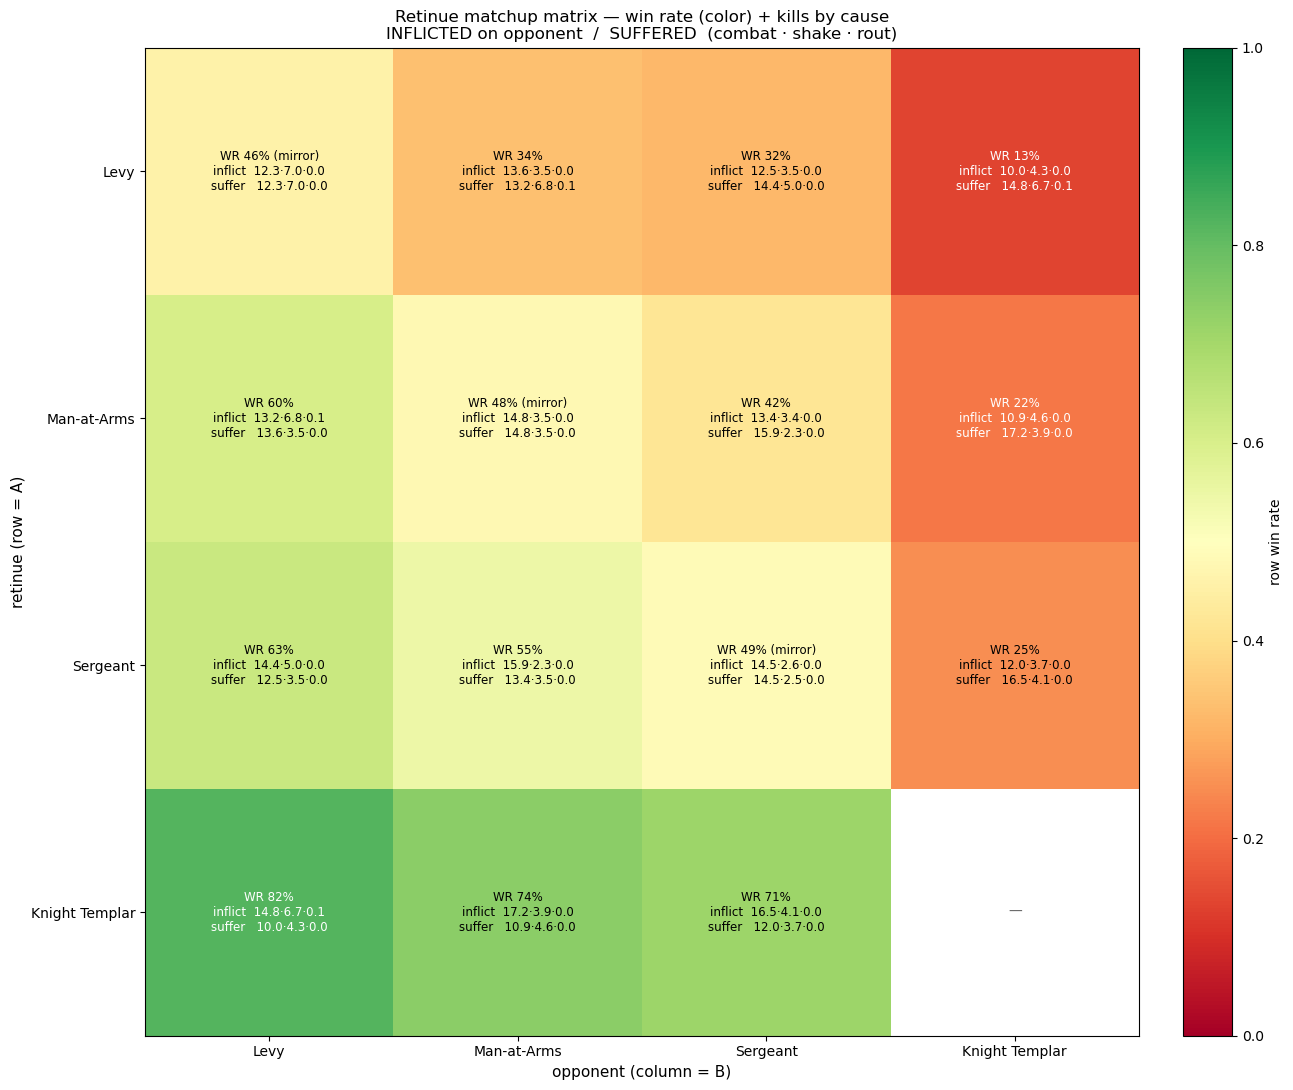

,a_retinue,b_retinue,win%,infl_combat,infl_shake,infl_rout,suff_combat,suff_shake,suff_rout,n
0,Knight Templar,Levy,82.0,14.820000,6.75,0.11,9.960000,4.32,0.00,12104
1,Knight Templar,Man-at-Arms,74.0,17.200001,3.89,0.01,10.890000,4.65,0.00,11587
2,Knight Templar,Sergeant,71.0,16.459999,4.11,0.01,12.000000,3.74,0.00,11217
3,Levy,Knight Templar,13.0,9.960000,4.32,0.00,14.820000,6.74,0.11,12104
4,Levy,Man-at-Arms,34.0,13.600000,3.54,0.00,13.240000,6.77,0.06,11628
5,Levy,Sergeant,32.0,12.550000,3.51,0.00,14.370000,4.98,0.02,11882
6,Man-at-Arms,Knight Templar,22.0,10.890000,4.64,0.00,17.190001,3.89,0.01,11587
7,Man-at-Arms,Levy,60.0,13.240000,6.77,0.06,13.610000,3.53,0.00,11628
8,Man-at-Arms,Sergeant,42.0,13.410000,3.45,0.00,15.900000,2.28,0.00,11580
9,Sergeant,Knight Templar,25.0,12.000000,3.74,0.00,16.459999,4.12,0.01,11217



Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\retinue_matchup.png


In [46]:
# ── 4×4 retinue matrix: win rate + kills by CAUSE (inflicted vs suffered) ──
# Each cell = ROW retinue (as A) vs COLUMN retinue (as B).
#   win_rate  : row's win rate vs column
#   INFLICTED : avg of the COLUMN's soldiers the row kills, split combat / shake / rout
#   SUFFERED  : avg of the ROW's own soldiers lost,        split combat / shake / rout
# Mirror cells (diagonal) shown for reference. Values are mean per-battle casualty COUNTS, not outcomes.
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RETS = ["Levy", "Man-at-Arms", "Sergeant", "Knight Templar"]
df = df_main_matchups   # <-- your loaded tournament

g = (df.groupby(["a_retinue", "b_retinue"])
       .agg(win_rate   =("a_win_rate", "mean"),
            infl_combat=("avg_b_killed_combat", "mean"),
            infl_shake =("avg_b_killed_shake",  "mean"),
            infl_rout  =("avg_b_killed_rout",   "mean"),
            suff_combat=("avg_a_killed_combat", "mean"),
            suff_shake =("avg_a_killed_shake",  "mean"),
            suff_rout  =("avg_a_killed_rout",   "mean"),
            n          =("a_win_rate", "size"))
       .reset_index())
G = g.set_index(["a_retinue", "b_retinue"])

# numeric matrices for the heatmap backdrop (win rate) + net combat performance
win = pd.DataFrame(index=RETS, columns=RETS, dtype=float)
for r in RETS:
    for c in RETS:
        win.loc[r, c] = G.loc[(r, c), "win_rate"] if (r, c) in G.index else np.nan

# ---- visual grid: win-rate heatmap with inflicted/suffered text in each cell ----
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(win.values.astype(float), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(RETS, fontsize=10)
ax.set_yticks(range(4)); ax.set_yticklabels(RETS, fontsize=10)
ax.set_xlabel("opponent (column = B)", fontsize=11)
ax.set_ylabel("retinue (row = A)", fontsize=11)
ax.set_title("Retinue matchup matrix — win rate (color) + kills by cause\n"
             "INFLICTED on opponent  /  SUFFERED  (combat · shake · rout)", fontsize=12)
for i, r in enumerate(RETS):
    for j, c in enumerate(RETS):
        if (r, c) not in G.index:
            ax.text(j, i, "—", ha="center", va="center", color="#666"); continue
        row = G.loc[(r, c)]
        wr = row["win_rate"]
        diag = " (mirror)" if r == c else ""
        txt = (f"WR {wr*100:.0f}%{diag}\n"
               f"inflict  {row['infl_combat']:.1f}·{row['infl_shake']:.1f}·{row['infl_rout']:.1f}\n"
               f"suffer   {row['suff_combat']:.1f}·{row['suff_shake']:.1f}·{row['suff_rout']:.1f}")
        ax.text(j, i, txt, ha="center", va="center", fontsize=8.5,
                color="black" if 0.25 < wr < 0.8 else "white")
fig.colorbar(im, ax=ax, label="row win rate", fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "retinue_matchup_matrix"), dpi=110, bbox_inches="tight"); plt.show()

# ---- the full table (off-diagonal only, for sorting/inspection) ----
tbl = g[g.a_retinue != g.b_retinue].copy()
tbl["win%"] = (tbl.win_rate*100).round(0)
tbl = tbl[["a_retinue","b_retinue","win%",
           "infl_combat","infl_shake","infl_rout",
           "suff_combat","suff_shake","suff_rout","n"]].round(2)
display(tbl.sort_values(["a_retinue","b_retinue"]).reset_index(drop=True))
print(f"\nSaved: {os.path.join(OUT_DIR,'retinue_matchup.png')}")

In [47]:
# ============================================================================
#  SYNERGY SCAN — tangled-correlation detector
#  Finds feature PAIRS (retinue / weapon / shield / armor / ranged / tag /
#  pursuit) whose combined performance beats the additive expectation of each
#  part measured ALONE — i.e. weak or neutral solo, strong together.
#
#  Method:
#    - Per-build win rate -> MPC-adjusted edge (pp vs same-cost builds), so
#      expensive combos aren't flagged just for being expensive.
#    - For each pair (A,B) with enough builds in all three cells:
#        A_alone = mean edge of builds with A but NOT B
#        B_alone = mean edge of builds with B but NOT A
#        combo   = mean edge of builds with BOTH
#        synergy = combo - (A_alone + B_alone)      [additive baseline]
#    - Pairs that essentially never appear apart (P(A|B) or P(B|A) >= 0.95)
#      are STRUCTURAL (e.g. a weapon and the building that unlocks it, or two
#      tags granted by the same mastery) — unidentifiable, listed separately.
#
#  Requires: df_main_matchups (from analysis.load_tournament).
# ============================================================================
import numpy as np, pandas as pd, re

MIN_N        = 8      # min builds required in EACH cell (A alone, B alone, A+B)
WEAK_ALONE   = 4.0    # |edge| pp under which a feature counts as weak/neutral solo
STRONG_COMBO = 8.0    # combo edge pp above which the pair counts as strong
STRUCT_COOC  = 0.95   # P(A|B) or P(B|A) >= this => structural pair, skipped
TOP_K        = 25

# ---- per-build aggregate, MPC-adjusted edge -------------------------------
df = df_main_matchups.copy()
den = (df["a_wins"] + df["b_wins"] + df["mut_wipe"] + df["indecisive"]).replace(0, np.nan)
df["a_wr"] = df["a_wins"] / den
g = df.groupby("a_name").agg(
    wr=("a_wr", "mean"), mpc=("a_military_pursuit_count", "first"),
    retinue=("a_retinue", "first"), weapon=("a_weapon", "first"),
    shield=("a_shield", "first"), armor=("a_armor", "first"),
    ranged=("a_ranged", "first"), tags=("a_tags", "first"),
    pursuits=("a_pursuits", "first"),
).reset_index()
g["edge"] = (g["wr"] - g.groupby("mpc")["wr"].transform("mean")) * 100.0

def _split(s):
    return [t.strip() for t in re.split(r"[|,]", str(s))
            if t.strip() and t.strip().lower() != "nan"]

# ---- boolean feature matrix ------------------------------------------------
feat = {}
for col, pre in [("retinue", "ret"), ("weapon", "wpn"), ("shield", "shd"),
                 ("armor", "arm"), ("ranged", "rng")]:
    for v in pd.unique(g[col].dropna()):
        if v in ("", "None", None):
            continue
        feat[f"{pre}:{v}"] = (g[col] == v).values
for kind, col in [("tag", "tags"), ("pur", "pursuits")]:
    lists = g[col].astype(str).map(_split)
    toks = sorted({t for L in lists for t in L})
    for t in toks:
        feat[f"{kind}:{t}"] = lists.map(lambda L, _t=t: _t in L).values

F = pd.DataFrame(feat, index=g.index)
n_builds = len(g)
F = F[[c for c in F.columns if MIN_N <= F[c].sum() <= n_builds - MIN_N]]  # prune no-variance
edge = g["edge"].values
print(f"builds: {n_builds} | features kept: {F.shape[1]} | "
      f"pairs to scan: ~{F.shape[1]*(F.shape[1]-1)//2}")

# ---- pair scan -------------------------------------------------------------
rows, structural = [], []
cols = list(F.columns)
Fv = {c: F[c].values for c in cols}
for i in range(len(cols)):
    A = Fv[cols[i]]
    for j in range(i + 1, len(cols)):
        B = Fv[cols[j]]
        ab = A & B
        nab = int(ab.sum())
        if nab < MIN_N:
            continue
        if nab / A.sum() >= STRUCT_COOC or nab / B.sum() >= STRUCT_COOC:
            structural.append((cols[i], cols[j], nab))
            continue
        a_only, b_only = A & ~B, B & ~A
        na, nb = int(a_only.sum()), int(b_only.sum())
        if na < MIN_N or nb < MIN_N:
            continue
        ea, eb, eab = edge[a_only].mean(), edge[b_only].mean(), edge[ab].mean()
        syn = eab - (ea + eb)
        se = np.sqrt(edge[ab].var(ddof=1) / nab +
                     edge[a_only].var(ddof=1) / na +
                     edge[b_only].var(ddof=1) / nb)
        rows.append(dict(A=cols[i], B=cols[j],
                         A_alone=ea, nA=na, B_alone=eb, nB=nb,
                         combo=eab, nAB=nab, synergy=syn,
                         z=(syn / se) if se > 0 else np.nan))
S = pd.DataFrame(rows)
if S.empty:
    print("No analyzable pairs (pool too small or MIN_N too high).")
else:
    pd.set_option("display.width", 160)
    fmt = lambda d: d.assign(**{c: d[c].round(1) for c in
          ("A_alone", "B_alone", "combo", "synergy", "z")})

    # ---- 1. TANGLED: weak/neutral alone, strong together --------------------
    tangled = S[(S.A_alone.abs() < WEAK_ALONE) & (S.B_alone.abs() < WEAK_ALONE)
                & (S.combo > STRONG_COMBO)].sort_values("synergy", ascending=False)
    print("\n" + "=" * 100)
    print(f"TANGLED COMBOS — each part within ±{WEAK_ALONE}pp alone, combo edge > "
          f"{STRONG_COMBO}pp  (edge = pp vs same-MPC builds)")
    print("=" * 100)
    print(fmt(tangled.head(TOP_K)).to_string(index=False) if len(tangled)
          else "  (none under current thresholds)")

    # ---- 2. Strongest raw synergies (regardless of solo strength) ----------
    print("\n" + "=" * 100)
    print(f"TOP {TOP_K} SYNERGIES overall (combo beats additive expectation; |z|>1 is worth a look)")
    print("=" * 100)
    print(fmt(S.sort_values("synergy", ascending=False).head(TOP_K)).to_string(index=False))

    # ---- 3. Anti-synergies (combos that underperform their parts) ----------
    print("\n" + "=" * 100)
    print(f"TOP {TOP_K} ANTI-SYNERGIES (combo WORSE than the sum of its parts)")
    print("=" * 100)
    print(fmt(S.sort_values("synergy").head(TOP_K)).to_string(index=False))

    # ---- 4. Structural pairs (near-always together — unidentifiable) -------
    print("\n" + "=" * 100)
    print(f"STRUCTURAL PAIRS skipped (co-occurrence >= {STRUCT_COOC:.0%}): {len(structural)}")
    print("=" * 100)
    for a, b, n in structural[:15]:
        print(f"  {a}  +  {b}   (together in {n} builds)")
    if len(structural) > 15:
        print(f"  ... and {len(structural) - 15} more")

    # ---- 5. helper: best partners for one feature --------------------------
    def partners(feature, k=12):
        """Top synergy partners for a given feature, e.g. partners('wpn:Poleaxe')."""
        sub = S[(S.A == feature) | (S.B == feature)].copy()
        sub["partner"] = np.where(sub.A == feature, sub.B, sub.A)
        sub["partner_alone"] = np.where(sub.A == feature, sub.B_alone, sub.A_alone)
        out = sub.sort_values("synergy", ascending=False)[
            ["partner", "partner_alone", "combo", "nAB", "synergy", "z"]].head(k)
        return out.round(1)
    print("\nHelper available:  partners('wpn:Poleaxe')  /  partners('tag:Riposte')  etc.")

builds: 450 | features kept: 112 | pairs to scan: ~6216

TANGLED COMBOS — each part within ±4.0pp alone, combo edge > 8.0pp  (edge = pp vs same-MPC builds)
                  A                   B  A_alone  nA  B_alone  nB  combo  nAB  synergy   z
        rng:Longbow        tag:Parry +1      2.3  72     -2.3  72   18.3   28     18.3 2.9
          tag:Parry  pur:Gilded Foundry     -0.2 286     -3.7  17   12.2  108     16.1 3.1
     arm:Full Plate      pur:Blacksmith      1.3  60      1.6 132   18.7   10     15.9 3.0
          pur:Forge         pur:Tannery     -0.8  74      3.9 194   18.0   30     14.9 3.3
        pur:Furnace  pur:Gilded Foundry     -3.0 189      1.5  33   13.1   92     14.6 3.4
         pur:Armory         pur:Furnace     -0.2  51     -3.8 161   10.4  120     14.3 3.5
 tag:Immune Blunder tag:Immune Unwieldy     -0.7 121      1.9  54   15.5   62     14.3 3.3
 tag:Immune Blunder       tag:Strike +1     -0.7 121      1.9  54   15.5   62     14.3 3.3
 tag:Immune Blunder pur:F

## 3.1 Retinue cost efficiency

Wins per 1000 gold upkeep — does spending more on better troops pay off?

In [48]:
ret_costs = df_main_summary.groupby("retinue").agg(
    army_upkeep=("army_upkeep", "first"),
    wins_per_1k=("wins_per_1000_upkeep", "mean"),
    win_rate=("win_rate", "mean"),
).round(2)
ret_costs["upkeep_25_men"] = ret_costs["army_upkeep"]
print("=== Retinue cost-efficiency ===")
print(ret_costs.to_string())

=== Retinue cost-efficiency ===
                army_upkeep  wins_per_1k  win_rate  upkeep_25_men
retinue                                                          
Knight Templar         1500     29582.31      0.77           1500
Levy                      0      2809.95      0.33              0
Man-at-Arms               0     19177.29      0.44              0
Sergeant               2500     31096.87      0.50           2500


In [49]:
print("Poleaxe:", df_main_summary["weapon"].value_counts().get("Poleaxe", 0))
print("Pilum:", df_main_summary["ranged"].value_counts().get("Pilum", 0))
print("Crafted builds:", (df_main_summary["wtier"]=="Crafted").sum())

Poleaxe: 8
Pilum: 0
Crafted builds: 11


# 4. Equipment Analysis

Weapons, shields, armor, and 1H/2H/Bastard tradeoffs.

## 4.1 Weapon performance

=== Melee (tier-adjusted) ===
                n     wr    sem  vs_tier    dec    keff     tier  rankable
weapon                                                                    
Bastard Sword   3  0.911  0.035    0.326  0.930  13.127   Forged     False
Estoc           3  0.822  0.045    0.057  0.850   9.053  Crafted     False
Flail           6  0.771  0.094    0.222  0.806   8.790  Wrought      True
Poleaxe         8  0.744  0.090   -0.021  0.761   7.670  Crafted      True
Morningstar     4  0.730  0.139    0.145  0.743   8.482   Forged     False
Cavalry Spear   3  0.668  0.129    0.119  0.716   5.220  Wrought     False
Spears         15  0.655  0.058    0.118  0.686   5.522     Cast      True
2HBastard      40  0.641  0.037    0.056  0.662   4.535   Forged      True
Bill Hook      33  0.538  0.043    0.001  0.567   1.898     Cast      True
Battle Axe     11  0.536  0.104   -0.013  0.554   1.868  Wrought      True
Daggers        35  0.517  0.048   -0.019  0.544   1.234     Cast      

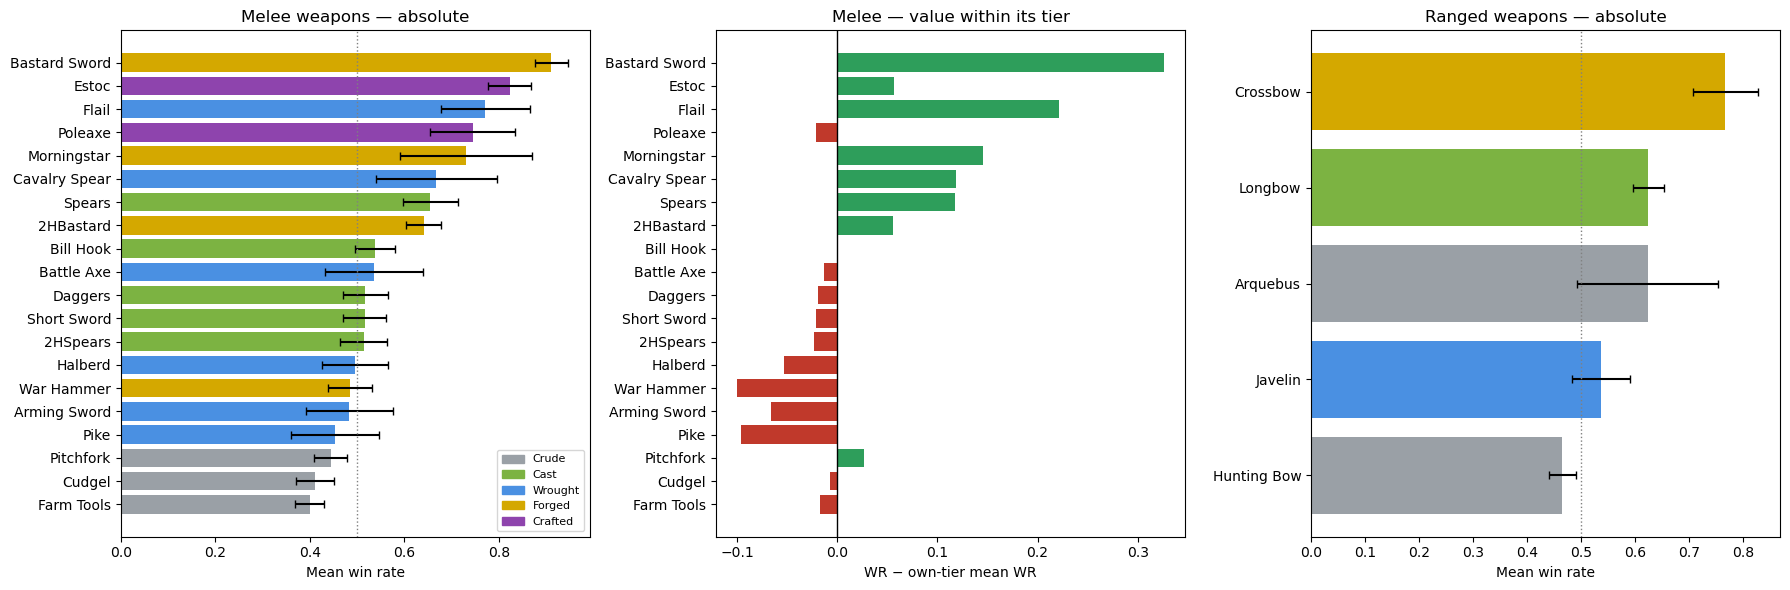

In [50]:
# Fix tier_of to handle Categorical Series safely
def tier_of(series, mapping):
  """Map to tier, sending anything unknown to '-' rather than NaN."""
  return series.map(mapping).astype(object).fillna("-")


# ============ Weapon performance: tier-adjusted ============
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MIN_N = 5  # below this, a bar is noise

# Restore S if it was overwritten by pair-level synergy results
if "A_alone" in S.columns or "weapon" not in S.columns:
  if "df_main_summary" in globals():
    S = df_main_summary.copy()


def _get_col(df, key):
  """Finds key or prefixed variant (e.g., 'weapon' vs 'a_weapon')."""
  candidates = [key, f"a_{key}", key.lower(), f"a_{key.lower()}"]
  for c in candidates:
    if c in df.columns:
      return c
  raise KeyError(
      f"Could not find '{key}' or variant in DataFrame columns: {list(df.columns)}"
  )


def _agg(frame, key, tiermap):
  col = _get_col(frame, key)
  name_col = _get_col(frame, "name")

  d = frame[frame[col].notna() & (frame[col].astype(str) != "")]
  t = tier_of(d[col], tiermap)
  g = (
      d.assign(_tier=t.values)
      .groupby(col, observed=True)
      .agg(
          n=(name_col, "count"),
          wr=("win_rate", "mean"),
          sd=("win_rate", "std"),
          dec=("decisive_win_rate", "mean"),
          tier=("_tier", "first"),
      )
  )
  if "kill_efficiency" in d.columns:
    g["keff"] = d.groupby(col, observed=True)["kill_efficiency"].mean()

  g["sem"] = g["sd"] / np.sqrt(g["n"])
  g["rankable"] = g["n"] >= MIN_N
  tier_mean = (
      d.assign(_tier=t.values)
      .groupby("_tier", observed=True)["win_rate"]
      .mean()
  )
  g["vs_tier"] = g["wr"] - g["tier"].map(tier_mean)
  return g.sort_values("wr", ascending=False)


g = _agg(S, "weapon", WTIER)
gr = _agg(S, "ranged", RTIER)

cols = [
    c
    for c in ["n", "wr", "sem", "vs_tier", "dec", "keff", "tier", "rankable"]
    if c in g.columns
]
print("=== Melee (tier-adjusted) ===")
print(g[cols].round(3).to_string())
print("\n=== Ranged ===")
print(gr[[c for c in cols if c in gr.columns]].round(3).to_string())

thin = list(g.index[~g["rankable"]]) + list(gr.index[~gr["rankable"]])
if thin:
  print(f"\nNOT RANKABLE (n < {MIN_N}): {thin}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))


def safe_color(t):
  return TIER_COLOR.get(t, "#888888") if isinstance(TIER_COLOR, dict) else "#888888"


ax = axes[0]
ax.barh(
    g.index[::-1],
    g["wr"][::-1],
    xerr=g["sem"][::-1],
    color=[safe_color(t) for t in g["tier"]][::-1],
    capsize=3,
)
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("Mean win rate")
ax.set_title("Melee weapons — absolute")

ax = axes[1]
ax.barh(
    g.index[::-1],
    g["vs_tier"][::-1],
    color=["#2e9e5b" if v > 0 else "#c0392b" for v in g["vs_tier"]][::-1],
)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("WR − own-tier mean WR")
ax.set_title("Melee — value within its tier")

ax = axes[2]
ax.barh(
    gr.index[::-1],
    gr["wr"][::-1],
    xerr=gr["sem"][::-1],
    color=[safe_color(t) for t in gr["tier"]][::-1],
    capsize=3,
)
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("Mean win rate")
ax.set_title("Ranged weapons — absolute")

handles = [
    plt.Rectangle((0, 0), 1, 1, color=safe_color(t)) for t in TIER_ORDER
]
axes[0].legend(handles, TIER_ORDER, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

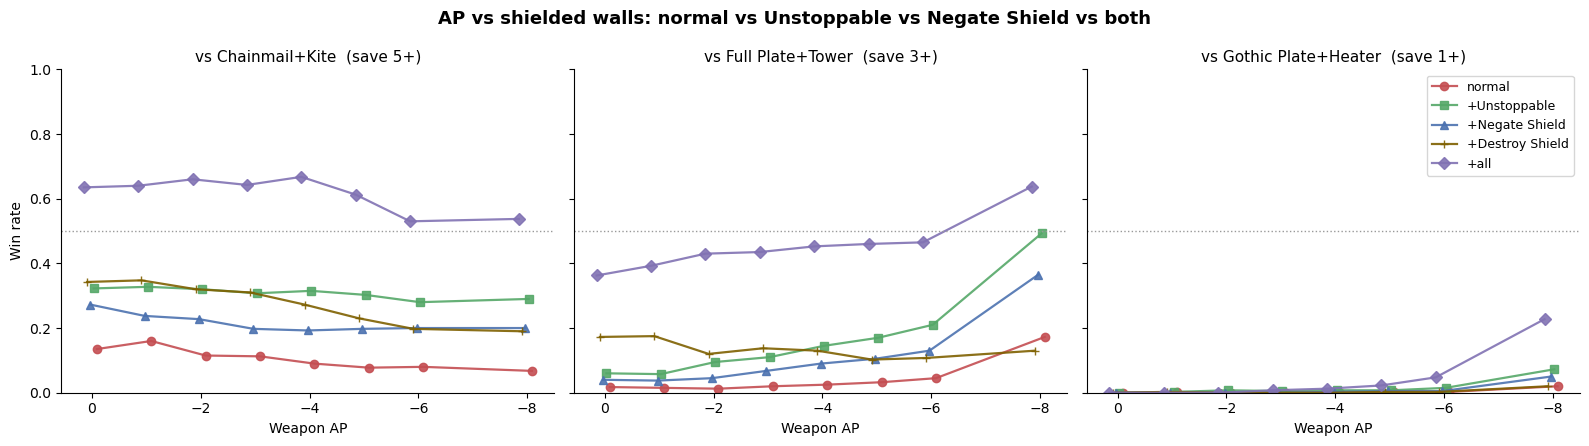

In [51]:
# ──────────────────────────────────────────────────────────────────────────────
# AP vs shielded walls: normal vs Unstoppable vs Negate Shield vs both
#   Unstoppable     = defender may only Parry on a natural 6 (parry restriction)
#   Negate Shield   = ignores the shield's -1-to-Strike ("Shielded") penalty
# Sweep attacker AP; each variant adds ONLY its keyword on top of a shared base.
# ──────────────────────────────────────────────────────────────────────────────
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from contextlib import contextmanager
import renown_data as rd, batch_engine as be, playstyles
from loadouts import Loadout

@contextmanager
def override(d, **kw):                 # snapshot + guaranteed restore (no drift carryover)
    old = {k: d[k] for k in kw}; d.update(kw)
    try: yield
    finally: d.update(old)

def winrate(a, b, n=400, seed=77):
    r = be.run_batch_random([(a, b)], n_runs=n, seed=seed, max_skirmishes=20, mode="random")
    aw = int(np.asarray(r['a_wins'])[0])
    t  = aw + int(np.asarray(r['b_wins'])[0]) + int(np.asarray(r['mut_wipe'])[0]) + int(np.asarray(r['indecisive'])[0])
    return aw / t if t else np.nan

SIZE = 25
def mk(weapon, shield, armor='Chainmail', extra=None, playstyle='Aggressor'):
    return Loadout(name=f"{weapon}/{shield}/{armor}", retinue='Man-at-Arms', weapon=weapon, shield=shield,
                   armor=armor, ranged=None, has_tiltyard=False, size=SIZE,
                   extra_tags=frozenset(extra or ['Cond Field', "Parry"]), upkeep_per_retinue=30, playstyle=playstyle,
                   tiltyard_mastery=False, pursuits=frozenset(['Conditioning Field']),
                   military_pursuit_count=5, domain_count=0)
def eff_save(armor, shield):
    return rd.ARMORS[armor]['save'] - (rd.SHIELDS[shield]['save_bonus'] if shield else 0)

WALLS    = [("Chainmail", "Kite Shield"), ("Full Plate", "Tower Shield"), ("Gothic Plate", "Heater Shield")]
AP_SWEEP = [0, -1, -2, -3, -4, -5, -6, -8]
VARIANTS = {                       # shared base ['Cond Field']; keyword is the ONLY delta
    "normal":          [],
    "+Unstoppable":    ["Unstoppable"],
    "+Negate Shield":  ["Negate Shielded"],
    "+Destroy Shield": ["Destroy Shield"],
    "+all":           ["Unstoppable", "Negate Shielded","Destroy Shield"],
}
STYLE = {"normal": ("o", "#C44E52"), "+Unstoppable": ("s", "#55A868"),
         "+Negate Shield": ("^", "#4C72B0"),"+Destroy Shield": ("+", "#7f6000"), "+all": ("D", "#8172B3")}

# ── sweep ──  (init pinned to 0 so a drifted kernel can't corrupt this run)
results = {(lab, vname): [] for (_, _), lab in [((a, s), f"{a}+{s.split()[0]}") for a, s in WALLS] for vname in VARIANTS}
for ap in AP_SWEEP:
    with override(rd.WEAPONS['Arming Sword'], ap=ap, init=0):
        for arm, sh in WALLS:
            lab = f"{arm}+{sh.split()[0]}"
            defn = mk('Arming Sword', sh, armor=arm)
            for vname, ktags in VARIANTS.items():
                atk = mk('Arming Sword', 'Kite Shield', armor='Chainmail', extra=['Cond Field', *ktags])
                results[(lab, vname)].append(winrate(atk, defn, n=400, seed=77))

# ── plot: one panel per wall, a line per variant ──
fig, axes = plt.subplots(1, len(WALLS), figsize=(16, 4.5), sharey=True)
for ax, (arm, sh) in zip(axes, WALLS):
    lab = f"{arm}+{sh.split()[0]}"
    for vi, vname in enumerate(VARIANTS):
        mk_, col = STYLE[vname]
        xd = [ap + (vi - 1.5) * 0.06 for ap in AP_SWEEP]   # tiny dodge so overlapping lines both show
        ax.plot(xd, results[(lab, vname)], marker=mk_, color=col, label=vname, lw=1.6, ms=6, alpha=0.9)
    ax.set_title(f"vs {lab}  (save {eff_save(arm, sh)}+)", fontsize=11)
    ax.set_xlabel("Weapon AP"); ax.axhline(0.5, color="0.6", ls=":", lw=1)
    ax.set_ylim(0, 1); ax.invert_xaxis(); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Win rate"); axes[-1].legend(fontsize=9, loc="upper right")
fig.suptitle("AP vs shielded walls: normal vs Unstoppable vs Negate Shield vs both", fontsize=13, weight="bold")
plt.tight_layout()
OUT_DIR = globals().get("OUT_DIR", ".")
plt.savefig(os.path.join(OUT_DIR, "ap_keywords_vs_shields.png"), dpi=110, bbox_inches="tight"); plt.show()

  Unstoppable        108880 matchup rows   carriers: ['2HBastard', 'Arquebus', 'Battle Axe', 'Cavalry Spear', 'Crossbow', 'Estoc', 'Flail', 'Hunting Bow', 'Javelin', 'Lance', 'Longbow', 'Pike', 'Pilum', 'Poleaxe', 'War Hammer']
  Negate Shielded     45539 matchup rows   carriers: ['Arquebus', 'Battle Axe', 'Bill Hook', 'Crossbow', 'Halberd', 'Javelin', 'Lance', 'Pilum', 'Poleaxe', 'War Hammer']
  Destroy Shield      21092 matchup rows   carriers: ['Javelin', 'Morningstar', 'Pilum', 'War Hammer']


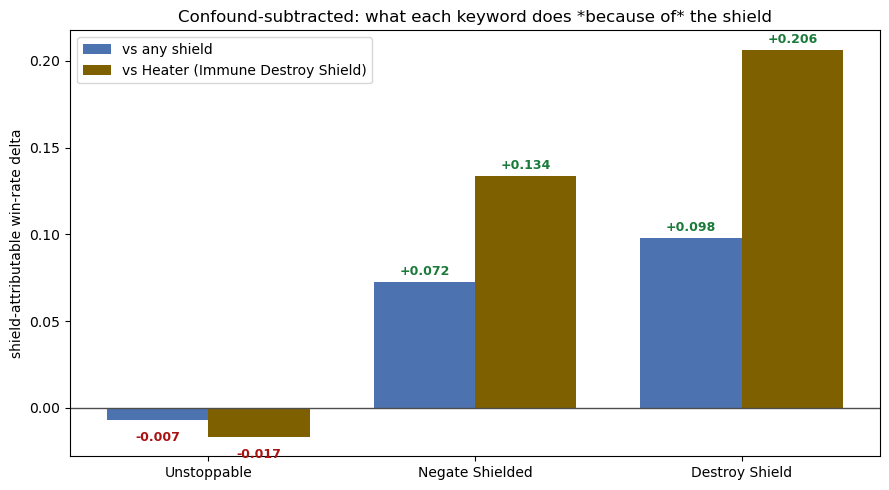

In [52]:
# ============ What each shield-breaking keyword does *because of* the shield ============
# Keyword sets come from the prelude (derived from renown_data tags). The old
# hardcoded sets still listed Pilum, which is no longer in the data, so every
# Pilum row silently fell into the "field" arm and diluted the deltas.
import numpy as np, matplotlib.pyplot as plt

need = ["a_weapon", "a_ranged", "b_shield", "n_runs", "a_win_rate"]
mm = mcols(*need)                      # projection, not a full M.copy()

aw, ar = mm["a_weapon"].astype(str), mm["a_ranged"].astype(str)
has = lambda weps: aw.isin(weps) | ar.isin(weps)
bs = mm["b_shield"].astype(str)
NOSH = ["", "None", "nan", "<NA>"]
SEG = {"no shield":  bs.isin(NOSH),
       "has shield": ~bs.isin(NOSH),
       "heater":     bs.eq("Heater Shield")}
W, WR = mm["n_runs"].to_numpy(), mm["a_win_rate"].to_numpy()

def wmean(mask):
    m = np.asarray(mask); w = W[m]
    return np.average(WR[m], weights=w) if w.sum() else np.nan

def delta(weps, seg):
    m = has(weps)
    return wmean(m & SEG[seg]) - wmean(~m & SEG[seg])

KW = {"Unstoppable": UNSTOPPABLE_W, "Negate Shielded": NEGATE_SHIELD_W,
      "Destroy Shield": DESTROY_SHIELD_W}
for k, v in KW.items():
    n = int(has(v).sum())
    print(f"  {k:16} {n:>8} matchup rows   carriers: {sorted(v)}")

sig_has = [delta(w, "has shield") - delta(w, "no shield") for w in KW.values()]
sig_htr = [delta(w, "heater")     - delta(w, "no shield") for w in KW.values()]

x = np.arange(len(KW)); bw = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - bw/2, sig_has, bw, label="vs any shield", color="#4C72B0")
b2 = ax.bar(x + bw/2, sig_htr, bw, label="vs Heater (Immune Destroy Shield)", color="#7f6000")
for bars in (b1, b2):
    for r in bars:
        h = r.get_height()
        if np.isnan(h):
            continue
        ax.text(r.get_x() + r.get_width()/2, h + (0.004 if h >= 0 else -0.012),
                f"{h:+.3f}", ha="center", fontsize=9, weight="bold",
                color="#1a7a3a" if h > 0 else "#a11")
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(x); ax.set_xticklabels(list(KW))
ax.set_ylabel("shield-attributable win-rate delta")
ax.set_title("Confound-subtracted: what each keyword does *because of* the shield")
ax.legend(); plt.tight_layout(); plt.show()
del mm

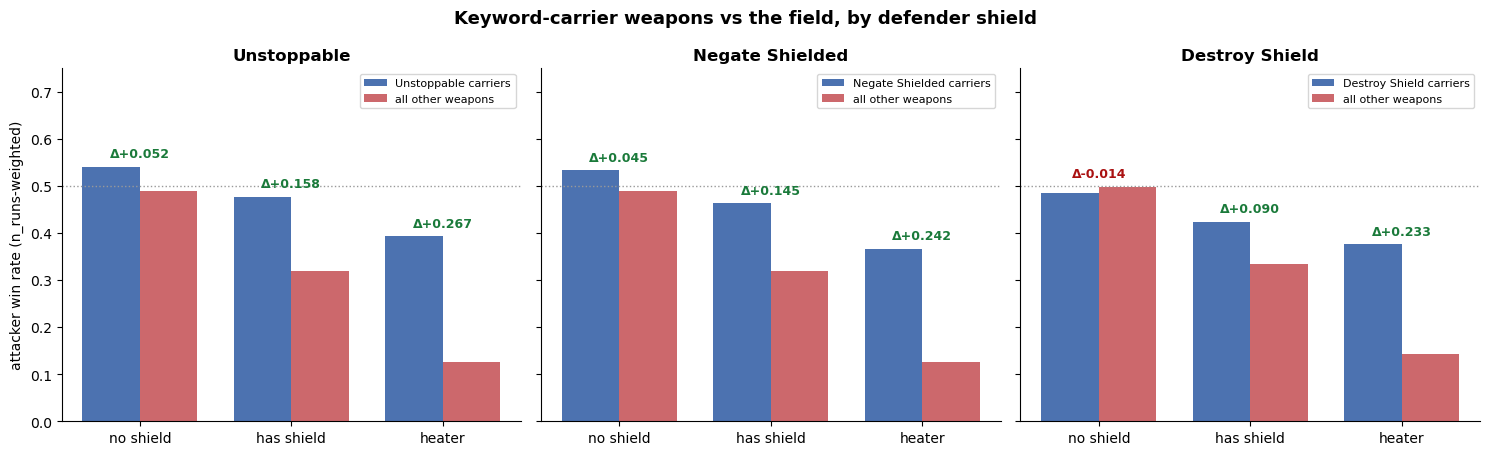

In [53]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = df_main_matchups

UNSTOPPABLE_W    = {'Lance','War Hammer','Poleaxe','Javelin','Crossbow','Pilum'}
NEGATE_SHIELD_W  = {'Battle Axe','Lance','War Hammer','Poleaxe','Javelin','Crossbow','Pilum'}
DESTROY_SHIELD_W = {'Morningstar','War Hammer','Pilum'}

aw, ar = df['a_weapon'].astype(str), df['a_ranged'].astype(str)
has = lambda weps: aw.isin(weps) | ar.isin(weps)
bs = df['b_shield'].astype(str)
SEG = {'no shield': bs.isin(['','None','nan']),
       'has shield': ~bs.isin(['','None','nan']),
       'heater': bs.eq('Heater Shield')}
W   = df['n_runs'].to_numpy(); WR = df['a_win_rate'].to_numpy()
def wmean(mask):
    m = mask.to_numpy(); w = W[m]
    return np.average(WR[m], weights=w) if w.sum() else np.nan

KW = {'Unstoppable': UNSTOPPABLE_W, 'Negate Shielded': NEGATE_SHIELD_W, 'Destroy Shield': DESTROY_SHIELD_W}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
segs = list(SEG); x = np.arange(len(segs)); bw = 0.38

for ax, (kw, weps) in zip(axes, KW.items()):
    m = has(weps)
    carr = [wmean(m & SEG[s])    for s in segs]
    base = [wmean(~m & SEG[s])   for s in segs]
    b1 = ax.bar(x - bw/2, carr, bw, label=f'{kw} carriers', color='#4C72B0')
    b2 = ax.bar(x + bw/2, base, bw, label='all other weapons', color='#C44E52', alpha=.85)
    for i in range(len(segs)):                       # Δ annotation
        d = carr[i] - base[i]
        ax.text(x[i], max(carr[i], base[i]) + .02, f'Δ{d:+.3f}',
                ha='center', fontsize=9, weight='bold',
                color='#1a7a3a' if d > 0 else '#a11')
    ax.axhline(.5, color='.6', ls=':', lw=1)
    ax.set_title(kw, fontsize=12, weight='bold')
    ax.set_xticks(x); ax.set_xticklabels(segs); ax.set_ylim(0, .75)
    ax.spines[['top','right']].set_visible(False); ax.legend(fontsize=8, loc='upper right')
axes[0].set_ylabel('attacker win rate (n_runs-weighted)')
fig.suptitle('Keyword-carrier weapons vs the field, by defender shield', fontsize=13, weight='bold')
plt.tight_layout()
import os; plt.savefig(os.path.join(globals().get('OUT_DIR','.'), 'kw_carriers_by_shield.png'), dpi=120, bbox_inches='tight'); plt.show()

BEST LOADOUT PER MONUMENT

Preceptory: (none)

ABF: (none)

monument       n   best WR   build
RoPa          88     0.987   KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]
Ministry      70     0.978   KT/2HBastard+Crossbow/Cloth (TY) [MiMiSt, (EInd, SProw, SPie, NCun), AP -1, Enduring, Florentine, Immune Awkward, Rec 6, Serr]
Outrider      51     0.828   KT/Spears+HuntBow/Targe/Leather (TY) [OuInPo, (RInd, EProw, SPie, SCun), Enduring, Florentine, Immune Awkward, Rec 6]

BEST LOADOUT PER WEAPON TIER × CONFIG

── 1H+Shield ──
  Crude    0.609  n=4    KT/FarmTools/Targe/Leather [(RInd, EProw, SPie, NCun), Enduring, Nimble, Rec 6]
  Cast     0.853  n=15   Sgt/Spears/Heater/Gothic [CoAr, MiMiSt, (SInd, SProw, NPie, NCun)]
  Wrought  0.907  n=6    KT/Flail/Heater/Gothic [CoAr, (SInd, EProw, SPie, NCun), Enduring, Rec 6]
  Forged   0.956  n=2    KT/Morningstar/Heater/Gothic [CoAr, (SInd, EProw, SPie, NCun), 

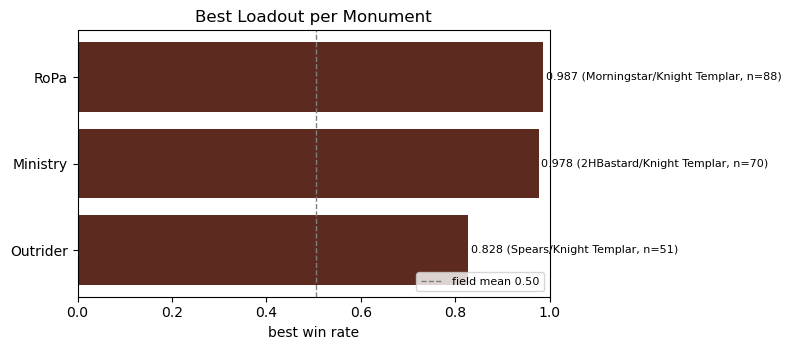

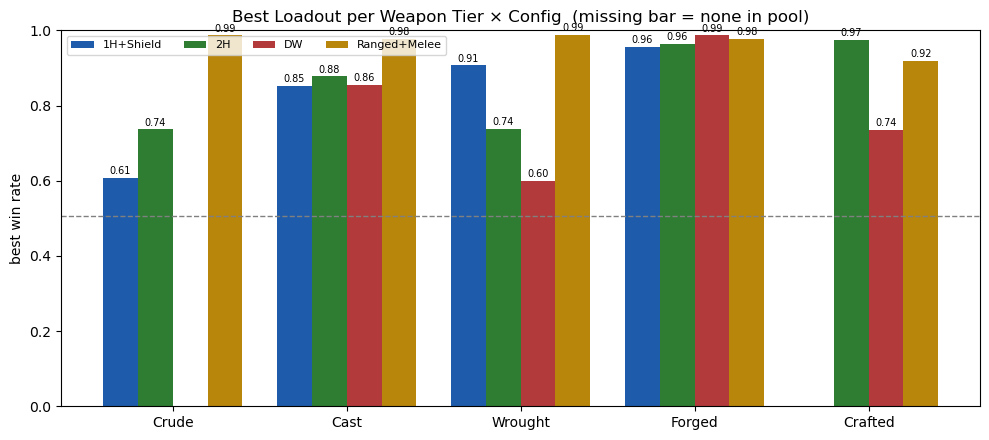


wrote:
  C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\lab_out\best_by_monument.png
  C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\lab_out\best_by_tier_config.png


In [54]:
# ── Best loadouts by monument + by weapon-tier x config ──
# Was `df = df.copy()` — but `df` had been re-pointed at the matchups frame by the
# cell above, so `df["weapon"]` raised KeyError. Now bound to S explicitly, and the
# derived columns are written back onto S once instead of copying the frame.
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
import renown_data as rd

OUT = os.path.join(os.path.dirname(globals().get("OUT_DIR", ".")), "lab_out")
os.makedirs(OUT, exist_ok=True)
wr = "win_rate"
D = S                                  # no copy

# ---- classification helpers ----
DW_WEAPONS = {w for w,d in rd.WEAPONS.items() if "Dual Wield" in d.get("tags",[])}
def is_2h(w):
    t = rd.WEAPONS.get(w,{}).get("tags",[]); return "2H" in t or "Dual Wield" in t
def tags_of(r):
    t=r.get("tags",""); return {x.strip() for x in str(t).replace("|",",").split(",")} if isinstance(t,str) and t else set()
def _empty(v): return v in (None,"","nan") or (isinstance(v,float) and pd.isna(v))

def config(r):
    w, rg, sh, tags = r.get("weapon"), r.get("ranged"), r.get("shield"), tags_of(r)
    ty = bool(r.get("tiltyard")) or "Immune Unwieldy" in tags
    if not _empty(rg) and not _empty(w) and w!="Farm Tools":  return "Ranged+Melee"
    if not _empty(rg) and (_empty(w) or w=="Farm Tools"):     return "Ranged"
    if "Dual Wield" in tags or (ty and _empty(sh) and _empty(rg)
            and w and w not in DW_WEAPONS and not is_2h(w)):  return "DW"
    if w in DW_WEAPONS:                                       return "DW"
    if is_2h(w):                                              return "2H"
    if not _empty(sh):                                        return "1H+Shield"
    return "Other"

D["config"] = D.apply(config, axis=1)
D["wtier"]  = D["weapon"].map(lambda w: rd.WEAPONS.get(w,{}).get("tier","-"))
TIER_ORD = ["Crude","Cast","Wrought","Forged","Crafted"]

MON = {"Royal Pavilion":"RoPa", "Ministry of Military Strategy":"Ministry",
       "Preceptory":"Preceptory", "ABF":"ABF", "Outrider Intercept Post":"Outrider"}
def monuments_of(r):
    p = set(str(r.get("pursuits","")).split("|"))
    return [short for full,short in MON.items() if full in p]
D["mons"] = D.apply(monuments_of, axis=1)

# ── 1) BEST MONUMENT LOADOUTS ──
print("="*70); print("BEST LOADOUT PER MONUMENT"); print("="*70)
mrows=[]
for full,short in MON.items():
    sub = D[D["mons"].apply(lambda m: short in m)]
    if len(sub)==0:
        print(f"\n{short}: (none)"); continue
    b = sub.loc[sub[wr].idxmax()]
    mrows.append((short, len(sub), b["name"], b[wr], b["weapon"], b["retinue"]))
print(f"\n{'monument':<11}{'n':>5}  {'best WR':>8}   build")
for short,n,name,w,wp,ret in sorted(mrows,key=lambda x:-x[3]):
    print(f"{short:<11}{n:>5}  {w:>8.3f}   {name}")

# ── 2) BEST PER WEAPON-TIER × CONFIG ──
CONFIGS = ["1H+Shield","2H","DW","Ranged+Melee"]
print("\n"+"="*70); print("BEST LOADOUT PER WEAPON TIER × CONFIG"); print("="*70)
M = np.full((len(CONFIGS), len(TIER_ORD)), np.nan)
for i,cfg in enumerate(CONFIGS):
    print(f"\n── {cfg} ──")
    sub = D[D["config"]==cfg]
    if len(sub)==0: print("  (none in pool)"); continue
    for j,tier in enumerate(TIER_ORD):
        t = sub[sub["wtier"]==tier]
        if len(t)==0: print(f"  {tier:<8} —"); continue
        b = t.loc[t[wr].idxmax()]; M[i,j] = b[wr]
        print(f"  {tier:<8} {b[wr]:.3f}  n={len(t):<4} {b['name']}")

# ── 3) GRAPHS → lab_out ──
field = D[wr].mean()

fig, ax = plt.subplots(figsize=(8,3.6))
mrows.sort(key=lambda x:x[3])
bars = ax.barh([r[0] for r in mrows], [r[3] for r in mrows], color="#5C2A1E")
ax.axvline(field, color="grey", ls="--", lw=1, label=f"field mean {field:.2f}")
for bar,r in zip(bars,mrows):
    ax.text(bar.get_width()+0.005, bar.get_y()+bar.get_height()/2,
            f"{r[3]:.3f} ({r[4]}/{r[5]}, n={r[1]})", va="center", fontsize=8)
ax.set_xlim(0,1.0); ax.set_xlabel("best win rate"); ax.set_title("Best Loadout per Monument")
ax.legend(loc="lower right", fontsize=8); fig.tight_layout()
p1 = os.path.join(OUT,"best_by_monument.png"); fig.savefig(p1,dpi=150)

fig, ax = plt.subplots(figsize=(10,4.5))
x = np.arange(len(TIER_ORD)); w = 0.2
colors = {"1H+Shield":"#1E5BAA","2H":"#2E7D32","DW":"#B23A3A","Ranged+Melee":"#B8860B"}
for i,cfg in enumerate(CONFIGS):
    pos = x + (i-1.5)*w
    ax.bar(pos, np.nan_to_num(M[i]), w, label=cfg, color=colors[cfg])
    for xi,v in zip(pos, M[i]):
        if not np.isnan(v): ax.text(xi, v+0.01, f"{v:.2f}", ha="center", fontsize=7)
ax.axhline(field, color="grey", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(TIER_ORD); ax.set_ylim(0,1.0)
ax.set_ylabel("best win rate")
ax.set_title("Best Loadout per Weapon Tier × Config  (missing bar = none in pool)")
ax.legend(fontsize=8, ncol=4, loc="upper left"); fig.tight_layout()
p2 = os.path.join(OUT,"best_by_tier_config.png"); fig.savefig(p2,dpi=150)
plt.show()

print(f"\nwrote:\n  {p1}\n  {p2}")

In [55]:
import pandas as pd, numpy as np
import renown_data as rd
# Restore S to the build summary DataFrame
S = df_main_summary.copy()
# df IS the per-build summary (one row per loadout). No join needed.
wr = "win_rate"   # or "decisive_win_rate"

DW_WEAPONS = {w for w,d in rd.WEAPONS.items() if "Dual Wield" in d.get("tags",[])}
def is_2h(w):
    t = rd.WEAPONS.get(w,{}).get("tags",[])
    return "2H" in t or "Dual Wield" in t
def tags_of(r):
    t = r.get("tags","")                              # <-- 'tags', not 'extra_tags'
    if not isinstance(t,str) or not t: return set()
    return {x.strip() for x in t.replace("|",",").split(",")}
def _empty(v): return v in (None,"","nan") or (isinstance(v,float) and pd.isna(v))

def dw_kind(r):
    w = r.get("weapon")
    if w in DW_WEAPONS: return "intrinsic"            # Daggers
    tags = tags_of(r)
    has_ty = bool(r.get("tiltyard")) or "Immune Unwieldy" in tags   # <-- 'tiltyard'
    if "Dual Wield" in tags: return "tiltyard"
    if has_ty and _empty(r.get("ranged")) and _empty(r.get("shield")) \
       and w and w not in DW_WEAPONS and not is_2h(w):
        return "tiltyard"
    return None
df = S            # was df_main_matchups — the cell's own comment says summary,
                  # and win_rate / military_pursuit_count only exist there
df["dw_kind"] = df.apply(dw_kind, axis=1)
df["dw"] = df["dw_kind"].notna()
print(df["dw_kind"].value_counts(dropna=False), "\n")

# field placement
df["pct"] = df[wr].rank(pct=True)
dw, field = df[df["dw"]], df[~df["dw"]]
print(f"DW builds: {len(dw)} / {len(df)}")
print(f"DW mean WR   {dw[wr].mean():.3f}   field {field[wr].mean():.3f}")
print(f"DW median percentile {dw['pct'].median():.0%}")
print(f"top quartile {(dw['pct']>=0.75).mean():.0%} | bottom {(dw['pct']<=0.25).mean():.0%}")

print("\nDW WR by kind:")
print(dw.groupby("dw_kind")[wr].agg(["mean","count"]).round(3))

print("\nDW WR by weapon (vs field mean):")
out = dw.groupby("weapon")[wr].agg(["mean","count"]).round(3)
out["vs_field"] = (out["mean"] - field[wr].mean()).round(3)
print(out.sort_values("mean", ascending=False).to_string())

cols = ["name","weapon","retinue","armor","military_pursuit_count",wr]
print("\nTop DW:");    print(dw.nlargest(10, wr)[cols].to_string(index=False))
print("\nBottom DW:"); print(dw.nsmallest(10, wr)[cols].to_string(index=False))

print(df.groupby(["dw_kind", pd.cut(df["military_pursuit_count"], [0,4,8,11,13])],
                 observed=True)[wr].agg(["mean","count"]).round(3))

dw_kind
None        437
tiltyard     13
Name: count, dtype: int64 

DW builds: 13 / 450
DW mean WR   0.495   field 0.505
DW median percentile 48%
top quartile 15% | bottom 15%

DW WR by kind:
           mean  count
dw_kind               
tiltyard  0.495     13

DW WR by weapon (vs field mean):
               mean  count  vs_field
weapon                              
Estoc         0.735      1     0.230
Morningstar   0.655      3     0.150
Arming Sword  0.450      2    -0.055
Short Sword   0.405      7    -0.100

Top DW:
                                                                                                                                name       weapon        retinue        armor  military_pursuit_count  win_rate
KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]  Morningstar Knight Templar    Chainmail                       4    0.9865
        KT/ShortSword/Chain (DW) [RoPa, (RInd, SProw, SPie

In [56]:
# ============ Is it the weapons or the chassis? Tier × retinue, equal-TI ============
import numpy as np, pandas as pd
import renown_combat as rc

gi = df_main_summary.copy()
gi["tier"] = gi["armor"].map({a: v["tier"] for a, v in rc.ARMORS.items()})
gi["ti"]   = gi["pursuits"].fillna("").map(lambda s: len([x for x in s.split("|") if x]) if s else 0)
ti_map, tier_map, ret_map = (gi.set_index("name")[c] for c in ["ti", "tier", "retinue"])

mp = df_main_matchups.copy()
mp["a_ti"], mp["b_ti"] = mp["a_name"].map(ti_map), mp["b_name"].map(ti_map)
eq = mp[(mp["a_ti"] - mp["b_ti"]).abs() <= 1].copy()
eq["a_tier"], eq["a_ret"] = eq["a_name"].map(tier_map), eq["a_name"].map(ret_map)

pv = eq.pivot_table(index="a_ret", columns="a_tier", values="a_win_rate", aggfunc="mean")
ct = eq.pivot_table(index="a_ret", columns="a_tier", values="a_win_rate", aggfunc="count")
pv = pv.where(ct >= 40)
pv = pv.reindex(index=["Levy","Man-at-Arms","Sergeant","Knight Templar"],
                columns=["Crude","Cast","Wrought","Forged","Crafted"])
print("=== Mean WR (equal-TI pairs): retinue × gear tier ===")
print(pv.round(3).to_string())
print("\nRead ACROSS a row: same chassis, climbing gear.")
print("If rows rise left->right: weapon output works; Crude dominance = chassis pricing.")
print("If rows are flat/falling: output genuinely under-converts (rout clock owns battles).")

=== Mean WR (equal-TI pairs): retinue × gear tier ===
a_tier          Crude   Cast  Wrought  Forged  Crafted
a_ret                                                 
Levy            0.200  0.300    0.295   0.320    0.474
Man-at-Arms     0.342  0.518    0.407   0.527    0.689
Sergeant        0.358  0.483    0.490   0.468    0.700
Knight Templar  0.828  0.814    0.800   0.774    0.910

Read ACROSS a row: same chassis, climbing gear.
If rows rise left->right: weapon output works; Crude dominance = chassis pricing.
If rows are flat/falling: output genuinely under-converts (rout clock owns battles).


In [57]:
# Crafted Knights Templar by investment bracket. `a_ret` may not exist on every
# export; fall back to a_retinue rather than KeyError.
_ret = "a_ret" if "a_ret" in eq.columns else ("a_retinue" if "a_retinue" in eq.columns else None)
if _ret is None:
    print("no retinue column on the matchup frame — skipping")
else:
    sub = eq[(eq[_ret].astype(str) == "Knight Templar") & (eq["a_tier"] == "Crafted")]
    if len(sub):
        print(sub.groupby((np.floor(sub["a_ti"] / 2) * 2).astype(int))["a_win_rate"]
              .agg(["mean", "count"]).round(3))
    else:
        print("no Crafted Knight Templar builds at equal investment")

       mean  count
a_ti              
12    0.908    138
16    0.946     53
18    0.902    185


=== Impact sequence: each step = biggest single factor in what's left unexplained ===
 step                 factor  r2_of_residual  cumulative_r2                    best_vs_worst
    1                 ti_bin           0.398          0.381                18 0.76 vs 4 0.06
    2                retinue           0.411          0.636 Knight Templar 0.77 vs Levy 0.33
    3                   tier           0.223          0.693       Crafted 0.73 vs Crude 0.36
    4                 ranged           0.077          0.716       Crossbow 0.77 vs None 0.44
    5     has Royal Pavilion           0.063          0.734              yes 0.62 vs no 0.48
    6 has Conditioning Field           0.079          0.755              no 0.53 vs yes 0.47
    7       has Abatis Field           0.056          0.769              no 0.51 vs yes 0.44
    8            has Alchemy           0.038          0.778              yes 0.51 vs no 0.50


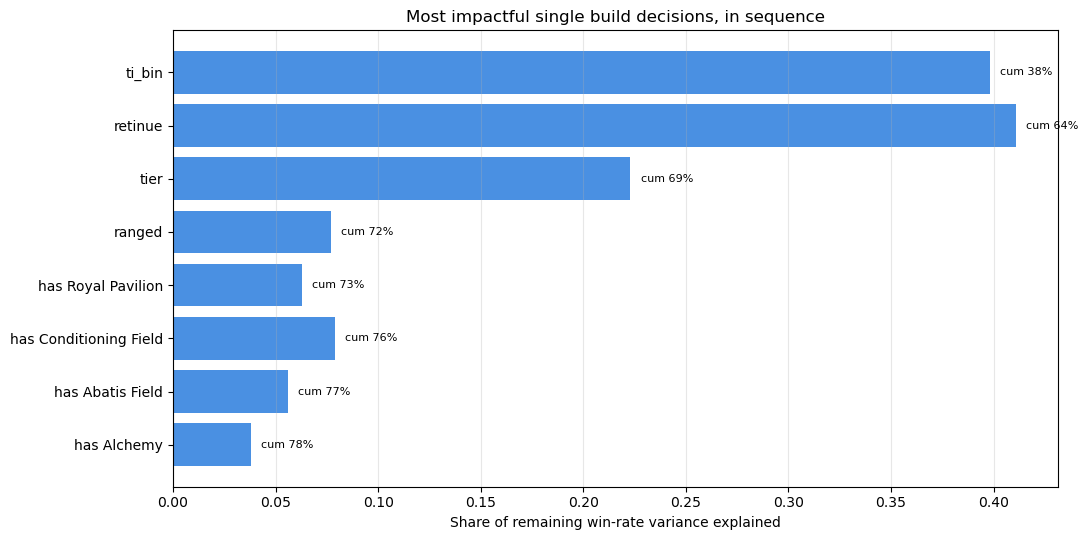


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\impact_sequence.png


In [58]:
# ============ Greedy impact ranking: which single choices explain win rate, in order ============
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
import renown_combat as rc

df = df_main_summary.copy()
N_STEPS   = 8        # how many factors to extract
MIN_GROUP = 15       # min builds per category level to count
P_MIN, P_MAX = 0.05, 0.95   # pursuit flags must be neither rare nor universal

# ── candidate features ──
df["shield"] = (
    df["shield"].astype(str).replace(["", "nan", "None"], "None").fillna("None")
)
df["ranged"] = (
    df["ranged"].astype(str).replace(["", "nan", "None"], "None").fillna("None")
)
df["tier"]   = df["armor"].map({a: v["tier"] for a, v in rc.ARMORS.items()})
df["ti"]     = df["pursuits"].fillna("").map(lambda s: len([x for x in s.split("|") if x]) if s else 0)
df["ti_bin"] = (np.floor(df["ti"] / 2) * 2).astype(int)

cands = {c: df[c] for c in ["retinue", "tier", "weapon", "shield", "ranged", "ti_bin"]}
# one binary flag per pursuit ("has Hospitaller", ...)
all_pursuits = sorted({p for s in df["pursuits"].fillna("") for p in s.split("|") if p})
for p in all_pursuits:
    flag = df["pursuits"].fillna("").str.contains(p, regex=False)
    if P_MIN <= flag.mean() <= P_MAX:
        cands[f"has {p}"] = flag.map({True: "yes", False: "no"})

def r2_of(resid, series):
    """Variance of resid explained by grouping on series (levels with >= MIN_GROUP)."""
    g = resid.groupby(series)
    sizes = g.size()
    ok = series.isin(sizes[sizes >= MIN_GROUP].index)
    if ok.sum() < len(resid) * 0.5 or series[ok].nunique() < 2:
        return np.nan, None
    r, s = resid[ok], series[ok]
    means = r.groupby(s).transform("mean")
    sst = ((r - r.mean()) ** 2).sum()
    return (1 - ((r - means) ** 2).sum() / sst if sst > 0 else 0.0), means

# ── greedy sequence: pick best factor, residualize, repeat ──
resid = df["win_rate"].astype(float).copy()
total_var = resid.var()
rows, chosen = [], set()
for step in range(1, N_STEPS + 1):
    best = None
    for name, series in cands.items():
        if name in chosen:
            continue
        r2, means = r2_of(resid, series)
        if not np.isnan(r2) and (best is None or r2 > best[1]):
            best = (name, r2, means, series)
    if best is None or best[1] <= 0.002:
        break
    name, r2, means, series = best
    chosen.add(name)
    # cumulative share of the ORIGINAL win-rate variance now explained
    resid = resid - means.reindex(resid.index).fillna(0) + resid.mean() * 0  # center-preserving
    resid = resid - resid.mean()
    cum = 1 - resid.var() / total_var
    lvl = df.loc[series.index].assign(_f=series).groupby("_f")["win_rate"].mean()
    spread = f"{lvl.idxmax()} {lvl.max():.2f} vs {lvl.idxmin()} {lvl.min():.2f}"
    rows.append({"step": step, "factor": name, "r2_of_residual": round(r2, 3),
                 "cumulative_r2": round(cum, 3), "best_vs_worst": spread})

seq = pd.DataFrame(rows)
print("=== Impact sequence: each step = biggest single factor in what's left unexplained ===")
print(seq.to_string(index=False))

# ── figure ──
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(seq["factor"][::-1], seq["r2_of_residual"][::-1], color="#4a90e2")
for y, (r2v, cumv) in enumerate(zip(seq["r2_of_residual"][::-1], seq["cumulative_r2"][::-1])):
    ax.text(r2v + 0.005, y, f"cum {cumv:.0%}", va="center", fontsize=8)
ax.set_xlabel("Share of remaining win-rate variance explained")
ax.set_title("Most impactful single build decisions, in sequence")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "impact_sequence.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'impact_sequence.png')}")

In [59]:
import loadouts as L

# the one Crafted fork + bare MaA, post-closure
p = L.master_effect_closure(L.prereq_closure(
    {"Coliseum","Stable","Blacksmith","Forge","Master Workshop","Armory","Gilded Foundry","ABF"}))
print("valid:", L._pursuit_set_is_valid(p))
print("tier :", L.derive_tier_from_pursuits(p))
mpc, dom, tags = L.compute_pursuit_cost(p)
print("mpc/total/domsum:", mpc, len(p), sum(dom.values()))
print("Poleaxe in melee list:", "Poleaxe" in L.archetype_pool.__wrapped__ if False else None)

valid: True
tier : Forged
mpc/total/domsum: 4 14 9
Poleaxe in melee list: None



=== Best builds by ARMOR ===

  Chainmail  (n=46, mean WR 0.510)
    0.987  Knight Templ Morningstar    None          Chainmail     | Animal Husbandry|Apothecary|Armory|Blacksmith|Carpentry|Chan
    0.977  Knight Templ Spears         Kite Shield   Chainmail     | Apothecary|Armory|Carpentry|Chandlery|Fighting School|Fletch
    0.916  Knight Templ Farm Tools     None          Chainmail     | Animal Husbandry|Apothecary|Armory|Carpentry|Chandlery|Fight

  Cloth  (n=183, mean WR 0.442)
    0.978  Knight Templ 2HBastard      None          Cloth         | Academy|Alchemy|Apothecary|Blacksmith|Carpentry|Finery|Fletc
    0.951  Knight Templ 2HBastard      None          Cloth         | Apothecary|Blacksmith|Carpentry|Chandlery|Coliseum|Condition
    0.941  Knight Templ Pitchfork      None          Cloth         | Apothecary|Carpentry|Chandlery|Fighting School|Fletchery|For

  Full Plate  (n=70, mean WR 0.560)
    0.970  Knight Templ Bastard Sword  Tower Shield  Full Plate    | Apothecary|Armo

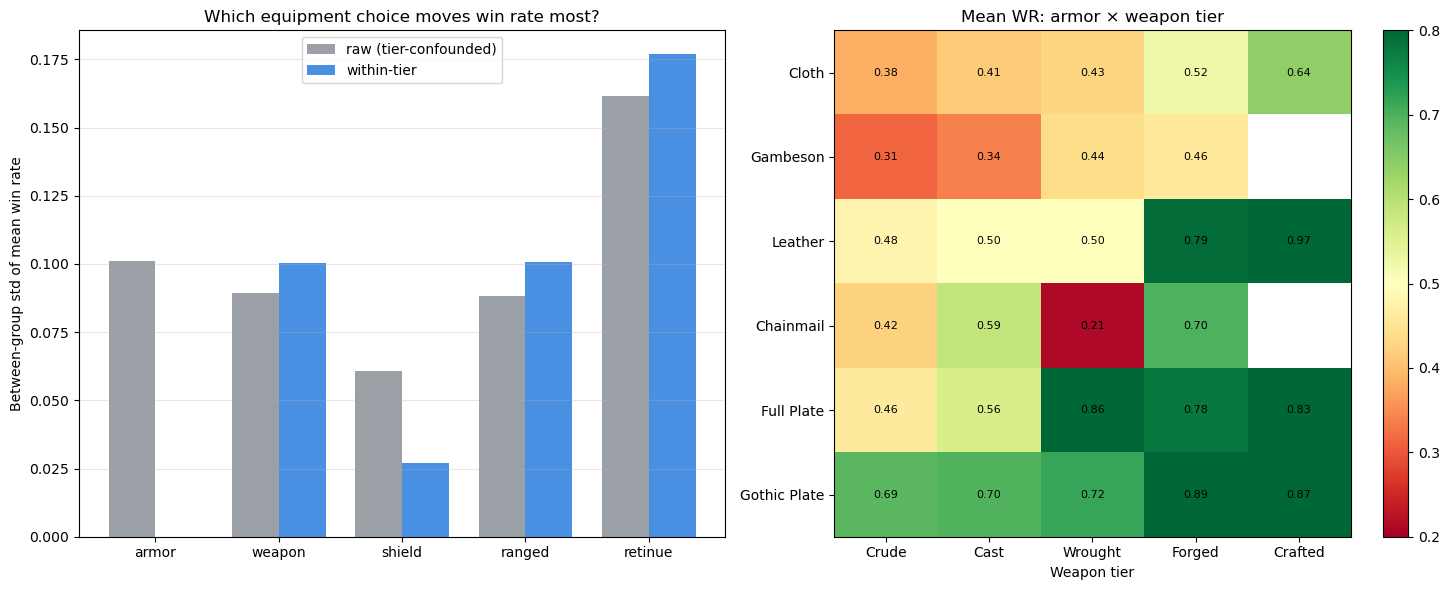


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\equipment_sensitivity.png


In [60]:
# ============ Best loadouts by equipment + sensitivity decomposition ============
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import renown_combat as rc

df = df_main_summary.copy()
MIN_N_GROUP = 5  # min loadouts for a group to count
TOP_K = 3  # best builds shown per equipment value

# Cast categorical columns to string before replacement to prevent Categorical setitem errors
df["shield"] = (
    df["shield"].astype(str).replace(["", "nan", "None"], "None").fillna("None")
)
df["ranged"] = (
    df["ranged"].astype(str).replace(["", "nan", "None"], "None").fillna("None")
)
df["tier"] = df["armor"].map({a: v["tier"] for a, v in rc.ARMORS.items()})

DIMS = ["armor", "weapon", "shield", "ranged", "retinue"]

# ── 1) Best loadouts per equipment value ──
print("=" * 100)
for dim in DIMS:
  print(f"\n=== Best builds by {dim.upper()} ===")
  for val, sub in df.groupby(dim):
    if len(sub) < MIN_N_GROUP or val == "None":
      continue
    top = sub.nlargest(TOP_K, "win_rate")
    print(f"\n  {val}  (n={len(sub)}, mean WR {sub['win_rate'].mean():.3f})")
    for _, r in top.iterrows():
      retinue_str = str(r["retinue"])[:12]
      weapon_str = str(r["weapon"])[:14]
      shield_str = str(r["shield"])[:13]
      armor_str = str(r["armor"])[:12]
      gear = f"{retinue_str:12} {weapon_str:14} {shield_str:13} {armor_str:12}"
      pursuits_str = str(r["pursuits"])[:60] if pd.notna(r["pursuits"]) else ""
      print(f"    {r['win_rate']:.3f}  {gear}  | {pursuits_str}")


# ── 2) Sensitivity: how much does each dimension move win rate? ──
def sensitivity(frame, dim, min_n=MIN_N_GROUP):
  """Weighted between-group std of group-mean WR = how much choosing along this dimension matters."""
  g = frame.groupby(dim)["win_rate"].agg(["mean", "count"])
  g = g[g["count"] >= min_n]
  if len(g) < 2:
    return np.nan, g
  w = g["count"] / g["count"].sum()
  grand = (g["mean"] * w).sum()
  return np.sqrt((w * (g["mean"] - grand) ** 2).sum()), g


print("\n" + "=" * 100)
print("=== Sensitivity (between-group std of mean WR) ===")
raw_sens, within_sens = {}, {}
for dim in DIMS:
  raw_sens[dim], _ = sensitivity(df, dim)
  # tier-controlled: sensitivity within each tier, weighted by tier size
  parts = []
  for tier, tsub in df.groupby("tier"):
    s, _ = sensitivity(tsub, dim)
    if not np.isnan(s):
      parts.append((s, len(tsub)))
  within_sens[dim] = (
      np.average([s for s, n in parts], weights=[n for s, n in parts])
      if parts
      else np.nan
  )
  print(
      f"  {dim:8}  raw {raw_sens[dim]:.3f}   within-tier"
      f" {within_sens[dim]:.3f}"
  )
print(
    "\n  raw = includes the tier confound; within-tier = the dimension's own"
    " effect."
)

# ── 3) Figure: sensitivity bars + armor × weapon-tier heatmap ──
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
x = np.arange(len(DIMS))
w = 0.38
ax.bar(
    x - w / 2,
    [raw_sens[d] for d in DIMS],
    w,
    label="raw (tier-confounded)",
    color="#9aa0a6",
)
ax.bar(
    x + w / 2,
    [within_sens[d] for d in DIMS],
    w,
    label="within-tier",
    color="#4a90e2",
)
ax.set_xticks(x)
ax.set_xticklabels(DIMS)
ax.set_ylabel("Between-group std of mean win rate")
ax.set_title("Which equipment choice moves win rate most?")
ax.legend()
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
WT = {w_: v["tier"] for w_, v in rc.WEAPONS.items()}
df["wtier"] = df["weapon"].map(WT)
pv = df.pivot_table(
    index="armor", columns="wtier", values="win_rate", aggfunc="mean"
)
pv = pv.reindex(
    index=[a for a in rc.ARMORS if a in pv.index],
    columns=[
        t
        for t in ["Crude", "Cast", "Wrought", "Forged", "Crafted"]
        if t in pv.columns
    ],
)
im = ax.imshow(pv.values, cmap="RdYlGn", vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(pv.columns)))
ax.set_xticklabels(pv.columns)
ax.set_yticks(range(len(pv.index)))
ax.set_yticklabels(pv.index)
ax.set_xlabel("Weapon tier")
ax.set_title("Mean WR: armor × weapon tier")
for i in range(len(pv.index)):
  for j in range(len(pv.columns)):
    v = pv.values[i, j]
    if not np.isnan(v):
      ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax)

plt.tight_layout()

out_dir = OUT_DIR if "OUT_DIR" in globals() else "."
out_file = os.path.join(out_dir, "equipment_sensitivity.png")
plt.savefig(out_file, dpi=110, bbox_inches="tight")
plt.show()
print(f"\nSaved: {out_file}")

## 4.2 Shield performance

In [61]:
# ============ Shield performance summary ============
sh = df_main_summary.copy()

# Convert shield column to string before replacing/filling missing values
sh["shield"] = (
    sh["shield"].astype(str).replace(["", "nan", "None"], "None").fillna("None")
)

# Aggregate core metrics grouped by shield type
sh = (
    sh.groupby("shield")
    .agg(
        n=("win_rate", "count"),  # Uses win_rate count safely if 'name' missing
        win_rate=("win_rate", "mean"),
        decisive_win_rate=("decisive_win_rate", "mean"),
        kill_eff=("kill_efficiency", "mean"),
    )
    .sort_values("win_rate", ascending=False)
)

print("=== Shield performance ===")
print(sh.round(3).to_string())

=== Shield performance ===
                 n  win_rate  decisive_win_rate  kill_eff
shield                                                   
Heater Shield   16     0.788              0.827     9.401
Kite Shield     10     0.620              0.654     4.211
Tower Shield    14     0.599              0.635     4.036
Targe Shield    17     0.496              0.522     0.769
None           393     0.487              0.509     0.235


## 4.3 Armor performance

In [62]:
arm = df_main_summary.groupby("armor").agg(
    n=("name","count"),
    win_rate=("win_rate","mean"),
    decisive_win_rate=("decisive_win_rate","mean"),
    survivors=("avg_self_survivors","mean"),
).sort_values("win_rate", ascending=False)
print("=== Armor performance ===")
print(arm.round(3).to_string())

=== Armor performance ===
                n  win_rate  decisive_win_rate  survivors
armor                                                    
Gothic Plate   55     0.728              0.765      9.228
Full Plate     70     0.560              0.590      6.415
Leather        53     0.529              0.552      6.075
Chainmail      46     0.510              0.536      5.720
Cloth         183     0.442              0.459      4.786
Gambeson       43     0.361              0.376      3.883


In [63]:
# Diagnose what's actually in df_main_summary
print("ARMORS present:", df_main_summary["armor"].value_counts().to_dict())
print("\nRETINUES present:", df_main_summary["retinue"].value_counts().to_dict())
print("\nMPC range:", df_main_summary["military_pursuit_count"].min(), "-", df_main_summary["military_pursuit_count"].max())
print("Total builds:", len(df_main_summary))
# Cross: which retinues have which armors (shows if tier floors are excluding light armor)
print("\nArmor x Retinue:")
print(df_main_summary.groupby(["retinue","armor"]).size().unstack(fill_value=0))

ARMORS present: {'Cloth': 183, 'Full Plate': 70, 'Gothic Plate': 55, 'Leather': 53, 'Chainmail': 46, 'Gambeson': 43}

RETINUES present: {'Levy': 115, 'Man-at-Arms': 112, 'Sergeant': 112, 'Knight Templar': 111}

MPC range: 2 - 4
Total builds: 450

Armor x Retinue:
armor           Chainmail  Cloth  Full Plate  Gambeson  Gothic Plate  Leather
retinue                                                                      
Knight Templar         12     49          15         7             8       20
Levy                   15     36          17        18            19       10
Man-at-Arms            12     45          20         9            14       12
Sergeant                7     53          18         9            14       11


## 4.4 Bastard Sword — does the dual-profile actually help?

Compare Bastard 1H+shield builds vs Bastard 2H builds vs other 2H weapons (Poleaxe, Halberd, etc.).

In [64]:
bast = df_main_summary[df_main_summary["weapon"] == "Bastard Sword"].copy()
bast["mode"] = np.where(bast["shield"].astype(str).fillna("None") == "None", "Bastard 2H", "Bastard 1H+shield")
b_summary = bast.groupby("mode").agg(
    n=("name","count"),
    win_rate=("win_rate","mean"),
    decisive_win_rate=("decisive_win_rate","mean"),
    kill_eff=("kill_efficiency","mean"),
).round(3)
print("=== Bastard Sword variants ===")
print(b_summary.to_string())

# Compare to other heavy weapons
print()
print("=== Other heavy 2H weapons for reference ===")
other = df_main_summary[df_main_summary["weapon"].isin(["Poleaxe","Halberd","War Hammer","Battle Axe","2HBastard"])]
print(other.groupby("weapon").agg(
    n=("name","count"),
    win_rate=("win_rate","mean"),
    decisive_win_rate=("decisive_win_rate","mean"),
).round(3).to_string())

=== Bastard Sword variants ===
                   n  win_rate  decisive_win_rate  kill_eff
mode                                                       
Bastard 1H+shield  3     0.911               0.93    13.127

=== Other heavy 2H weapons for reference ===
             n  win_rate  decisive_win_rate
weapon                                     
2HBastard   40     0.641              0.662
Battle Axe  11     0.536              0.554
Halberd      9     0.495              0.522
Poleaxe      8     0.744              0.761
War Hammer  38     0.485              0.502


## 4.5 Lance — does Charge synergy pay off?

In [65]:
lance = df_main_summary[df_main_summary["weapon"] == "Lance"]
non_lance = df_main_summary[df_main_summary["weapon"] != "Lance"]
print(f"Lance loadouts:  n={len(lance):3d}  win_rate={lance['win_rate'].mean():.3f}  decisive_wr={lance['decisive_win_rate'].mean():.3f}")
print(f"Non-Lance:       n={len(non_lance):3d}  win_rate={non_lance['win_rate'].mean():.3f}  decisive_wr={non_lance['decisive_win_rate'].mean():.3f}")
# Best lance shields
if len(lance) > 0:
    print("\nLance shield breakdown:")
    print(lance.groupby("shield").agg(n=("name","count"), wr=("win_rate","mean")).round(3).to_string())

Lance loadouts:  n=  0  win_rate=nan  decisive_wr=nan
Non-Lance:       n=450  win_rate=0.505  decisive_wr=0.528


## 4.6 Shield deep-dive

A focused analysis of shield builds across all metrics. Shield types map to gear tiers (Buckler=Crude, Targe=Cast, Kite=Wrought, Tower=Forged, Heater=Crafted) per the loadout rules — so this also doubles as a tier-by-tier comparison of shielded builds.

### 4.6.1 Win rate by shield type

In [66]:
# Filter to shield-bearing matchup rows (A side)
shield_df = df_main_matchups[df_main_matchups['a_shield'].notna() & (df_main_matchups['a_shield'] != '')].copy()
shield_df['n_battles'] = shield_df['a_wins'] + shield_df['b_wins'] + shield_df['mut_wipe'] + shield_df['indecisive']
print(f'Shield-bearing matchup rows: {len(shield_df):,} (of {len(df_main_matchups):,} total)')

# Per-loadout aggregation
shield_winrate = shield_df.groupby(['a_name', 'a_shield', 'a_retinue', 'a_weapon', 'a_armor']).agg(
    n_battles=('n_battles', 'sum'),
    wins=('a_wins', 'sum'),
    losses=('b_wins', 'sum'),
    mutual=('mut_wipe', 'sum'),
).reset_index()
shield_winrate['win_rate'] = shield_winrate['wins'] / shield_winrate['n_battles']
shield_winrate['decisive_win_rate'] = shield_winrate['wins'] / shield_winrate[['wins','losses']].sum(axis=1).clip(lower=1)
shield_winrate = shield_winrate.sort_values('win_rate', ascending=False)

print('\n=== Win rate by shield type (aggregate) ===')
by_type = shield_winrate.groupby('a_shield').agg(
    n_loadouts=('a_name', 'count'),
    avg_win_rate=('win_rate', 'mean'),
    avg_decisive_wr=('decisive_win_rate', 'mean'),
).sort_values('avg_win_rate', ascending=False)
print(by_type.round(3).to_string())

Shield-bearing matchup rows: 21,305 (of 170,906 total)

=== Win rate by shield type (aggregate) ===
               n_loadouts  avg_win_rate  avg_decisive_wr
a_shield                                                
Heater Shield          16         0.788            0.827
Kite Shield            10         0.620            0.654
Tower Shield           14         0.599            0.635
Targe Shield           17         0.496            0.522


### 4.6.2 Durability — survival rates by shield

In [67]:
# Use analysis.durability and join shield info back in
dur = analysis.durability(df_main_matchups)
shield_lookup = df_main_matchups.groupby('a_name')['a_shield'].first().to_dict()
dur['shield'] = dur['a_name'].map(shield_lookup).fillna('None')

dur_by_shield = dur.groupby('shield').agg(
    n_loadouts=('a_name', 'count'),
    avg_survival_rate=('avg_survival_rate', 'mean'),
).sort_values('avg_survival_rate', ascending=False)
print('=== Survival rate by shield type ===')
print(dur_by_shield.round(3).to_string())

print('\n=== Top 10 most durable shield builds ===')
top_shield_dur = dur[dur['shield'] != 'None'].nlargest(10, 'avg_survival_rate')[
    ['a_name','shield','avg_survival_rate']]
print(top_shield_dur.round(3).to_string(index=False))

=== Survival rate by shield type ===
               n_loadouts  avg_survival_rate
shield                                      
Heater Shield          16              0.423
Kite Shield            10              0.291
Tower Shield           14              0.282
                      393              0.219
Targe Shield           17              0.217

=== Top 10 most durable shield builds ===
                                                                                                                                        a_name        shield  avg_survival_rate
          KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]                            0.712
      KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1]                            0.679
                   KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCu

### 4.6.3 Shield destruction rate

How often does each shield get smashed mid-battle? Buckler + Cast tier shields are most fragile; Heater the toughest.

In [68]:
# Drop mirror matchups
sd_df = shield_df[shield_df['a_name'] != shield_df['b_name']].copy()
destroy_by_type = sd_df.groupby('a_shield').agg(
    n_matchups=('a_shield', 'count'),
    avg_destroy_pct=('a_shield_destroyed_rate', lambda x: x.mean() * 100),
).sort_values('avg_destroy_pct', ascending=False)
print('=== Avg shield destruction rate by type ===')
print(destroy_by_type.round(1).to_string())

# Top 10 most-destroyed shield builds
print('\n=== Top 10 most-destroyed shield builds ===')
top_destroyed = sd_df.groupby(['a_name', 'a_shield']).agg(
    avg_destroy_pct=('a_shield_destroyed_rate', lambda x: x.mean() * 100),
).reset_index().sort_values('avg_destroy_pct', ascending=False).head(10)
print(top_destroyed.round(1).to_string(index=False))

=== Avg shield destruction rate by type ===
               n_matchups  avg_destroy_pct
a_shield                                  
Targe Shield         6344              3.7
Tower Shield         5603              2.8
Kite Shield          3587              2.1
Heater Shield        5771              0.0

=== Top 10 most-destroyed shield builds ===
                                                                                           a_name     a_shield  avg_destroy_pct
                         KT/ShortSword/Targe/Leather [(RInd, EProw, SPie, NCun), Enduring, Rec 6] Targe Shield              6.9
                  KT/FarmTools/Targe/Leather [(RInd, EProw, SPie, NCun), Enduring, Nimble, Rec 6] Targe Shield              6.9
                            KT/ShortSword/Kite/Chain [(RInd, EProw, SPie, NCun), Enduring, Rec 6]  Kite Shield              6.9
      MaA/ShortSword/Tower/FullPlate [RoPa, (EInd, SProw, NPie, NCun), Nimble, Parry +2, Riposte] Tower Shield              6.9
        MaA/S

### 4.6.4 What counters shield builds?

For each shield type, which weapons/loadouts beat them most reliably?

In [69]:
def top_counters_for_shield(shield_name, top_n=8):
    rows = df_main_matchups[
        (df_main_matchups['a_shield'] == shield_name) &
        (df_main_matchups['a_name'] != df_main_matchups['b_name'])
    ].copy()
    if len(rows) == 0:
        return None
    rows['n_battles'] = rows['a_wins'] + rows['b_wins'] + rows['mut_wipe'] + rows['indecisive']
    rows['a_winrate'] = rows['a_wins'] / rows['n_battles']
    rows['b_winrate'] = rows['b_wins'] / rows['n_battles']
    counters = rows.groupby(['b_weapon', 'b_retinue', 'b_shield']).agg(
        b_wr=('b_winrate', 'mean'),
        a_wr=('a_winrate', 'mean'),
        n=('a_name', 'count'),
    ).reset_index()
    counters['margin'] = counters['b_wr'] - counters['a_wr']
    counters = counters[counters['n'] >= 5].sort_values('margin', ascending=False).head(top_n)
    return counters

for shield_type in ['Buckler Shield','Targe Shield','Kite Shield','Tower Shield','Heater Shield']:
    c = top_counters_for_shield(shield_type)
    if c is not None and len(c) > 0:
        print(f'\n=== Top counters for {shield_type} ===')
        print(c.round(3).to_string(index=False))


=== Top counters for Targe Shield ===
     b_weapon      b_retinue      b_shield  b_wr  a_wr  n  margin
  Morningstar Knight Templar               1.000 0.000  8   1.000
         Pike Knight Templar               0.999 0.001 12   0.998
  Morningstar Knight Templar Heater Shield 0.999 0.000 12   0.998
       Spears Knight Templar   Kite Shield 0.995 0.003  8   0.992
Bastard Sword Knight Templar  Tower Shield 0.992 0.003 24   0.989
        Flail Knight Templar Heater Shield 0.990 0.004 12   0.986
        Flail Knight Templar   Kite Shield 0.989 0.006 12   0.983
  Short Sword Knight Templar  Tower Shield 0.986 0.009 12   0.977

=== Top counters for Kite Shield ===
     b_weapon      b_retinue      b_shield  b_wr  a_wr  n  margin
  Morningstar Knight Templar Heater Shield 0.972 0.011  7   0.961
         Pike Knight Templar               0.968 0.013  7   0.955
Bastard Sword Knight Templar  Tower Shield 0.928 0.042 14   0.885
   Battle Axe Knight Templar               0.892 0.066 16   0.827

### 4.6.5 What do shield builds dominate?

Inverse — for each shield type, what loadouts do they beat reliably?

In [70]:
def shield_matchup_grid(shield_name, min_n=5):
    """Full attacker-retinue × defender-retinue favorable-matchup grid for a shield.

    For each (attacker retinue, defender retinue) cell, shows the shield's mean win rate
    and the top favorable weapon matchups within that cell — so you can read e.g.
    'Kite-KT vs Sergeant-tier opponents' without Levy noise on either side.
    """
    rows = df_main_matchups[
        (df_main_matchups['a_shield'] == shield_name) &
        (df_main_matchups['a_name'] != df_main_matchups['b_name'])
    ].copy()
    if len(rows) == 0:
        print(f"\n(no data for {shield_name})")
        return
    rows['n_battles'] = rows['a_wins'] + rows['b_wins'] + rows['mut_wipe'] + rows['indecisive']
    rows['a_winrate'] = rows['a_wins'] / rows['n_battles']
    rows['b_winrate'] = rows['b_wins'] / rows['n_battles']

    RETS = ['Levy', 'Man-at-Arms', 'Sergeant', 'Knight Templar']

    # ── Summary grid: mean win rate per (attacker ret × defender ret) ──
    grid = rows.groupby(['a_retinue', 'b_retinue']).agg(
        a_wr=('a_winrate', 'mean'), n=('a_name', 'count')
    ).reset_index()
    pivot = grid.pivot(index='a_retinue', columns='b_retinue', values='a_wr')
    pivot = pivot.reindex(index=[r for r in RETS if r in pivot.index],
                          columns=[r for r in RETS if r in pivot.columns])
    print(f"\n{'='*70}\n{shield_name}: mean win rate by attacker retinue (rows) × defender retinue (cols)\n{'='*70}")
    print(pivot.round(3).to_string())

    # ── Detailed: top favorable weapon matchups per attacker×defender cell ──
    for a_ret in RETS:
        for b_ret in RETS:
            sub = rows[(rows['a_retinue'] == a_ret) & (rows['b_retinue'] == b_ret)]
            if len(sub) == 0:
                continue
            targets = sub.groupby(['b_weapon', 'b_shield']).agg(
                a_wr=('a_winrate', 'mean'),
                b_wr=('b_winrate', 'mean'),
                n=('a_name', 'count'),
            ).reset_index()
            targets['margin'] = targets['a_wr'] - targets['b_wr']
            targets = targets[targets['n'] >= min_n].sort_values('margin', ascending=False).head(4)
            if len(targets) == 0:
                continue
            print(f'\n  {shield_name} · {a_ret} vs {b_ret}-tier opponents:')
            print(targets.round(3).to_string(index=False).replace('\n', '\n    '))


for shield_type in ['Buckler Shield', 'Targe Shield', 'Kite Shield', 'Tower Shield', 'Heater Shield']:
    shield_matchup_grid(shield_type)


(no data for Buckler Shield)

Targe Shield: mean win rate by attacker retinue (rows) × defender retinue (cols)
b_retinue        Levy  Man-at-Arms  Sergeant  Knight Templar
a_retinue                                                   
Levy            0.387        0.263     0.250           0.039
Man-at-Arms     0.577        0.406     0.314           0.094
Sergeant        0.722        0.648     0.532           0.238
Knight Templar  0.836        0.728     0.727             NaN

  Targe Shield · Levy vs Levy-tier opponents:
   b_weapon b_shield  a_wr  b_wr  n  margin
                         0.654 0.232 20   0.422
     Farm Tools          0.629 0.270 40   0.358
    Short Sword          0.535 0.345 12   0.191
      Pitchfork          0.460 0.390 44   0.070

  Targe Shield · Levy vs Man-at-Arms-tier opponents:
  b_weapon b_shield  a_wr  b_wr  n  margin
     Pitchfork          0.437 0.468 52  -0.031
    Farm Tools          0.382 0.529 52  -0.147
        Cudgel          0.354 0.561 60  -0.207
 

### 4.6.6 Best tactics for shield builds

For one representative loadout per shield type, what's the best opening tactic?

In [71]:
# Pick the top-winrate loadout for each shield type from shield_winrate
representatives = []
for shield_type in ['Buckler Shield', 'Targe Shield', 'Kite Shield', 'Tower Shield', 'Heater Shield']:
    matches = shield_winrate[shield_winrate['a_shield'] == shield_type]
    if len(matches) > 0:
        representatives.append(matches.iloc[0]['a_name'])

# Use the empirical tactic matrix (loaded in Section 1E) as a proxy for tactic guidance.
# For per-loadout tactic profile, see Section 5.
if df_tactic_matrix is not None:
    _tac_pivot = df_tactic_matrix.pivot(index='a_tactic', columns='b_tactic', values='a_win_rate')
    _tac_pivot = _tac_pivot.reindex(index=TACTICS, columns=TACTICS)
    marginal_wr = _tac_pivot.mean(axis=1).sort_values(ascending=False)

    print('Marginal tactic win rates (best openings against a uniform-tactic opponent):')
    for t, wr in marginal_wr.items():
        print(f'  {t:<22} {wr:.3f}')

    print(f'\nRepresentative shield builds (best win-rate loadout per shield type):')
    for name in representatives:
        print(f'  {name}')
else:
    print('Tactic matrix not loaded — skip')

Marginal tactic win rates (best openings against a uniform-tactic opponent):
  Fighting Formation     0.420
  Charge                 0.414
  Scout                  0.409
  Defensive Formation    0.408
  Flank                  0.407
  Ambush                 0.396
  Fall Back              0.000

Representative shield builds (best win-rate loadout per shield type):
  KT/Longbow/Targe/Leather [RoPa, (RInd, SProw, SPie, NCun), Enduring, Florentine, Immune Awkward, Nimble, Parry +2, Rec 6, Riposte]
  KT/Spears+Longbow/Kite/Chain (TY) [RoPa, (RInd, SProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]
  KT/Bastard+Longbow/Tower/FullPlate (TY) [(EInd, EProw, SPie, NCun), AP -1, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Serr, Strike +1]
  KT/Morningstar/Heater/Gothic [CoAr, (SInd, EProw, SPie, NCun), AP -1, Enduring, Nimble, Parry +1, Rec 6, Riposte]


### 4.6.7 Shield summary

In [72]:
print('=== Shield Findings Summary ===')
print()
print('1. Win rate by shield (mean across loadouts):')
print(by_type[['n_loadouts','avg_win_rate','avg_decisive_wr']].round(3).to_string())
print()
print('2. Durability ranking:')
print(dur_by_shield.round(3).to_string())
print()
print('3. Destruction frequency (lower = tougher shield):')
print(destroy_by_type.round(1).to_string())

=== Shield Findings Summary ===

1. Win rate by shield (mean across loadouts):
               n_loadouts  avg_win_rate  avg_decisive_wr
a_shield                                                
Heater Shield          16         0.788            0.827
Kite Shield            10         0.620            0.654
Tower Shield           14         0.599            0.635
Targe Shield           17         0.496            0.522

2. Durability ranking:
               n_loadouts  avg_survival_rate
shield                                      
Heater Shield          16              0.423
Kite Shield            10              0.291
Tower Shield           14              0.282
                      393              0.219
Targe Shield           17              0.217

3. Destruction frequency (lower = tougher shield):
               n_matchups  avg_destroy_pct
a_shield                                  
Targe Shield         6344              3.7
Tower Shield         5603              2.8
Kite Shield     

## 4.7 Bastard Sword deep-dive

The dual-profile weapon: 1H mode (with shield) provides Shatter Armor + Steady; 2H mode (no shield, OR shield destroyed) provides Cleave + Unwieldy. Adaptive: a Bastard+shield build automatically switches to 2H mode if the shield breaks. How does this adaptive mechanic perform in practice?

### 4.7.1 Overall comparison — Bastard 1H vs 2H vs other

In [73]:
bastard_df = df_main_matchups[df_main_matchups['a_weapon'] == 'Bastard Sword'].copy()
bastard_df['n_battles'] = bastard_df['a_wins'] + bastard_df['b_wins'] + bastard_df['mut_wipe'] + bastard_df['indecisive']
bastard_df['mode'] = bastard_df['a_shield'].apply(
    lambda s: '2H (no shield)' if (pd.isna(s) or s == '') else f'1H + {s}')
print(f'Bastard Sword matchup rows: {len(bastard_df):,}\n')

mode_winrate = bastard_df.groupby(['a_name', 'mode', 'a_retinue', 'a_armor']).agg(
    n_battles=('n_battles', 'sum'),
    wins=('a_wins', 'sum'),
    losses=('b_wins', 'sum'),
).reset_index()
mode_winrate['win_rate'] = mode_winrate['wins'] / mode_winrate['n_battles']
mode_winrate['decisive_wr'] = mode_winrate['wins'] / mode_winrate[['wins','losses']].sum(axis=1).clip(lower=1)
mode_winrate = mode_winrate.sort_values('win_rate', ascending=False)

print('=== Bastard variants — mean win rate by mode ===')
by_mode = mode_winrate.groupby('mode').agg(
    n_loadouts=('a_name', 'count'),
    avg_win_rate=('win_rate', 'mean'),
    avg_decisive_wr=('decisive_wr', 'mean'),
).sort_values('avg_win_rate', ascending=False)
print(by_mode.round(3).to_string())
print('\n=== Top 10 Bastard builds (any mode) ===')
print(mode_winrate.head(10)[['a_name','mode','a_retinue','win_rate','decisive_wr']].round(3).to_string(index=False))

Bastard Sword matchup rows: 1,073

=== Bastard variants — mean win rate by mode ===
                    n_loadouts  avg_win_rate  avg_decisive_wr
mode                                                         
1H + Tower Shield            2         0.941            0.958
1H + Heater Shield           1         0.850            0.874

=== Top 10 Bastard builds (any mode) ===
                                                                                                                                        a_name               mode      a_retinue  win_rate  decisive_wr
KT/Bastard+Longbow/Tower/FullPlate (TY) [(EInd, EProw, SPie, NCun), AP -1, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Serr, Strike +1]  1H + Tower Shield Knight Templar     0.970        0.980
                              KT/Bastard+Longbow/Tower/FullPlate (TY) [(EInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, Rec 6]  1H + Tower Shield Knight Templar     0.912        0.937
                          

In [74]:
import renown_combat as rc, inspect
print(inspect.getsource(rc.Army.unshakable))   # which key?
# then force the test path:
a = rc.make_army("KT","Knight Templar","Halberd",None,"Chainmail",25)
a.endurance = 0; a.fatigue = 1
try:
    print("shaking_test result:", rc.shaking_test(a))   # crashes? returns 0?
except Exception as e:
    print("CRASH:", e)

    def unshakable(self):
        return RETINUES[self.retinue]["unshakable"]

CRASH: 'unshakable'


### 4.7.2 Adaptive value — does mode-switching pay off?

How often does a Bastard+shield build have its shield destroyed mid-battle, forcing the 2H mode switch? Pair that with win rate to see whether the adaptive mechanic is actually delivering value.

### 4.7.3 Counters for each Bastard mode

In [75]:
def bastard_counters(filter_func, label, n=8):
    rows = df_main_matchups[filter_func(df_main_matchups) &
                            (df_main_matchups['a_name'] != df_main_matchups['b_name'])].copy()
    if len(rows) == 0:
        return
    rows['n_battles'] = rows['a_wins'] + rows['b_wins'] + rows['mut_wipe'] + rows['indecisive']
    rows['a_wr'] = rows['a_wins'] / rows['n_battles']
    rows['b_wr'] = rows['b_wins'] / rows['n_battles']
    counters = rows.groupby(['b_weapon', 'b_retinue', 'b_shield']).agg(
        b_wr=('b_wr', 'mean'),
        a_wr=('a_wr', 'mean'),
        n_pairs=('a_name', 'count'),
    ).reset_index()
    counters['margin'] = counters['b_wr'] - counters['a_wr']
    counters = counters[counters['n_pairs'] >= 5].sort_values('margin', ascending=False).head(n)
    print(f'\n=== Top counters for {label} ===')
    print(counters.round(3).to_string(index=False))

# 1H mode (has shield)
bastard_counters(
    lambda d: (d['a_weapon'] == 'Bastard Sword') & d['a_shield'].notna() & (d['a_shield'] != ''),
    'Bastard 1H+shield')
# 2H mode (no shield)
bastard_counters(
    lambda d: (d['a_weapon'] == 'Bastard Sword') & ((d['a_shield'].isna()) | (d['a_shield'] == '')),
    'Bastard 2H')


=== Top counters for Bastard 1H+shield ===
  b_weapon      b_retinue b_shield  b_wr  a_wr  n_pairs  margin
 2HBastard Knight Templar          0.643 0.274       13   0.370
   Poleaxe    Man-at-Arms          0.370 0.589       14  -0.219
War Hammer       Sergeant          0.228 0.747       27  -0.519
War Hammer    Man-at-Arms          0.202 0.773       30  -0.571
 2HBastard       Sergeant          0.176 0.794       12  -0.618
   Daggers       Sergeant          0.132 0.828       20  -0.696
 Bill Hook Knight Templar          0.106 0.806        8  -0.700
 2HBastard    Man-at-Arms          0.122 0.842       41  -0.720


### 4.7.4 Best shield pairing for Bastard 1H

In [76]:
bastard_1h = bastard_df[(bastard_df['a_shield'].notna()) & (bastard_df['a_shield'] != '')].copy()
pairing = bastard_1h.groupby(['a_shield', 'a_retinue', 'a_armor']).agg(
    n_loadouts=('a_name', 'nunique'),
    n_battles=('n_battles', 'sum'),
    wins=('a_wins', 'sum'),
    avg_destroy_pct=('a_shield_destroyed_rate', lambda x: x.mean() * 100),
).reset_index()
pairing['win_rate'] = pairing['wins'] / pairing['n_battles']
pairing = pairing.sort_values('win_rate', ascending=False)
print('=== Bastard 1H × shield × armor combos (top 15 by win rate) ===')
print(pairing.head(15).round(3).to_string(index=False))

=== Bastard 1H × shield × armor combos (top 15 by win rate) ===
     a_shield      a_retinue      a_armor  n_loadouts  n_battles   wins  avg_destroy_pct  win_rate
 Tower Shield Knight Templar   Full Plate           2     135600 127610              0.0     0.941
Heater Shield    Man-at-Arms Gothic Plate           1      79000  67116              0.0     0.850


### 4.7.5 Bastard vs other top weapons

In [77]:
focus_weapons = ['Bastard Sword', 'Poleaxe', 'Lance', 'Halberd', 'Pike', 'Battle Axe', 'Morningstar', 'War Hammer',"2HBastard"]
focus = df_main_matchups[
    df_main_matchups['a_weapon'].isin(focus_weapons) &
    (df_main_matchups['a_name'] != df_main_matchups['b_name'])
].copy()
focus['n_battles'] = focus['a_wins'] + focus['b_wins'] + focus['mut_wipe'] + focus['indecisive']

def to_mode(row):
    if row['a_weapon'] == 'Bastard Sword':
        return 'Bastard 1H' if pd.notna(row['a_shield']) and row['a_shield'] != '' else 'Bastard 2H'
    return row['a_weapon']
focus['mode'] = focus.apply(to_mode, axis=1)

comparison = focus.groupby(['mode', 'a_retinue']).agg(
    n_loadouts=('a_name', 'nunique'),
    n_battles=('n_battles', 'sum'),
    wins=('a_wins', 'sum'),
    losses=('b_wins', 'sum'),
).reset_index()
comparison['win_rate'] = comparison['wins'] / comparison['n_battles']
comparison['decisive_wr'] = comparison['wins'] / comparison[['wins','losses']].sum(axis=1).clip(lower=1)
comparison = comparison.sort_values(['a_retinue', 'win_rate'], ascending=[True, False])
print('=== Heavy weapons by retinue ===')
print(comparison[['a_retinue','mode','n_loadouts','win_rate','decisive_wr']].round(3).to_string(index=False))

=== Heavy weapons by retinue ===
     a_retinue        mode  n_loadouts  win_rate  decisive_wr
Knight Templar        Pike           1     0.987        0.991
Knight Templar Morningstar           2     0.970        0.981
Knight Templar  Bastard 1H           2     0.941        0.959
Knight Templar  Battle Axe           3     0.937        0.953
Knight Templar     Poleaxe           2     0.902        0.921
Knight Templar   2HBastard          13     0.870        0.893
Knight Templar  War Hammer           5     0.848        0.869
Knight Templar     Halberd           1     0.737        0.775
          Levy Morningstar           1     0.496        0.517
          Levy   2HBastard           9     0.483        0.509
          Levy     Halberd           1     0.427        0.477
          Levy  War Hammer          14     0.284        0.297
          Levy  Battle Axe           4     0.256        0.270
          Levy        Pike           2     0.256        0.272
   Man-at-Arms  Bastard 1H           

### 4.7.6 Bastard summary

In [78]:
print('=== Bastard Sword findings ===\n')
print('1. Mode comparison:')
print(by_mode.round(3).to_string())
print()

=== Bastard Sword findings ===

1. Mode comparison:
                    n_loadouts  avg_win_rate  avg_decisive_wr
mode                                                         
1H + Tower Shield            2         0.941            0.958
1H + Heater Shield           1         0.850            0.874



# 5. Tactics Analysis

Two complementary views:
1. **Empirical matrix** from the main tournament — what *actually happens* when players choose tactics under Random policy
2. **Forced matrix** — head-to-head under deterministic tactic forcing

## 5.1 Empirical tactic matrix (from main tournament)

These are the win rates when A and B chose their first-skirmish tactics organically (per Random policy) and the battle played out. No tactics were forced.

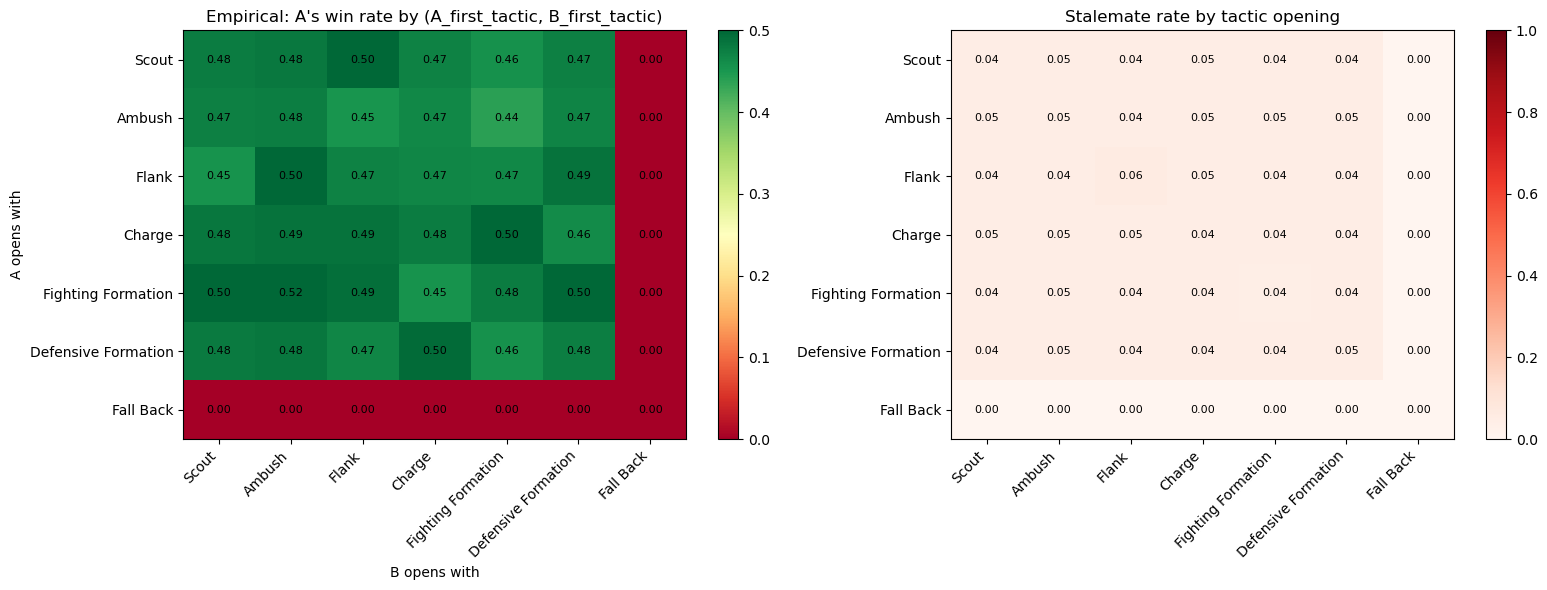


Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\tactics.png


In [79]:
pivot_emp = df_tactic_matrix.pivot(index="a_tactic", columns="b_tactic", values="a_win_rate")
pivot_emp = pivot_emp.reindex(index=TACTICS, columns=TACTICS)
pivot_indec = df_tactic_matrix.pivot(index="a_tactic", columns="b_tactic", values="stalemate_rate")
pivot_indec = pivot_indec.reindex(index=TACTICS, columns=TACTICS)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
im = ax.imshow(pivot_emp.values, cmap="RdYlGn", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(7)); ax.set_xticklabels(TACTICS, rotation=45, ha="right")
ax.set_yticks(range(7)); ax.set_yticklabels(TACTICS)
ax.set_title("Empirical: A's win rate by (A_first_tactic, B_first_tactic)")
ax.set_xlabel("B opens with"); ax.set_ylabel("A opens with")
plt.colorbar(im, ax=ax)
for i in range(7):
    for j in range(7):
        v = pivot_emp.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)

ax = axes[1]
im = ax.imshow(pivot_indec.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(7)); ax.set_xticklabels(TACTICS, rotation=45, ha="right")
ax.set_yticks(range(7)); ax.set_yticklabels(TACTICS)
ax.set_title("Stalemate rate by tactic opening")
plt.colorbar(im, ax=ax)
for i in range(7):
    for j in range(7):
        v = pivot_indec.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'tactics.png')}")

## 5.2 Marginal value of each tactic

Average win rate when opening with each tactic, vs uniform opponent.

In [80]:
marginal = pivot_emp.mean(axis=1).sort_values(ascending=False)
print("=== Marginal win rate when opening with each tactic ===")
for t, wr in marginal.items():
    print(f"  {t:<22} {wr:.3f}")
print()
print("Read: avg win rate when A opens with this tactic vs a random B opener.")
print("Higher = stronger default opening choice under random play.")

=== Marginal win rate when opening with each tactic ===
  Fighting Formation     0.420
  Charge                 0.414
  Scout                  0.409
  Defensive Formation    0.408
  Flank                  0.407
  Ambush                 0.396
  Fall Back              0.000

Read: avg win rate when A opens with this tactic vs a random B opener.
Higher = stronger default opening choice under random play.


## 5.3 Forced tactics matrix (stratified sample)

For comparison. Every (a, b) tactic pair is forced — pure interaction effect without play-style noise.

In [81]:
if df_forced_tactics is not None:
    pivot_forced = df_forced_tactics.pivot(index="a_tactic", columns="b_tactic", values="win_rate")
    pivot_forced = pivot_forced.reindex(index=TACTICS, columns=TACTICS)

    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(pivot_forced.values, cmap="RdYlGn", vmin=0, vmax=0.5, aspect="auto")
    ax.set_xticks(range(7)); ax.set_xticklabels(TACTICS, rotation=45, ha="right")
    ax.set_yticks(range(7)); ax.set_yticklabels(TACTICS)
    ax.set_title("Forced: A's win rate when A plays row vs B plays column (every skirmish)")
    ax.set_xlabel("B forced to"); ax.set_ylabel("A forced to")
    plt.colorbar(im, ax=ax)
    for i in range(7):
        for j in range(7):
            v = pivot_forced.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
    plt.tight_layout(); plt.show()

    print("\nDifference (empirical - forced):")
    print((pivot_emp - pivot_forced).round(2).to_string())
else:
    print("Forced tactics CSV not loaded — skip.")

Forced tactics CSV not loaded — skip.


## 5.4 Counter table — which tactic counters which?

For each opponent tactic, which of YOUR tactics produces the best win rate?

In [82]:
print("=== Best counter for each opponent opening ===")
print(f"{'Opponent plays':<22}  {'Best counter':<22}  {'Win rate':>9}")
for t in TACTICS:
    col = pivot_emp[t].dropna()
    best = col.idxmax(); wr = col.max()
    print(f"  {t:<20}  {best:<22}  {wr:>8.3f}")

=== Best counter for each opponent opening ===
Opponent plays          Best counter             Win rate
  Scout                 Fighting Formation         0.501
  Ambush                Fighting Formation         0.517
  Flank                 Scout                      0.502
  Charge                Defensive Formation        0.496
  Fighting Formation    Charge                     0.501
  Defensive Formation   Fighting Formation         0.500
  Fall Back             Scout                      0.000


# 6. Playstyle Analysis

Compare the playstyle-aware tournament (each loadout uses its assigned best playstyle) against the main Random tournament. Question: do default playstyles actually help loadouts perform?

In [83]:
if df_ps_summary is None:
    print("Playstyle tournament not loaded — skip.")
else:
    merged = df_main_summary.merge(
        df_ps_summary[["name","win_rate","decisive_win_rate","kill_efficiency","playstyle"]],
        on="name", suffixes=("_random", "_style"))
    merged["wr_delta"] = merged["win_rate_style"] - merged["win_rate_random"]

    print("=== Playstyle vs Random — average delta in win rate ===")
    print(f"  Mean Δ win rate: {merged['wr_delta'].mean():+.4f}")
    print(f"  Median:          {merged['wr_delta'].median():+.4f}")
    print(f"  % helped:        {100*(merged['wr_delta']>0).mean():.1f}%")
    print(f"  % hurt:          {100*(merged['wr_delta']<0).mean():.1f}%")

    print("\n=== By assigned playstyle ===")
    ps_delta = merged.groupby("playstyle_style").agg(
        n=("name","count"),
        mean_delta=("wr_delta","mean"),
        median_delta=("wr_delta","median"),
        pct_helped=("wr_delta", lambda s: (s > 0).mean()),
    ).round(4)
    print(ps_delta.to_string())

Playstyle tournament not loaded — skip.


In [84]:
# Plot
if df_ps_summary is not None:
    fig, ax = plt.subplots(figsize=(11, 6))
    ps_means = merged.groupby("playstyle_style")["wr_delta"].mean().sort_values()
    colors = ["red" if v < 0 else "green" for v in ps_means.values]
    ax.barh(ps_means.index, ps_means.values, color=colors, alpha=0.7)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlabel("Δ win rate (Playstyle - Random)")
    ax.set_title("Default playstyle effect on win rate")
    plt.tight_layout(); plt.show()

## 6.1 KT-Twins Experiment — Unshakable vs Natural Playstyle (within KT)

Each KT loadout was duplicated in the playstyle tournament: one entry uses Unshakable, the other uses the equipment-natural playstyle (Defender, Cavalry, Aggressor, etc). Both have the same KT retinue → same rout-immunity stat. The win-rate delta is the **pure playstyle contribution**, isolated from the retinue effect.

In [ ]:
# Extract KT-twin pairs and compare directly
if df_ps_summary is None:
    print("no summary_playstyle.csv in this run")
    pass
else:
    kt_orig = df_ps_summary[
        (df_ps_summary["retinue"] == "Knight Templar") &
        (df_ps_summary["playstyle"] == "Unshakable")
    ].copy()
    
    # Twins are named with " (NaturalPS)" suffix
    kt_twin = df_ps_summary[df_ps_summary["name"].str.contains(r"\(NaturalPS\)", regex=True)].copy()
    print(f"Found {len(kt_orig)} Unshakable KT loadouts and {len(kt_twin)} KT-twins\n")
    
    if len(kt_twin) == 0:
        print("No KT-twins found in summary. Did you re-run the playstyle tournament after adding twins?")
    else:
        # Build a join key from equipment (weapon, shield, armor, ranged, tiltyard, tags)
        def equip_key(row):
            return (row.get('weapon', ''), row.get('shield', ''), row.get('armor', ''),
                    row.get('ranged', ''), row.get('tiltyard', False), row.get('tags', ''))
        kt_orig['equip_key'] = kt_orig.apply(equip_key, axis=1)
        kt_twin['equip_key'] = kt_twin.apply(equip_key, axis=1)
    
        merged = kt_orig.merge(
            kt_twin[['equip_key', 'playstyle', 'win_rate', 'decisive_win_rate']],
            on='equip_key', suffixes=('_unshakable', '_natural')
        )
        merged['delta_wr'] = merged['win_rate_unshakable'] - merged['win_rate_natural']
        merged['delta_dec'] = merged['decisive_win_rate_unshakable'] - merged['decisive_win_rate_natural']
    
        print("=== Pair-level Unshakable vs Natural playstyle (within KT) ===")
        print(merged[['weapon', 'shield', 'armor', 'playstyle_natural',
                      'win_rate_unshakable', 'win_rate_natural', 'delta_wr',
                      'decisive_win_rate_unshakable', 'decisive_win_rate_natural', 'delta_dec']].round(3).to_string(index=False))
        print()
        print(f"=== Summary ===")
        print(f"Mean Δ win rate (Unshakable - Natural): {merged['delta_wr'].mean():+.3f}")
        print(f"Median:                                 {merged['delta_wr'].median():+.3f}")
        print(f"% pairs where Unshakable wins:          {100 * (merged['delta_wr'] > 0).mean():.0f}%")
        print(f"% pairs where Natural wins:             {100 * (merged['delta_wr'] < 0).mean():.0f}%")
        print()
        print(f"Mean Δ decisive win rate:               {merged['delta_dec'].mean():+.3f}")
        print()
        print("INTERPRETATION:")
        print("  Positive delta → Unshakable IS the better playstyle for KT equipment")
        print("  Negative delta → KT does better with the equipment-natural playstyle")
        print("  Near zero      → Playstyle doesn't matter for KT (rout-immunity carries either)")


In [86]:
# ──────────────────────────────────────────────────────────────────────────────
# Similar-gear comparison: same retinue, weapon-tier within ±1, MPC within ±2
# ──────────────────────────────────────────────────────────────────────────────
# Builds a per-loadout "tier index" from its weapon, then groups matchups where
# A and B are the same retinue and gear-similar. Tells you whether one player's
# investment in a specific build configuration outperforms a similarly-equipped
# peer at the same retinue.

from renown_combat import WEAPONS, ARMORS, SHIELDS
from loadouts import TIER_ORDER

TIER_IDX = {t: i for i, t in enumerate(TIER_ORDER)}  # Crude=0 ... Crafted=4

def loadout_tier_idx(weapon, armor):
    """Effective gear tier index. Uses the higher of weapon-tier and armor-tier
    so a Levy with Cloth + Bow is Crude (0), and a Sgt with Halberd + Chainmail is Wrought (2)."""
    w_t = TIER_IDX.get(WEAPONS.get(weapon, {}).get("tier"), 0) if weapon and weapon != "Farm Tools" else 0
    a_t = TIER_IDX.get(ARMORS.get(armor, {}).get("tier"), 0)
    return max(w_t, a_t)

# Build (name → tier_idx, mpc) lookup from summary
tier_lookup = {}
for _, row in df_main_summary.iterrows():
    tier_lookup[row["name"]] = (
        loadout_tier_idx(row.get("weapon"), row.get("armor")),
        row["military_pursuit_count"],
    )

# Annotate matchups with tier/MPC info for A and B
m = df_main_matchups.copy()
m["a_tier"] = m["a_name"].map(lambda n: tier_lookup.get(n, (None, None))[0])
m["b_tier"] = m["b_name"].map(lambda n: tier_lookup.get(n, (None, None))[0])
m["a_mpc"]  = m["a_name"].map(lambda n: tier_lookup.get(n, (None, None))[1])
m["b_mpc"]  = m["b_name"].map(lambda n: tier_lookup.get(n, (None, None))[1])
m = m.dropna(subset=["a_tier","b_tier","a_mpc","b_mpc"])
m["tier_diff"] = (m["a_tier"] - m["b_tier"]).astype(int)
m["mpc_diff"]  = (m["a_mpc"] - m["b_mpc"]).astype(int)
m["n_battles"] = m["a_wins"] + m["b_wins"] + m["mut_wipe"] + m["indecisive"]

# Filter: same retinue, |tier_diff| ≤ 1, |mpc_diff| ≤ 2
similar = m[
    (m["a_retinue"] == m["b_retinue"]) &
    (m["tier_diff"].abs() <= 1) &
    (m["mpc_diff"].abs() <= 2)
].copy()

print(f"Similar-gear matchups: {len(similar):,} (out of {len(m):,} total)")
print(f"Battles in scope:      {similar['n_battles'].sum():,}\n")

# ── A. Headline by retinue ──
print("=== Aggregate win rates within retinue (same retinue, ±1 tier, ±2 MPC) ===")
agg = similar.groupby("a_retinue").agg(
    matchups=("a_name", "count"),
    n_battles=("n_battles", "sum"),
    a_wins=("a_wins", "sum"),
    b_wins=("b_wins", "sum"),
    mut=("mut_wipe", "sum"),
    indec=("indecisive", "sum"),
).reset_index()
agg["a_wr"]        = agg["a_wins"] / agg["n_battles"]
agg["decisive"]    = (agg["a_wins"] + agg["b_wins"]) / agg["n_battles"]
agg["mut_pct"]     = agg["mut"] / agg["n_battles"]
agg["indec_pct"]   = agg["indec"] / agg["n_battles"]
print(agg[["a_retinue","matchups","a_wr","decisive","mut_pct","indec_pct"]].round(3).to_string(index=False))

# ── B. How does MPC advantage matter when gear is comparable? ──
print("\n=== Effect of MPC advantage at similar tier (A.mpc - B.mpc) ===")
mpc_pivot = similar.groupby(["a_retinue","mpc_diff"]).agg(
    n=("n_battles", "sum"),
    a_wins=("a_wins", "sum"),
    b_wins=("b_wins", "sum"),
).reset_index()
mpc_pivot["a_wr"] = mpc_pivot["a_wins"] / mpc_pivot["n"]
mpc_pivot = mpc_pivot.pivot(index="a_retinue", columns="mpc_diff", values="a_wr")
print(mpc_pivot.round(3).to_string())

# ── C. How does tier matter when MPC is comparable? ──
print("\n=== Effect of tier advantage at similar MPC (A.tier - B.tier) ===")
tier_pivot = similar.groupby(["a_retinue","tier_diff"]).agg(
    n=("n_battles", "sum"),
    a_wins=("a_wins", "sum"),
    b_wins=("b_wins", "sum"),
).reset_index()
tier_pivot["a_wr"] = tier_pivot["a_wins"] / tier_pivot["n"]
tier_pivot = tier_pivot.pivot(index="a_retinue", columns="tier_diff", values="a_wr")
print(tier_pivot.round(3).to_string())

# ── D. Top punch-above-weight loadouts: high win rate vs same-retinue-similar-gear ──
per_loadout = similar.groupby(["a_name","a_retinue","a_weapon","a_shield","a_armor"]).agg(
    n=("n_battles","sum"),
    a_wins=("a_wins","sum"),
    b_wins=("b_wins","sum"),
).reset_index()
per_loadout["wr"] = per_loadout["a_wins"] / per_loadout["n"]
per_loadout["decisive_wr"] = per_loadout["a_wins"] / (per_loadout["a_wins"] + per_loadout["b_wins"]).clip(lower=1)
per_loadout = per_loadout[per_loadout["n"] >= 200]  # noise filter

print("\n=== Top 15 loadouts vs their similar-gear peers (each retinue) ===")
for ret in ["Levy","Man-at-Arms","Sergeant","Knight Templar"]:
    sub = per_loadout[per_loadout["a_retinue"] == ret].nlargest(15, "wr")
    if len(sub) == 0: continue
    print(f"\n--- {ret} ---")
    print(sub[["a_name","a_weapon","a_shield","a_armor","wr","decisive_wr","n"]].round(3).to_string(index=False))

Similar-gear matchups: 16,084 (out of 170,906 total)
Battles in scope:      3,216,800

=== Aggregate win rates within retinue (same retinue, ±1 tier, ±2 MPC) ===
  a_retinue  matchups  a_wr  decisive  mut_pct  indec_pct
       Levy      6342 0.454     0.909    0.091        0.0
Man-at-Arms      5448 0.475     0.950    0.050        0.0
   Sergeant      4294 0.482     0.964    0.036        0.0

=== Effect of MPC advantage at similar tier (A.mpc - B.mpc) ===
mpc_diff        -2     -1      0      1      2
a_retinue                                     
Levy         0.217  0.296  0.451  0.611  0.709
Man-at-Arms  0.250  0.343  0.475  0.610  0.700
Sergeant     0.177  0.286  0.480  0.679  0.789

=== Effect of tier advantage at similar MPC (A.tier - B.tier) ===
tier_diff       -1      0      1
a_retinue                       
Levy         0.330  0.454  0.579
Man-at-Arms  0.339  0.477  0.609
Sergeant     0.331  0.483  0.631

=== Top 15 loadouts vs their similar-gear peers (each retinue) ===

--- L

In [87]:
# ──────────────────────────────────────────────────────────────────────────────
# Weapon archetype comparison: Ranged-primary / 1H+Shield / 2H melee / Lance
# ──────────────────────────────────────────────────────────────────────────────
# Categorizes every loadout into one of four archetypes and analyzes
# matchup performance across the field, head-to-head between archetypes,
# and within-archetype best performers.

from renown_combat import WEAPONS

def archetype(weapon, shield, ranged):
    """Classify a loadout's combat role."""
    if weapon == "Lance":
        return "Lance"
    if weapon is None or weapon == "Farm Tools":
        return "Ranged primary" if ranged is not None else "1H no shield"
    if "2H" in WEAPONS.get(weapon, {}).get("tags", []):
        return "2H melee"
    return "1H + shield" if shield is not None else "1H no shield"

m = df_main_matchups.copy()

# Normalize blank/NaN -> None once (vectorized), then classify each UNIQUE (weapon,shield,ranged)
# combo a single time and map it back. Avoids per-row apply (800k Python calls -> ~dozens).
def _tag_side(df, w, s, r, out):
    wn = df[w].where(df[w].notna() & (df[w] != ""), None)
    sn = df[s].where(df[s].notna() & (df[s] != ""), None)
    rn = df[r].where(df[r].notna() & (df[r] != ""), None)
    combo = pd.DataFrame({"w": wn, "s": sn, "r": rn})
    uniq = combo.drop_duplicates()
    uniq[out] = [archetype(row.w, row.s, row.r) for row in uniq.itertuples(index=False)]
    return combo.merge(uniq, on=["w", "s", "r"], how="left")[out].values

m["a_arch"] = _tag_side(m, "a_weapon", "a_shield", "a_ranged", "a_arch")
m["b_arch"] = _tag_side(m, "b_weapon", "b_shield", "b_ranged", "b_arch")
m["n_battles"] = m["a_wins"] + m["b_wins"] + m["mut_wipe"] + m["indecisive"]

# ──────────────────────────────────────────────────────────────────────────────
# A. Aggregate performance: how does each archetype fare across the whole field?
# ──────────────────────────────────────────────────────────────────────────────
print("\n=== A. Aggregate win rate by archetype (vs the entire field) ===")
agg = m.groupby("a_arch").agg(
    n_battles=("n_battles","sum"),
    a_wins=("a_wins","sum"),
    b_wins=("b_wins","sum"),
    mut=("mut_wipe","sum"),
    indec=("indecisive","sum"),
).reset_index()
agg["win_rate"]    = agg["a_wins"] / agg["n_battles"]
agg["decisive"]    = (agg["a_wins"] + agg["b_wins"]) / agg["n_battles"]
agg["mut_pct"]     = agg["mut"] / agg["n_battles"]
agg["indec_pct"]   = agg["indec"] / agg["n_battles"]
agg = agg.sort_values("win_rate", ascending=False)
print(agg[["a_arch","n_battles","win_rate","decisive","mut_pct","indec_pct"]].round(3).to_string(index=False))

# ──────────────────────────────────────────────────────────────────────────────
# B. Head-to-head matrix: archetype vs archetype
# ──────────────────────────────────────────────────────────────────────────────
print("\n=== B. Head-to-head win rate matrix (rows=A archetype, cols=B archetype) ===")
hh = m.groupby(["a_arch","b_arch"]).agg(
    n=("n_battles","sum"),
    a_wins=("a_wins","sum"),
    b_wins=("b_wins","sum"),
    mut=("mut_wipe","sum"),
).reset_index()
hh["a_wr"] = hh["a_wins"] / hh["n"]
wr_matrix = hh.pivot(index="a_arch", columns="b_arch", values="a_wr")
print(wr_matrix.round(3).to_string())

print("\n=== Mutual wipe rate matrix ===")
hh["mut_pct"] = hh["mut"] / hh["n"]
mut_matrix = hh.pivot(index="a_arch", columns="b_arch", values="mut_pct")
print(mut_matrix.round(3).to_string())

# ──────────────────────────────────────────────────────────────────────────────
# C. By retinue: how does each archetype perform when controlling for retinue?
# ──────────────────────────────────────────────────────────────────────────────
print("\n=== C. Archetype win rate by retinue ===")
ret_arch = m.groupby(["a_retinue","a_arch"]).agg(
    n=("n_battles","sum"),
    a_wins=("a_wins","sum"),
).reset_index()
ret_arch["wr"] = ret_arch["a_wins"] / ret_arch["n"]
ret_pivot = ret_arch.pivot(index="a_retinue", columns="a_arch", values="wr")
print(ret_pivot.round(3).to_string())

# ──────────────────────────────────────────────────────────────────────────────
# D. Top performer in each archetype
# ──────────────────────────────────────────────────────────────────────────────
# Group by a_name ONLY (the other 6 columns are functions of a_name — grouping on all 7
# string cols is what made this slow). Aggregate wins, then attach descriptors via first().
per_ld = m.groupby("a_name", observed=True).agg(
    a_arch=("a_arch", "first"),
    a_retinue=("a_retinue", "first"),
    a_weapon=("a_weapon", "first"),
    a_shield=("a_shield", "first"),
    a_armor=("a_armor", "first"),
    a_ranged=("a_ranged", "first"),
    n=("n_battles", "sum"),
    a_wins=("a_wins", "sum"),
    b_wins=("b_wins", "sum"),
).reset_index()
per_ld["wr"] = per_ld["a_wins"] / per_ld["n"]
per_ld["decisive_wr"] = per_ld["a_wins"] / (per_ld["a_wins"] + per_ld["b_wins"]).clip(lower=1)
per_ld = per_ld[per_ld["n"] >= 200]  # noise filter

print("\n=== D. Top 5 loadouts in each archetype ===")
for arch in ["Ranged primary","1H + shield","2H melee","Lance"]:
    sub = per_ld[per_ld["a_arch"] == arch].nlargest(5, "wr")
    if len(sub) == 0:
        print(f"\n--- {arch}: no loadouts ---")
        continue
    print(f"\n--- {arch} (top 5 by win rate) ---")
    print(sub[["a_name","a_retinue","a_weapon","a_shield","a_armor","a_ranged","wr","decisive_wr"]]
          .round(3).to_string(index=False))

# ──────────────────────────────────────────────────────────────────────────────
# E. Upkeep efficiency by archetype (wins per gold of army upkeep)
# ──────────────────────────────────────────────────────────────────────────────
print("\n=== E. Upkeep efficiency by archetype ===")
# Use df_main_summary to get per-loadout upkeep
upk = df_main_summary[["name","army_upkeep","wins_per_1000_upkeep","win_rate"]].copy()
upk["arch"] = upk.apply(lambda r: archetype(
    r.get("weapon") if pd.notna(r.get("weapon")) else None,
    r.get("shield") if pd.notna(r.get("shield")) else None,
    r.get("ranged") if pd.notna(r.get("ranged")) else None,
), axis=1) if "weapon" in upk.columns else None

# Summary doesn't have weapon directly — pull from matchups
weapon_map = df_main_matchups.groupby("a_name").agg(
    weapon=("a_weapon","first"), shield=("a_shield","first"), ranged=("a_ranged","first"),
).to_dict("index")
upk["arch"] = upk["name"].map(lambda n: archetype(
    weapon_map.get(n, {}).get("weapon") or None,
    weapon_map.get(n, {}).get("shield") or None,
    weapon_map.get(n, {}).get("ranged") or None,
) if n in weapon_map else "unknown")

eff = upk.groupby("arch").agg(
    n=("name","count"),
    avg_upkeep=("army_upkeep","mean"),
    avg_wr=("win_rate","mean"),
    avg_wins_per_1k=("wins_per_1000_upkeep","mean"),
).sort_values("avg_wins_per_1k", ascending=False)
print(eff.round(2).to_string())

C:\Users\Matt\AppData\Local\Temp\ipykernel_125572\2826484448.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  uniq[out] = [archetype(row.w, row.s, row.r) for row in uniq.itertuples(index=False)]
C:\Users\Matt\AppData\Local\Temp\ipykernel_125572\2826484448.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  uniq[out] = [archetype(row.w, row.s, row.r) for row in uniq.itertuples(index=False)]



=== A. Aggregate win rate by archetype (vs the entire field) ===
        a_arch  n_battles  win_rate  decisive  mut_pct  indec_pct
   1H + shield    3582400     0.645     0.942    0.058        0.0
      2H melee   23513000     0.479     0.956    0.044        0.0
Ranged primary    3759000     0.439     0.958    0.042        0.0
  1H no shield    3326800     0.326     0.957    0.043        0.0

=== B. Head-to-head win rate matrix (rows=A archetype, cols=B archetype) ===
b_arch          1H + shield  1H no shield  2H melee  Ranged primary
a_arch                                                             
1H + shield           0.454         0.810     0.637           0.716
1H no shield          0.146         0.474     0.325           0.386
2H melee              0.308         0.632     0.479           0.513
Ranged primary        0.233         0.572     0.446           0.481

=== Mutual wipe rate matrix ===
b_arch          1H + shield  1H no shield  2H melee  Ranged primary
a_arch           

In [88]:
# ──────────────────────────────────────────────────────────────────────────────
# Within-tier weapon comparison (ceteris paribus)
# ──────────────────────────────────────────────────────────────────────────────
from renown_combat import WEAPONS

RANGED_TIERS = {"Hunting Bow":"Crude","Longbow":"Cast","Javelin":"Wrought","Pilum":"Wrought","Crossbow":"Forged"}

def loadout_weapon_tier(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee and ranged:
        return RANGED_TIERS.get(ranged, "Crude")
    return WEAPONS.get(weapon, {}).get("tier", "Crude")

def loadout_weapon_label(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee and ranged:
        return ranged
    return weapon or "Farm Tools"

m = df_main_matchups.copy()

# Vectorized tagging: classify each UNIQUE (weapon, ranged) combo once, map back.
# Avoids 4× per-row apply (1.6M Python calls -> a few dozen).
def _tag(df, w, r, tier_out, label_out):
    wn = df[w].where(df[w].notna() & (df[w] != ""), None)
    rn = df[r].where(df[r].notna() & (df[r] != ""), None)
    combo = pd.DataFrame({"w": wn, "r": rn})
    uniq = combo.drop_duplicates().copy()
    uniq[tier_out]  = [loadout_weapon_tier(x.w, x.r)  for x in uniq.itertuples(index=False)]
    uniq[label_out] = [loadout_weapon_label(x.w, x.r) for x in uniq.itertuples(index=False)]
    merged = combo.merge(uniq, on=["w","r"], how="left")
    return merged[tier_out].values, merged[label_out].values

m["a_wtier"], m["a_wlabel"] = _tag(m, "a_weapon", "a_ranged", "a_wtier", "a_wlabel")
m["b_wtier"], m["b_wlabel"] = _tag(m, "b_weapon", "b_ranged", "b_wtier", "b_wlabel")
m["n_battles"] = m["a_wins"] + m["b_wins"] + m["mut_wipe"] + m["indecisive"]
m["a_shield_filled"] = m["a_shield"].astype("object").fillna("None").replace("", "None")
m["b_shield_filled"] = m["b_shield"].astype("object").fillna("None").replace("", "None")

TIER_WEAPONS = {
    "Crude":   ["Farm Tools", "Cudgel", "Hunting Bow"],
    "Cast":    ["Daggers", "Short Sword", "Spears", "Longbow"],
    "Wrought": ["Arming Sword", "Pike", "Flail", "Halberd", "Battle Axe", "Javelin", "Pilum"],
    "Forged":  ["Bastard Sword", "Lance", "Morningstar", "War Hammer", "Crossbow"],
}

for tier, weapons_in_tier in TIER_WEAPONS.items():
    print(f"\n{'='*78}\n=== {tier.upper()} TIER WEAPON COMPARISON ===\n{'='*78}")
    print(f"Weapons in tier: {weapons_in_tier}")
    sub = m[(m["a_wtier"] == tier) & (m["b_wtier"] == tier) &
            (m["a_retinue"] == m["b_retinue"]) & (m["a_armor"] == m["b_armor"]) &
            (m["a_shield_filled"] == m["b_shield_filled"])].copy()
    if len(sub) == 0:
        print(f"  No ceteris-paribus matchups found in {tier} tier (filter too strict)."); continue
    print(f"  Same-tier, same-retinue/armor/shield matchups: {len(sub):,} ({sub['n_battles'].sum():,} battles)")

    print(f"\n  --- Each weapon's win rate vs other {tier} weapons (controlled) ---")
    by_weapon = sub.groupby("a_wlabel", observed=True).agg(
        n_matchups=("a_name","count"), n_battles=("n_battles","sum"),
        wins=("a_wins","sum"), losses=("b_wins","sum"),
        mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
    by_weapon["wr"]          = by_weapon["wins"] / by_weapon["n_battles"]
    by_weapon["decisive_wr"] = by_weapon["wins"] / (by_weapon["wins"] + by_weapon["losses"]).clip(lower=1)
    by_weapon["mut_pct"]     = by_weapon["mut"] / by_weapon["n_battles"]
    by_weapon["indec_pct"]   = by_weapon["indec"] / by_weapon["n_battles"]
    by_weapon = by_weapon.sort_values("wr", ascending=False)
    print(by_weapon[["a_wlabel","n_matchups","n_battles","wr","decisive_wr","mut_pct","indec_pct"]].round(3).to_string(index=False))

    print(f"\n  --- Head-to-head matrix (rows=A weapon, cols=B weapon) ---")
    hh = sub.groupby(["a_wlabel","b_wlabel"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    hh["wr"] = hh["wins"] / hh["n"]
    print(hh.pivot(index="a_wlabel", columns="b_wlabel", values="wr").round(3).to_string())

    print(f"\n  --- Win rate by weapon × retinue (controlled within tier) ---")
    by_ret = sub.groupby(["a_retinue","a_wlabel"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    by_ret["wr"] = by_ret["wins"] / by_ret["n"]
    print(by_ret.pivot(index="a_retinue", columns="a_wlabel", values="wr").round(3).to_string())

print(f"\n{'='*78}\nNotes:")
print("  - Tier mapping: Hunting Bow=Crude, Longbow=Cast, Javelin/Pilum=Wrought, Crossbow=Forged, Lance=Forged.")
print("  - 'Ceteris paribus' = same retinue + armor + shield (ranged config not pinned).")
print("  - Dual-equip loadouts categorized by melee weapon.")
print("  - High mut_pct in low tiers = weapon choice didn't decide it; rout did. Higher tiers = cleaner.")


=== CRUDE TIER WEAPON COMPARISON ===
Weapons in tier: ['Farm Tools', 'Cudgel', 'Hunting Bow']
  Same-tier, same-retinue/armor/shield matchups: 752 (150,400 battles)

  --- Each weapon's win rate vs other Crude weapons (controlled) ---
   a_wlabel  n_matchups  n_battles    wr  decisive_wr  mut_pct  indec_pct
     Cudgel         223      44600 0.517    23057.000    0.049        0.0
Hunting Bow         122      24400 0.507        0.538    0.059        0.0
  Pitchfork         321      64200 0.464    29788.000    0.049        0.0
 Farm Tools          86      17200 0.372        0.392    0.049        0.0

  --- Head-to-head matrix (rows=A weapon, cols=B weapon) ---
b_wlabel     Cudgel  Farm Tools  Hunting Bow  Pitchfork
a_wlabel                                               
Cudgel        0.474       0.572        0.556      0.517
Farm Tools    0.384       0.466        0.352      0.344
Hunting Bow   0.397       0.590        0.456      0.566
Pitchfork     0.441       0.611        0.394      0.

In [89]:
# ──────────────────────────────────────────────────────────────────────────────
# Within-tier weapon comparison: 1H+shield vs 2H vs Ranged
# ──────────────────────────────────────────────────────────────────────────────
from renown_combat import WEAPONS

RANGED_TIER = {"Hunting Bow":"Crude","Longbow":"Cast","Javelin":"Wrought","Pilum":"Wrought","Crossbow":"Forged"}

def weapon_handedness(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee:
        return "Ranged" if ranged else "Other"
    return "2H melee" if "2H" in WEAPONS.get(weapon, {}).get("tags", []) else "1H+shield"

def loadout_tier(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee and ranged:
        return RANGED_TIER.get(ranged, "Crude")
    return WEAPONS.get(weapon, {}).get("tier", "Crude")

def loadout_label(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee and ranged:
        return ranged
    return weapon or "Farm Tools"

m = df_main_matchups.copy()

# Vectorized tagging: classify each UNIQUE (weapon, ranged) combo once, map back.
# Replaces 6× per-row apply (~2.4M Python calls) with a few dozen.
def _tag(df, w, r):
    wn = df[w].where(df[w].notna() & (df[w] != ""), None)
    rn = df[r].where(df[r].notna() & (df[r] != ""), None)
    combo = pd.DataFrame({"w": wn, "r": rn})
    uniq = combo.drop_duplicates().copy()
    uniq["hand"]  = [weapon_handedness(x.w, x.r) for x in uniq.itertuples(index=False)]
    uniq["tier"]  = [loadout_tier(x.w, x.r)      for x in uniq.itertuples(index=False)]
    uniq["label"] = [loadout_label(x.w, x.r)     for x in uniq.itertuples(index=False)]
    mg = combo.merge(uniq, on=["w","r"], how="left")
    return mg["hand"].values, mg["tier"].values, mg["label"].values

m["a_hand"], m["a_wtier"], m["a_wlabel"] = _tag(m, "a_weapon", "a_ranged")
m["b_hand"], m["b_wtier"], m["b_wlabel"] = _tag(m, "b_weapon", "b_ranged")
m["n_battles"] = m["a_wins"] + m["b_wins"] + m["mut_wipe"] + m["indecisive"]

# ──────────────────────────────────────────────────────────────────────────────
# Per-tier analysis loop
# ──────────────────────────────────────────────────────────────────────────────
for tier in ["Crude", "Cast", "Wrought", "Forged"]:
    print(f"\n{'='*82}")
    print(f"=== {tier.upper()} TIER WEAPON COMPARISON (controlled: same retinue) ===")
    print(f"{'='*82}")

    valid_hands = ("1H+shield", "2H melee", "Ranged")
    sub = m[
        (m["a_wtier"] == tier) & (m["b_wtier"] == tier) &
        (m["a_retinue"] == m["b_retinue"]) &
        (m["a_hand"].isin(valid_hands)) & (m["b_hand"].isin(valid_hands))
    ].copy()
    if len(sub) == 0:
        print(f"  No matchups in {tier} tier."); continue
    print(f"  Same-tier, same-retinue matchups: {len(sub):,} ({sub['n_battles'].sum():,} battles)")

    # ── A. Aggregate win rate by handedness ──
    print(f"\n  --- A. Aggregate win rate by handedness (vs other same-tier same-retinue) ---")
    hand_agg = sub.groupby("a_hand", observed=True).agg(
        n_battles=("n_battles","sum"), wins=("a_wins","sum"), losses=("b_wins","sum"),
        mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
    hand_agg["wr"]          = hand_agg["wins"] / hand_agg["n_battles"]
    hand_agg["decisive_wr"] = hand_agg["wins"] / (hand_agg["wins"] + hand_agg["losses"]).clip(lower=1)
    hand_agg["mut_pct"]     = hand_agg["mut"] / hand_agg["n_battles"]
    hand_agg["indec_pct"]   = hand_agg["indec"] / hand_agg["n_battles"]
    hand_agg = hand_agg.sort_values("wr", ascending=False)
    print(hand_agg[["a_hand","n_battles","wr","decisive_wr","mut_pct","indec_pct"]].round(3).to_string(index=False))

    # ── B. Handedness vs handedness matrix ──
    print(f"\n  --- B. Handedness head-to-head matrix (A on row) ---")
    hh = sub.groupby(["a_hand","b_hand"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    hh["wr"] = hh["wins"] / hh["n"]
    print(hh.pivot(index="a_hand", columns="b_hand", values="wr").round(3).to_string())

    # ── C. Per-weapon win rate within tier ──
    print(f"\n  --- C. Per-weapon win rate within tier ---")
    by_weapon = sub.groupby(["a_hand","a_wlabel"], observed=True).agg(
        n_battles=("n_battles","sum"), wins=("a_wins","sum"), losses=("b_wins","sum"),
        mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
    by_weapon["wr"]          = by_weapon["wins"] / by_weapon["n_battles"]
    by_weapon["decisive_wr"] = by_weapon["wins"] / (by_weapon["wins"] + by_weapon["losses"]).clip(lower=1)
    by_weapon["mut_pct"]     = by_weapon["mut"] / by_weapon["n_battles"]
    by_weapon = by_weapon.sort_values(["a_hand","wr"], ascending=[True, False])
    print(by_weapon[["a_hand","a_wlabel","n_battles","wr","decisive_wr","mut_pct"]].round(3).to_string(index=False))

    # ── D. Weapon × weapon matrix within tier ──
    print(f"\n  --- D. Full within-tier head-to-head (A's win rate; rows=A, cols=B) ---")
    weapon_grid = sub.groupby(["a_wlabel","b_wlabel"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    weapon_grid["wr"] = weapon_grid["wins"] / weapon_grid["n"]
    print(weapon_grid.pivot(index="a_wlabel", columns="b_wlabel", values="wr").round(3).to_string())

    # ── E. Per-retinue handedness performance ──
    print(f"\n  --- E. Handedness win rate by retinue (within tier) ---")
    by_ret = sub.groupby(["a_retinue","a_hand"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    by_ret["wr"] = by_ret["wins"] / by_ret["n"]
    print(by_ret.pivot(index="a_retinue", columns="a_hand", values="wr").round(3).to_string())

print(f"\n{'='*82}")
print("Notes:")
print("  - Tier mapping: Hunting Bow=Crude, Longbow=Cast, Javelin/Pilum=Wrought, Crossbow=Forged, Lance=Forged.")
print("  - Dual-equip loadouts categorized by melee weapon; pure-ranged as 'Ranged' by ranged-tier.")
print("  - 1H+shield includes Lance. 'Same retinue' is the only control; armor varies between matchups.")
print("  - High mut_pct in low tiers means weapon doesn't decide outcomes; fatigue does.")


=== CRUDE TIER WEAPON COMPARISON (controlled: same retinue) ===
  Same-tier, same-retinue matchups: 2,210 (442,000 battles)

  --- A. Aggregate win rate by handedness (vs other same-tier same-retinue) ---
  a_hand  n_battles    wr  decisive_wr  mut_pct  indec_pct
  Ranged      97000 0.481        0.514    0.063        0.0
2H melee     345000 0.467        0.496    0.058        0.0

  --- B. Handedness head-to-head matrix (A on row) ---
b_hand    2H melee  Ranged
a_hand                    
2H melee     0.472   0.453
Ranged       0.484   0.470

  --- C. Per-weapon win rate within tier ---
  a_hand    a_wlabel  n_battles    wr  decisive_wr  mut_pct
2H melee      Cudgel     159800 0.469        0.497    0.056
2H melee   Pitchfork     185200 0.466        0.495    0.060
  Ranged Hunting Bow      97000 0.481        0.514    0.063

  --- D. Full within-tier head-to-head (A's win rate; rows=A, cols=B) ---
b_wlabel     Cudgel  Hunting Bow  Pitchfork
a_wlabel                                   
Cudg

In [90]:
# ──────────────────────────────────────────────────────────────────────────────
# Within-tier weapon comparison: 1H+shield vs 2H vs Ranged
# ──────────────────────────────────────────────────────────────────────────────
from renown_combat import WEAPONS

RANGED_TIER = {"Hunting Bow":"Crude","Longbow":"Cast","Javelin":"Wrought","Pilum":"Wrought","Crossbow":"Forged"}

def weapon_handedness(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee:
        return "Ranged" if ranged else "Other"
    return "2H melee" if "2H" in WEAPONS.get(weapon, {}).get("tags", []) else "1H+shield"

def loadout_tier(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee and ranged:
        return RANGED_TIER.get(ranged, "Crude")
    return WEAPONS.get(weapon, {}).get("tier", "Crude")

def loadout_label(weapon, ranged):
    has_real_melee = weapon and weapon != "Farm Tools"
    if not has_real_melee and ranged:
        return ranged
    return weapon or "Farm Tools"

m = df_main_matchups.copy()

# Vectorized tagging: classify each UNIQUE (weapon, ranged) combo once, map back.
# Replaces 6× per-row apply (~2.4M Python calls) with a few dozen.
def _tag(df, w, r):
    wn = df[w].where(df[w].notna() & (df[w] != ""), None)
    rn = df[r].where(df[r].notna() & (df[r] != ""), None)
    combo = pd.DataFrame({"w": wn, "r": rn})
    uniq = combo.drop_duplicates().copy()
    uniq["hand"]  = [weapon_handedness(x.w, x.r) for x in uniq.itertuples(index=False)]
    uniq["tier"]  = [loadout_tier(x.w, x.r)      for x in uniq.itertuples(index=False)]
    uniq["label"] = [loadout_label(x.w, x.r)     for x in uniq.itertuples(index=False)]
    mg = combo.merge(uniq, on=["w","r"], how="left")
    return mg["hand"].values, mg["tier"].values, mg["label"].values

m["a_hand"], m["a_wtier"], m["a_wlabel"] = _tag(m, "a_weapon", "a_ranged")
m["b_hand"], m["b_wtier"], m["b_wlabel"] = _tag(m, "b_weapon", "b_ranged")
m["n_battles"] = m["a_wins"] + m["b_wins"] + m["mut_wipe"] + m["indecisive"]

# ──────────────────────────────────────────────────────────────────────────────
# Per-tier analysis loop
# ──────────────────────────────────────────────────────────────────────────────
for tier in ["Crude", "Cast", "Wrought", "Forged"]:
    print(f"\n{'='*82}")
    print(f"=== {tier.upper()} TIER WEAPON COMPARISON (controlled: same retinue) ===")
    print(f"{'='*82}")

    valid_hands = ("1H+shield", "2H melee", "Ranged")
    sub = m[
        (m["a_wtier"] == tier) & (m["b_wtier"] == tier) &
        (m["a_retinue"] == m["b_retinue"]) &
        (m["a_hand"].isin(valid_hands)) & (m["b_hand"].isin(valid_hands))
    ].copy()
    if len(sub) == 0:
        print(f"  No matchups in {tier} tier."); continue
    print(f"  Same-tier, same-retinue matchups: {len(sub):,} ({sub['n_battles'].sum():,} battles)")

    # ── A. Aggregate win rate by handedness ──
    print(f"\n  --- A. Aggregate win rate by handedness (vs other same-tier same-retinue) ---")
    hand_agg = sub.groupby("a_hand", observed=True).agg(
        n_battles=("n_battles","sum"), wins=("a_wins","sum"), losses=("b_wins","sum"),
        mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
    hand_agg["wr"]          = hand_agg["wins"] / hand_agg["n_battles"]
    hand_agg["decisive_wr"] = hand_agg["wins"] / (hand_agg["wins"] + hand_agg["losses"]).clip(lower=1)
    hand_agg["mut_pct"]     = hand_agg["mut"] / hand_agg["n_battles"]
    hand_agg["indec_pct"]   = hand_agg["indec"] / hand_agg["n_battles"]
    hand_agg = hand_agg.sort_values("wr", ascending=False)
    print(hand_agg[["a_hand","n_battles","wr","decisive_wr","mut_pct","indec_pct"]].round(3).to_string(index=False))

    # ── B. Handedness vs handedness matrix ──
    print(f"\n  --- B. Handedness head-to-head matrix (A on row) ---")
    hh = sub.groupby(["a_hand","b_hand"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    hh["wr"] = hh["wins"] / hh["n"]
    print(hh.pivot(index="a_hand", columns="b_hand", values="wr").round(3).to_string())

    # ── C. Per-weapon win rate within tier ──
    print(f"\n  --- C. Per-weapon win rate within tier ---")
    by_weapon = sub.groupby(["a_hand","a_wlabel"], observed=True).agg(
        n_battles=("n_battles","sum"), wins=("a_wins","sum"), losses=("b_wins","sum"),
        mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
    by_weapon["wr"]          = by_weapon["wins"] / by_weapon["n_battles"]
    by_weapon["decisive_wr"] = by_weapon["wins"] / (by_weapon["wins"] + by_weapon["losses"]).clip(lower=1)
    by_weapon["mut_pct"]     = by_weapon["mut"] / by_weapon["n_battles"]
    by_weapon = by_weapon.sort_values(["a_hand","wr"], ascending=[True, False])
    print(by_weapon[["a_hand","a_wlabel","n_battles","wr","decisive_wr","mut_pct"]].round(3).to_string(index=False))

    # ── D. Weapon × weapon matrix within tier ──
    print(f"\n  --- D. Full within-tier head-to-head (A's win rate; rows=A, cols=B) ---")
    weapon_grid = sub.groupby(["a_wlabel","b_wlabel"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    weapon_grid["wr"] = weapon_grid["wins"] / weapon_grid["n"]
    print(weapon_grid.pivot(index="a_wlabel", columns="b_wlabel", values="wr").round(3).to_string())

    # ── E. Per-retinue handedness performance ──
    print(f"\n  --- E. Handedness win rate by retinue (within tier) ---")
    by_ret = sub.groupby(["a_retinue","a_hand"], observed=True).agg(
        n=("n_battles","sum"), wins=("a_wins","sum")).reset_index()
    by_ret["wr"] = by_ret["wins"] / by_ret["n"]
    print(by_ret.pivot(index="a_retinue", columns="a_hand", values="wr").round(3).to_string())

print(f"\n{'='*82}")
print("Notes:")
print("  - Tier mapping: Hunting Bow=Crude, Longbow=Cast, Javelin/Pilum=Wrought, Crossbow=Forged, Lance=Forged.")
print("  - Dual-equip loadouts categorized by melee weapon; pure-ranged as 'Ranged' by ranged-tier.")
print("  - 1H+shield includes Lance. 'Same retinue' is the only control; armor varies between matchups.")
print("  - High mut_pct in low tiers means weapon doesn't decide outcomes; fatigue does.")


=== CRUDE TIER WEAPON COMPARISON (controlled: same retinue) ===
  Same-tier, same-retinue matchups: 2,210 (442,000 battles)

  --- A. Aggregate win rate by handedness (vs other same-tier same-retinue) ---
  a_hand  n_battles    wr  decisive_wr  mut_pct  indec_pct
  Ranged      97000 0.481        0.514    0.063        0.0
2H melee     345000 0.467        0.496    0.058        0.0

  --- B. Handedness head-to-head matrix (A on row) ---
b_hand    2H melee  Ranged
a_hand                    
2H melee     0.472   0.453
Ranged       0.484   0.470

  --- C. Per-weapon win rate within tier ---
  a_hand    a_wlabel  n_battles    wr  decisive_wr  mut_pct
2H melee      Cudgel     159800 0.469        0.497    0.056
2H melee   Pitchfork     185200 0.466        0.495    0.060
  Ranged Hunting Bow      97000 0.481        0.514    0.063

  --- D. Full within-tier head-to-head (A's win rate; rows=A, cols=B) ---
b_wlabel     Cudgel  Hunting Bow  Pitchfork
a_wlabel                                   
Cudg

# 7. Horde Mode — multi-battle survival

Loadouts fight `HORDE_BATTLES` consecutive battles with carry-over fatigue. Tests sustained performance, not single-battle peak.

# 8. Loadout-Level Rollups

The detailed per-loadout views: durability, kill power, efficiency, robustness, crush rate, stalemate rate, casualty sources, cause of wipe, shaking, pursuit-presence effects, counters lookup.

## 8.1 Durability — % of battles the loadout's army survives intact

In [91]:
dur = analysis.durability(df_main_matchups)
print("=== Top 15 most durable ===")
print(dur.head(15).round(3).to_string())

=== Top 15 most durable ===
                                                                                                                                             a_name  avg_survival_rate  avg_self_survivors  a_size       a_retinue       a_armor       a_weapon
76             KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]              0.712           17.797001      25  Knight Templar     Chainmail    Morningstar
87         KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1]              0.679           16.976999      25  Knight Templar  Gothic Plate      Pitchfork
78                      KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]              0.679           16.972000      25  Knight Templar  Gothic Plate           Pike
104         

## 8.2 Kill power — average opponents killed per battle

In [92]:
kp = analysis.kill_power(df_main_matchups)
print("=== Top 15 by kill power ===")
print(kp.head(15).round(3).to_string())

=== Top 15 by kill power ===
                                                                                                                                                           a_name  avg_kills  avg_kill_rate       a_retinue       a_weapon
78                                    KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]  24.966000          0.999  Knight Templar           Pike
87                       KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1]  24.964001          0.999  Knight Templar      Pitchfork
104                             KT/Spears+Longbow/Kite/Chain (TY) [RoPa, (RInd, SProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]  24.943001          0.998  Knight Templar         Spears
76                           KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1,

## 8.3 Battle efficiency — wins per 1000 upkeep

In [93]:
eff = analysis.battle_efficiency(df_main_matchups)
print("=== Top 15 most efficient (wins per 1000 upkeep) ===")
print(eff.head(15).round(3).to_string())

=== Top 15 most efficient (wins per 1000 upkeep) ===
                                                                                                                                             a_name  avg_kill_diff  avg_kills  avg_losses       a_retinue  a_upkeep  a_upkeep_base  kill_diff_per_1k_upkeep
76             KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]         17.739  24.941999       7.203  Knight Templar      3000           4000                    5.913
87         KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1]         16.941  24.964001       8.023  Knight Templar      2900           4000                    5.842
78                      KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]         16.938  24.966000       8.028  Knig

## 8.4 Crush rate — how often this loadout achieves a decisive victory

In [94]:
cr = analysis.crush_rate(df_main_matchups)
print("=== Top 15 by crush rate ===")
print(cr.head(15).round(3).to_string())

=== Top 15 by crush rate ===
                                                                                                                                             a_name  total_wins  a_size  weighted_avg_rem_in_wins  crush_score
76             KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]       52677      25                    17.956        0.718
87         KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1]       57632      25                    17.113        0.685
78                      KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]       57636      25                    17.108        0.684
374                Sgt/Daggers+Longbow/FullPlate (TY) [MiMiSt, RoPa, (EInd, SProw, RPie, NCun), Florentine, Immune Awkward, ImmU, Rec 8, Strike

## 8.5 Stalemate rate — how often this loadout's matches go indecisive

In [95]:
sr = analysis.stalemate_rate(df_main_matchups)
print("=== Top 15 most stalemate-prone ===")
print(sr.head(15).round(3).to_string())

=== Top 15 most stalemate-prone ===
                                                                                                                                                           a_name  indec  total       a_retinue       a_armor    a_weapon  stalemate_rate
0    KT/2HBastard+Crossbow/Cloth (TY) [(EInd, EProw, SPie, NCun), AP -1, Enduring, Florentine, Immune Awkward, ImmU, Nimble, Parry +1, Rec 6, Riposte, Strike +1]      0  67800  Knight Templar         Cloth   2HBastard             0.0
337                                                             MaA/WarHammer/Cloth [RoPa, (EInd, SProw, EPie, NCun), Enduring, Nimble, Parry +2, Rec 6, Riposte]      0  72400     Man-at-Arms         Cloth  War Hammer             0.0
307                                                                            MaA/Pitchfork/Cloth [OuInPo, (NInd, EProw, NPie, SCun), Nimble, Parry +1, Riposte]      0  79800     Man-at-Arms         Cloth   Pitchfork             0.0
306                         

## 8.6 Robustness — consistency of performance across opponents

In [96]:
rb = analysis.robustness(df_main_matchups)
print("=== Top 15 most robust (consistent across opponents) ===")
print(rb.head(15).round(3).to_string())

=== Top 15 most robust (consistent across opponents) ===
                                                                                                                                                           a_name  mean_win_rate  std_win_rate  min_win_rate  max_win_rate  n_opps  robustness_score
87                       KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1]          0.987         0.047         0.645           1.0     292             0.940
78                                    KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]          0.987         0.048         0.575           1.0     292             0.939
76                           KT/Morningstar/Chain (DW) [RoPa, (EInd, SProw, SPie, NCun), AP -1, DW, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]          0.986         0.059         0.400    

## 8.7 Punch above weight — performance vs more expensive opponents

In [97]:
# Pre-filter matchups where opponent upkeep is higher than own upkeep
cost_threshold_ratio = 1.0  # Adjust if analysis.py uses a different default
filtered_matchups = df_main_matchups[
    df_main_matchups["b_upkeep"] / df_main_matchups["a_upkeep"]
    > cost_threshold_ratio
]

pa = analysis.punch_above_weight(filtered_matchups)
print("=== Top 15 punch-above-weight ===")
print(pa.head(15).round(3).to_string())

=== Top 15 punch-above-weight ===
                                                                                                                                              a_name  punch_wins  punch_losses  punch_indecisive  punch_battles  n_richer_opps  avg_cost_ratio  a_upkeep  punch_win_rate
94           MaA/Poleaxe+Crossbow/FullPlate (TY) [RoPa, (SInd, SProw, NPie, NCun), AP -1, Florentine, Immune Awkward, ImmU, Nimble, Serr, Strike +1]     33963.0        4144.0               0.0        38800.0          194.0           2.666     900.0           0.875
154                 Sgt/Daggers+Longbow/FullPlate (TY) [MiMiSt, RoPa, (EInd, SProw, RPie, NCun), Florentine, Immune Awkward, ImmU, Rec 8, Strike +1]     13891.0        1960.0               0.0        16400.0           82.0           1.548    1900.0           0.847
216                       Sgt/Spears+Longbow/Heater/Gothic (TY) [CoAr, RoPa, (SInd, SProw, NPie, NCun), Florentine, Immune Awkward, ImmU, Strike +1]     14725.0        209

## 8.8 Counters lookup — for a specific loadout, what beats it?

Customize the loadout name to query.

In [98]:
# Top-winrate loadout by default — change `target` to any name in df_main_summary
target = df_main_summary.nlargest(1, "win_rate")["name"].iloc[0]
print(f"Loadout: {target}\n")
ctr = analysis.counters_for(df_main_matchups, target, top_n=10)
print(f"=== Top 10 counters for {target} ===")
print(ctr.round(3).to_string())

Loadout: KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]

=== Top 10 counters for KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1] ===
                                                                                                                                         a_name  a_wins  b_wins  indecisive  a_win_rate  avg_skirm  avg_a_rem  avg_b_rem
121858  MaA/Poleaxe+Crossbow/FullPlate (TY) [RoPa, (SInd, SProw, NPie, NCun), AP -1, Florentine, Immune Awkward, ImmU, Nimble, Serr, Strike +1]      64     119           0       0.320      5.420      1.635      3.450
136303         Sgt/Daggers+Longbow/FullPlate (TY) [MiMiSt, RoPa, (EInd, SProw, RPie, NCun), Florentine, Immune Awkward, ImmU, Rec 8, Strike +1]      44     125           0       0.220      6.275      1.110      3.510
82802                                                          

## 8.9 Casualty sources & cause of wipe

What kills armies? Combat strikes, shake tests, or rout?

In [99]:
# Aggregate across all matchups
_has_waver = "avg_a_killed_waver" in df_main_matchups.columns
agg = {"avg_a_killed_combat": "mean", "avg_a_killed_shake": "mean", "avg_a_killed_rout": "mean"}
if _has_waver: agg["avg_a_killed_waver"] = "mean"
cas = df_main_matchups.agg(agg)

print("=== Average casualties per battle (A's side) ===")
total = cas.sum()
# fixed order so Waver sits next to Shake
order = ["avg_a_killed_combat", "avg_a_killed_shake", "avg_a_killed_waver", "avg_a_killed_rout"]
for src in order:
    if src in cas:
        n = cas[src]
        print(f"  {src.replace('avg_a_killed_','').capitalize():<10} {n:.1f}  ({100*n/total:.1f}%)")

# Cause of wipe
wipe_combat = df_main_matchups["a_wipe_combat"].sum()
wipe_shake  = df_main_matchups["a_wipe_shake"].sum()
wipe_waver  = df_main_matchups["a_wipe_waver"].sum() if "a_wipe_waver" in df_main_matchups.columns else 0
wipe_rout   = df_main_matchups["a_wipe_rout"].sum()
total_wipes = wipe_combat + wipe_shake + wipe_waver + wipe_rout
if total_wipes > 0:
    print("\n=== Cause of A's wipe (when wiped) ===")
    print(f"  Combat: {wipe_combat:>8}  ({100*wipe_combat/total_wipes:.1f}%)")
    print(f"  Shake:  {wipe_shake:>8}  ({100*wipe_shake/total_wipes:.1f}%)")
    print(f"  Waver:  {wipe_waver:>8}  ({100*wipe_waver/total_wipes:.1f}%)")
    print(f"  Rout:   {wipe_rout:>8}  ({100*wipe_rout/total_wipes:.1f}%)")

=== Average casualties per battle (A's side) ===
  Combat     13.7  (69.6%)
  Shake      4.4  (22.3%)
  Waver      1.6  (8.0%)
  Rout       0.0  (0.1%)

=== Cause of A's wipe (when wiped) ===
  Combat: 12610581  (70.6%)
  Shake:   4380883  (24.5%)
  Waver:    685860  (3.8%)
  Rout:     184892  (1.0%)


## 8.10 Shaking analysis — which loadouts cause / resist shakes?

In [100]:
# Loadouts whose attacks cause most shake casualties
print("=== Loadouts that inflict the most shake casualties (top 10) ===")
sh = df_main_matchups.groupby("a_name").agg(
    shake_dealt=("avg_b_killed_shake","sum"),
    n_matchups=("a_name","count"),
).reset_index()
sh["shake_per_matchup"] = sh["shake_dealt"] / sh["n_matchups"]
print(sh.nlargest(10, "shake_per_matchup")[["a_name","shake_per_matchup"]].round(2).to_string(index=False))

=== Loadouts that inflict the most shake casualties (top 10) ===
                                                                                     a_name  shake_per_matchup
      MaA/ShortSword/Tower/FullPlate [(EInd, EProw, NPie, NCun), Nimble, Parry +1, Riposte]               9.45
                               KT/Cudgel/Chain [(RInd, EProw, SPie, NCun), Enduring, Rec 6]               8.89
MaA/ShortSword/Tower/FullPlate [RoPa, (EInd, SProw, NPie, NCun), Nimble, Parry +2, Riposte]               8.55
                       Lev/Pitchfork/FullPlate [(EInd, NProw, EPie, NCun), Enduring, Rec 6]               8.44
            KT/FarmTools/Targe/Leather [(RInd, EProw, SPie, NCun), Enduring, Nimble, Rec 6]               8.44
          Lev/ShortSword/Targe/Leather [(RInd, RProw, EPie, NCun), Enduring, Nimble, Rec 6]               8.29
                  KT/Flail/Heater/Gothic [CoAr, (SInd, EProw, SPie, NCun), Enduring, Rec 6]               8.09
                MaA/FarmTools/Gambeson [(NInd, 

## 8.11 Pursuit-presence impact

For each pursuit, how much does owning it raise win rate (controlling for MPC)?

In [101]:
controlled_rows = []
g_p = analysis._pursuit_summary_from_df(df_main_matchups)
# pursuits may be a categorical column (lean loader) — convert to object so fillna/str ops work.
g_p["pursuits"] = g_p["pursuits"].astype("object")

# First loop: collect the set of distinct pursuits.
all_pursuits = set()
for s in g_p["pursuits"].fillna(""):
    if s:
        all_pursuits.update(s.split("|"))

# Second loop: for each pursuit, compute the MPC-controlled win-rate delta.
for p in sorted(all_pursuits):
    mask = g_p["pursuits"].fillna("").str.contains(rf"(?:^|\|){p}(?:\||$)", regex=True)
    deltas = []
    weights = []
    for mpc in sorted(g_p["military_pursuit_count"].unique()):
        bucket = g_p[g_p["military_pursuit_count"] == mpc]
        with_p = bucket[mask.loc[bucket.index]]
        without_p = bucket[~mask.loc[bucket.index]]
        if len(with_p) >= 3 and len(without_p) >= 3:
            deltas.append(with_p["win_rate"].mean() - without_p["win_rate"].mean())
            weights.append(min(len(with_p), len(without_p)))
    if deltas:
        w = np.array(weights); d = np.array(deltas)
        controlled_rows.append({
            "pursuit": p, "n_buckets": len(deltas),
            "mean_delta_wr": (d * w).sum() / w.sum(),
        })

df_pursuit_effect = pd.DataFrame(controlled_rows).sort_values("mean_delta_wr", ascending=False)
print("=== Pursuit effect on win rate (MPC-controlled) ===")
print(df_pursuit_effect.round(4).to_string(index=False))

=== Pursuit effect on win rate (MPC-controlled) ===
                           pursuit  n_buckets  mean_delta_wr
Preceptory of the Knight's Templar          3         0.3469
                       Hospitaller          3         0.2766
                         Chandlery          3         0.2424
                         Infirmary          3         0.2230
                     Court Armoury          3         0.2068
            Advanced Blast Furnace          2         0.1932
                        Apothecary          3         0.1636
                    Gilded Foundry          3         0.1450
                    Royal Pavilion          3         0.1420
                   Fighting School          3         0.1310
                            Armory          3         0.1200
                           Tannery          3         0.1197
                         List Yard          3         0.1142
                           Joinery          3         0.0978
                   Master Worksho

## 8.12 Composite dashboard

In [102]:
print("=== Composite dashboard — top 20 by overall score ===")
dash = analysis.composite_dashboard(df_main_matchups, top_n=20)
print(dash.round(3).to_string())

=== Composite dashboard — top 20 by overall score ===
                                                                                                                                                              mean_win_rate  std_win_rate  spoils_per_upkeep  a_upkeep  a_upkeep_base  avg_survival_rate  avg_kills  avg_kill_diff  kill_diff_per_1k_upkeep  stalemate_rate  punch_score
a_name                                                                                                                                                                                                                                                                                                                                  
KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1]                                           0.987         0.048              0.336      2900           4000              0.679  24.966000         16.938              

## 8.13 Cost Analysis — punch-per-upkeep and cheap effective units

The new upkeep-reducing buildings (Levy Hall, Tannery, Armory, Joinery, Master Workshop, Gilded Foundry, ABF, Fletchery, Smokehouse, Butchery) let players field substantially cheaper armies. Which loadouts maximize *effective punch per gold of upkeep*? And which cheap-upkeep units perform well enough to be the backbone of a replenishable army?

In [103]:
# Build a cost-efficiency dataframe
ce = df_main_summary.copy()
ce['army_size'] = 25  # all loadouts are 50-man

# We measure 3 cost-related metrics:
#   wins_per_1000_upkeep — already in summary
#   wins_per_gold        — same idea, finer granularity
#   replenishment_cost   — gold to replace average casualties = (25 - avg_survivors) * upkeep_per_retinue
ce['wins_per_gold'] = ce['wins'] / ce['army_upkeep'].clip(lower=1)
ce['expected_losses_per_battle'] = (ce['army_size'] - ce['avg_self_survivors']).clip(lower=0)
ce['replenishment_cost_per_battle'] = ce['expected_losses_per_battle'] * ce['upkeep_per_retinue']

# Tag value: gold-efficient with non-trivial win rate
ce['is_cheap_effective'] = (ce['army_upkeep'] <= ce['army_upkeep'].median()) & (ce['win_rate'] >= 0.40)
print(f"Cheap (≤ median upkeep {ce['army_upkeep'].median():.0f}) AND effective (≥40% wr): {ce['is_cheap_effective'].sum()} loadouts")

Cheap (≤ median upkeep 1000) AND effective (≥40% wr): 144 loadouts


In [104]:
# 1) Most efficient gold-per-win loadouts
print("=== Top 20 wins per 1000 upkeep ===")
top_eff = ce.nlargest(20, 'wins_per_1000_upkeep')[
    ['name','retinue','weapon','shield','armor','win_rate','decisive_win_rate',
     'upkeep_per_retinue','army_upkeep','wins_per_1000_upkeep']
]
print(top_eff.round(3).to_string(index=False))

=== Top 20 wins per 1000 upkeep ===
                                                                                                                                             name        retinue        weapon        shield        armor  win_rate  decisive_win_rate  upkeep_per_retinue  army_upkeep  wins_per_1000_upkeep
                                             Sgt/Estoc/Cloth (DW) [(SInd, EProw, RPie, NCun), AP -1, DW, Florentine, Immune Awkward, Rec 8, Serr]       Sergeant         Estoc           NaN        Cloth     0.735              0.757                 500          500              129076.0
                                                                     KT/Poleaxe/Leather [(SInd, EProw, SPie, NCun), AP -1, Enduring, Rec 6, Serr] Knight Templar       Poleaxe           NaN      Leather     0.974              0.979                 500          500              128534.0
                                                         KT/2HBastard/FullPlate [(EInd, EProw, SPie, NCun)

In [105]:
# 2) Cheap and effective — low upkeep with respectable win rates
print("=== Top 15 'cheap and effective' (low upkeep, decent win rate) ===")
cheap = ce[ce['is_cheap_effective']].copy()
cheap = cheap.nlargest(15, 'win_rate')[
    ['name','retinue','weapon','shield','armor','win_rate','decisive_win_rate',
     'upkeep_per_retinue','army_upkeep','wins_per_1000_upkeep']
]
print(cheap.round(3).to_string(index=False))

=== Top 15 'cheap and effective' (low upkeep, decent win rate) ===
                                                                                                                                          name        retinue        weapon        shield        armor  win_rate  decisive_win_rate  upkeep_per_retinue  army_upkeep  wins_per_1000_upkeep
                   KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Strike +1] Knight Templar          Pike           NaN Gothic Plate     0.987              0.991                 500          500              115272.0
      KT/Pitchfork+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring, Florentine, Immune Awkward, ImmU, Nimble, Rec 6, Strike +1] Knight Templar     Pitchfork           NaN Gothic Plate     0.987              0.991                1000         1000               57632.0
                                                                  KT/Poleaxe/Leather

In [106]:
# 3) Lowest replenishment cost — units that don't take heavy losses
print("=== Top 15 lowest replenishment cost per battle (cheap to keep alive) ===")
low_replen = ce[ce['win_rate'] >= 0.35].nsmallest(15, 'replenishment_cost_per_battle')[
    ['name','retinue','weapon','shield','armor','win_rate',
     'avg_self_survivors','upkeep_per_retinue','replenishment_cost_per_battle']
]
print(low_replen.round(2).to_string(index=False))

=== Top 15 lowest replenishment cost per battle (cheap to keep alive) ===
                                                                                                             name     retinue      weapon        shield        armor  win_rate  avg_self_survivors  upkeep_per_retinue  replenishment_cost_per_battle
 Lev/Bill Hook+HuntBow/Gothic (TY) [CoAr, (SInd, EProw, NPie, NCun), Florentine, Immune Awkward, ImmU, Strike +1]        Levy   Bill Hook           NaN Gothic Plate      0.46                3.96                   0                            0.0
                 Lev/Longbow/Chain [RoPa, (RInd, SProw, NPie, NCun), Florentine, Immune Awkward, ImmU, Strike +1]        Levy  Farm Tools           NaN    Chainmail      0.52                4.45                   0                            0.0
 Lev/2HSpears+Longbow/Leather (TY) [RoPa, (RInd, SProw, NPie, NCun), Florentine, Immune Awkward, ImmU, Strike +1]        Levy    2HSpears           NaN      Leather      0.45              

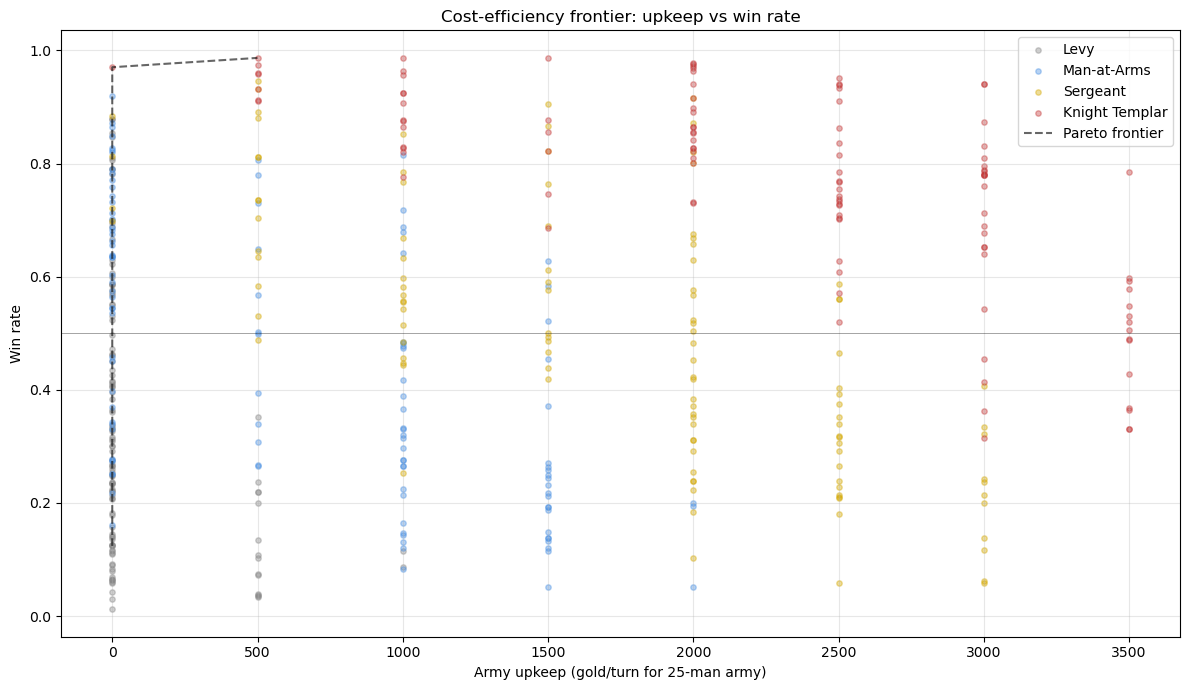


Pareto frontier has 10 loadouts. Top of frontier (highest win rate):
  upkeep=0  wr=0.879  Lev/Cudgel+Longbow/Gothic (TY) [CoAr, RoPa, (SInd, SProw, EPie, NCun),
  upkeep=0  wr=0.879  Lev/Daggers+Longbow/Gothic (TY) [CoAr, RoPa, (SInd, SProw, EPie, NCun)
  upkeep=0  wr=0.919  MaA/Poleaxe+Crossbow/FullPlate (TY) [RoPa, (SInd, SProw, NPie, NCun), 
  upkeep=0  wr=0.970  KT/Bastard+Longbow/Tower/FullPlate (TY) [(EInd, EProw, SPie, NCun), AP
  upkeep=500  wr=0.987  KT/Pike+Longbow/Gothic (TY) [CoAr, (SInd, EProw, SPie, NCun), Enduring

Saved: C:\Users\Matt\OneDrive\Desktop\Game\CE\lab_out\d10_foc10_fat02_par8_dea5a_uns2_imp1\cost-frontier.png


In [107]:
# 4) Cost frontier — scatter of upkeep vs win rate, with the Pareto frontier highlighted
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 7))

# Color by retinue
ret_colors = {'Levy':'#888','Man-at-Arms':'#4a90e2','Sergeant':'#d4a800','Knight Templar':'#c43838'}
for ret, color in ret_colors.items():
    sub = ce[ce['retinue'] == ret]
    ax.scatter(sub['army_upkeep'], sub['win_rate'], c=color, alpha=0.4, s=15, label=ret)

# Pareto frontier: for each upkeep bucket, the best win_rate
ce_sorted = ce.sort_values('army_upkeep')
frontier = []
best_wr = -1
for _, row in ce_sorted.iterrows():
    if row['win_rate'] > best_wr:
        best_wr = row['win_rate']
        frontier.append((row['army_upkeep'], row['win_rate'], row['name']))
fx = [f[0] for f in frontier]
fy = [f[1] for f in frontier]
ax.plot(fx, fy, 'k--', linewidth=1.5, alpha=0.6, label='Pareto frontier')

ax.set_xlabel('Army upkeep (gold/turn for 25-man army)')
ax.set_ylabel('Win rate')
ax.set_title('Cost-efficiency frontier: upkeep vs win rate')
ax.legend()
ax.grid(alpha=0.3)
ax.axhline(0.5, color='black', linewidth=0.5, alpha=0.5)
plt.tight_layout(); plt.show()

print(f"\nPareto frontier has {len(frontier)} loadouts. Top of frontier (highest win rate):")
for x, y, name in frontier[-5:]:
    print(f"  upkeep={x:.0f}  wr={y:.3f}  {name[:70]}")
print(f"\nSaved: {os.path.join(OUT_DIR,'cost-frontier.png')}")

In [108]:
# 5) Effect of specific upkeep-reducing pursuits on cost efficiency
upkeep_pursuits = ['Levy Hall', 'Tannery', 'Armory', 'Joinery', 'Master Workshop',
                   'Gilded Foundry', 'ABF', 'Fletchery', 'Smokehouse', 'Butchery']

rows = []
for p in upkeep_pursuits:
    mask = ce['pursuits'].fillna('').str.contains(rf"(?:^|\|){p}(?:\||$)", regex=True)
    with_p = ce[mask]
    without_p = ce[~mask]
    if len(with_p) >= 5 and len(without_p) >= 5:
        rows.append({
            'pursuit': p,
            'n_with': len(with_p),
            'n_without': len(without_p),
            'avg_upkeep_with': with_p['army_upkeep'].mean(),
            'avg_upkeep_without': without_p['army_upkeep'].mean(),
            'avg_wr_with': with_p['win_rate'].mean(),
            'avg_wr_without': without_p['win_rate'].mean(),
            'avg_wins_per_1k_with': with_p['wins_per_1000_upkeep'].mean(),
            'avg_wins_per_1k_without': without_p['wins_per_1000_upkeep'].mean(),
        })
df_pursuit_cost = pd.DataFrame(rows)
df_pursuit_cost['Δ_wr'] = df_pursuit_cost['avg_wr_with'] - df_pursuit_cost['avg_wr_without']
df_pursuit_cost['Δ_efficiency'] = df_pursuit_cost['avg_wins_per_1k_with'] - df_pursuit_cost['avg_wins_per_1k_without']
print("=== Impact of upkeep-reducing pursuits ===")
print(df_pursuit_cost.round(3).to_string(index=False))
print()
print("Δ_wr near zero means: the pursuit doesn't change which loadouts win, just makes them cheaper.")
print("Δ_efficiency positive means: the pursuit makes loadouts more cost-efficient (more wins per gold).")

=== Impact of upkeep-reducing pursuits ===
        pursuit  n_with  n_without  avg_upkeep_with  avg_upkeep_without  avg_wr_with  avg_wr_without  avg_wins_per_1k_with  avg_wins_per_1k_without  Δ_wr  Δ_efficiency
        Tannery     224        226          687.500            1659.292        0.584           0.427             24281.128                16807.583 0.157      7473.545
         Armory     171        279          505.848            1586.022        0.601           0.446             25292.826                17607.215 0.155      7685.610
        Joinery     123        327          813.008            1311.927        0.583           0.475             25413.072                18690.148 0.108      6722.924
Master Workshop      52        398          625.000            1247.487        0.625           0.489             22921.862                20214.949 0.136      2706.914
 Gilded Foundry     125        325          340.000            1496.923        0.634           0.455             2812

In [109]:
# 6) Replenishment scenarios — given a fixed reserve, how many battles can each loadout fight?
RESERVE_GOLD = 5000   # adjust to test different reserve budgets

ce['battles_per_reserve'] = RESERVE_GOLD / ce['replenishment_cost_per_battle'].clip(lower=1)
ce['effective_wins_per_reserve'] = ce['battles_per_reserve'] * ce['win_rate']

print(f"=== Given a {RESERVE_GOLD} gold reserve, expected wins before reinforcement gold runs out ===")
top_reserve = ce[ce['win_rate'] >= 0.30].nlargest(15, 'effective_wins_per_reserve')[
    ['name','retinue','weapon','win_rate','replenishment_cost_per_battle',
     'battles_per_reserve','effective_wins_per_reserve']
]
print(top_reserve.round(2).to_string(index=False))

=== Given a 5000 gold reserve, expected wins before reinforcement gold runs out ===
                                                                                                                                           name        retinue        weapon  win_rate  replenishment_cost_per_battle  battles_per_reserve  effective_wins_per_reserve
 KT/Bastard+Longbow/Tower/FullPlate (TY) [(EInd, EProw, SPie, NCun), AP -1, Enduring, Florentine, Immune Awkward, ImmU, Rec 6, Serr, Strike +1] Knight Templar Bastard Sword      0.97                            0.0               5000.0                      4852.0
        MaA/Poleaxe+Crossbow/FullPlate (TY) [RoPa, (SInd, SProw, NPie, NCun), AP -1, Florentine, Immune Awkward, ImmU, Nimble, Serr, Strike +1]    Man-at-Arms       Poleaxe      0.92                            0.0               5000.0                      4594.5
                                                            Sgt/Estoc+Longbow/Heater/Gothic (TY) [CoAr, (SInd, EProw, NPie, NCu

# 9. Headline Findings — Design Targets

The key design target was: **win rate tightly correlates with Military Pursuit Count.** Restate and evaluate.

In [110]:
print("=" * 60)
print("DESIGN TARGET CHECK")
print("=" * 60)
print()
print(f"1. MPC ↔ Win Rate correlation:")
print(f"   Pearson r  = {pearson_r:+.3f}  (target: > +0.7 for strong correlation)")
print(f"   Spearman r = {spearman_r:+.3f}")
print()
print(f"2. Higher MPC beats lower MPC?")
print(f"   Average win rate vs lower-MPC opponents: {df_vs['vs_lower_mean'].mean():.3f}")
print(f"   Average win rate vs higher-MPC opponents: {df_vs['vs_higher_mean'].mean():.3f}")
print(f"   Difference: {df_vs['vs_lower_mean'].mean() - df_vs['vs_higher_mean'].mean():+.3f}")
print()
print(f"3. Domain Count independent effect:")
print(f"   Pearson r (raw)  = {pearson_d:+.3f}")
print(f"   Residual r (after MPC removed) = {res_pearson:+.3f}")
print()
print(f"4. Retinue win-rate spread:")
print(f"   Best retinue:  {ret_summary['win_rate'].idxmax():<15} {ret_summary['win_rate'].max():.3f}")
print(f"   Worst retinue: {ret_summary['win_rate'].idxmin():<15} {ret_summary['win_rate'].min():.3f}")
print(f"   Spread:        {ret_summary['win_rate'].max() - ret_summary['win_rate'].min():.3f}")
print()
print(f"5. Decisive vs stalemate balance:")
print(f"   Avg decisive_rate: {df_main_summary['decisive_rate'].mean():.3f}")
print(f"   (target: > 0.7 for meaningful battles)")

DESIGN TARGET CHECK

1. MPC ↔ Win Rate correlation:
   Pearson r  = +0.423  (target: > +0.7 for strong correlation)
   Spearman r = +0.423

2. Higher MPC beats lower MPC?
   Average win rate vs lower-MPC opponents: 0.656
   Average win rate vs higher-MPC opponents: 0.304
   Difference: +0.352

3. Domain Count independent effect:
   Pearson r (raw)  = +0.672
   Residual r (after MPC removed) = +0.566

4. Retinue win-rate spread:
   Best retinue:  Knight Templar  0.766
   Worst retinue: Levy            0.325
   Spread:        0.441

5. Decisive vs stalemate balance:
   Avg decisive_rate: 1.000
   (target: > 0.7 for meaningful battles)


In [111]:
# ──────────────────────────────────────────────────────────────────────────────
# Keyword impact on win rate
# ──────────────────────────────────────────────────────────────────────────────
# For each equipment keyword, measures:
#   (A) Raw split: mean win rate of loadouts that HAVE the keyword vs those that don't.
#   (B) MPC-controlled coefficient: the keyword's marginal effect on win rate after
#       removing MPC, retinue, and tier — so we don't credit a keyword for just
#       co-occurring with high-investment builds.
# A keyword "active" on a loadout = the keyword appears on its weapon, ranged weapon,
# or shield profile.

import numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression
from renown_combat import WEAPONS, RANGED, SHIELDS, ARMORS

# All equipment keywords to test
KEYWORDS = ["Shatter Armor","Destroy Shield","Cleave","Unstoppable","Nimble",
            "Steady","Unwieldy","2H","-1TBH","One Shot","+1TH"]

# Tier helpers
RANGED_TIER = {"Hunting Bow":"Crude","Longbow":"Cast","Javelin":"Wrought","Pilum":"Wrought","Crossbow":"Forged"}
TIER_ORDER  = ["Crude","Cast","Wrought","Forged","Crafted"]
TIER_IDX    = {t:i for i,t in enumerate(TIER_ORDER)}

def loadout_keywords(weapon, ranged, shield):
    """Union of keywords from the loadout's weapon, ranged weapon, and shield."""
    kws = set()
    if pd.notna(weapon) and weapon:
        kws |= set(WEAPONS.get(weapon, {}).get("tags", []))
    if pd.notna(ranged) and ranged:
        kws |= set(RANGED.get(ranged, {}).get("tags", []))
    if pd.notna(shield) and shield:
        kws |= set(SHIELDS.get(shield, {}).get("tags", []))
    return kws

def weapon_tier(weapon, ranged):
    has_melee = pd.notna(weapon) and weapon and weapon != "Farm Tools"
    if not has_melee and pd.notna(ranged) and ranged:
        return RANGED_TIER.get(ranged, "Crude")
    return WEAPONS.get(weapon, {}).get("tier", "Crude")

# Build per-loadout attribute table from matchups (a_* side) + summary win_rate
attrs = df_main_matchups.groupby("a_name").agg(
    retinue=("a_retinue","first"), weapon=("a_weapon","first"),
    shield=("a_shield","first"), armor=("a_armor","first"),
    ranged=("a_ranged","first"), mpc=("a_military_pursuit_count","first"),
).reset_index().rename(columns={"a_name":"name"})
attrs = attrs.merge(df_main_summary[["name","win_rate"]], on="name", how="inner")

# Tag each loadout with its keyword set + tier indices
attrs["kw"]        = attrs.apply(lambda r: loadout_keywords(r["weapon"], r["ranged"], r["shield"]), axis=1)
attrs["wtier_idx"] = attrs.apply(lambda r: TIER_IDX[weapon_tier(r["weapon"], r["ranged"])], axis=1)
attrs["atier_idx"] = attrs["armor"].map(lambda a: TIER_IDX[ARMORS[a]["tier"]] if pd.notna(a) else 0)
for kw in KEYWORDS:
    attrs[f"has_{kw}"] = attrs["kw"].apply(lambda s: kw in s).astype(int)

print(f"Loadouts analyzed: {len(attrs)}\n")

# ── (A) Raw split ──
rows = []
for kw in KEYWORDS:
    has  = attrs[attrs[f"has_{kw}"]==1]
    hasnt= attrs[attrs[f"has_{kw}"]==0]
    if len(has)==0 or len(hasnt)==0:
        continue
    rows.append({
        "keyword": kw, "n_with": len(has),
        "wr_with": has["win_rate"].mean(),
        "wr_without": hasnt["win_rate"].mean(),
        "raw_diff": has["win_rate"].mean() - hasnt["win_rate"].mean(),
        "avg_mpc_with": has["mpc"].mean(),
        "avg_mpc_without": hasnt["mpc"].mean(),
    })
raw = pd.DataFrame(rows).sort_values("raw_diff", ascending=False)

# ── (B) MPC/retinue/tier-controlled coefficients ──
# Single regression: win_rate ~ all keyword dummies + mpc + retinue + weapon_tier + armor_tier.
# Each keyword coefficient = its marginal win-rate effect holding the rest constant.
X_kw   = attrs[[f"has_{kw}" for kw in KEYWORDS]].astype(float)
X_kw.columns = KEYWORDS
X_ret  = pd.get_dummies(attrs["retinue"], prefix="ret", drop_first=True).astype(float)
X_ctrl = pd.concat([attrs[["mpc","wtier_idx","atier_idx"]].astype(float), X_ret], axis=1)
X = pd.concat([X_kw, X_ctrl], axis=1)
y = attrs["win_rate"].values
reg = LinearRegression().fit(X, y)

# Bootstrap CIs for the keyword coefficients
rng = np.random.default_rng(2026); n=len(X); nboot=400
Xa = X.values; boot = np.zeros((nboot, X.shape[1]))
for b in range(nboot):
    idx = rng.integers(0,n,n)
    boot[b] = LinearRegression().fit(Xa[idx], y[idx]).coef_
coef = pd.DataFrame({"feature": X.columns, "coef": reg.coef_,
                     "ci_lo": np.percentile(boot,2.5,axis=0),
                     "ci_hi": np.percentile(boot,97.5,axis=0)})
kw_coef = coef[coef["feature"].isin(KEYWORDS)].copy()
kw_coef["significant"] = (kw_coef["ci_lo"]>0) | (kw_coef["ci_hi"]<0)
kw_coef = kw_coef.sort_values("coef", ascending=False)

# ── Print ──
print("=== (A) RAW SPLIT: win rate with vs without keyword ===")
print("(raw_diff includes MPC confound — see avg_mpc columns)")
print(raw[["keyword","n_with","wr_with","wr_without","raw_diff","avg_mpc_with","avg_mpc_without"]].round(3).to_string(index=False))

print(f"\n=== (B) CONTROLLED EFFECT: marginal win-rate impact (holding MPC/retinue/tier constant) ===")
print(f"Model R² = {reg.score(X,y):.3f}  |  'significant' = 95% bootstrap CI excludes 0")
print(kw_coef[["feature","coef","ci_lo","ci_hi","significant"]].round(3).to_string(index=False))

# ── Plot (B) ──
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,6))
kc = kw_coef.sort_values("coef")
colors = ["#27ae60" if s else "#bbbbbb" for s in kc["significant"]]
yp = np.arange(len(kc))
ax.barh(yp, kc["coef"], xerr=[kc["coef"]-kc["ci_lo"], kc["ci_hi"]-kc["coef"]],
        color=colors, alpha=0.85, capsize=3, ecolor="black")
ax.set_yticks(yp); ax.set_yticklabels(kc["feature"])
ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("Marginal win-rate impact (Δ, MPC/retinue/tier controlled)")
ax.set_title(f"Keyword impact on win rate  |  R²={reg.score(X,y):.3f}\nGreen = statistically significant (CI excludes 0)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "keyword_impact.png"), dpi=110, bbox_inches="tight")
plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'keyword_impact.png')}")

KeyError: None

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Keyword impact via controlled A/B matchups (toggle on/off, same loadout)
# ──────────────────────────────────────────────────────────────────────────────
try:
    import importlib, os, random
    from collections import defaultdict
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    
    import loadouts, playstyles, renown_combat, vectorized_combat
    
    importlib.reload(loadouts)
    importlib.reload(vectorized_combat)
    vectorized_combat.invalidate_tactic_tables()
    from renown_combat import RANGED, SHIELDS, WEAPONS
    
    pool = MAIN_POOL  # reuse the main tournament pool (no regeneration)
    
    # Keywords that live in extra_tags (pursuit/MPC-granted) — these we can toggle directly.
    EXTRA_TAG_KEYWORDS = [
        "Poison",
        "Apothecary Heal",
        "Regenerate",
        "Regenerate 5",
        "Regenerate 4",
        "Regenerate Reroll",
        "Immune Unwieldy",  # only grantable immunity (Tiltyard mastery)
        "GF Armor",
        "MW Weapons",
        "Rend",
        "Steadfast",
        "Drilled",
        "Nimble",
        "Cond Field",
        "Parry",
        "Seize: first",
        "Seize: first_two",
        "Seize: every",
        "Outrider: once",
        "Outrider: first",
        "Outrider: first_two",
        "Outrider: every",
        "Riposte",
    ]
    
    # Build a fixed reference field: a stratified spread of opponents across retinue/tier.
    rng = np.random.default_rng(2026)
    random.seed(2026)
    
    buckets = defaultdict(list)
    for ld in pool:
      buckets[(ld.retinue, ld.military_pursuit_count)].append(ld)
    
    ref_field = []
    for key, lds in buckets.items():
      ref_field.extend(random.sample(lds, min(len(lds), 1)))
    
    if len(ref_field) > 60:
      ref_field = random.sample(ref_field, 60)
    
    ref_field = [
        r._replace(playstyle=playstyles.assign_default_playstyle(r))
        for r in ref_field
    ]
    print(f"Reference field: {len(ref_field)} opponents\n")
    
    
    def field_winrate(ld, field, n_runs=120):
        """Average win rate of `ld` across the whole reference field."""
        # Ensure active tactic tables are fully initialized/built first
        _ = vectorized_combat.get_tactic_tables() 
        
        # Re-assign playstyle and force tactic index update
        ld = ld._replace(playstyle=playstyles.assign_default_playstyle(ld))
        
        wins = total = 0
        for i, opp in enumerate(field):
            if opp.name == ld.name:
                continue
                
            opp = opp._replace(playstyle=playstyles.assign_default_playstyle(opp))
            
            # If your playstyle object stores tactic arrays directly (e.g. opp.playstyle.tactics),
            # ensure custom overrides are passed or re-bound to current table bounds:
            r = vectorized_combat.run_matchup_vec(
                ld, opp, 
                n_runs=n_runs, 
                seed=4242 + i, 
                max_skirmishes=20,
                a_playstyle=ld.playstyle,
                b_playstyle=opp.playstyle
            )
            wins += r["a_wins"]
            total += (
                r["a_wins"] + r["b_wins"] + r["mut_wipe"] + r["indecisive"]
            )
        return wins / total if total else float("nan")
    
    
    rows = []
    for kw in EXTRA_TAG_KEYWORDS:
      carriers = [ld for ld in pool if kw in ld.extra_tags]
      if not carriers:
        continue
    
      # Sample up to N carriers spanning retinues for a representative delta
      sample = random.sample(carriers, min(len(carriers), 12))
      deltas = []
    
      for ld in sample:
        # Ensure playstyle and tactic indices are freshly assigned for with_kw
        with_kw = ld._replace(
            playstyle=playstyles.assign_default_playstyle(ld)
        )
    
        # Remove tag and recompute playstyle based on the updated tag set
        stripped_tags = [t for t in ld.extra_tags if t != kw]
        without_kw = ld._replace(
            extra_tags=stripped_tags,
            playstyle=playstyles.assign_default_playstyle(ld._replace(extra_tags=stripped_tags))
        )
    
        wr_with = field_winrate(with_kw, ref_field)
        wr_without = field_winrate(without_kw, ref_field)
        deltas.append(wr_with - wr_without)
    
      deltas = np.array(deltas)
      rows.append({
          "keyword": kw,
          "n_carriers": len(carriers),
          "n_tested": len(sample),
          "mean_delta": deltas.mean(),
          "median_delta": np.median(deltas),
          "min_delta": deltas.min(),
          "max_delta": deltas.max(),
          "std": deltas.std(),
      })
      print(
          f"  {kw:<20} Δ={deltas.mean():+.3f}  (n={len(sample)}, range"
          f" [{deltas.min():+.3f}, {deltas.max():+.3f}])"
      )
    
    res = pd.DataFrame(rows).sort_values("mean_delta", ascending=False)
    print(
        "\n=== Keyword isolated win-rate impact (toggle on vs off, same loadout,"
        " vs fixed field) ==="
    )
    print(
        res[[
            "keyword",
            "n_carriers",
            "n_tested",
            "mean_delta",
            "median_delta",
            "min_delta",
            "max_delta",
        ]]
        .round(3)
        .to_string(index=False)
    )
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    rs = res.sort_values("mean_delta")
    ax.barh(
        range(len(rs)),
        rs["mean_delta"],
        xerr=[rs["mean_delta"] - rs["min_delta"], rs["max_delta"] - rs["mean_delta"]],
        color="#2980b9",
        alpha=0.8,
        capsize=3,
        ecolor="gray",
    )
    ax.set_yticks(range(len(rs)))
    ax.set_yticklabels(rs["keyword"])
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlabel("Isolated win-rate impact (with keyword − without)")
    ax.set_title(
        "Keyword impact via controlled A/B toggle\n(error bars = min/max across"
        " tested carriers)"
    )
    plt.tight_layout()
    
    out_path = (
        os.path.join(OUT_DIR, "keyword_ab_impact.png")
        if "OUT_DIR" in globals()
        else "keyword_ab_impact.png"
    )
    plt.savefig(out_path, dpi=110, bbox_inches="tight")
    plt.show()
    print(f"\nSaved: {out_path}")
except:
    print("fail")

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Ranged weapons performance analysis
# ──────────────────────────────────────────────────────────────────────────────
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from renown_combat import WEAPONS, RANGED, ARMORS

def ranged_role(weapon, ranged):
    has_melee  = weapon is not None and weapon != "" and weapon != "Farm Tools"
    has_ranged = ranged is not None and ranged != ""
    if has_ranged and not has_melee: return "pure-ranged"
    if has_ranged and has_melee:     return "dual-equip"
    return "melee-only"

m = df_main_matchups.copy()

# Vectorized role tagging: classify each UNIQUE (weapon, ranged) combo once, map back.
def _role_col(df, w, r):
    wn = df[w].where(df[w].notna() & (df[w] != ""), None)
    rn = df[r].where(df[r].notna() & (df[r] != ""), None)
    combo = pd.DataFrame({"w": wn, "r": rn})
    uniq = combo.drop_duplicates().copy()
    uniq["role"] = [ranged_role(x.w, x.r) for x in uniq.itertuples(index=False)]
    return combo.merge(uniq, on=["w","r"], how="left")["role"].values

m["a_role"] = _role_col(m, "a_weapon", "a_ranged")
m["b_role"] = _role_col(m, "b_weapon", "b_ranged")
m["n"]      = m["a_wins"] + m["b_wins"] + m["mut_wipe"] + m["indecisive"]

# Armor tier via unique-value map (a_armor is categorical now — .astype(object) first).
TIER_IDX = {"Crude":0,"Cast":1,"Wrought":2,"Forged":3,"Crafted":4}
def _atier(col):
    s = m[col].astype("object")
    return s.map(lambda a: TIER_IDX.get(ARMORS.get(a, {}).get("tier", "Crude"), 0) if pd.notna(a) else 0)
m["a_atier"] = _atier("a_armor")
m["b_atier"] = _atier("b_armor")

# ── A. Role aggregate ──
print("=== A. Role aggregate (whole-field win rate by ranged role) ===")
agg = m.groupby("a_role", observed=True).agg(
    n_battles=("n","sum"), wins=("a_wins","sum"), losses=("b_wins","sum"),
    mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
agg["win_rate"]    = agg["wins"]/agg["n_battles"]
agg["decisive_wr"] = agg["wins"]/(agg["wins"]+agg["losses"]).clip(lower=1)
agg["mut_pct"]     = agg["mut"]/agg["n_battles"]
agg["indec_pct"]   = agg["indec"]/agg["n_battles"]
print(agg.sort_values("win_rate", ascending=False)[["a_role","n_battles","win_rate","decisive_wr","mut_pct","indec_pct"]].round(3).to_string(index=False))

# ── B. Per-ranged-weapon performance ──
print("\n=== B. Per-ranged-weapon win rate (loadouts carrying each ranged weapon) ===")
ranged_only = m[m["a_ranged"].notna() & (m["a_ranged"] != "")].copy()
per_rw = ranged_only.groupby("a_ranged", observed=True).agg(
    n_loadouts=("a_name","nunique"), n_battles=("n","sum"),
    wins=("a_wins","sum"), losses=("b_wins","sum"),
    mut=("mut_wipe","sum"), indec=("indecisive","sum")).reset_index()
per_rw["win_rate"]    = per_rw["wins"]/per_rw["n_battles"]
per_rw["decisive_wr"] = per_rw["wins"]/(per_rw["wins"]+per_rw["losses"]).clip(lower=1)
per_rw["mut_pct"]     = per_rw["mut"]/per_rw["n_battles"]
per_rw = per_rw[per_rw["n_battles"] > 0]
print(per_rw.sort_values("win_rate", ascending=False)[
    ["a_ranged","n_loadouts","n_battles","win_rate","decisive_wr","mut_pct"]].round(3).to_string(index=False))

# ── C. Ranged vs defender armor tier ──
print("\n=== C. Ranged carrier win rate vs defender armor tier ===")
TIER_NAME = {0:"Crude/Cloth", 1:"Cast/Leather", 2:"Wrought/Chain", 3:"Forged/Full", 4:"Crafted/Gothic"}
vs_armor = ranged_only.groupby(["a_ranged","b_atier"], observed=True).agg(
    n=("n","sum"), wins=("a_wins","sum")).reset_index()
vs_armor["wr"] = vs_armor["wins"]/vs_armor["n"]
vs_armor_pivot = vs_armor.pivot(index="a_ranged", columns="b_atier", values="wr").dropna(how="all")
vs_armor_pivot.columns = [TIER_NAME.get(c, c) for c in vs_armor_pivot.columns]
print(vs_armor_pivot.round(3).to_string())

# ── D. By retinue × role ──
print("\n=== D. Ranged role win rate by retinue ===")
ret_role = m.groupby(["a_retinue","a_role"], observed=True).agg(
    n=("n","sum"), wins=("a_wins","sum")).reset_index()
ret_role["wr"] = ret_role["wins"]/ret_role["n"]
print(ret_role.pivot(index="a_retinue", columns="a_role", values="wr").round(3).to_string())

# ── E. Tiltyard dual-equip ROI ──
print("\n=== E. Tiltyard dual-equip ROI: dual-equip vs melee-only at same MPC ===")
role_mpc = m.groupby(["a_role","a_military_pursuit_count"], observed=True).agg(
    n=("n","sum"), wins=("a_wins","sum")).reset_index()
role_mpc["wr"] = role_mpc["wins"]/role_mpc["n"]
roi_pivot = role_mpc.pivot(index="a_military_pursuit_count", columns="a_role", values="wr")
roi_pivot["dual_minus_melee"] = roi_pivot.get("dual-equip", 0) - roi_pivot.get("melee-only", 0)
print(roi_pivot.round(3).to_string())

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
field_mean = m["a_wins"].sum()/m["n"].sum()
sub = per_rw.sort_values("win_rate")
axes[0].barh(range(len(sub)), sub["win_rate"], color="#4a90e2", alpha=0.85)
axes[0].set_yticks(range(len(sub))); axes[0].set_yticklabels(sub["a_ranged"])
axes[0].axvline(field_mean, color="red", ls="--", lw=1, label=f"field mean {field_mean:.2f}")
axes[0].set_xlabel("Win rate"); axes[0].set_title("Win rate by ranged weapon"); axes[0].legend()

hm = vs_armor_pivot.values
im = axes[1].imshow(hm, cmap="RdYlGn", vmin=0, vmax=0.5, aspect="auto")
axes[1].set_xticks(range(hm.shape[1])); axes[1].set_xticklabels(vs_armor_pivot.columns, rotation=30, ha="right")
axes[1].set_yticks(range(hm.shape[0])); axes[1].set_yticklabels(vs_armor_pivot.index)
axes[1].set_title("Ranged weapon win rate vs defender armor")
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        if not np.isnan(hm[i,j]):
            axes[1].text(j, i, f"{hm[i,j]:.2f}", ha="center", va="center", fontsize=9,
                         color="white" if (hm[i,j]<0.2 or hm[i,j]>0.4) else "black")
plt.colorbar(im, ax=axes[1], label="Win rate", shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ranged_analysis.png"), dpi=110, bbox_inches="tight")
plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'ranged_analysis.png')}")

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Per-skirmish casualty analysis — first 3 skirmishes (with shake & waver split)
# ──────────────────────────────────────────────────────────────────────────────
# Total casualties + first/second-striker split (as before), PLUS per-cause breakdown:
# combat vs shake (exhaustion) vs waver (>5 heavy-loss morale break), per skirmish.
# REQUIRES vectorized_combat.py with per-cause skirmish_log (a_combat/a_shake/a_waver).
import numpy as np, pandas as pd, random
import importlib, loadouts, vectorized_combat, playstyles
importlib.reload(loadouts); importlib.reload(vectorized_combat)
vectorized_combat.invalidate_tactic_tables()
pool = MAIN_POOL
random.seed(2026)
from collections import defaultdict
by_ret = defaultdict(list)
for ld in pool: by_ret[ld.retinue].append(ld)
sample = []
for ret, lds in by_ret.items():
    sample.extend(random.sample(lds, min(len(lds), 15)))
sample = [ld._replace(playstyle=playstyles.assign_default_playstyle(ld)) for ld in sample]
pairs = [(i,j) for i in range(len(sample)) for j in range(len(sample)) if i!=j]
random.shuffle(pairs); pairs = pairs[:1500]
N_RUNS = 100
print(f"{len(sample)} loadouts, {len(pairs)} matchups × {N_RUNS} runs, logging first 3 skirmishes...\n")

# total-casualty records (back-compat) + per-cause records
records = {1: {"cas": [], "first": []}, 2: {"cas": [], "first": []}, 3: {"cas": [], "first": []}}
cause   = {sk: {"combat": [], "shake": [], "waver": []} for sk in (1,2,3)}
for (i,j) in pairs:
    a, b = sample[i], sample[j]
    r = vectorized_combat_d10.run_matchup_vec(a, b, n_runs=N_RUNS, max_skirmishes=20,
                                          seed=1000+i*97+j, log_skirmishes=3)
    for e in r["skirmish_log"]:
        sk = e["skirmish"]; act = e["active"]
        a_first = (e["first_striker"][act] == 1); b_first = (e["first_striker"][act] == -1)
        records[sk]["cas"].append(e["a_casualties"][act]); records[sk]["first"].append(a_first)
        records[sk]["cas"].append(e["b_casualties"][act]); records[sk]["first"].append(b_first)
        for side in ("a","b"):
            cause[sk]["combat"].append(e[f"{side}_combat"][act])
            cause[sk]["shake"].append(e[f"{side}_shake"][act])
            cause[sk]["waver"].append(e[f"{side}_waver"][act])

rows = []
for sk in (1,2,3):
    cas   = np.concatenate(records[sk]["cas"]); first = np.concatenate(records[sk]["first"])
    cas_f = cas[first]; cas_s = cas[~first]
    rows.append({
        "skirmish": sk, "n_obs": len(cas),
        "mean_cas": cas.mean(), "median_cas": np.median(cas),
        "pct_over_5": 100*(cas>5).mean(), "pct_over_10": 100*(cas>10).mean(),
        "p90": np.percentile(cas,90), "max": cas.max(),
        "mean_if_first": cas_f.mean() if len(cas_f) else np.nan,
        "mean_if_second": cas_s.mean() if len(cas_s) else np.nan,
        "pct>5_first": 100*(cas_f>5).mean() if len(cas_f) else np.nan,
        "pct>5_second": 100*(cas_s>5).mean() if len(cas_s) else np.nan,
    })
res = pd.DataFrame(rows)

# per-cause summary
cz = []
for sk in (1,2,3):
    c = np.concatenate(cause[sk]["combat"]); s = np.concatenate(cause[sk]["shake"]); w = np.concatenate(cause[sk]["waver"])
    cz.append({"skirmish": sk,
               "combat_mean": c.mean(), "shake_mean": s.mean(), "waver_mean": w.mean(),
               "pct_any_shake": 100*(s>0).mean(), "pct_any_waver": 100*(w>0).mean()})
czdf = pd.DataFrame(cz)

print("=== Per-skirmish casualties (per side, first 3 skirmishes) ===")
print(res[["skirmish","n_obs","mean_cas","median_cas","pct_over_5","pct_over_10","p90","max"]].round(2).to_string(index=False))
print("\n=== First-striker vs second-striker casualties taken ===")
print(res[["skirmish","mean_if_first","mean_if_second","pct>5_first","pct>5_second"]].round(2).to_string(index=False))
print("\n=== Casualties by CAUSE per skirmish (mean per side) ===")
print(czdf.round(2).to_string(index=False))

print("\n=== Casualty-count distribution per skirmish (% of side-observations) ===")
dist_rows = []
for sk in (1,2,3):
    cas = np.concatenate(records[sk]["cas"])
    dist_rows.append({"skirmish": sk,
        "0":   round(100*(cas==0).mean(),1), "1-2": round(100*((cas>=1)&(cas<=2)).mean(),1),
        "3-5": round(100*((cas>=3)&(cas<=5)).mean(),1), "6-10":round(100*((cas>=6)&(cas<=10)).mean(),1),
        ">10": round(100*(cas>10).mean(),1)})
print(pd.DataFrame(dist_rows).to_string(index=False))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(17,5))

# panel 1: stacked mean casualties by cause (combat / shake / waver)
x = np.arange(3)
ax = axes[0]
ax.bar(x, czdf["combat_mean"], 0.6, label="Combat", color="#c43838")
ax.bar(x, czdf["shake_mean"], 0.6, bottom=czdf["combat_mean"], label="Shaken", color="#d4a800")
ax.bar(x, czdf["waver_mean"], 0.6, bottom=czdf["combat_mean"]+czdf["shake_mean"], label="Waver", color="#e07b39")
ax.set_xticks(x); ax.set_xticklabels([f"Sk {s}" for s in (1,2,3)])
ax.set_ylabel("Mean casualties taken / side"); ax.set_title("Casualties by cause per skirmish"); ax.legend()

# panel 2: how often shake vs waver fires per skirmish
ax = axes[1]; w = 0.35
ax.bar(x-w/2, czdf["pct_any_shake"], w, label="any Shaken loss", color="#d4a800")
ax.bar(x+w/2, czdf["pct_any_waver"], w, label="any Waver loss", color="#e07b39")
ax.set_xticks(x); ax.set_xticklabels([f"Sk {s}" for s in (1,2,3)])
ax.set_ylabel("% of side-skirmishes"); ax.set_title("How often Shaken vs Waver fires"); ax.legend()
for idx in range(3):
    ax.text(idx-w/2, czdf["pct_any_shake"][idx]+0.5, f"{czdf['pct_any_shake'][idx]:.0f}%", ha="center", fontsize=8)
    ax.text(idx+w/2, czdf["pct_any_waver"][idx]+0.5, f"{czdf['pct_any_waver'][idx]:.0f}%", ha="center", fontsize=8)

# panel 3: losing >5 / >10 (total), as before
ax = axes[2]
ax.bar([f"Sk {r['skirmish']}" for r in rows], [r["pct_over_5"] for r in rows], color="#e67e22", alpha=.85, label=">5")
ax.bar([f"Sk {r['skirmish']}" for r in rows], [r["pct_over_10"] for r in rows], color="#c0392b", alpha=.9, label=">10")
ax.set_ylabel("% of side-skirmishes"); ax.set_title("Losing >5 / >10 in a skirmish"); ax.legend()
for idx,r in enumerate(rows):
    ax.text(idx, r["pct_over_5"]+0.5, f"{r['pct_over_5']:.0f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_skirmish_casualties.png"), dpi=110, bbox_inches="tight")
plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR,'per_skirmish_casualties.png')}")

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Rend value — controlled A/B comparison
# ──────────────────────────────────────────────────────────────────────────────
# NOTE: the -1 AP "MW Weapons" mechanic is retired. Master Workshop MASTERY now grants Rend
# directly (and ABF grants it too). So this tests Rend vs NO-Rend on the same builds.
# Rend raises the defender's regen save threshold, so it should matter most vs the
# regen-carrying opponents. Reports overall delta AND a regen-only breakout.

import numpy as np, pandas as pd, random
import importlib, loadouts, renown_combat, vectorized_combat, playstyles
importlib.reload(loadouts); importlib.reload(renown_combat); importlib.reload(vectorized_combat); importlib.reload(playstyles)
vectorized_combat.invalidate_tactic_tables()

pool = MAIN_POOL   # reuse the main tournament pool (no regeneration)
random.seed(2026)

from collections import defaultdict
by_ret = defaultdict(list)
for ld in pool: by_ret[ld.retinue].append(ld)
field = []
for ret, lds in by_ret.items():
    field.extend(random.sample(lds, min(len(lds), 14)))
field = [f._replace(playstyle=playstyles.assign_default_playstyle(f)) for f in field]
regen_field = [f for f in field if any('Regenerate' in t for t in f.extra_tags)]
print(f"Field: {len(field)} opponents ({len(regen_field)} carry Regenerate — Rend's targets)\n")

def field_wr(ld, opponents, n=100):
    ld = ld._replace(playstyle=playstyles.assign_default_playstyle(ld))
    w = t = 0
    for i, opp in enumerate(opponents):
        if opp.name == ld.name: continue
        r = vectorized_combat.run_matchup_vec(ld, opp, n_runs=n, seed=900+i)
        w += r['a_wins']; t += r['a_wins']+r['b_wins']+r['mut_wipe']+r['indecisive']
    return w/t if t else float('nan')

def strip_rend(ld):
    """Clone a Rend build with Rend removed — the baseline to measure Rend's value."""
    p = set(ld.pursuits); p.discard('MWRend')
    tags = [t for t in ld.extra_tags if t != 'Rend']
    return ld._replace(pursuits=frozenset(p), extra_tags=tags, name=ld.name + '/noRend')

# Builds that carry Rend via MWRend (exclude ABF — its Rend is bundled with other effects)
rend_builds = [ld for ld in pool if 'MWRend' in ld.pursuits and 'ABF' not in ld.pursuits]
print(f"MWRend (non-ABF) builds: {len(rend_builds)}")
if not rend_builds:
    print("No MWRend builds found — nothing to test."); 
else:
    sample = random.sample(rend_builds, min(30, len(rend_builds)))
    rows = []
    for ld in sample:
        wr_rend = field_wr(ld, field)
        wr_base = field_wr(strip_rend(ld), field)
        rows.append({"weapon": ld.weapon or ld.ranged, "retinue": ld.retinue, "mpc": ld.military_pursuit_count,
                     "wr_noRend": wr_base, "wr_Rend": wr_rend, "delta": wr_rend - wr_base})
    df = pd.DataFrame(rows)

    print("\n=== Rend vs no-Rend — same builds, full field ===")
    print(df.sort_values("delta", ascending=False).round(3).to_string(index=False))
    print(f"\nMean: noRend={df['wr_noRend'].mean():.3f}  Rend={df['wr_Rend'].mean():.3f}  Δ={df['delta'].mean():+.4f}")
    print(f"Builds where Rend helps: {(df['delta']>0).sum()}/{len(df)}")

    if regen_field:
        print(f"\n=== Targeted: same builds vs ONLY the {len(regen_field)} regen opponents ===")
        r2 = []
        for ld in random.sample(rend_builds, min(15, len(rend_builds))):
            r2.append({"weapon": ld.weapon or ld.ranged,
                       "wr_noRend": field_wr(strip_rend(ld), regen_field, n=150),
                       "wr_Rend": field_wr(ld, regen_field, n=150)})
        d2 = pd.DataFrame(r2); d2['delta'] = d2['wr_Rend'] - d2['wr_noRend']
        print(d2.sort_values("delta", ascending=False).round(3).to_string(index=False))
        print(f"vs regen opponents: noRend={d2['wr_noRend'].mean():.3f}  Rend={d2['wr_Rend'].mean():.3f}  Δ={d2['delta'].mean():+.4f}")

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ds = df.sort_values("delta")
    colors = ["#27ae60" if d > 0 else "#c0392b" for d in ds["delta"]]
    axes[0].barh(range(len(ds)), ds["delta"], color=colors, alpha=0.85)
    axes[0].set_yticks(range(len(ds))); axes[0].set_yticklabels([f"{w} ({r[:3]})" for w,r in zip(ds["weapon"],ds["retinue"])], fontsize=8)
    axes[0].axvline(0, color="black", lw=0.5)
    axes[0].set_xlabel("Δ win rate (Rend − noRend)"); axes[0].set_title("Per-build: Rend value (full field)\ngreen = Rend better")
    axes[1].scatter(df["wr_noRend"], df["wr_Rend"], c=df["mpc"], cmap="viridis", s=60, alpha=0.8)
    lims = [min(df["wr_noRend"].min(), df["wr_Rend"].min()), max(df["wr_noRend"].max(), df["wr_Rend"].max())]
    axes[1].plot(lims, lims, "k--", lw=0.5, label="equal")
    axes[1].set_xlabel("no-Rend win rate"); axes[1].set_ylabel("Rend win rate")
    axes[1].set_title("Rend vs noRend (points above line = Rend better)"); axes[1].legend()
    plt.colorbar(axes[1].collections[0], ax=axes[1], label="MPC")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "rend_value.png"), dpi=110, bbox_inches="tight")
    plt.show()
    print(f"\nSaved: {os.path.join(OUT_DIR,'rend_value.png')}")

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Initiative impact analysis
# ──────────────────────────────────────────────────────────────────────────────
#   A. Raw: win rate by base-initiative advantage (head-to-head pool sample)
#   B. Equipment init: sweep a weapon's init, measure win-rate slope
#   C. Tactics: Charge-priority vs neutral playstyle
#   D. Nimble: toggle Nimble on/off (first-skirmish +1 init)
#   E. Seize: toggle the Ministry "Seize: first" tag (innate), measure first-move edge
try:
    import numpy as np, pandas as pd, random
    import importlib, loadouts, renown_combat, vectorized_combat, playstyles
    importlib.reload(loadouts); importlib.reload(renown_combat); importlib.reload(vectorized_combat); importlib.reload(playstyles)
    vectorized_combat.invalidate_tactic_tables()
    from loadouts import Loadout, is_2h
    
    pool = MAIN_POOL   # reuse the main tournament pool (no regeneration)
    random.seed(2026)
    
    def winrate(a, b, n=300, seed=7):
        a = a._replace(playstyle=playstyles.assign_default_playstyle(a)) if a.playstyle is None else a
        b = b._replace(playstyle=playstyles.assign_default_playstyle(b)) if b.playstyle is None else b
        r = vectorized_combat.run_matchup_vec(a, b, n_runs=n, seed=seed, max_skirmishes=20)
        tot = r['a_wins']+r['b_wins']+r['mut_wipe']+r['indecisive']
        return (r['a_wins']/tot if tot else float('nan')), (r['mut_wipe']/tot if tot else float('nan'))
    
    SIZE=25
    def chassis(weapon, shield, armor='Chainmail', ranged=None, extra=None, playstyle=None):
        return Loadout(name=f"{weapon or ranged}/{shield}", retinue='Man-at-Arms', weapon=weapon,
                       shield=shield, armor=armor, ranged=ranged, has_tiltyard=False, size=SIZE,
                       extra_tags=extra or ['Cond Field'], upkeep_per_retinue=30, playstyle=playstyle,
                       tiltyard_mastery=False, pursuits=frozenset(['Coliseum']),
                       military_pursuit_count=5, domain_count=0)
    
    # ── A. Does higher base initiative win? ──
    def base_init(ld):
        if ld.weapon and ld.weapon!='Farm Tools': wi=renown_combat.WEAPONS[ld.weapon]['init']
        elif ld.ranged: wi=renown_combat.RANGED[ld.ranged]['init']
        else: wi=0
        si=renown_combat.SHIELDS[ld.shield]['init'] if ld.shield else 0
        return wi+si
    
    sample = [s._replace(playstyle=playstyles.assign_default_playstyle(s)) for s in random.sample(pool, 60)]
    init_diff_wr = {}
    for i in range(len(sample)):
        for j in range(i+1, len(sample)):
            a,b = sample[i], sample[j]
            di = base_init(a)-base_init(b)
            wr,_ = winrate(a,b,n=120,seed=100+i*60+j)
            init_diff_wr.setdefault(di, []).append(wr)
    print("=== A. Win rate by base-initiative advantage ===")
    print(pd.DataFrame([{"init_advantage":d,"n":len(v),"win_rate":np.mean(v)} for d,v in sorted(init_diff_wr.items())]).round(3).to_string(index=False))
    
    # ── B. Equipment init slope ──
    print("\n=== B. Equipment init slope (Arming Sword swept -2..+2, vs fixed Halberd) ===")
    opp = chassis('Halberd', None)
    orig = renown_combat.WEAPONS['Arming Sword']['init']
    brows=[]
    for test_init in [-2,-1,0,1,2]:
        renown_combat.WEAPONS['Arming Sword']['init']=test_init
        vectorized_combat.invalidate_tactic_tables()
        wr,mut = winrate(chassis('Arming Sword','Kite Shield'),opp,n=400,seed=55)
        brows.append({"weapon_init":test_init,"base_init_w_shield":test_init-1,"win_rate":wr,"mut_pct":mut})
    renown_combat.WEAPONS['Arming Sword']['init']=orig
    vectorized_combat.invalidate_tactic_tables()
    print(pd.DataFrame(brows).round(3).to_string(index=False))
    
    # ── C. Tactic-driven init ──
    print("\n=== C. Tactic-driven init: playstyle vs fixed defender ===")
    opp = chassis('Arming Sword','Kite Shield')
    crows=[]
    for ps in ['Aggressor','Cautious','Defender','Berserker','Skirmisher']:
        wr,mut = winrate(chassis('Arming Sword','Kite Shield', playstyle=ps),opp,n=400,seed=88)
        crows.append({"playstyle":ps,"win_rate":wr,"mut_pct":mut})
    print(pd.DataFrame(crows).sort_values("win_rate",ascending=False).round(3).to_string(index=False))
    
    # ── D. Nimble toggle ──
    print("\n=== D. Nimble impact (+1 init first skirmish) ===")
    drows=[]
    for wpn in ['Daggers','Short Sword']:
        if 'Nimble' not in renown_combat.WEAPONS[wpn]['tags']: continue
        opp = chassis('Arming Sword','Kite Shield')
        sh = None if is_2h(wpn) else 'Kite Shield'
        atk = chassis(wpn, sh, armor='Leather')
        wr_on,_ = winrate(atk,opp,n=400,seed=33)
        orig_tags = renown_combat.WEAPONS[wpn]['tags'][:]
        renown_combat.WEAPONS[wpn]['tags']=[t for t in orig_tags if t!='Nimble']
        vectorized_combat.invalidate_tactic_tables()
        wr_off,_ = winrate(atk,opp,n=400,seed=33)
        renown_combat.WEAPONS[wpn]['tags']=orig_tags; vectorized_combat.invalidate_tactic_tables()
        drows.append({"weapon":wpn,"wr_with_nimble":wr_on,"wr_without":wr_off,"nimble_delta":wr_on-wr_off})
    print(pd.DataFrame(drows).round(3).to_string(index=False))
    
    # ── E. Seize the Initiative (toggle the actual Seize tags) ──
    # FIXED: old version used attacker_mode="attacker"/"defender" (invalid → both fell to the
    # balanced split → identical matchups). Seize is driven by "Seize: first"/"Seize: every".
    print("\n=== E. Seize the Initiative (toggle Ministry Seize tags) ===")
    opp  = chassis('Arming Sword','Kite Shield')
    base = chassis('War Hammer', None, playstyle='Aggressor')   # init -1: benefits most
    wr_none,_  = winrate(base, opp, n=600, seed=11)
    wr_first,_ = winrate(base._replace(extra_tags=base.extra_tags+['Seize: first']), opp, n=600, seed=11)
    wr_every,_ = winrate(base._replace(extra_tags=base.extra_tags+['Seize: first_two']), opp, n=600, seed=11)
    both,_     = winrate(base._replace(extra_tags=base.extra_tags+['Seize: first']),
                         opp._replace(extra_tags=opp.extra_tags+['Seize: first']), n=600, seed=11)
    print(f"  War Hammer (init -1) vs Arming Sword:")
    print(f"    No Seize:      {wr_none:.3f}")
    print(f"    Seize: first   {wr_first:.3f}  (Δ {wr_first-wr_none:+.3f})")
    print(f"    Seize: fist two  {wr_every:.3f}  (Δ {wr_every-wr_none:+.3f})")
    print(f"    Both have it:  {both:.3f}  (≈ No-Seize {wr_none:.3f}: mutual cancel)")
    fast = chassis('Lance','Kite Shield', playstyle='Cavalry')   # init +1: benefits least
    fn,_ = winrate(fast, opp, n=600, seed=11)
    fe,_ = winrate(fast._replace(extra_tags=fast.extra_tags+['Seize: every']), opp, n=600, seed=11)
    print(f"  Lance (init +1): No Seize {fn:.3f} → Seize:every {fe:.3f}  (Δ {fe-fn:+.3f}, expect small)")
    
    # ── Plot: A (headline) ──
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8,5))
    dfA = pd.DataFrame([{"init_advantage":d,"win_rate":np.mean(v)} for d,v in sorted(init_diff_wr.items()) if len(v)>=5])
    ax.plot(dfA["init_advantage"], dfA["win_rate"], marker="o", color="#2980b9")
    ax.axhline(0.5, color="gray", ls="--", lw=1); ax.axvline(0, color="gray", ls=":", lw=1)
    ax.set_xlabel("Base initiative advantage"); ax.set_ylabel("Win rate")
    ax.set_title("Win rate vs initiative advantage (threshold effect at 0)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR,"initiative_analysis.png"), dpi=110, bbox_inches="tight"); plt.show()
    print(f"\nSaved: {os.path.join(OUT_DIR,'initiative_analysis.png')}")
except:
    print("fail")

In [ ]:
# Initiative i1 x i2 surface — AP/weapon identical on both sides (pure init isolation).
import importlib, renown_combat, loadouts, vectorized_combat, playstyles
import numpy as np, pandas as pd, matplotlib.pyplot as plt
for _m in [renown_combat, loadouts, vectorized_combat, playstyles]: importlib.reload(_m)

# Two clone weapons: identical AP/tags (based on Arming Sword: AP -2, Steady, +1TH); only
# init is set per cell. A uses _initA, B uses _initB, so each side's init is independent.
_BASE_TAGS = ["Steady", "+1TH"]; _BASE_AP = -2
renown_combat.WEAPONS["_initA"] = {"ap": _BASE_AP, "init": 0, "tags": list(_BASE_TAGS), "tier": "Wrought"}
renown_combat.WEAPONS["_initB"] = {"ap": _BASE_AP, "init": 0, "tags": list(_BASE_TAGS), "tier": "Wrought"}

def _mk(name, weap):
    return loadouts.Loadout(name=name, retinue="Man-at-Arms", weapon=weap, shield=None,
        armor="Chainmail", ranged=None, has_tiltyard=False, size=25, extra_tags=["Cond Field"],
        upkeep_per_retinue=30, playstyle="Defender", tiltyard_mastery=False,
        pursuits=frozenset(["Conditioning Field"]), military_pursuit_count=5, domain_count=0)

INITS = [-3, -2, -1, 0, 1, 2, 3]
_A, _B = _mk("A", "_initA"), _mk("B", "_initB")
grid = np.full((len(INITS), len(INITS)), np.nan)
for ia, va in enumerate(INITS):
    for ib, vb in enumerate(INITS):
        renown_combat.WEAPONS["_initA"]["init"] = va
        renown_combat.WEAPONS["_initB"]["init"] = vb
        vectorized_combat.invalidate_tactic_tables()
        r = vectorized_combat.run_matchup_vec(_A, _B, n_runs=400, seed=100+ia*7+ib,
                a_playstyle="Defender", b_playstyle="Defender", alternate_attacker=False)
        t = r["a_wins"]+r["b_wins"]+r["mut_wipe"]+r["indecisive"]
        grid[ia, ib] = r["a_wins"]/t if t else np.nan
del renown_combat.WEAPONS["_initA"], renown_combat.WEAPONS["_initB"]
vectorized_combat.invalidate_tactic_tables()

df_grid = pd.DataFrame(grid, index=[f"A={i}" for i in INITS], columns=[f"B={i}" for i in INITS])
print("A win rate by (A init rows x B init cols) - same AP/weapon both sides:")
print(df_grid.round(3).to_string())

# Gap collapse over the SAFE region (neither side tripped: both >= -1).
gaps = {}
for ia, va in enumerate(INITS):
    for ib, vb in enumerate(INITS):
        if va >= -1 and vb >= -1:
            gaps.setdefault(va - vb, []).append(grid[ia, ib])
gap_x = sorted(gaps)
gap_y = [np.mean(gaps[g]) for g in gap_x]
print("\nInit gap (A-B) -> mean A win rate (safe region, both >= -1):")
for g, y in zip(gap_x, gap_y):
    print(f"  gap {g:+d}: {y:.3f}")

# ── Two-panel plot ──
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: heatmap
im = ax1.imshow(grid, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto", origin="lower")
ax1.set_xticks(range(len(INITS))); ax1.set_xticklabels(INITS)
ax1.set_yticks(range(len(INITS))); ax1.set_yticklabels(INITS)
ax1.set_xlabel("B initiative"); ax1.set_ylabel("A initiative")
ax1.set_title("A win-rate surface (AP/weapon identical)\ncliff: tripped side (init <= -2) auto-loses")
for ia in range(len(INITS)):
    for ib in range(len(INITS)):
        v = grid[ia, ib]
        ax1.text(ib, ia, f"{v:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if (v < 0.25 or v > 0.7) else "black")
ax1.axhline(INITS.index(-2)+0.5, color="#c0392b", lw=1.2, ls="--")
ax1.axvline(INITS.index(-2)+0.5, color="#c0392b", lw=1.2, ls="--")
plt.colorbar(im, ax=ax1, label="A win rate", shrink=0.85)

# Panel 2: gap curve (the corrected "init advantage" chart)
ax2.plot(gap_x, gap_y, marker="o", color="#2c7fb8", lw=2)
ax2.axhline(0.5, color="gray", ls=":", lw=1)
ax2.axvline(0, color="gray", ls=":", lw=1)
_ylo = max(0.0, min(gap_y) - 0.05); _yhi = max(gap_y) + 0.05
ax2.set_ylim(_ylo, _yhi)
ax2.set_xlabel("Initiative gap (A init - B init)")
ax2.set_ylabel("A win rate")
ax2.set_title("Init gap -> win rate (safe region, no AP confound)\nnot flat: ~0.11/step, saturates past +-2")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "initiative_grid.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR, 'initiative_grid.png')}")

In [ ]:
# Tactic x Tactic matrix for a fixed WEAPON pairing.
# "Player A has weapon_a + tactic_x, Player B has weapon_b + tactic_y" for all tactic pairs.
# Tactics are FORCED pure (one-hot) so each cell is a clean single-tactic-vs-single-tactic read.
import importlib, renown_combat, loadouts, vectorized_combat, playstyles
import numpy as np, pandas as pd, matplotlib.pyplot as plt
for _m in [renown_combat, loadouts, vectorized_combat, playstyles]: importlib.reload(_m)
from renown_combat import TACTICS

# ── CONFIGURE ──
WEAPON_A = "Bastard Sword"      # Player A's weapon
WEAPON_B = "Poleaxe"    # Player B's weapon
ARMOR_A, ARMOR_B = "Gothic Plate", "Gothic Plate"
SHIELD_A, SHIELD_B = "Heater Shield", None
N_RUNS = 400

# Register pure forced-tactic playstyles (one-hot, bypassing the FB-reshaping in resolve()).
def _make_forced(idx):
    _oh = np.zeros(7); _oh[idx] = 1.0
    def f(state, n_runs, _oh=_oh): return np.tile(_oh, (n_runs, 1))
    return f
_forced_names = []
for _idx, _name in enumerate(TACTICS):
    _pname = f"_force_{_name}"
    playstyles.ADAPTIVE_PLAYSTYLES[_pname] = {"func": _make_forced(_idx), "description": "forced", "good_for": "", "initiate_rate": 0.5}
    playstyles.FB_INTENTIONAL_PLAYSTYLES.add(_pname)   # return weights as-is (pure one-hot)
    _forced_names.append(_pname)
playstyles.ALL_PLAYSTYLES = list(playstyles.STATIC_PLAYSTYLES.keys()) + list(playstyles.ADAPTIVE_PLAYSTYLES.keys())
vectorized_combat.invalidate_tactic_tables()

def _mk(name, weap, arm, shield):
    return loadouts.Loadout(name=name, retinue="Man-at-Arms", weapon=weap, shield=shield,
        armor=arm, ranged=None, has_tiltyard=False, size=25, extra_tags=["Cond Field"],
        upkeep_per_retinue=30, playstyle="Aggressor", tiltyard_mastery=False,
        pursuits=frozenset(["Conditioning Field"]), military_pursuit_count=5, domain_count=0)

_A = _mk("A", WEAPON_A, ARMOR_A, SHIELD_A)
_B = _mk("B", WEAPON_B, ARMOR_B, SHIELD_B)
M = np.full((7, 7), np.nan)
for i, ta in enumerate(TACTICS):
    for j, tb in enumerate(TACTICS):
        r = vectorized_combat.run_matchup_vec(_A, _B, n_runs=N_RUNS, seed=25+i*7+j,
                a_playstyle=f"_force_{ta}", b_playstyle=f"_force_{tb}", alternate_attacker=False)
        t = r["a_wins"]+r["b_wins"]+r["mut_wipe"]+r["indecisive"]
        M[i, j] = r["a_wins"]/t if t else np.nan

# cleanup the temporary forced playstyles
for _pname in _forced_names:
    playstyles.ADAPTIVE_PLAYSTYLES.pop(_pname, None)
    playstyles.FB_INTENTIONAL_PLAYSTYLES.discard(_pname)
playstyles.ALL_PLAYSTYLES = list(playstyles.STATIC_PLAYSTYLES.keys()) + list(playstyles.ADAPTIVE_PLAYSTYLES.keys())
vectorized_combat.invalidate_tactic_tables()

df_tac = pd.DataFrame(M, index=[f"A:{t}" for t in TACTICS], columns=[f"B:{t}" for t in TACTICS])
print(f"=== {WEAPON_A} (A, rows) vs {WEAPON_B} (B, cols) — A win rate by tactic pair ===")
print(df_tac.round(2).to_string())
# A's best tactic vs each B tactic, and the row/col averages
print("\nA's best response to each B tactic:")
for j, tb in enumerate(TACTICS):
    bi = np.nanargmax(M[:, j]); print(f"  vs B:{tb:18} → A plays {TACTICS[bi]:18} ({M[bi,j]:.2f})")
print(f"\nA tactic avg (over B's tactics): " + ", ".join(f"{TACTICS[i][:4]} {np.nanmean(M[i]):.2f}" for i in range(7)))

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto", origin="upper")
ax.set_xticks(range(7)); ax.set_xticklabels(TACTICS, rotation=40, ha="right")
ax.set_yticks(range(7)); ax.set_yticklabels(TACTICS)
ax.set_xlabel(f"B tactic ({WEAPON_B})"); ax.set_ylabel(f"A tactic ({WEAPON_A})")
ax.set_title(f"{WEAPON_A} vs {WEAPON_B}\nA win rate by tactic pair (pure forced tactics)")
for i in range(7):
    for j in range(7):
        v = M[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if (v < 0.25 or v > 0.7) else "black")
plt.colorbar(im, ax=ax, label="A win rate", shrink=0.85)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "tactic_matrix_weaponpair.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR, 'tactic_matrix_weaponpair.png')}")

In [ ]:
# Tactic SENSITIVITY for one weapon: how much does A's tactic choice matter, averaged over a
# field of opponent weapons (each opponent plays its own assigned playstyle, i.e. realistic).
import importlib, renown_combat, loadouts, vectorized_combat, playstyles
import numpy as np, pandas as pd, matplotlib.pyplot as plt
for _m in [renown_combat, loadouts, vectorized_combat, playstyles]: importlib.reload(_m)
from renown_combat import TACTICS

# ── CONFIGURE ──
WEAPON_A = "War Hammer"      # the weapon whose tactic sensitivity we measure
ARMOR_A = "Chainmail"; SHIELD_A = None
N_RUNS = 300
# Opponent field: a representative set of enemy weapons (each on Chainmail, its own playstyle).
OPP_WEAPONS = ["Arming Sword", "Halberd", "Spears", "Lance", "Bastard Sword",
               "Morningstar", "Poleaxe", "Pike", "Battle Axe", "Flail"]

# Register pure forced-tactic playstyles for A.
def _make_forced(idx):
    _oh = np.zeros(7); _oh[idx] = 1.0
    def f(state, n_runs, _oh=_oh): return np.tile(_oh, (n_runs, 1))
    return f
_forced_names = []
for _idx, _name in enumerate(TACTICS):
    _pname = f"_force_{_name}"
    playstyles.ADAPTIVE_PLAYSTYLES[_pname] = {"func": _make_forced(_idx), "description": "forced", "good_for": "", "initiate_rate": 0.5}
    playstyles.FB_INTENTIONAL_PLAYSTYLES.add(_pname)
    _forced_names.append(_pname)
vectorized_combat.invalidate_tactic_tables()

def _mk(name, weap, arm="Chainmail", shield=None):
    return loadouts.Loadout(name=name, retinue="Man-at-Arms", weapon=weap, shield=shield,
        armor=arm, ranged=None, has_tiltyard=False, size=25, extra_tags=["Cond Field"],
        upkeep_per_retinue=30, playstyle="Aggressor", tiltyard_mastery=False,
        pursuits=frozenset(["Conditioning Field"]), military_pursuit_count=5, domain_count=0)

_A = _mk("A", WEAPON_A, ARMOR_A, SHIELD_A)
_field = []
for w in OPP_WEAPONS:
    o = _mk(f"opp_{w}", w)
    _field.append(o._replace(playstyle=playstyles.assign_default_playstyle(o)))

# For each A tactic, average A's win rate across the field (opponents play their own playstyle).
rows = []
per_tactic_vs_opp = np.full((7, len(_field)), np.nan)
for i, ta in enumerate(TACTICS):
    wins = tot = 0
    for k, opp in enumerate(_field):
        r = vectorized_combat.run_matchup_vec(_A, opp, n_runs=N_RUNS, seed=70+i*13+k,
                a_playstyle=f"_force_{ta}", b_playstyle=opp.playstyle, alternate_attacker=False)
        t = r["a_wins"]+r["b_wins"]+r["mut_wipe"]+r["indecisive"]
        wr = r["a_wins"]/t if t else np.nan
        per_tactic_vs_opp[i, k] = wr
        wins += r["a_wins"]; tot += t
    rows.append({"tactic": ta, "mean_wr": wins/tot if tot else np.nan})
df_sens = pd.DataFrame(rows).sort_values("mean_wr", ascending=False)

for _pname in _forced_names:
    playstyles.ADAPTIVE_PLAYSTYLES.pop(_pname, None)
    playstyles.FB_INTENTIONAL_PLAYSTYLES.discard(_pname)
vectorized_combat.invalidate_tactic_tables()

print(f"=== {WEAPON_A}: tactic sensitivity vs field of {len(_field)} opponents ===")
print(df_sens.round(3).to_string(index=False))
_best, _worst = df_sens["mean_wr"].max(), df_sens["mean_wr"].min()
print(f"\nTactic choice swing: {_worst:.3f} (worst) → {_best:.3f} (best) = {_best-_worst:+.3f} spread")
print(f"  → {'tactic choice matters a lot' if _best-_worst>0.15 else 'tactic choice is minor' if _best-_worst<0.05 else 'tactic choice is moderate'} for {WEAPON_A}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
# Panel 1: mean win rate per tactic
order = df_sens["tactic"].tolist()
ax1.bar(range(7), df_sens["mean_wr"], color="#2c7fb8", alpha=0.85)
ax1.set_xticks(range(7)); ax1.set_xticklabels([t[:4] for t in order], rotation=30)
ax1.set_ylabel("Mean win rate vs field"); ax1.set_title(f"{WEAPON_A}: which tactic is best (avg over opponents)")
ax1.axhline(df_sens["mean_wr"].mean(), color="gray", ls=":", lw=1, label="overall mean")
ax1.legend()
# Panel 2: heatmap tactic x opponent (where each tactic shines)
im = ax2.imshow(per_tactic_vs_opp, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax2.set_yticks(range(7)); ax2.set_yticklabels(TACTICS)
ax2.set_xticks(range(len(_field))); ax2.set_xticklabels(OPP_WEAPONS, rotation=40, ha="right")
ax2.set_xlabel("opponent weapon"); ax2.set_title(f"{WEAPON_A} win rate: A tactic × opponent")
plt.colorbar(im, ax=ax2, label="A win rate", shrink=0.85)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "tactic_sensitivity.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR, 'tactic_sensitivity.png')}")

In [ ]:
# #3 — Weapon x Weapon matrix at OPTIMAL TACTIC PLAY (tactic dimension solved out).
# For each weapon pairing, find a best tactic and report the win rate. Two MODEs:
#   "exploit" — A plays its BEST tactic vs B on its assigned playstyle. Discriminates weapons
#               well; ASYMMETRIC (measures how well A exploits B's fixed doctrine).
#   "fair"    — both sides best-respond (A_best vs B_best). Symmetric, but tends toward
#               defensive stalemate (low sums) since safe mutual play is non-committal.
# NOTE: in a game with strong defensive/non-engagement tactics, full game-theoretic "optimal"
# play drifts to mutual caution. "exploit" is usually the more informative weapon comparison.
import importlib, renown_combat, loadouts, vectorized_combat, playstyles
import numpy as np, pandas as pd, matplotlib.pyplot as plt
for _m in [renown_combat, loadouts, vectorized_combat, playstyles]: importlib.reload(_m)
from renown_combat import TACTICS

# ── CONFIGURE ──
MODE = "exploit"        # "exploit" or "fair"
ARMOR = "Full Plate"     # chassis held constant to isolate the weapon x tactic interaction
N_RUNS = 250
WEAPONS = ["Farm Tools","Pitchfork","Cudgel","Daggers","Short Sword","Spears","Arming Sword","Pike","Flail","Halberd",
           "Battle Axe","Bastard Sword","2HBastard","Lance","Morningstar","War Hammer","Estoc","Poleaxe"]
# (drop/add weapons to taste; full 16 incl. Daggers/2HBastard/Farm Tools runs ~60-90s)

# Register pure forced-tactic playstyles (one-hot, bypassing FB reshaping).
def _make_forced(idx):
    _oh = np.zeros(7); _oh[idx] = 1.0
    def f(state, n_runs, _oh=_oh): return np.tile(_oh, (n_runs, 1))
    return f
_forced = []
for _idx, _name in enumerate(TACTICS):
    _p = f"_force_{_name}"
    playstyles.ADAPTIVE_PLAYSTYLES[_p] = {"func": _make_forced(_idx), "description": "forced", "good_for": "", "initiate_rate": 0.5}
    playstyles.FB_INTENTIONAL_PLAYSTYLES.add(_p); _forced.append(_p)
vectorized_combat.invalidate_tactic_tables()

def _mk(weap, arm=ARMOR):
    b = loadouts.Loadout(name=weap, retinue="Man-at-Arms", weapon=weap, shield=None, armor=arm,
        ranged=None, has_tiltyard=False, size=25, extra_tags=["Cond Field"], upkeep_per_retinue=30,
        playstyle="Aggressor", tiltyard_mastery=False, pursuits=frozenset(["Conditioning Field"]),
        military_pursuit_count=5, domain_count=0)
    return b._replace(playstyle=playstyles.assign_default_playstyle(b))

def _best_tactic(att, defn, defn_playstyle, seed0):
    best, bt = -1.0, TACTICS[0]
    for i, ta in enumerate(TACTICS):
        r = vectorized_combat.run_matchup_vec(att, defn, n_runs=N_RUNS, seed=seed0+i,
                a_playstyle=f"_force_{ta}", b_playstyle=defn_playstyle, alternate_attacker=False)
        t = r["a_wins"]+r["b_wins"]+r["mut_wipe"]+r["indecisive"]
        wr = r["a_wins"]/t if t else 0.0
        if wr > best: best, bt = wr, ta
    return bt

n = len(WEAPONS)
val = np.full((n, n), np.nan)
a_choice = np.empty((n, n), dtype=object)
b_choice = np.empty((n, n), dtype=object)
for wi, wa in enumerate(WEAPONS):
    for wj, wb in enumerate(WEAPONS):
        A, B = _mk(wa), _mk(wb)
        a_best = _best_tactic(A, B, B.playstyle, seed0=wi*991+wj*89)
        if MODE == "fair":
            b_best = _best_tactic(B, A, A.playstyle, seed0=wj*991+wi*89+7)
            bp = f"_force_{b_best}"
        else:
            b_best = B.playstyle; bp = B.playstyle
        r = vectorized_combat.run_matchup_vec(A, B, n_runs=N_RUNS*2, seed=wi*131+wj*61,
                a_playstyle=f"_force_{a_best}", b_playstyle=bp, alternate_attacker=False)
        t = r["a_wins"]+r["b_wins"]+r["mut_wipe"]+r["indecisive"]
        val[wi, wj] = r["a_wins"]/t if t else np.nan
        a_choice[wi, wj] = a_best; b_choice[wi, wj] = b_best

for _p in _forced:
    playstyles.ADAPTIVE_PLAYSTYLES.pop(_p, None); playstyles.FB_INTENTIONAL_PLAYSTYLES.discard(_p)
vectorized_combat.invalidate_tactic_tables()

df_w = pd.DataFrame(val, index=WEAPONS, columns=WEAPONS)
print(f"=== Weapon x Weapon at optimal tactic play (MODE={MODE}) — A win rate (rows=A, cols=B) ===")
print(df_w.round(2).to_string())
# Overall weapon strength = mean win rate across all opponents (excl. self-mirror)
strength = {w: np.nanmean([val[i, j] for j in range(n) if j != i]) for i, w in enumerate(WEAPONS)}
print("\nWeapon strength ranking (mean win rate vs field, excl. mirror):")
for w, s in sorted(strength.items(), key=lambda x: -x[1]):
    print(f"  {w:14} {s:.3f}")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(val, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(n)); ax.set_xticklabels(WEAPONS, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(WEAPONS)
ax.set_xlabel("B weapon"); ax.set_ylabel("A weapon")
ax.set_title(f"Weapon vs Weapon at optimal tactic play (MODE={MODE})\nA win rate; rows that are uniformly green = strong weapons")
for i in range(n):
    for j in range(n):
        v = val[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}"[:-1], ha="center", va="center", fontsize=7,
                    color="white" if (v < 0.25 or v > 0.7) else "black")
plt.colorbar(im, ax=ax, label="A win rate", shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"weapon_matrix_optimal_{MODE}.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR, f'weapon_matrix_optimal_{MODE}.png')}")

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Armor Penetration (AP) — ISOLATED, vs realistic armor+shield combinations
# ──────────────────────────────────────────────────────────────────────────────
import os
import numpy as np, pandas as pd
import importlib, loadouts, playstyles, renown_combat
import batch_engine as be
importlib.reload(loadouts); importlib.reload(playstyles)
from loadouts import Loadout
import renown_data as rd
rd.WEAPONS['Arming Sword']['init'] = 0   # restore; -2 was left by an init-sweep cell
rd.WEAPONS['Arming Sword']['ap']   = -1  # also drifted (canonical -1)

def winrate(a, b, n=400, seed=11):
    a = a._replace(playstyle=playstyles.assign_default_playstyle(a)) if a.playstyle is None else a
    b = b._replace(playstyle=playstyles.assign_default_playstyle(b)) if b.playstyle is None else b
    r = be.run_batch_random([(a, b)], n_runs=n, seed=seed, max_skirmishes=20, mode="random")
    aw = int(np.asarray(r['a_wins'])[0])
    t  = aw + int(np.asarray(r['b_wins'])[0]) + int(np.asarray(r['mut_wipe'])[0]) + int(np.asarray(r['indecisive'])[0])
    return aw / t if t else np.nan

SIZE = 25
def mk(weapon, shield, armor='Chainmail', extra=None, playstyle='Aggressor'):
    return Loadout(name=f"{weapon}/{shield}/{armor}", retinue='Sergeant', weapon=weapon, shield=shield,
                   armor=armor, ranged=None, has_tiltyard=False, size=SIZE,
                   extra_tags=extra or ['Cond Field'], upkeep_per_retinue=30, playstyle=playstyle,
                   tiltyard_mastery=False, pursuits=frozenset(['Conditioning Field']),
                   military_pursuit_count=5, domain_count=0)

def eff_save(armor, shield):
    s = renown_combat.ARMORS[armor]['save']
    sb = renown_combat.SHIELDS[shield]['save_bonus'] if shield else 0
    return s - sb

DEFENDERS = [
    ("Cloth", None), ("Cloth", "Buckler Shield"), ("Leather", "Targe Shield"),
    ("Chainmail", None), ("Chainmail", "Kite Shield"),
    ("Full Plate", None), ("Full Plate", "Targe Shield"), ("Full Plate", "Kite Shield"),
    ("Full Plate", "Tower Shield"), ("Full Plate", "Heater Shield"),
    ("Gothic Plate", None), ("Gothic Plate", "Kite Shield"),
    ("Gothic Plate", "Heater Shield"), ("Gothic Plate", "Tower Shield"),
]
DEFENDERS = sorted(DEFENDERS, key=lambda ad: -eff_save(ad[0], ad[1]))   # weakest first
def_labels = [f"{a}+{s.split()[0]}" if s else f"{a}" for a, s in DEFENDERS]

print("Defender durability (effective save target, lower = tougher):")
for (a, s), lab in zip(DEFENDERS, def_labels):
    print(f"  {lab:22} save {eff_save(a,s)}+")

# ── AP sweep × defender ──
print("\n=== AP win rate vs armor+shield defenders ===")
orig_ap = renown_combat.WEAPONS['Arming Sword']['ap']
attacker_armor = 'Chainmail'
grid = []
try:
    for test_ap in [0, -1, -2, -3, -4, -5, -6, -8]:
        renown_combat.WEAPONS['Arming Sword']['ap'] = test_ap   # same object as renown_data → batch sees it
        row = {"weapon_AP": test_ap}
        for (arm, sh), lab in zip(DEFENDERS, def_labels):
            atk  = mk('Arming Sword', 'Kite Shield', armor=attacker_armor)
            defn = mk('Arming Sword', sh, armor=arm)
            row[lab] = round(winrate(atk, defn, n=400, seed=77), 3)
        grid.append(row)
finally:
    renown_combat.WEAPONS['Arming Sword']['ap'] = orig_ap   # always restores
df = pd.DataFrame(grid)
print(df.to_string(index=False))
print("\nRead down a column: how much extra AP helps against THAT armor+shield wall.")
print("Read across a row: how a fixed AP level decays as the enemy stacks armor+shield.")

# ── Saturation point per defender ──
print("\n=== AP saturation point per defender (where extra AP stops mattering) ===")
sat = []
for lab in def_labels:
    col = df[lab].values; aps = df["weapon_AP"].values
    best = col.max(); sat_ap = aps[0]
    for k in range(1, len(col)):
        if col[k] - col[k-1] < 0.01 and col[k] >= best - 0.01:
            sat_ap = aps[k-1]; break
        sat_ap = aps[k]
    sat.append({"defender": lab, "save": eff_save(*DEFENDERS[def_labels.index(lab)]),
                "best_wr": round(best, 3), "AP_saturates_at": sat_ap})
print(pd.DataFrame(sat).to_string(index=False))

# ── Heatmap ──
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 5))
hm = df[def_labels].values
im = ax.imshow(hm, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(def_labels))); ax.set_xticklabels(def_labels, rotation=35, ha="right")
ax.set_yticks(range(len(df))); ax.set_yticklabels(df["weapon_AP"])
ax.set_ylabel("Weapon AP"); ax.set_xlabel("Defender (armor + shield, weakest → toughest)")
ax.set_title("AP win rate vs armor+shield combinations (init/tags fixed)")
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm[i,j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if (hm[i,j] < 0.25 or hm[i,j] > 0.7) else "black")
plt.colorbar(im, ax=ax, label="win rate", shrink=0.8)
plt.tight_layout()
OUT_DIR = globals().get("OUT_DIR", ".")
plt.savefig(os.path.join(OUT_DIR, "ap_vs_armor_shield.png"), dpi=110, bbox_inches="tight"); plt.show()
print(f"\nSaved: {os.path.join(OUT_DIR, 'ap_vs_armor_shield.png')}")

In [ ]:
import renown_data as rd
print(rd.WEAPONS['Arming Sword'])   # canonical: {'ap': -1, 'init': 0, 'tier': 'Wrought', 'tags': ['Steady']}
print(rd.ARMORS['Chainmail'])       # canonical save: 4
print(rd.SHIELDS['Kite Shield'])    # canonical save_bonus: 1

In [ ]:
# ============================================================================
# How the generated keyword-probes perform against the REAL field (df_main_matchups)
# Probes: Arming Sword @ AP-4 (cloned to a temp weapon so the override touches ONLY
# the probes, not the field's real Arming Sword), baseline / +Poison / +Destroy Shield
# / +both. Field: every real opponent in df_main_matchups, reconstructed exactly
# (extra_tags comma-split, pursuits pipe-split — the tournament's own serialization).
# Two cuts: vs the whole field, and vs the heavy-shield subset (real walls in the data).
# ============================================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import renown_data as rd, batch_engine as be, playstyles
from loadouts import Loadout

m = df_main_matchups
N_RUNS, SEED = 60, 77

def _none(v):
    if v is None: return None
    s = str(v).strip()
    return None if s in ("", "None", "none", "nan", "NaN") else v
def _tags(s):     return frozenset(t for t in str(s).split(",") if t and t not in ("nan",)) if pd.notna(s) else frozenset()
def _pursuits(s): return frozenset(t for t in str(s).split("|") if t and t not in ("nan",)) if pd.notna(s) else frozenset()

def _row_to_loadout(r, p):
    return Loadout(
        name=r[f"{p}_name"], retinue=r[f"{p}_retinue"], weapon=r[f"{p}_weapon"],
        shield=_none(r[f"{p}_shield"]), armor=r[f"{p}_armor"], ranged=_none(r[f"{p}_ranged"]),
        has_tiltyard=bool(r[f"{p}_tiltyard"]), size=int(r[f"{p}_size"]),
        extra_tags=_tags(r[f"{p}_tags"]),
        upkeep_per_retinue=float(r.get(f"{p}_upkeep_base", 0) or 0),
        playstyle=_none(r[f"{p}_playstyle"]),
        tiltyard_mastery=bool(r[f"{p}_tiltyard"]),          # batch ignores this; vec-only
        pursuits=_pursuits(r[f"{p}_pursuits"]),
        military_pursuit_count=int(r.get(f"{p}_military_pursuit_count", 0) or 0),
        domain_count=int(r.get(f"{p}_domain_count", 0) or 0))

# ---- reconstruct the unique field (both sides, dedup by name) ----
seen, field = set(), []
for p in ("a", "b"):
    sub = m[[c for c in m.columns if c.startswith(p + "_")] ].drop_duplicates(subset=[f"{p}_name"])
    for _, r in sub.iterrows():
        nm = r[f"{p}_name"]
        if nm in seen: continue
        seen.add(nm); field.append(_row_to_loadout(r, p))
print("field size (unique builds):", len(field))

# ---- probes: Arming Sword cloned to AP-4 so override is probe-only ----
rd.WEAPONS["Arming Sword*AP4"] = dict(rd.WEAPONS["Arming Sword"], ap=-4)
def probe(extra):
    return Loadout(name=f"PROBE/{'+'.join(extra) or 'baseline'}", retinue="Man-at-Arms",
        weapon="Arming Sword*AP4", shield="Kite Shield", armor="Chainmail", ranged=None,
        has_tiltyard=False, size=25, extra_tags=frozenset(["Cond Field", *extra]),   # shared base; keyword is the ONLY delta
        upkeep_per_retinue=30, playstyle="Aggressor", tiltyard_mastery=False,
        pursuits=frozenset(["Conditioning Field"]), military_pursuit_count=5, domain_count=0)
PROBES = {"baseline": [], "+Poison": ["Poison"], "+Destroy Shield": ["Destroy Shield"],
          "+both": ["Poison", "Destroy Shield"]}

# ---- heavy-wall subset of the field (real walls in the data) ----
def is_heavy(ld): return ld.shield in ("Tower Shield", "Heater Shield") and ld.armor in ("Full Plate", "Gothic Plate")
heavy = [ld for ld in field if is_heavy(ld)]
print("heavy-wall opponents in field:", len(heavy))

def wr_vs(pr, opps):
    if not opps: return np.nan
    res = be.run_batch_random([(pr, o) for o in opps], n_runs=N_RUNS, seed=SEED, mode="random")
    aw = np.asarray(res["a_wins"]).sum()
    tot = (np.asarray(res["a_wins"]) + np.asarray(res["b_wins"]) +
           np.asarray(res["mut_wipe"]) + np.asarray(res["indecisive"])).sum()
    return aw / tot if tot else np.nan

rows = []
for label, extra in PROBES.items():
    pr = probe(extra)
    rows.append({"probe": label, "vs_field": round(wr_vs(pr, field), 3), "vs_heavy_walls": round(wr_vs(pr, heavy), 3)})
res_df = pd.DataFrame(rows)
del rd.WEAPONS["Arming Sword*AP4"]
print(res_df.to_string(index=False))

# ---- graph ----
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(res_df)); w = 0.38
b1 = ax.bar(x - w/2, res_df["vs_field"],        w, label=f"vs whole field (n={len(field)})",   color="#4C72B0")
b2 = ax.bar(x + w/2, res_df["vs_heavy_walls"],  w, label=f"vs heavy-shield walls (n={len(heavy)})", color="#C44E52")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        if not np.isnan(h): ax.text(bar.get_x()+bar.get_width()/2, h+0.01, f"{h:.0%}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(res_df["probe"], fontsize=11)
ax.set_ylabel("Win rate"); ax.set_ylim(0, 1)
ax.set_title("Keyword probes (Arming Sword @ AP-4) vs the real tournament field", fontsize=13, weight="bold")
ax.axhline(0.5, color="0.5", ls=":", lw=1); ax.legend(); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# Does a higher-initiative weapon fare better into fatigue? — REAL loadouts.
# Two actual weapons that differ mainly in initiative, head-to-head, with shared
# armor swept light→heavy (the battle-length knob: heavier armor = longer fights).
# Metric = high-init weapon's decisive win-share. If it GROWS with battle length,
# high init fares better in fatigue; if flat/declining, it does not.
# ──────────────────────────────────────────────────────────────────────────────
import os
import numpy as np, matplotlib.pyplot as plt
import renown_data as rd, batch_engine as be
from loadouts import Loadout

def mk(weapon, armor, shield=None):
    return Loadout(name=f"{weapon}/{armor}", retinue='Man-at-Arms', weapon=weapon, shield=shield, armor=armor,
        ranged=None, has_tiltyard=False, size=25, extra_tags=frozenset(['Cond Field']), upkeep_per_retinue=30,
        playstyle='Aggressor', tiltyard_mastery=False, pursuits=frozenset(['Conditioning Field']),
        military_pursuit_count=5, domain_count=0)
def h2h(a, b, n=600, seed=77, ms=40):
    r = be.run_batch_random([(a, b)], n_runs=n, seed=seed, max_skirmishes=ms, mode="random")
    g = lambda k: float(np.asarray(r[k])[0]); aw, bw = g('a_wins'), g('b_wins')
    return (aw/(aw+bw) if (aw+bw) else np.nan), g('avg_skirm')

ARMORS = ['Cloth', 'Leather', 'Chainmail', 'Full Plate', 'Gothic Plate']
# (high-init weapon, low-init weapon, AP/tag note) — chosen to isolate initiative
PAIRS = [
    ("Spears (i+1)",   "Short Sword (i0)",  'Spears',    'Short Sword', "#4C72B0", "both AP-1"),
    ("Spears (i+1)",   "Cudgel (i-1)",      'Spears',    'Cudgel',      "#C44E52", "both AP-1, Unwieldy"),
]

fig, ax = plt.subplots(figsize=(9.5, 6))
for hi_lbl, lo_lbl, hi_w, lo_w, col, note in PAIRS:
    xs, ys = [], []
    for arm in ARMORS:
        ws, sk = h2h(mk(hi_w, arm), mk(lo_w, arm))
        xs.append(sk); ys.append(ws)
        print(f"{hi_w:10s} vs {lo_w:12s} {arm:13s} skirm={sk:4.1f}  win-share={ws:.2f}")
    ax.plot(xs, ys, marker="o", lw=2, color=col, label=f"{hi_lbl} vs {lo_lbl}  ({note})")
    for x, y, arm in zip(xs, ys, ARMORS):
        ax.annotate(arm[:4], (x, y), fontsize=7, color=col, xytext=(0, 6), textcoords="offset points", ha="center")
ax.axhline(0.5, color="0.6", ls=":", lw=1)
ax.set_xlabel("Battle length (avg skirmishes — heavier shared armor → longer)")
ax.set_ylabel("High-init weapon's decisive win-share")
ax.set_title("Does higher initiative fare better into fatigue?  (real loadouts, head-to-head)\n"
             "Rising line → yes. Flat/falling → no.", fontsize=12, weight="bold")
ax.set_ylim(0.35, 0.97); ax.legend(fontsize=9, loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
OUT_DIR = globals().get("OUT_DIR", ".")
plt.savefig(os.path.join(OUT_DIR, "init_real_loadouts_vs_length.png"), dpi=110, bbox_inches="tight"); plt.show()

In [ ]:
# ──────────────────────────────────────────────────────────────────────────────
# AP vs shielded walls: normal vs Unstoppable vs Negate Shield vs both
#   Unstoppable     = defender may only Parry on a natural 6 (parry restriction)
#   Negate Shield   = ignores the shield's -1-to-Strike ("Shielded") penalty
# Sweep attacker AP; each variant adds ONLY its keyword on top of a shared base.
# ──────────────────────────────────────────────────────────────────────────────
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from contextlib import contextmanager
import renown_data as rd, batch_engine as be, playstyles
from loadouts import Loadout

@contextmanager
def override(d, **kw):                 # snapshot + guaranteed restore (no drift carryover)
    old = {k: d[k] for k in kw}; d.update(kw)
    try: yield
    finally: d.update(old)

def winrate(a, b, n=400, seed=77):
    r = be.run_batch_random([(a, b)], n_runs=n, seed=seed, max_skirmishes=20, mode="random")
    aw = int(np.asarray(r['a_wins'])[0])
    t  = aw + int(np.asarray(r['b_wins'])[0]) + int(np.asarray(r['mut_wipe'])[0]) + int(np.asarray(r['indecisive'])[0])
    return aw / t if t else np.nan

SIZE = 25
def mk(weapon, shield, armor='Chainmail', extra=None, playstyle='Aggressor'):
    return Loadout(name=f"{weapon}/{shield}/{armor}", retinue='Man-at-Arms', weapon=weapon, shield=shield,
                   armor=armor, ranged=None, has_tiltyard=False, size=SIZE,
                   extra_tags=frozenset(extra or ['Cond Field']), upkeep_per_retinue=30, playstyle=playstyle,
                   tiltyard_mastery=False, pursuits=frozenset(['Conditioning Field']),
                   military_pursuit_count=5, domain_count=0)
def eff_save(armor, shield):
    return rd.ARMORS[armor]['save'] - (rd.SHIELDS[shield]['save_bonus'] if shield else 0)

WALLS    = [("Chainmail", "Kite Shield"), ("Full Plate", "Tower Shield"), ("Gothic Plate", "Heater Shield")]
AP_SWEEP = [0, -1, -2, -3, -4, -5, -6, -8]
VARIANTS = {                       # shared base ['Cond Field']; keyword is the ONLY delta
    "normal":          [],
    "+Unstoppable":    ["Unstoppable"],
    "+Negate Shield":  ["Negate Shielded"],
    "+both":           ["Unstoppable", "Negate Shielded"],
}
STYLE = {"normal": ("o", "#C44E52"), "+Unstoppable": ("s", "#55A868"),
         "+Negate Shield": ("^", "#4C72B0"), "+both": ("D", "#8172B3")}

# ── sweep ──  (init pinned to 0 so a drifted kernel can't corrupt this run)
results = {(lab, vname): [] for (_, _), lab in [((a, s), f"{a}+{s.split()[0]}") for a, s in WALLS] for vname in VARIANTS}
for ap in AP_SWEEP:
    with override(rd.WEAPONS['Arming Sword'], ap=ap, init=0):
        for arm, sh in WALLS:
            lab = f"{arm}+{sh.split()[0]}"
            defn = mk('Arming Sword', sh, armor=arm)
            for vname, ktags in VARIANTS.items():
                atk = mk('Arming Sword', 'Kite Shield', armor='Chainmail', extra=['Cond Field', *ktags])
                results[(lab, vname)].append(winrate(atk, defn, n=400, seed=77))

# ── plot: one panel per wall, a line per variant ──
fig, axes = plt.subplots(1, len(WALLS), figsize=(16, 4.5), sharey=True)
for ax, (arm, sh) in zip(axes, WALLS):
    lab = f"{arm}+{sh.split()[0]}"
    for vi, vname in enumerate(VARIANTS):
        mk_, col = STYLE[vname]
        xd = [ap + (vi - 1.5) * 0.06 for ap in AP_SWEEP]   # tiny dodge so overlapping lines both show
        ax.plot(xd, results[(lab, vname)], marker=mk_, color=col, label=vname, lw=1.6, ms=6, alpha=0.9)
    ax.set_title(f"vs {lab}  (save {eff_save(arm, sh)}+)", fontsize=11)
    ax.set_xlabel("Weapon AP"); ax.axhline(0.5, color="0.6", ls=":", lw=1)
    ax.set_ylim(0, 1); ax.invert_xaxis(); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Win rate"); axes[-1].legend(fontsize=9, loc="upper right")
fig.suptitle("AP vs shielded walls: normal vs Unstoppable vs Negate Shield vs both", fontsize=13, weight="bold")
plt.tight_layout()
OUT_DIR = globals().get("OUT_DIR", ".")
plt.savefig(os.path.join(OUT_DIR, "ap_keywords_vs_shields.png"), dpi=110, bbox_inches="tight"); plt.show()

In [ ]:
# === Monument comparison: Sergeant vs Man-at-Arms delta win rate ===
# Each monument's effect added to a controlled baseline (Forged weapon / Full Plate / size 25),
# measured as Δ win rate vs that same retinue's bare baseline, across a fixed opponent field.
# Two columns: how much the monument is worth on a Sergeant vs on a Man-at-Arms.

try:
    import importlib, renown_combat, loadouts, playstyles, vectorized_combat
    import numpy as np, random, matplotlib.pyplot as plt
    for _m in [renown_combat, loadouts, playstyles, vectorized_combat]: importlib.reload(_m)
    vectorized_combat.invalidate_tactic_tables()
    from loadouts import Loadout
    
    N_RUNS = 100
    pool = MAIN_POOL   # reuse the main tournament pool (no regeneration)
    random.seed(7)
    field = [ld._replace(playstyle=playstyles.assign_default_playstyle(ld)) for ld in random.sample(pool, 40)]
    
    def fwr(ld, n=N_RUNS):
        w = t = 0
        for i, opp in enumerate(field):
            if opp.name == ld.name: continue
            r = vectorized_combat.run_matchup_vec(ld, opp, n_runs=n, seed=300+i,
                    a_playstyle=ld.playstyle, b_playstyle=opp.playstyle)
            w += r["a_wins"]; t += r["a_wins"]+r["b_wins"]+r["mut_wipe"]+r["indecisive"]
        return w/t if t else float("nan")
    
    def mk(weap, sh, ret, tags=None, arm="Full Plate"):
        b = Loadout(name=f"{ret}/{weap}", retinue=ret, weapon=weap, shield=sh, armor=arm,
            ranged=None, has_tiltyard=False, size=25, extra_tags=(tags or [])+["Cond Field"],
            upkeep_per_retinue=30, playstyle="Aggressor", tiltyard_mastery=False,
            pursuits=frozenset(["Coliseum"]), military_pursuit_count=5, domain_count=0)
        return b._replace(playstyle=playstyles.assign_default_playstyle(b))
    
    FORGED = [("Halberd",None),("Bastard Sword","Tower Shield"),("Lance","Kite Shield"),("War Hammer",None),
              ("Battle Axe",None),("Flail","Tower Shield"),("Morningstar","Tower Shield"),("2HBastard",None)]
    
    # Monument effects. "KT" = retinue swap to Knight Templar (Preceptory mastery: unlocks KT +
    # grants Steadfast on top of the innate Unshakable). Royal Pavilion's Immune Strain auto-grants
    # +1 endurance in the engine, so no manual endurance override is needed here.
    EFFECTS = {
        "Preceptory innate (Unshakable)":                    ["Unshakable"],
        "Preceptory mastery (KT)":             "KT",
        "Royal Pavilion (Drilled/Nimble/ImmStrain)":   ["Drilled","Nimble","Immune Strain"],
        "Outrider mastery (first_two)":                      ["Outrider: first_two"],
        "Ministry innate (Seize: first)":                    ["Seize: first"],
        "Ministry mastery (Seize: every)":                   ["Seize: every"],
    }
    # ABF: tier-unlock value = best Crafted build vs Forged+Full Plate baseline (same retinue).
    ABF_PAIRS = [
        (("War Hammer","Full Plate",None),     ("Poleaxe","Gothic Plate",None)),
        (("Bastard Sword","Full Plate","Tower Shield"),  ("Bastard Sword","Gothic Plate","Heater Shield")),
        (("2HBastard","Full Plate",None),        ("Poleaxe","Gothic Plate",None)),
        (("Lance","Full Plate","Kite Shield"),          ("Bastard Sword","Gothic Plate","Heater Shield")),
    ]
    
    def col(ret):
        out = {}
        for weap, sh in FORGED:
            bw = fwr(mk(weap, sh, ret))
            for name, spec in EFFECTS.items():
                if spec == "KT":
                    v = fwr(mk(weap, sh, "Knight Templar", tags=["Steadfast"])) - bw
                else:
                    v = fwr(mk(weap, sh, ret, tags=spec)) - bw
                out.setdefault(name, []).append(v)
        abf = []
        for (fw, fa, fs), (cw, ca, cs) in ABF_PAIRS:
            abf.append(fwr(mk(cw, cs, ret, arm=ca)) - fwr(mk(fw, fs, ret, arm=fa)))
        out["ABF monument (Crafted equipment)"] = abf
        return {k: np.mean(v) for k, v in out.items()}
    
    sgt = col("Sergeant")
    maa = col("Man-at-Arms")
    order = sorted(sgt, key=lambda k: -sgt[k])
    
    print("=== Monument delta WR (Forged+Full Plate baseline, size 25) ===")
    print(f"{'Monument':52} {'Sgt ΔWR':>9} {'MaA ΔWR':>9}")
    for k in order:
        print(f"  {k:25} {sgt[k]:+.4f} {maa[k]:+.4f}")
    
    # Grouped bar chart
    fig, ax = plt.subplots(figsize=(11, 6))
    y = np.arange(len(order)); h = 0.4
    ax.barh(y+h/2, [sgt[k] for k in order], h, label="Sergeant", color="#2c7fb8")
    ax.barh(y-h/2, [maa[k] for k in order], h, label="Man-at-Arms", color="#d95f0e")
    ax.set_yticks(y); ax.set_yticklabels(order, fontsize=9)
    ax.invert_yaxis(); ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel("Δ win rate vs bare baseline"); ax.legend()
    ax.set_title("Monument value: Sergeant vs Man-at-Arms")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "monument_sgt_vs_maa.png"), dpi=110, bbox_inches="tight"); plt.show()
except:
    print("fail")

# 10. Retinue-vs-Retinue Matrices

A x B retinue matrices (A = attacker/initiator slot) for kills, shakes, skirmish length,
rout kills, win rate, and mutual-wipe rate. Reads `df_main_matchups`.

In [ ]:
# Retinue matchup matrices — kills / shakes / skirmish length / rout / win rate
mats = analysis.retinue_matchup_matrices(df_main_matchups)

_titles = {
    "a_win_rate":       "A win rate (A=row retinue vs B=col retinue)",
    "mut_wipe_rate":    "Mutual-wipe rate",
    "indecisive_rate":  "Indecisive rate",
    "avg_skirm":        "Avg battle length (skirmishes)",
    "a_kills_combat":   "A combat kills on B / battle",
    "b_kills_combat":   "B combat kills on A / battle (A's losses)",
    "a_kills_shake":    "A kills via B failed shaking / battle",
    "a_rout_kills":     "A kills when B routs / battle",
    "b_rout_kills":     "B kills when A routs / battle",
    "a_shield_destroyed": "A shield-destroyed rate",
    "n_battles":        "N battles (sample weight)",
}
for key, title in _titles.items():
    print(f"\n=== {title} ===")
    print(mats[key].round(3).to_string())

# Heatmap grid of the headline matrices
import matplotlib.pyplot as plt
_show = ["a_win_rate","mut_wipe_rate","avg_skirm","a_kills_combat","b_kills_combat","a_kills_shake"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, key in zip(axes.flat, _show):
    M = mats[key]
    im = ax.imshow(M.values.astype(float), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(M.index))); ax.set_yticklabels(M.index, fontsize=8)
    ax.set_title(_titles[key], fontsize=10)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if v == v:  # not NaN
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046)
axes.flat[0].set_ylabel("A retinue"); 
plt.suptitle("Retinue x Retinue matchup matrices", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "retinue_v_retinue.png"), dpi=110, bbox_inches="tight"); plt.show()

# 11. Strongest Performers by MPC

Top builds within each Military Pursuit Count bucket, plus a per-MPC rollup. Reads
`df_main_summary` (one row per build).

In [ ]:
# Top performers within each MPC bucket
TOP_N_PER_MPC = 8
top_mpc = analysis.top_performers_by_mpc(df_main_summary, top_n=TOP_N_PER_MPC, metric="win_rate")

print("=== Per-MPC rollup ===")
mpc_tbl = analysis.mpc_summary_table(df_main_summary)
print(mpc_tbl.round(3).to_string(index=False))

print(f"\n=== Top {TOP_N_PER_MPC} builds per MPC ===")
for mpc, g in top_mpc.groupby("military_pursuit_count"):
    print(f"\n--- MPC {mpc} ---")
    print(g[["mpc_rank","name","retinue","win_rate","decisive_win_rate"]].to_string(index=False)
          if "decisive_win_rate" in g.columns
          else g[["mpc_rank","name","retinue","win_rate"]].to_string(index=False))

# Plot: win-rate distribution per MPC (box) + best build trend
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
mpcs = sorted(df_main_summary["military_pursuit_count"].unique())
data = [df_main_summary[df_main_summary["military_pursuit_count"]==m]["win_rate"].values for m in mpcs]
try:
    ax.boxplot(data, tick_labels=mpcs, showmeans=True)   # matplotlib >= 3.9
except TypeError:
    ax.boxplot(data, labels=mpcs, showmeans=True)         # older matplotlib
ax.axhline(0.5, color="gray", ls=":", alpha=0.5)
ax.set_xlabel("MPC"); ax.set_ylabel("Win rate"); ax.set_title("Win-rate distribution by MPC")
ax.grid(alpha=0.3, axis="y")
ax = axes[1]
ax.plot(mpc_tbl["military_pursuit_count"], mpc_tbl["max_wr"], "o-", label="best build", color="#c43838")
ax.plot(mpc_tbl["military_pursuit_count"], mpc_tbl["mean_wr"], "s-", label="mean", color="#4a90e2")
ax.plot(mpc_tbl["military_pursuit_count"], mpc_tbl["median_wr"], "^-", label="median", color="#d4a800")
ax.axhline(0.5, color="gray", ls=":", alpha=0.5)
ax.set_xlabel("MPC"); ax.set_ylabel("Win rate"); ax.set_title("Win rate vs MPC")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 12. Confound-Reduced Views

`analysis.filter_confounds` controls for the main confounds: mutual-wipe inflation,
identical-gear mirror matchups, and unequal MPC. Compare raw vs filtered retinue win rates.

In [ ]:
# Confound filtering: compare raw vs controlled retinue win rates
# 1) Decisive-only + mirror-gear excluded: removes mutual-wipe washout (the Sgt-vs-MaA case)
df_decisive = analysis.filter_confounds(df_main_matchups, decisive_only=True, exclude_mirror_gear=True)

def _retinue_wr(d, col):
    g = d.groupby("a_retinue").apply(
        lambda x: (x[col] * x["n_runs"].clip(lower=1)).sum() / x["n_runs"].clip(lower=1).sum())
    return g.reindex(analysis.RETINUE_ORDER)

raw   = _retinue_wr(df_main_matchups, "a_win_rate")
dec   = _retinue_wr(df_decisive, "a_win_rate_decisive")
cmp = pd.DataFrame({"raw_win_rate": raw, "decisive_only_win_rate": dec})
cmp["delta"] = cmp["decisive_only_win_rate"] - cmp["raw_win_rate"]
print("=== Retinue win rate: raw vs decisive-only (mirror gear excluded) ===")
print(cmp.round(3).to_string())

# 2) Same-MPC only: control for military investment
df_sameMPC = analysis.filter_confounds(df_main_matchups, same_mpc=True, mpc_tolerance=0)
print(f"\nSame-MPC filter: {len(df_main_matchups)} -> {len(df_sameMPC)} rows (|a_mpc - b_mpc| == 0)")
if len(df_sameMPC):
    same = _retinue_wr(df_sameMPC, "a_win_rate")
    print("Retinue win rate, same-MPC matchups only:")
    print(same.round(3).to_string())

# 3) High-decisiveness only: drop stalematey matchups
df_decisiveOnly = analysis.filter_confounds(df_main_matchups, min_decisive_rate=0.5)
print(f"\nDecisive-rate >= 0.5 filter: {len(df_main_matchups)} -> {len(df_decisiveOnly)} rows")

# 13. The Story of a Battle — High-Level View

Battle-as-the-unit overview: win / loss / mutual / indecisive rates, survivor counts, the kill mix (combat vs failed-morale vs rout), and how the underlying combat stats (to-hit, initiative, save, endurance) correlate with winning. Reads `df_main_matchups`, `df_main_summary`, `MAIN_POOL`.

In [ ]:
# ── Battle overview + combat-stat correlations ──  (BALANCED=0 join fix)
import os, glob
import matplotlib.pyplot as plt
import analysis
import loadouts as L

# --- 1. reconstruct the pool from the SAME run folder as the summary you loaded ---
# (the old bug: LOADOUT_CSV pointed at a different run than df_main_summary, so the
#  name-join in stat_winrate_correlation returned 0 rows -> blank bottom panels.)
_run_dir = os.path.dirname(MAIN_SUMMARY)
_cands = sorted(glob.glob(os.path.join(_run_dir, "loadouts*.csv")))
_loadout_csv = POOL_CSV          # fall back if naming differs
print(f"pool csv: {_loadout_csv}")

MAIN_POOL = L.archetype_pool(csv_path=_loadout_csv)          # reads the exact builds this run used
# NOTE: runs are --no-playstyle, so do NOT re-apply assign_default_playstyle here — it
# rewrites ld.name and breaks the join. Only re-apply if your run actually used playstyles.

st = analysis.build_stat_table(MAIN_POOL)
m, corr = analysis.stat_winrate_correlation(df_main_summary, st)

# --- 2. guard: if the join is empty, say so loudly (and why) instead of blank plots ---
if len(m) == 0:
    s_names = set(df_main_summary["name"]); t_names = set(st["name"])
    print(f"\n*** JOIN EMPTY: 0 of {len(s_names)} summary names matched the stat table "
          f"({len(t_names)} names). ***")
    print("summary sample :", list(s_names)[:2])
    print("stattbl sample :", list(t_names)[:2])
    print("-> the loadout csv doesn't correspond to this summary, or names differ "
          "(playstyle suffix / tag drift). Point _loadout_csv at THIS run's loadouts*.csv.")
    # fallback so the scatter at least renders: to_hit straight off retinue
    TOHIT = {"Levy": 6, "Man-at-Arms": 5, "Sergeant": 2, "Knight Templar": 4}
    m = df_main_summary.copy()
    m["to_hit"] = m["retinue"].map(TOHIT)
else:
    print(f"joined {len(m)} builds ({len(m)/len(df_main_summary):.0%} of summary).")

ov = analysis.battle_overview(df_main_matchups)

# ---------- plots ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

ax = axes[0, 0]
labels = ["Attacker win", "Defender win", "Mutual wipe", "Indecisive"]
vals = [ov["attacker_win_rate"], ov["defender_win_rate"], ov["mutual_wipe_rate"], ov["indecisive_rate"]]
ax.bar(labels, vals, color=["#4a90e2", "#d4a800", "#c43838", "#888"])
ax.set_title("Battle outcome split"); ax.set_ylabel("Fraction of battles")
ax.set_xticklabels(labels, rotation=20, ha="right")
for i, v in enumerate(vals): ax.text(i, v + 0.005, f"{v*100:.0f}%", ha="center", fontsize=9)

ax = axes[0, 1]
mix = [ov["kill_mix_combat_pct"], ov["kill_mix_shake_pct"], ov.get("kill_mix_waver_pct", 0.0), ov["kill_mix_rout_pct"]]
ax.pie(mix, labels=["Combat", "Shaken", "Waver", "Rout"], autopct="%1.0f%%",
       colors=["#c43838", "#d4a800", "#e07b39", "#4a90e2"], startangle=90)
ax.set_title("How casualties are inflicted")

ax = axes[1, 0]
if len(corr):
    cc = corr.sort_values("corr_with_win_rate")
    ax.barh(cc["stat"], cc["corr_with_win_rate"],
            color=["#c43838" if v < 0 else "#4a90e2" for v in cc["corr_with_win_rate"]])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title("Combat stat vs win rate (Pearson r)"); ax.set_xlabel("correlation with win rate")
else:
    ax.text(0.5, 0.5, "stat join empty\n(see console)", ha="center", va="center"); ax.set_axis_off()

ax = axes[1, 1]
ret_colors = {"Levy": "#888", "Man-at-Arms": "#4a90e2", "Sergeant": "#d4a800", "Knight Templar": "#c43838"}
for ret, grp in m.groupby("retinue"):
    ax.scatter(grp["to_hit"] + (hash(ret) % 5 - 2) * 0.03, grp["win_rate"], s=8, alpha=0.4,
               label=ret, color=ret_colors.get(ret, "#555"))
ax.set_xlabel("to-hit target (lower = more accurate)"); ax.set_ylabel("win rate")
ax.set_title("Win rate vs to-hit, by retinue"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# ---------- correlation printout ----------
if len(corr):
    print("\nWHAT WINS BATTLES (Pearson r of each combat stat with win rate):")
    for _, r in corr.iterrows():
        s = r["stat"]; c = r["corr_with_win_rate"]
        better = "lower is better" if s in ("to_hit", "eff_save", "shaking", "weapon_ap") else "higher is better"
        print(f"   {s:11s} {c:+.2f}  {'#'*int(abs(c)*30):30s} ({better})")

In [ ]:
sn = set(df_main_summary["name"]); pn = {l.name for l in MAIN_POOL}
print(len(sn), len(pn), len(sn & pn))
print(list(sn - pn)[:3])   # summary names with no pool match
print(list(pn - sn)[:3])   # pool names with no summary match

# 14. Controlled Initiative Sweep

Population-level initiative correlation is near-zero, but that averages over a confound (high-init weapons tend to be low-AP and vice versa). This cell isolates initiative: it holds the CHASSIS fixed (retinue + weapon + shield + armor) and varies ONLY initiative via a synthetic `TestInit±N` modifier, against a fixed opponent field.

Note the engine clamps base initiative to [-2, max_init] (default max_init=2; Ministry MaxInit3 raises it to 3, but that only matters for breaking init-2 ties), and init <= -2 is a "trip cliff". So the meaningful band is -1..+2.

In [ ]:
# Controlled initiative sweep — fixed chassis, vary only initiative
import matplotlib.pyplot as plt
LD = loadouts.Loadout
def _mk(name, ret, wep, shield, armor, tags=frozenset()):
    return LD(name=name, retinue=ret, weapon=wep, shield=shield, armor=armor, ranged=None,
              has_tiltyard=False, size=25, extra_tags=tags, upkeep_per_retinue=0,
              playstyle=None, tiltyard_mastery=False, pursuits=frozenset())

# Chassis to sweep (edit freely). (retinue, weapon, shield, armor)
SWEEP_CHASSIS = [
    ("Sergeant",    "Arming Sword", "Heater Shield", "Chainmail"),
    ("Man-at-Arms", "Bastard Sword","Targe Shield",   "Chainmail"),
    ("Sergeant",    "Poleaxe",      None,            "Full Plate"),
    ("Knight Templar","Bastard Sword","Heater Shield","Full Plate"),
]
INIT_DELTAS = [-3, -2, -1, 0, 1, 2, 3]
SWEEP_NR = 60

import random as _random
_random.seed(7)
_field = _random.sample(MAIN_POOL, min(50, len(MAIN_POOL)))

results = {}
for ret, wep, sh, ar in SWEEP_CHASSIS:
    wrs = []
    for d in INIT_DELTAS:
        tag = frozenset({f"TestInit{d:+d}"}) if d != 0 else frozenset()
        actor = _mk(f"{ret}/{wep}", ret, wep, sh, ar, tag)
        pairs = [(actor, b) for b in _field if b.name != actor.name]
        r = batch_engine.run_batch_random(pairs, n_runs=SWEEP_NR, seed=2026, mode="random")
        tot = r["a_wins"] + r["b_wins"] + r["mut_wipe"] + r["indecisive"]
        wrs.append(r["a_wins"].sum() / tot.sum())
    label = f"{ret}/{wep}/{sh or 'None'}"
    results[label] = wrs

print(f"{'chassis':48s} " + " ".join(f"{d:+d}I" for d in INIT_DELTAS) + "   spread (viable band -1..+2)")
for label, wrs in results.items():
    band = [w for d, w in zip(INIT_DELTAS, wrs) if -1 <= d <= 2]
    print(f"{label:48s} " + " ".join(f"{w:.3f}" for w in wrs) + f"   {max(band)-min(band):.3f}")

fig, ax = plt.subplots(figsize=(11, 6))
for label, wrs in results.items():
    ax.plot(INIT_DELTAS, wrs, "o-", label=label)
ax.axvspan(-3, -2, color="red", alpha=0.08)
ax.axvline(-2, color="red", ls="--", alpha=0.5)
ax.text(-2.9, ax.get_ylim()[1]*0.95, "trip cliff\n(init <= -2)", color="red", fontsize=8, va="top")
ax.axvline(2, color="gray", ls=":", alpha=0.5)
ax.text(2.05, ax.get_ylim()[0]+0.02, "max_init clamp", color="gray", fontsize=8)
ax.set_xlabel("Initiative delta on a FIXED chassis")
ax.set_ylabel("Win rate vs fixed field")
ax.set_title("Controlled initiative sweep (only initiative varies)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("\nReading: a flat line = initiative-agnostic balance. A rising line = initiative helps on")
print("that chassis. The drop below -2 is the trip cliff; the plateau at +2 is the max_init clamp.")

In [ ]:
import analysis, importlib; importlib.reload(analysis)
df = df_main_matchups   # your loaded tournament

# 1. DOMINANCE — which builds are trap picks (cheaper build wins more)
front, dom = analysis.dominance_frontier(df)
print(f"Frontier: {len(front)} efficient builds | Dominated: {len(dom)} traps")
display(dom.head(20))                    # worst traps first — these need buffs or cost cuts
display(front.head(15))

# plot the frontier:
import matplotlib.pyplot as plt
plt.scatter(front.mpc, front.win_rate, c='tab:blue', label='frontier')
if len(dom): plt.scatter(dom.mpc, dom.win_rate, c='lightgray', s=8, label='dominated')
plt.xlabel('MPC (cost)'); plt.ylabel('win rate'); plt.legend(); plt.show()

# 2. CHEAPEST COUNTER — over-tuned builds you can't answer on-budget
cc = analysis.cheapest_counter(df, win_threshold=0.55)
print("Uncounterable builds:", (cc.n_counters==0).sum())
display(cc.head(20))                      # top = uncounterable / must-overpay-to-beat

# 3. TAG SYNERGY — combos that exceed the sum of their parts
syn = analysis.tag_synergy_matrix(df, min_support=30)
display(syn.head(20))                      # watch Parry+Riposte, Unstoppable+Shatter, etc.

# 4. INTRANSITIVITY — is the meta deep RPS or a solved ladder?
print(analysis.intransitivity(df, win_margin=0.55))

In [ ]:
# ── Archetype RPS from real matchups — Aggressive / Anti-armor / Defensive / Midrange ──
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import renown_combat as rc

df = df_main_matchups.copy()

def _wt(w):  return set(rc.WEAPONS.get(w, {}).get("tags", [])) if w else set()
def _rt(r):  return set(rc.RANGED.get(r, {}).get("tags", [])) if (r and r in rc.RANGED) else set()
def _wap(w): return rc.WEAPONS.get(w, {}).get("ap", 0) if w else 0
def _rap(r): return rc.RANGED.get(r, {}).get("ap", 0) if (r and r in rc.RANGED) else 0
def _wi(w):  return rc.WEAPONS.get(w, {}).get("init", 0) if w else 0
def _ri(r):  return rc.RANGED.get(r, {}).get("init", 0) if (r and r in rc.RANGED) else 0
def _si(sh): return rc.SHIELDS.get(sh, {}).get("init", 0) if (sh and sh in rc.SHIELDS) else 0

def classify(weapon, ranged, shield, armor, tags):
    eff = rc.ARMORS.get(armor, {}).get("save", 6) - (
          rc.SHIELDS.get(shield, {}).get("save_bonus", 0) if (shield and shield in rc.SHIELDS) else 0)
    alltags   = _wt(weapon) | _rt(ranged)
    best_ap   = min(_wap(weapon), _rap(ranged))          # most armor-pen available
    base_init = max(_wi(weapon), _ri(ranged)) + _si(shield)
    has_cleave = "Cleave" in alltags
    # 1) Anti-armor: Shatter Armor AND best AP <= -4
    if "Shatter Armor" in alltags and best_ap <= -4:
        return "Anti-armor"
    # 2) Aggressive: (base init >= 1 AND AP >= -3) OR (Cleave AND AP >= -3)
    if (base_init >= 1 and best_ap >= -3) or (has_cleave and best_ap >= -3):
        return "Aggressive"
    # 3) Defensive: effective save <= 2 (after aggressive filled)
    if eff <= 2:
        return "Defensive"
    # 4) Midrange: everything else
    return "Midrange"

for s in ("a", "b"):
    rng = df[f"{s}_ranged"] if f"{s}_ranged" in df.columns else pd.Series([None] * len(df))
    df[f"{s}_arch"] = [classify(w, r, sh, ar, t) for w, r, sh, ar, t in
                       zip(df[f"{s}_weapon"], rng, df[f"{s}_shield"], df[f"{s}_armor"], df[f"{s}_tags"])]

den = (df["a_wins"] + df["b_wins"] + df["mut_wipe"] + df["indecisive"]).replace(0, np.nan)
df["a_wr"] = df["a_wins"] / den

ARCH = ["Aggressive", "Defensive", "Anti-armor", "Midrange"]
mat = pd.DataFrame(index=ARCH, columns=ARCH, dtype=float)
n   = pd.DataFrame(index=ARCH, columns=ARCH, dtype=int)
for ai in ARCH:
    for bj in ARCH:
        sub = df[(df.a_arch == ai) & (df.b_arch == bj)]
        mat.loc[ai, bj] = sub["a_wr"].mean() if len(sub) else np.nan
        n.loc[ai, bj]   = len(sub)

print("Build counts by archetype:", df.a_arch.value_counts().to_dict())
print("\nRow-archetype win rate vs Column-archetype:")
print(mat.round(2).to_string())
print("\nOverall win rate as attacker:")
for a in ARCH:
    sub = df[df.a_arch == a]
    if len(sub): print(f"  {a:11s} n={len(sub):6d}  mean WR={sub['a_wr'].mean():.3f}")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
M = mat.values.astype(float)
im = ax.imshow(M, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ARCH))); ax.set_xticklabels(ARCH, rotation=20, ha="right")
ax.set_yticks(range(len(ARCH))); ax.set_yticklabels(ARCH)
for i in range(len(ARCH)):
    for j in range(len(ARCH)):
        if not np.isnan(M[i, j]):
            ax.text(j, i, f"{M[i,j]:.2f}\n(n={n.values[i,j]})", ha="center", va="center",
                    fontsize=8, color="white" if abs(M[i, j] - 0.5) > 0.28 else "black")
ax.set_xlabel("Defender archetype"); ax.set_ylabel("Attacker archetype")
ax.set_title("Archetype matchup win rate — from real matchups")
fig.colorbar(im, ax=ax, label="attacker win rate", fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

In [ ]:
import analysis
st = analysis.build_stat_table(MAIN_POOL)
pool_names = set(st["name"]); summ_names = set(df_main_summary["name"])
print("MAIN_POOL builds:", len(st), "| summary rows:", len(df_main_summary))
print("names in BOTH:", len(pool_names & summ_names))
print("only in MAIN_POOL:", len(pool_names - summ_names))
print("only in summary:", len(summ_names - pool_names))
print("sample pool name:   ", next(iter(pool_names)))
print("sample summary name:", next(iter(summ_names)))

In [ ]:
print("MPC range in pool:", min(p.military_pursuit_count for p in MAIN_POOL),
                            max(p.military_pursuit_count for p in MAIN_POOL))
print("Riposte builds in pool:", sum(1 for p in MAIN_POOL if "Riposte" in p.extra_tags))
print("Grand Tournament in pool:", sum(1 for p in MAIN_POOL if "Grand Tournament" in p.pursuits))